# Notebook 17: Resting Orders

**References:** Perold, A. F. (1988). The implementation shortfall: paper versus reality. *Journal of Portfolio Management* 14(3), 4-9. Gould, M. D., Porter, M. A., Williams, S., McDonald, M., Fenn, D. J. and Howison, S. D. (2013). Limit order books. *Quantitative Finance* 13(11), 1709-1742. Garleanu, N. and Pedersen, L. H. (2013). Dynamic trading with predictable returns and transaction costs. *Journal of Finance* 68(6), 2309-2340.

Every finding of notebooks 12 to 16 came down to what crossing the spread costs. The traders of the many-book market sent market orders, each lot paid the spread and what the book's depth cost, and that decided which signals could be traded at all and how slowly. This notebook lets the same traders rest their orders at the best price instead. The library for it is `lob/passive.py` (`PassiveBookMarket` and `Execution`), and it changes nothing in the traders: a trader decides as before, and the market works what it asks for.

The run answers the first question for this market (a one-lot order resting at the best price cost -0.221 a lot (standard error 0.006) against the decision mid, where a market order cost +0.989 (se 0.005)), answers the second for four of five signals (the order in the signal's direction paid more than the one against it for the queues, pairs, reversal and residuals, and paid less for momentum), and answers the third for four rows (every worked trader beat its twin on every seed, and the queue row stayed a loss, -266 (se 55)). What it leaves open is how much of any saving is this market's own kindness to a resting order, which the bracket at 0.5 does not reach, and why the queue row loses: its lots taken back are why its paper does not reach its P&L, and its lots got cost more than those of a row with no signal, but the notebook does not show that its orders miss the lots its signal is right about.

1. **What does a lot cost when it rests instead of crossing?** With no signal at all: one lot and five, at two patiences and two ways of moving the order, and when the market's own market orders carry ten times the information. Section 1.
2. **How much of that cost is the signal's own?** An order in the direction of a trader's own signal against one the other way, for five signals: what a resting order gives back of a signal's edge. Section 2.
3. **What becomes of four of notebook 13's traders when their orders rest?** A slow reversal trader, a fast queue follower, pairs and four-leg baskets: their P&L, what the signal made on paper, the shortfall and what it is made of, the legs, the risk. Section 3.

It is a measurement and not a test of one hypothesis. What seeds 1 to 8 gave, when the library was explored, is written down before the run, in the cell headed *Predictions* that follows the setup cell, and the conclusions say which of them held.

**The market** is the sectors market of notebooks 12 and 13, in a `PassiveBookMarket`: twelve books in three sectors (a market factor and three sector factors), each book with a part of its own that mean-reverts and is moved by order flow, and model traders around each fair value whose orders the mids follow. A model's market order moves its book's fair value by an `impact` of 0.05 a lot. Where a section says so, the same market is run again with an impact of 0.5, which is a bracket and is explained below. There are no deals, no index book and no trend in any market of this notebook.

**The execution** is a working order. A trader added with an `Execution` has in each book one working order: what it needs there (the moves its `decide` gives, added up, in whole lots) at the best price on its side. It joins that price and never improves it, so a buy rests at the best bid, behind the orders already there (price and then time priority, as in Gould et al. 2013). The market moves the order back to the best price every unit of time (`reprice=1.0`), whatever the trader's own interval: when the best price is somewhere else the order is withdrawn and placed again, at the back of the queue there. What is left of a need after 20 units of time (`patience=20.0`) is crossed with a market order. The clock of a need starts when the need does, on its side, and goes on while the need grows or shrinks on that side, so the patience is the age of the need's oldest lot, and a need that falls to nothing, even for one decision, clears it. One working order a book, so a trader that needs the other side withdraws the old order. A trader with a `rate` below 1 goes that share of the way to its target at each decision (Garleanu and Pedersen 2013), so its need creeps, and what an order that rests for 20 units is worked against is a need that has grown or shrunk by then. What a trader sees and is marked at leaves out its own orders and no one else's: the mids `decide` gets, the books it observes and the marks its P&L is taken at are the market's without its working orders. A trader added with no execution, or with a patience of 0, trades as it does in a `BookMarket`, to the last digit. The setting, `Execution(patience=20.0, reprice=1.0)`, is the library's default and was chosen on seeds 1 to 8 (section 1 shows what the other settings cost, once, on the probe with no signal); every worked row of this notebook has it.

**The yardstick** is the shortfall of Perold (1988), against the mid at the decision.

- *Paper.* The position a trader asked for at each decision, got at once at that decision's mid, with no cost. It is what the signal made. For a trader with a rate or a band it is where the trader's own rule takes the paper's last position, which is what the same trader filled at once would ask, so the same signal has the same paper whether its orders fill or not.
- *Shortfall* is paper less P&L: what execution cost, in ticks times lots. *Shortfall a lot* is that over the lots the paper account traded (`asked_lots`). A positive figure is a cost and a negative one is a gain against the decision mid.
- *Why "before costs" is not used.* The earlier notebooks' before-costs figure is P&L with the spread paid by crossing added back, and it books the price's drift between a decision and a fill as the signal's. For a trader that crosses at the decision that drift is zero by construction. For a trader that rests, most of an order's cost is exactly that drift, so the figure is `nan` for a worked trader, and `paper` is what to set beside a crossing trader's before-costs. For a crossing trader the two are the same figure, and section 1 asserts it on notebook 13's four rows.
- *The twin.* A worked trader is compared with its twin: the same trader added with no execution, in a `PassiveBookMarket`, on the same seeds, with the same burn and span. The twin's shortfall is what its crossing cost (the `costs` of the earlier notebooks), and the twin's row is notebook 13's row where notebook 13 printed it: section 1a asserts that, from the saved notebook. Every difference of a worked row and its twin is taken seed by seed.
- *A shortfall a lot is a working cost only where the lots asked are got.* A lot asked and taken back before it filled, or open at the end of the span, adds the drift of the price since the decision and no cost of working it. Section 3 therefore splits every worked row's shortfall into the lots got and their cost, the lots taken back and the paper's drift on them, and the lots open.

**What this market does for a resting order that a real one does not.** Read every saving in this notebook against this list. It is the library's own, and it is long, because a market built for a measurement is kind to a resting order in the places a measurement cannot afford to be.

- *The order flow does not react to it.* The model traders' orders arrive at the same rates with or without a working order in the book. Nobody cancels, chases or joins because of it, and a model's cancel that names a working order is dropped.
- *Nobody steps in front of it.* A real participant that sees a resting order may improve the price to be ahead of it. Here none does: the order keeps the place it joined at until it moves.
- *Cancel and replace are free and instant.* Moving an order, withdrawing it and placing it again takes no time and costs nothing (no fee, no latency, no rebate lost).
- *A jump is always seen in time.* When a book's fair value jumps, every working order in it is withdrawn at once, and placed again at the next look. So a resting order is never filled at a price a jump has made stale. The library has no row for a jump that fills a resting order.
- *There are no fees and no rebates.*
- *Its takers are nearly uninformed.* A model's market order carries an impact of 0.05 a lot, so a lot that such an order fills is filled by a taker that knows very little about where the price goes next, and adverse selection, the usual cost of resting, is small wherever those orders do the filling. Section 1b prints the share of the passive lots that a model's market order filled and what those lots were worth 1, 5 and 20 units later, and the same for a lot filled by a model's limit order across the quote.
- *An order left alone at the best price steps back for nothing.* The best price is told without the trader's own order, so when the others at that price are gone the order is put back at the next price at the next look, a step back that costs it nothing. Section 1b prints the cost at a patience of 5 and with no repricing between decisions, which is what the setting buys, and the share of lots that end up crossed.

What it does not flatter: a model's order that hits a working order moves the fair value as it moves it for anyone, a model's order priced across a stale quote is a limit order that trades at the trader's price, and a working order goes to the back of its queue whenever it moves. What it leaves out: a trader of relations works every leg and never hedges a leg that has filled; an order always joins the best price on its side (it does not improve it, and where it rests is not a setting); a trader that does not net its orders is refused an execution. A run with deals or an index book is not run, because the library does not measure what a jump does to a resting order there.

**The bracket at an impact of 0.5 moves one of these things only: the takers' information.** At an impact of 0.5 a lot a model's market order carries ten times the information, so a resting order is filled by a better informed taker, and a crossing trader's own orders move the fair values it is marked at ten times as far. Every table of savings here carries its bracket: the same rows in that market, read on the shortfall a lot (each trader against its own decision mids). A saving that survives the bracket is not thereby shown to survive any other item of the list above, none of which the bracket touches. And a P&L or a paper difference between a worked trader and its twin at 0.5 is not the execution's alone: it includes the twin's own push, by its market orders, on the fair values that its paper is marked at and that its signal reads. So section 3 also runs, at 0.5, the twin with no impact of its own (its orders walk the book and take the quotes, and the fair values are not pushed), and the control of section 1c runs it at both impacts.

**The saving survived the bracket on every row, in the figures of 1b, 1c and 3a.** In the shortfall a lot at 0.5 it is +1.027 (se 0.019) for the one-lot Walker and +0.870 (se 0.028) for five lots, 0.998 (se 0.030) for the control (worked less twin is -0.998, below 0 on every seed), and +1.049 (se 0.009), +1.274 (se 0.023) and +0.907 (se 0.009) for the reversal, pairs and basket traders, each on 12 of 12 seeds, and +0.909 (se 0.005, 12 of 12 too) for the queue trader, of a shortfall a lot that is not a cost of working an order (3b). It is smaller than at 0.05 for the Walker, the control, reversal and baskets and larger for pairs. The queue row's change, +0.045 (t 7.27), is a small effect that the premise review did not reproduce, and it is not read. What the bracket shows is that a resting order's saving survives takers with ten times the information. What it does not show is anything about the other items of the list above (an order flow that never reacts, no one in front of the order, free cancel and replace, a step back for nothing, a jump always seen in time, no fees), none of which it touches, and it is not a test of them. Nor does it make a P&L or paper difference against the twin at 0.5 the execution's: the twin's own impact is +5,513 (se 773) of the baskets' P&L gain against the plain twin, which is why the bracket is read on the shortfall a lot.

**How to read it.**

- *Seeds.* `SEEDS` are 101 to 112, notebook 12's and 13's twelve, so that the four twins of section 3 are notebook 13's rows and can be asserted equal to what notebook 13 saved. Nothing in this notebook was chosen on them. The execution setting, the rows, the probes, the design of every table and the predictions come from seeds 1 to 8, on which the library was explored, and the notebook says so in each place. Seeds 1 to 8 are never pooled with these.
- *Paired by seed.* Two rows of one table are on the same seeds, and in one seed they share the market's factors and shocks, though not its order flow once a trader's orders move it. A difference between rows is taken seed by seed, and a table says how many seeds it was positive on. A standard error is the standard deviation across seeds (its variance with one fewer than the number of seeds in the denominator) over the square root of how many there are, and every table prints the seeds positive.
- *P&L* is in ticks times lots, after costs. Over what span it counts is said by each section: 20,000 units of time after a burn for the four full rows, and 5,000 units after a burn of 500 for the probes of sections 1 and 2 (the probes' burn in section 2 is the inner trader's warm-up and 400 more). The full rows also print two risk figures: `deviation_long`, the standard deviation of the P&L's changes over successive stretches of 100 units over the square root of 100, and `risk_adjusted_long`, the mean change of P&L a unit over that.
- *The probes* are not strategies. The **Walker** (every 25 units it adds +1 or -1 lot, or 5, to its goal in each of the twelve books, from a stream of its own), the **control** (a random target of -2 to 2 lots in every book, redrawn every 50 units, the same targets under every execution) and the **follower** (one-lot orders every 25 units in the direction of a real trader's own signal, or the other way, the real trader attached and never traded) have no edge, or one the section measures. They exist to price a lot, so no scorecard is drawn for them. The four full rows are backtests of a strategy, and the worked reversal and pairs traders end section 3 with a scorecard and a signal chart each, on `CARD_SEED`, the scorecards built from the fills.
- *Reproducing before extending.* Section 1a runs the four twins of section 3 on `SEEDS` and asserts that they equal the lines notebook 13 saved for them, so that a change in the harness cannot pass for a finding. In a smoke copy there is nothing to compare.
- *Predictions.* The cell after the setup cell, written before any run: what seeds 1 to 8 gave for each row, the rule for when a prediction held, and two predictions stated as sentences. The conclusions print each beside the run's figure and how many combined standard errors apart they are.
- *The review's prototype.* Before the library was written, a premise review prototyped real resting orders in a real market on seeds 1 to 8, moving each order only at the trader's own decisions. This notebook prints no figure of that prototype's and sets none beside a figure of its own: the one row that works its orders the same way is 1b's `reprice=None` row.
- *Run three times.* **The first run** stopped in section 2, at an assertion of the setup's own: a follower's launches were on a grid of 25 units fixed in advance, and where a launch came just after a grid time the next came 20 units later, before a lot that ran out its patience of 20 had been crossed, so that lot was counted in the next launch's window (one launch of one run raised it; nothing of section 2 had been printed). The follower now launches at the first decision 25 units or more after its last launch. **The second run** was the notebook in full: sections 1 and 3 do not use the follower, and it reprints every figure the first printed for them, but four timings in core-minutes. **The third run** was made after a review of the second, which re-made the headline figures from raw data, found no wrong figure and found two printed sentences that were wrong (one in 1b, one in 3a), scorecards whose headline overstated what the trader made, and measurements that no cell printed and that a truthful account needs. The third run corrected the two sentences, built the scorecards from the fills, and added those measurements and the part of 3b with the queue row's scores given to the books at random; the heads of what was added, and a line before each measurement added to a cell, say that it was added after the second run. **Every figure the second run printed is reprinted by the third**, the two scorecards' apart (their figures are built from the fills now) and nine timings in core-minutes. The second and third runs are the same code and seeds for those figures, and none of the runs after the first is a second test: what was added is a description, and nothing was chosen from it.
- *The exploration's spans.* The probes' spans are the exploration's. The four full rows were explored over 10,000 units with each row's own burn, and are run here over 20,000 after one burn of 10,465 units. A P&L figure of a full row is therefore the exploration's, doubled, which is an extrapolation, and the predictions cell says so.

**What is run.**

1. *What a resting lot costs.* 1a: the four twins on `SEEDS`, against notebook 13's saved lines. 1b: the touch, the Walker's one lot and five, its twin and worked, at both impacts, and worked at a patience of 5 and with no repricing between decisions, at 0.05 only. 1c: the control, the twin, the twin with no impact of its own and worked, at both impacts.
2. *The cost by signal.* Followers of five signals, each with the signal and against it, worked, at both impacts: the common part of the cost, the signal's own part, the share of lots filled at the first placement, and the cost a lot by thirds of the inner trader's target size in lots.
3. *Four traders, worked.* A slow reversal trader, a fast queue follower, pairs and four-leg baskets, each as its twin, worked, and at 0.5 also as the twin with no impact of its own. 3a the table, 3b what the shortfall is made of (and, added after the second run, the queue row with its scores given to the books at random), 3c the legs and the exposure, 3d whether execution changes which trader is worth trading, then the scorecards.
4. *Conclusions.* The headline figures, each prediction beside the run's figure, and what each section cannot show.

It ends with what the notebook may say and may not say, on this market.

**In short** (written after the run, from the figures the cells printed; the conclusions at the end give each with its standard error and the seeds positive). Every saving below is this market's.

*1a, the twins.* The four twins of section 3 (reversal, queues, pairs and baskets, each crossing with market orders in a `PassiveBookMarket`) are notebook 13's four lines, to the last digit printed: P&L +4,364 (se 109), -8,823 (se 68), +7,808 (se 91) and +6,697 (se 210). The assertion that would have stopped the notebook did not fire. So the harness is the old one, and this is the same runs run again and not a replication. Each twin's shortfall is its costs (6,950, 10,418, 7,099 and 11,496) and its paper its before-costs figure (+11,314, +1,596, +14,907 and +18,193), to the last digit, so for a trader that crosses the old yardstick and the new are one figure.

*1b, the touch.* The one-lot Walker, a trader with no signal, cost +0.989 a lot (se 0.005, 12 of 12 seeds above 0) against the decision mid as a twin and -0.221 (se 0.006, 0 of 12 seeds above 0) resting at the best price for up to 20 units: a saving of +1.210 (se 0.007, 12 of 12 seeds positive), with 0.0008 of its lots crossed and a mean wait of 3.2 units. At a patience of 5 it cost -0.003 (se 0.007) a lot with 0.2140 of its lots crossed, and with no repricing between decisions -0.093 (se 0.011) with 0.0126 crossed, which is +0.218 (se 0.008) and +0.128 (se 0.011) more than the default, each on 12 of 12 seeds. Five lots cost +1.240 (se 0.005) as a twin and -0.036 (se 0.008) worked, a saving of +1.277 (se 0.009), and at 0.5 the savings are +1.027 (se 0.019) for one lot and +0.870 (se 0.028) for five, each on 12 of 12 seeds and smaller than at 0.05. A model's market order filled 0.710 of the passive lots, which were worth +0.65, +0.97 and +1.43 a lot 1, 5 and 20 units after the fill; a model's limit order across the quote filled the other 0.290 (the complement of the printed share), worth -0.23, -1.29 and -2.97. Every saving is this market's, which is kind to a resting order in the ways the opening lists, and the bracket at 0.5 moves the takers' information and none of the other items. The notebook cannot measure how much of any saving is the free step back, because no row switches it off.

*1c, the control.* The control (random targets of -2 to 2 lots in every book), worked less its twin, is +2,334 (se 29, 12 of 12 seeds positive) in P&L and -43 (se 24) in paper at 0.05, and +1,303 (se 141, 12 of 12) and -583 (se 140) at 0.5. Less the twin with no impact of its own the paper gap at 0.5 is +60 (se 245) and the P&L gain +1,912 (se 254), so for the control the paper gap against the plain twin at 0.5 includes the twin's own impact on the fair values it is marked at (that twin less the twin is -642 (se 174), about the gap's size of -583), and what is left against the twin with no impact of its own, +60 (se 245), is not resolved from 0 and does not rule out a part of the execution's of a few hundred (two of its standard errors are 490). The correlation over the seeds of the worked control's paper with the twin's is +0.984 at 0.05 and +0.810 at 0.5 (+0.360 with the twin with no impact of its own at 0.5, which the notebook does not explain). The null for its shortfall a lot is the Walker's at the control's need size, a straight line between the one-lot and five-lot Walker, which is an assumption: the worked control less the null is -0.000 (se 0.014) at 0.05 and -0.015 (se 0.031) at 0.5, and the twin's is +0.020 (se 0.005, t 3.87) and +0.014 (se 0.010). The printed figures put the twin's +0.020 in its own impact and not in the line, and the notebook does not test that. The control's saving in shortfall a lot is 1.256 (se 0.015) at 0.05 and 0.998 (se 0.030) at 0.5, this market's, with the bracket moving the takers' information only.

*Section 2, the cost by signal.* One-lot followers, with the signal and against it, worked. At 0.05 the shortfall a lot with and against was -0.031 (se 0.009) and -0.379 (se 0.011) for the queues, -0.146 (se 0.012) and -0.274 (se 0.007) for reversal, -0.121 (se 0.010) and -0.279 (se 0.013) for pairs, -0.146 (se 0.011) and -0.254 (se 0.011) for residuals, and -0.226 (se 0.008) and -0.190 (se 0.008) for momentum. The common part (their mean) is within 0.021 of the Walker's -0.221 on every signal and above it on all five. The signal's own part, half of with less against, is +0.174, +0.064, +0.079 and +0.054 on 12 of 12 seeds for the queues, reversal, pairs and residuals, and -0.018 (se 0.006, 3 of 12 seeds positive) for momentum; at 0.5 it is +0.090, +0.085, +0.195, +0.102 and -0.030 (se 0.012). Momentum's own part has the same sign at both impacts, so the run has no change of sign at 0.5 to report, and the notebook does not explain its sign. The order with the signal was filled at its first placement less often for the four signals whose own part is above 0, and for the queues it joined the deeper side of the touch (12.74 lots on its own side against 4.93), which is what the queue signal reads, so for the queues the direction cannot be told from the depth. The own part grew from the weakest third of the target sizes to the strongest for four signals and not for momentum. Beside notebook 13's figures the queues' listener has an IC of +0.234 (se 0.001) and an edge of +0.186 (se 0.001) ticks, and momentum's an IC of -0.060 (se 0.002) and an edge of -0.414 (se 0.012) ticks, in other units and of other horizons, so in order and sign only. These are costs and gains of a resting order in this market, and the bracket at 0.5 moves the takers' information only.

*Sections 3a to 3d, the four traders.* Worked, the reversal, queue, pairs and basket traders made +12,625 (se 79), -266 (se 55), +15,140 (se 116) and +19,108 (se 637), against +4,364, -8,823, +7,808 and +6,697 as twins: worked less twin +8,262 (se 68), +8,557 (se 79), +7,332 (se 91) and +12,411 (se 535), each on 12 of 12 seeds, with paper differences of +166, -383, +302 and -119. The shortfall a lot fell from +0.995, +1.010, +1.184 and +1.034 to -0.164, +0.146 (a got part of -0.087 and a taken-back part of +0.233: not a cost of working an order), +0.011 and -0.094, and at 0.5 the gains against the twin with no impact of its own are +7,282, +9,998, +7,057 and +9,937, each on 12 of 12 seeds. Almost every lot rested: 0.0014, 0.0011, 0.0035 and 0.0169 of the lots were crossed, and a need that ended had waited 3.2, 3.6, 4.4 and 3.5 units. The queue row stayed a loss: 47.1% of the lots asked were got, a lot got cost -0.185, and a lot taken back drifted +0.881, which no order cost. The row with its scores given to the books at random (added after the second run, a description and not a test) made +449 (se 48) worked and has the same shape, and its needs are not the queue row's (it asks for 5,833 lots a seed against 10,145). The queue row less that row has a lot taken back drifting +0.486 more and a lot got costing +0.242 more; a lot taken back is in the paper and not in the P&L, so the lots taken back are why the queue row's paper does not reach its P&L, and its lots got, which cost more, are why its P&L is below 0 and below the other row's. The notebook does not show that its orders miss the lots its signal is right about, since the +0.486 fits needs that are larger or last longer as well. A pair's legs were all done 6.69 units after the decision and a basket's first slice 7.58, and the worked pairs and baskets held 1.56 and 2.19 times their twins' factor exposure at about the same gross, the excess being the gap between position and paper; the factors made no resolved part of the gain, but `deviation_long` rose by +0.53 and +1.08 (12 of 12 seeds) with the exposure, and `risk_adjusted_long` rose all the same, by +0.066 each. By P&L pairs and baskets swap places when the orders rest, and by `risk_adjusted_long` the order of the means does not change, which is a description of four rows. The two scorecards are built from the fills: the fills made +17,390 and +16,153, the cards' net +17,393 and +16,155, and the record at the decisions +21,606 and +19,185. These gains are this market's, and the bracket moves the takers' information and nothing else on the list.

*The conclusions.* 57 of 63 predictions held by the rule written before the run (16 of 17 in section 1, 17 of 21 in section 2, 24 of 25 in section 3). The six that did not all failed on size and none on sign (z -3.09, +3.07, +3.73, +5.14, -3.07 and +5.38: the control worked at 0.5, the residuals follower with the signal, the residuals' own part, the momentum follower against the signal, momentum's own part and the queue row worked at 0.5), and each carried no standard error of its own, so the rule's tolerance was the run's alone, which the predictions cell said was too narrow: at that cell's estimate of the true tolerance, 1.6 times wider, four of the six are within three combined standard errors and two are not (momentum against and the queue row at 0.5, about 3.2 and 3.4, plain ratios), and the notebook cannot say how much of any miss is the rule's narrowness and how much a difference between seeds 1 to 8 and these seeds. The first of the two sentences did not hold as stated (4 of 5 rows within two standard errors, the queue row at +2.26) and the second held (the largest share crossed 0.0169). The notebook may say, of this market, what a resting order cost against a market order, that the order with the signal paid more than the one against it for four signals, and that worked traders beat their twins on every seed; it may not say that any saving is what resting orders save in a real market, that the bracket tests the list, that a P&L gain at 0.5 or a paper difference is the execution's, or that how often the order is moved matters more than the patience (which this run does not show).

In [1]:
import json
import math
import re
import sys
import time
from dataclasses import dataclass
from typing import Any, NamedTuple, Optional

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.crosssection import CrossSectionTrader, FlowTrader, MomentumTrader, ReversalTrader
from lob.passive import Execution, PassiveBookMarket, score_execution
from lob.sparse_baskets import sparse_baskets
from lob.statarb import (
    BookTrader,
    FactorValues,
    RelationTrader,
    ResidualTrader,
    StateTrader,
    pairs_by_distance,
    sector_loadings,
)

set_style()
plt.close(plt.figure())  # starts the inline backend, so that a scorecard (a plain Figure) shows even before any chart
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

# Every seed and every length of time below comes from a name defined in this cell, so that a smoke copy can shrink
# them in one place (smoke.py rewrites the lines that say SEEDS, SMOKE and SMOKE_SHARE). Nothing in this notebook was
# chosen on these seeds: the execution setting, the rows and the predictions come from seeds 1 to 8, where the library
# was explored, and seeds 1 to 8 are never pooled with these.
SEEDS = range(101, 113)  # notebook 12's and 13's twelve: so that the twins are notebook 13's rows
CARD_SEED = SEEDS[0]  # the scorecards and signal charts of section 3
SMOKE = False  # True in the smoke copy, which runs on seeds 1 and 2 and a share of each length of time
SMOKE_SHARE = 1.0

LENGTHS = {}  # name -> (the length used, the length of the real run), filled by length() as the cells run


def length(name, full, least=0.0):
    # A span, a burn or a long run, in units of time, under a name. `full` here; in the smoke copy SMOKE_SHARE of it,
    # but not under `least`, which is what the section needs for its trader to trade at all (see burn_for).
    assert full >= least, f'{name}: {full:,.0f} units is under the least it declares, {least:,.0f}'
    used = max(least, round(full * SMOKE_SHARE)) if SMOKE else full
    LENGTHS[name] = (used, full)
    return float(used)


def burn_for(name, full, *makers, margin=20.0):
    # A burn that is `full` here and, in the smoke copy, no less than the longest warm-up of these traders (each given
    # as the function that makes it) and `margin` more: so that a trader chosen from a long formation still trades.
    return length(name, full, max(getattr(make(), 'warm_up', 0.0) for make in makers) + margin)


def check_seed(seed):
    # Every run of a market goes through here with its seed. In the smoke copy a seed is one of 1 to 8; in the real
    # notebook it is one of SEEDS and never one of 1 to 100, which are where everything was explored.
    if SMOKE:
        assert 1 <= seed <= 8, f'seed {seed} in a smoke run'
    else:
        assert seed in SEEDS, f'seed {seed} is none of the notebook seeds (SEEDS)'


# The market: the sectors market of notebooks 12 and 13 (twelve books in three sectors: a market factor and three sector
# factors), in a PassiveBookMarket. The impact is the ticks a lot that a market order moves its book's fair value by:
# 0.05 is the library's and notebook 13's, 0.5 is the bracket, where the takers carry ten times the information.
LOADINGS = sector_loadings(3, 4)
FACTORS = 3  # the factors notebook 13's traders take out in its sectors market (the true count)
IMPACT, IMPACT_HIGH = 0.05, 0.5
IMPACTS = (IMPACT, IMPACT_HIGH)


class OwnImpactOffMarket(PassiveBookMarket):
    # The twin's market without the twin's own impact: a trader's own market orders still walk the book and take its
    # quotes, but they do not push the fair values (the model traders' do, at the impact of the market). The library's
    # own _trade does the crossing and the booking, with the impact of its orders off for that call alone, which is
    # the exploration's subclass for this, written so that it follows the library's _trade. It is for a twin only:
    # run_one refuses it with an execution, because a worked trader's patience-run crossing goes through _trade too and
    # its impact is not what this isolates.
    _own_off = False

    def _trade(self, trader, book, need):
        self._own_off = True
        try:
            super()._trade(trader, book, need)
        finally:
            self._own_off = False

    def submit(self, book, order, impact=True):
        return super().submit(book, order, impact and not self._own_off)


def make_market(seed, impact=IMPACT, own_impact=True):
    # One market on one seed: a PassiveBookMarket, or with own_impact=False the one above.
    check_seed(seed)
    kind = PassiveBookMarket if own_impact else OwnImpactOffMarket
    return kind(FactorValues(LOADINGS, impact=impact), seed=seed)


def market_of(impact=IMPACT, own_impact=True):
    # A function of a seed that makes the market of one dial (a partial, so that a joblib worker can have it).
    return partial(make_market, impact=impact, own_impact=own_impact)


# How a worked trader works its orders. The setting is the library's default and was chosen on seeds 1 to 8: a patience
# of 20 units is where the cost stops depending on patience, and a reprice of 1 gives every trader, whatever its
# interval, the same look. The two variants are run once, on the probe with no signal, as the price of the setting.
WORKED = Execution(patience=20.0, reprice=1.0)
WORKED_P5 = Execution(patience=5.0, reprice=1.0)
WORKED_NO_REPRICE = Execution(patience=20.0, reprice=None)  # moved at the trader's own decisions alone

# The traders. Each is a function that makes a fresh trader, as the cell of notebook 13 named beside it makes it (the
# exploration ran the same ones). Factors is notebook 13's, 3.
EVERY = 5.0  # notebook 13, cell 1: a trader decides this often, in units of time, unless it says otherwise
FORMATION = 2_000  # notebook 13, cell 9: the decisions' mids a pairs or basket trader chooses from
Z = dict(window=400, entry=2.0, interval=EVERY, formation=FORMATION)  # notebook 13, cell 9


def cross_section(kind, **settings):
    # notebook 13, cell 9 ('def cross_section'): a trader of this kind with 5 lots of the largest, for some factors
    return lambda factors: kind(size=5.0, factors=factors, **settings)


def pairs_by(**settings):
    # notebook 13, cell 14 ('def pairs_by'): its eight pairs by distance, with some settings changed
    return lambda factors: RelationTrader(choose=partial(pairs_by_distance, count=8), size=2.5, **{**Z, **settings})


def residuals_by(**settings):
    # notebook 13, cell 14 ('def residuals_by'): notebook 12's stat-arb on PCA residuals, with some settings changed
    return lambda factors: ResidualTrader(
        factors=factors, interval=EVERY, size=5.0, window=400, close_long=0.0, close_short=0.0, **settings
    )


def box_tiao(entry, rate):
    # notebook 13, cell 22 ('def relations_chosen_by', CHOOSERS['Box-Tiao, 4 of 4']): baskets of 4 books chosen by
    # Box-Tiao predictability, 5 lots of each basket's largest leg
    choose = partial(sparse_baskets, count=4, legs=4, every=1)
    return lambda factors: RelationTrader(choose=choose, size=5.0, rate=rate, **{**Z, 'entry': entry})


# The four rows of section 3 (each with the setting of notebook 13's cell 16, or 24 for the baskets)
REVERSAL = 'reversal, look back 50, rate 0.1, every 5'
QUEUES = 'flow of queues, rate 0.02, every 1'
PAIRS = 'pairs by distance, 8, entry 1.25'
BASKETS = 'baskets, Box-Tiao, 4 of 4, entry 1, rate 0.25'
FULL = [REVERSAL, QUEUES, PAIRS, BASKETS]
# The five inner traders of section 2 (a follower trades in the direction of their targets and they never trade). The
# reversal's hold of 1 and momentum are the exploration's additions to notebook 13's traders; the pairs row is
# section 3's.
QUEUES_1 = 'flow of queues, hold 1, every 1'
REVERSAL_1 = 'reversal, look back 50, hold 1, every 5'
RESIDUALS = 'residuals, 3 factors, enter beyond 1.25'
MOMENTUM = 'momentum, look back 100, hold 100, every 5'  # notebook 13, cell 9 (TRADERS)
SIGNALS = {'queues': QUEUES_1, 'reversal': REVERSAL_1, 'pairs': PAIRS, 'residuals': RESIDUALS, 'momentum': MOMENTUM}
INNER = list(SIGNALS.values())
_MAKERS = {
    REVERSAL: cross_section(ReversalTrader, lookback=50, hold=1, rate=0.1, interval=5.0),
    QUEUES: cross_section(FlowTrader, lookback=1, hold=1, rate=0.02, interval=1.0, measure='queues'),
    PAIRS: pairs_by(entry=1.25),
    BASKETS: box_tiao(1.0, 0.25),
    QUEUES_1: cross_section(FlowTrader, lookback=1, hold=1, interval=1.0, measure='queues'),
    REVERSAL_1: cross_section(ReversalTrader, lookback=50, hold=1, interval=5.0),
    RESIDUALS: residuals_by(open_at=1.25),
    MOMENTUM: cross_section(MomentumTrader, lookback=100, hold=100, interval=5.0),
}
CATALOG = {name: partial(make, FACTORS) for name, make in _MAKERS.items()}  # name -> a call that makes a fresh trader

# Lengths of time. A full row's burn is notebook 13's, computed as notebook 13 computes it: the longest warm-up of its
# traders (a RelationTrader's formation) and 400 more, 10,465.03: it is the same run as notebook 13's only from exactly
# this burn. A probe's burn is the exploration's, and a follower's its inner trader's warm-up and 400 more.
MARGIN = 400.0  # units of time a burn has beyond the trader's own warm-up: notebook 13's test table's margin
PROBE_START = 1.0  # a probe begins this long after its burn, so that nothing is asked in the step that starts the span
NEED_MARGIN, NEED_FLOOR = 2.0, 1.0  # a follower's need has its patience, this and its interval (at least NEED_FLOOR) to
# be done after its launch (`needs` asserts it)
SPAN = length('span', 20_000.0, least=2_000.0)  # what every table of a full row counts, after its burn
BURN = burn_for('burn', max(CATALOG[name]().warm_up for name in FULL) + MARGIN, *(CATALOG[name] for name in FULL))
PROBE_SPAN = length('probe span', 5_000.0, least=500.0)  # what a probe's or a follower's table counts
PROBE_BURN = length('probe burn', 500.0, least=200.0)
FOLLOWER_BURN = {
    name: burn_for(f'burn, follower of {name}', CATALOG[name]().warm_up + MARGIN, CATALOG[name]) for name in INNER
}
EXPLORED_SPAN = 10_000.0  # what the exploration ran a full row for: only for the predictions' extrapolation
WALK_EVERY = 25.0  # the Walker adds to its goal, and a follower launches, this often
FOLLOWER_QUIET = 25.0  # a follower launches nothing in the last this-many units of its span: a need that runs out its
# patience (20) is crossed about 20.0 after its launch, so every launch has the time to be done by the end of the run
CONTROL_HOLD = 50.0  # the control redraws its targets this often
PROBE_INTERVAL = 5.0  # the probes decide this often


# The probes: plain BookTraders that ask through decide (goal less position), as the exploration ran them. Their own
# streams are seeded by the market's seed, so the same seed gives the same draws under every execution.
@dataclass
class Walker(BookTrader):
    # No signal. Every `every` units from `start` it adds +1 or -1 lot (`size` lots), at random, to its goal in each
    # book, from a stream of its own, and asks for the goal less its position at every decision.
    size: float = 1.0
    seed: Optional[int] = None  # always given: attach refuses a seed that is not the notebook's (check_seed)
    every: float = WALK_EVERY
    start: float = PROBE_BURN

    def attach(self, n):
        super().attach(n)
        check_seed(self.seed)
        self._rng = np.random.default_rng([self.seed, 777])  # a stream of its own
        self.goal, self._next, self._now = np.zeros(n, dtype=int), self.start, 0.0

    def observe(self, market):
        self._now = market.time

    def decide(self, mids):
        while self._now >= self._next:
            self.goal = self.goal + int(self.size) * self._rng.choice([-1, 1], size=len(mids))
            self._next += self.every
        gap = self.goal - self.position
        return [gap] if gap.any() else []


@dataclass
class Control(BookTrader):
    # No signal, targets that are the same under every execution. In each book its target is drawn uniformly from -2 to
    # 2 lots every `hold` units (each book at its own phase), from a stream seeded by the seed and the hold, and it asks
    # for the target less its position at every decision. The targets are a function of the number of its decisions
    # since `start`, on a grid of `interval` units, and not of the time, so both executions get the same ones.
    seed: Optional[int] = None  # always given: attach refuses a seed that is not the notebook's (check_seed)
    hold: float = CONTROL_HOLD
    start: float = PROBE_BURN

    def attach(self, n):
        super().attach(n)
        check_seed(self.seed)
        self._rng = np.random.default_rng([self.seed, 888, int(self.hold)])
        self.phase = np.array([round((b * self.hold / n) / self.interval) * self.interval for b in range(n)])
        self.target = np.zeros(n, dtype=int)
        self.seen, self._calls, self._now = [], 0, 0.0

    def observe(self, market):
        self._now = market.time

    def decide(self, mids):
        if self._now < self.start:
            return []
        grid = self._calls * self.interval
        for book in range(len(mids)):  # the draws, in control.py's order
            into = grid - self.phase[book]
            if into >= 0 and abs((into + self.hold / 2) % self.hold - self.hold / 2) < 1e-9:
                self.target[book] = int(self._rng.integers(-2, 3))
        self.seen.append((self._now, self._calls, self.target.copy()))
        self._calls += 1
        gap = self.target - self.position
        return [gap] if gap.any() else []


@dataclass
class Follower(BookTrader):
    # One-lot orders in the direction of a real trader's own signal. `inner` is a trader that is attached but never
    # traded: at each decision the Follower calls inner.observe(view) and inner.decide(mids) (its position stays 0, so
    # what it keeps is its target), and from `start`, at the first decision `every` units or more after its last launch,
    # in each book where the inner trader's target is not 0, it adds one lot to its goal in the direction of that target
    # (the other way with `against`). The launches are at least `every` apart and not on a grid fixed in advance: on a
    # grid, a launch that came just after a grid time was followed by one only `every` less the interval later, before a
    # lot that ran out its patience had been crossed, and that lot was counted in the next launch's window. It asks for
    # the goal less its position at every decision, and decides when the inner trader would. `launches` has a dict for
    # each launch: time, book, side (+1 or -1, the lot's direction), strength (the size of the inner trader's target in
    # lots there), mid (the decision's) and event (which launch time). The strength is the inner trader's target size in
    # lots, which is what a table by strength conditions on: not its raw score, which for a cross-sectional trader is
    # the score before neutralizing and has the opposite sign, and which this class does not keep. It launches nothing
    # from `stop` on (a time), so that the last launch has time to be done by the end of the run.
    inner: Any = None
    every: float = WALK_EVERY
    against: bool = False
    start: float = 0.0
    stop: float = math.inf

    def __post_init__(self):
        if self.inner is None:
            raise ValueError('a Follower needs an inner trader')
        self.interval = self.inner.interval

    def check(self, market):
        self.inner.check(market)

    def attach(self, n):
        super().attach(n)
        self.inner.attach(n)  # attached, never added to the market: it never trades
        self.goal = np.zeros(n, dtype=int)
        self.launches = []
        self.launch_times = []
        self.target = np.zeros(n, dtype=int)
        self._next, self._now = self.start, 0.0

    def observe(self, market):
        self._now = market.time
        self.inner.observe(market)

    def _target_of(self, moves):
        # The inner trader's target in lots: what it keeps of it (zeros before it has one), or, for a trader that keeps
        # none, what it returned.
        inner, n = self.inner, len(self.goal)
        if isinstance(inner, CrossSectionTrader):
            return np.zeros(n, dtype=int) if inner._target is None else np.asarray(inner._target, dtype=int).copy()
        if isinstance(inner, StateTrader):
            return np.asarray(inner._asked, dtype=int).copy()
        total = np.zeros(n, dtype=int)
        for move in moves:
            total = total + np.asarray(move, dtype=int)
        return total

    def decide(self, mids):
        moves = self.inner.decide(mids)
        target = self.target = self._target_of(moves)
        if self._next <= self._now < self.stop:
            event = len(self.launch_times)
            self.launch_times.append(self._now)
            for book in np.nonzero(target)[0]:
                side = int(np.sign(target[book])) * (-1 if self.against else 1)
                self.goal[book] += side
                self.launches.append(
                    {
                        'time': self._now,
                        'book': int(book),
                        'side': side,
                        'strength': abs(int(target[book])),
                        'mid': float(mids[book]),
                        'event': event,
                    }
                )
            self._next = self._now + self.every  # at least `every` after this launch, so no need meets the next one
        gap = self.goal - self.position
        return [gap] if gap.any() else []


def needs(market, follower, strict=True):
    # One row a launch of a Follower, from the account's fills in that book from that launch to the next launch time
    # (the Follower's next launch time, whether or not a book had a target then; the end of the run for the last):
    #   time, book, side, strength, mid, event   the launch's (Follower.launches)
    #   lots         lots filled in the window (the need is one lot)
    #   cost         sum over its fills of side x (price - mid) x lots: what the need cost against the decision mid
    #   cost_a_lot   cost over lots (nan with none)
    #   how          'resting' (every lot filled by a resting order), 'crossed' (by the trader's own market order),
    #                'mixed' or 'none'
    #   wait         time from the launch to the last fill (nan with none)
    #   done         the need's lot was filled
    # With `strict` and a patience under `every` (a twin has none), each need that has had its patience and a margin to
    # run must be done in its window, with one lot and the launch's side: asserted. Then the needs add up to the
    # account's shortfall, where every need is done and the launches began at the span's start. Not asserted at a
    # reprice of None: there a need is crossed at the first DECISION at or after its patience, which can be 25 units
    # after the launch, past the window that ends at the next launch, so the assertion would fail on a correct run; the
    # needs' costs still add up to the shortfall.
    account = market.account(follower)
    times = np.array([f[0] for f in account.fills], dtype=float)
    books = np.array([f[1] for f in account.fills], dtype=int)
    signed = np.array([f[2] for f in account.fills], dtype=float)
    prices = np.array([f[3] for f in account.fills], dtype=float)
    kinds = np.array([f[5] for f in account.fills], dtype=object)
    work = market._works.get(id(follower))
    patience = None if work is None else work.execution.patience
    reprice_none = work is not None and work.execution.reprice is None
    checked = strict and (patience is None or patience < follower.every) and not reprice_none
    margin = (patience or 0.0) + max(follower.interval, NEED_FLOOR) + NEED_MARGIN  # a need has this long to be done
    rows = []
    for launch in follower.launches:
        last = launch['event'] + 1 >= len(follower.launch_times)
        nxt = math.inf if last else follower.launch_times[launch['event'] + 1]
        pick = np.nonzero((books == launch['book']) & (times >= launch['time']) & (times < nxt))[0]
        lots = float(np.abs(signed[pick]).sum())
        cost = float((np.sign(signed[pick]) * (prices[pick] - launch['mid']) * np.abs(signed[pick])).sum())
        passive = [str(k) in ('market', 'limit') for k in kinds[pick]]
        how = 'none' if not len(pick) else 'resting' if all(passive) else 'crossed' if not any(passive) else 'mixed'
        rows.append(
            {
                **launch,
                'lots': lots,
                'cost': cost,
                'cost_a_lot': cost / lots if lots else math.nan,
                'how': how,
                'wait': float(times[pick].max() - launch['time']) if len(pick) else math.nan,
                'done': lots == 1.0,
            }
        )
        if checked and market.time >= launch['time'] + margin:
            if lots != 1.0 or set(np.sign(signed[pick]).astype(int).tolist()) != {launch['side']}:
                raise AssertionError(
                    f"a need was not done in its window: launch {launch['event']} at {launch['time']:.2f} in book "
                    f"{launch['book']} side {launch['side']}: lots {lots}, fills {signed[pick].tolist()}, window ends "
                    f'{nxt:.2f}, patience {patience}, every {follower.every}'
                )
    return rows


def follower_extra(market, follower):
    # What a run of a Follower leaves to read, in the worker (a row's `extra`): its needs as a frame (one line a launch,
    # see `needs`), how many, and how many are not done. Section 2 reads the frames with needs_of.
    frame = pd.DataFrame(needs(market, follower))
    return {'needs': frame, 'needs_n': len(frame), 'needs_open': int((~frame.done).sum()) if len(frame) else 0}


def needs_of(frame, rows=None):
    # The needs of the runs of a frame of run_rows with follower rows, as one frame: a line a launch, with the run's row
    # and seed in front (`rows`: only these rows).
    parts = [
        run.needs.assign(row=run.row, seed=run.seed)
        for run in frame.itertuples()
        if (rows is None or run.row in rows) and isinstance(getattr(run, 'needs', None), pd.DataFrame)
    ]
    return pd.concat(parts, ignore_index=True)


class Row(NamedTuple):
    # What is run: a function of (seed, burn) that makes a fresh trader, the burn and the span of the run, and an
    # `extra` (a function of (market, trader) that returns more columns, called in the worker after the run).
    make: Any
    burn: float
    span: float
    extra: Any = None


def plain(maker, seed, burn):
    return maker()


def make_walker(size, every, interval, seed, burn):
    return Walker(size=size, seed=seed, every=every, start=burn + PROBE_START, interval=interval)


def make_control(hold, interval, seed, burn):
    return Control(seed=seed, hold=hold, start=burn + PROBE_START, interval=interval)


def make_follower(inner, every, against, seed, burn):
    return Follower(
        inner=CATALOG[inner](),
        every=every,
        against=against,
        start=burn + PROBE_START,
        stop=burn + PROBE_SPAN - FOLLOWER_QUIET,
    )


def full_row(name, burn=None, span=None):
    # One of the catalog's traders as it is: notebook 13's burn and the notebook's span unless given.
    return Row(partial(plain, CATALOG[name]), BURN if burn is None else burn, SPAN if span is None else span)


def walker_row(size=1, every=WALK_EVERY, interval=PROBE_INTERVAL):
    # The probe with no signal: every `every` units it adds +1 or -1 lot (`size` lots) at random to its goal in each
    # book.
    return Row(partial(make_walker, size, every, interval), PROBE_BURN, PROBE_SPAN)


def control_row(hold=CONTROL_HOLD, interval=PROBE_INTERVAL):
    # Random targets of -2 to 2 lots in every book, each redrawn every `hold` units: the same under every execution.
    return Row(partial(make_control, hold, interval), PROBE_BURN, PROBE_SPAN)


def follower_row(inner, every=WALK_EVERY, against=False):
    # One-lot orders every `every` units in the direction of the inner trader's target (or against it); its burn is the
    # inner trader's warm-up and 400, and the run keeps its needs (follower_extra).
    return Row(partial(make_follower, inner, every, against), FOLLOWER_BURN[inner], PROBE_SPAN, follower_extra)


class Case(NamedTuple):
    # One cell of a table: a row with an execution (None: the twin, which crosses), the market's impact, whether the
    # twin's own orders push the fair values (own_impact=False is for a twin only) and whether the market keeps its
    # decisions, which score_execution needs to split the shortfall into lots got, taken back and open.
    row: Row
    execution: Optional[Execution] = None
    impact: float = IMPACT
    own_impact: bool = True
    keep: bool = False


def run_one(row, seed, execution=None, impact=IMPACT, own_impact=True, keep=False, extra=None):
    # One trader alone in one market on one seed, scored by score_execution over row.span after row.burn: every key of
    # its score, and the passive lots by the kind of order that hit them (a model's market order, a model's limit order
    # across the quote), and seconds. With `keep` the market keeps its decisions and the score has the split of the
    # shortfall (got_*, back_*, unasked_*, open_*). `extra(market, trader)` may return more columns.
    check_seed(seed)
    assert own_impact or execution is None, 'a twin with no impact of its own is a twin: it has no execution'
    trader = row.make(seed, row.burn)
    assert getattr(trader, 'warm_up', 0.0) <= row.burn, f'the burn of {row.burn:,.0f} cuts into the trader\'s warm-up'
    market = make_market(seed, impact, own_impact)
    market.keep_decisions = keep
    market.add(trader, execution)
    account = market.account(trader)
    started = time.time()
    while market.time < row.burn:  # what score_execution would do first
        market.step()
    fills0 = len(account.fills)
    score = score_execution(market, trader, row.burn, row.span)
    fills = account.fills[fills0:]
    score.update(
        passive_lots_market=float(sum(abs(f[2]) for f in fills if f[5] == 'market')),
        passive_lots_limit=float(sum(abs(f[2]) for f in fills if f[5] == 'limit')),
        crossed_share=score['crossed_lots'] / (score['passive_lots'] + score['crossed_lots'])
        if score['passive_lots'] + score['crossed_lots']
        else 0.0,
        warm_up=float(getattr(trader, 'warm_up', 0.0)),
        burn=row.burn,
        span=row.span,
    )
    if keep:  # a share of the lots asked, and a part of the shortfall a lot: got_part + back_part + open_part
        asked = score['asked_lots'] if score['asked_lots'] else math.nan
        score.update(
            got_share=score['got_lots'] / asked,
            got_part=score['got_cost'] / asked,
            back_part=score['back_drift'] / asked,
            open_part=score['open_drift'] / asked,
        )
    score['secs'] = time.time() - started
    for more in (row.extra, extra):
        if more is not None:
            score.update(more(market, trader))
    return {'seed': seed, **score}


def run_rows(cases, seeds, extra=None):
    # cases: {name: Case}. Every case on every seed, in parallel (joblib n_jobs=-1: LOKY_MAX_CPU_COUNT workers), each
    # worker building its own market: one line a run, with the case's name in the column 'row', its impact and
    # whether it has an execution (`worked`). Stops (assert) if a burn is under a trader's warm-up.
    for seed in seeds:
        check_seed(seed)  # before any worker starts
    jobs = [(name, seed) for name in cases for seed in seeds]

    def job(name, seed):
        case = cases[name]
        return delayed(run_one)(case.row, seed, case.execution, case.impact, case.own_impact, case.keep, extra)

    runs = Parallel(n_jobs=-1)(job(name, seed) for name, seed in jobs)
    frame = pd.DataFrame(
        [
            {'row': name, 'impact': cases[name].impact, 'worked': cases[name].execution is not None, **run}
            for (name, _), run in zip(jobs, runs, strict=True)
        ]
    )
    cut = frame[frame.warm_up > frame.burn].row.unique()
    assert not len(cut), f'the burn cuts into the warm-up of {list(cut)}'
    return frame


# Tables. A column's mean over the seeds, its standard error over their root (sd with ddof 1), and the seeds a P&L is
# positive on. A per-lot figure (shortfall_a_lot, crossed_share) is the mean of the seeds' own ratios.
MEANS = (
    'paper',
    'shortfall',
    'shortfall_a_lot',
    'asked_lots',
    'lots',
    'passive_lots',
    'crossed_lots',
    'crossed_share',
    'passive_lots_market',
    'passive_lots_limit',
    'markout_1_market',
    'markout_5_market',
    'markout_20_market',
    'markout_1_limit',
    'markout_5_limit',
    'markout_20_limit',
    'wait',
    'orders_placed',
    'orders_crossed',
    'earned',
    'costs',
    'before_costs',
    'entries',
    'gross',
    'exposure',
    'deviation_long',
    'risk_adjusted_long',
    'factor_part',
    'got_lots',
    'got_cost',
    'got_a_lot',
    'got_share',
    'got_part',
    'back_part',
    'open_part',
    'back_lots',
    'back_drift',
    'open_lots',
    'open_drift',
)
COLUMNS = ['pnl', 'se', 'positive', 'paper', 'shortfall', 'shortfall_a_lot', 'shortfall_a_lot_se', 'asked_lots']
COLUMNS += ['lots', 'crossed_share', 'wait', 'entries', 'gross', 'exposure', 'deviation_long', 'risk_adjusted_long']
FORMATS = {  # by column, without any '_se' or '_positive' on it
    'pnl': '+,.0f',
    'se': ',.0f',
    'paper': '+,.0f',
    'shortfall': '+,.0f',
    'shortfall_a_lot': '+.3f',
    'asked_lots': ',.0f',
    'lots': ',.0f',
    'passive_lots': ',.0f',
    'crossed_lots': ',.0f',
    'crossed_share': '.3f',
    'passive_lots_market': ',.0f',
    'passive_lots_limit': ',.0f',
    'markout_1_market': '+.2f',
    'markout_5_market': '+.2f',
    'markout_20_market': '+.2f',
    'markout_1_limit': '+.2f',
    'markout_5_limit': '+.2f',
    'markout_20_limit': '+.2f',
    'wait': '.1f',
    'orders_placed': ',.0f',
    'orders_crossed': ',.0f',
    'earned': '+,.0f',
    'costs': ',.0f',
    'before_costs': '+,.0f',
    'entries': ',.1f',
    'gross': '.1f',
    'exposure': '.2f',
    'deviation_long': '.2f',
    'risk_adjusted_long': '.3f',
    'factor_part': '+,.0f',
    'got_lots': ',.0f',
    'got_cost': '+,.0f',
    'got_a_lot': '+.3f',
    'got_share': '.3f',
    'got_part': '+.3f',
    'back_part': '+.3f',
    'open_part': '+.3f',
    'back_lots': ',.0f',
    'back_drift': '+,.0f',
    'open_lots': ',.0f',
    'open_drift': '+,.0f',
}


def se_of(x):
    return x.std() / math.sqrt(len(x))  # the standard deviation over the seeds (ddof 1), over their root


def table_of(frame, by='row', also=()):
    # The mean of every column of MEANS (and of `also`) over the seeds, a line for each row (or each of `by`, a list),
    # with the standard error of each (c_se), how many seeds the P&L is positive on, and how many seeds.
    columns = [c for c in (*MEANS, *also) if c in frame.columns]
    columns = list(dict.fromkeys(columns))
    table = frame.groupby(by, sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', se_of),
        positive=('pnl', lambda p: int((p > 0).sum())),
        seeds=('pnl', 'size'),
        **{c: (c, 'mean') for c in columns},
        **{f'{c}_se': (c, se_of) for c in columns},
    )
    return table


def formatter(spec):
    return lambda x: format(x, spec)


def shown(table, *drop, keep=None, add=(), **formats):
    # A table of table_of (or paired_table) as text: the columns of COLUMNS, less `drop`, and those of `add`; or only
    # the list `keep`. Each in its own format (`formats` adds or changes one, by column, as a format spec); positive as
    # 'k of n'. The format of c_se is c's without a sign.
    keep = [c for c in (COLUMNS if keep is None else keep) + list(add) if c in table.columns and c not in drop]
    spec = {**FORMATS, **formats}
    out = table[keep].copy()
    cells = {}
    for column in keep:
        if column.endswith('positive'):
            out[column] = [f'{k} of {n}' for k, n in zip(table[column], table.seeds, strict=True)]
        elif column.endswith('_se'):
            cells[column] = formatter(spec.get(column.removesuffix('_se'), ',.2f').replace('+', ''))
        else:
            cells[column] = formatter(spec.get(column, ',.2f'))
    return out.to_string(formatters=cells)


class Paired(NamedTuple):
    mean: float
    se: float
    positive: int
    seeds: int


def said(r, digits=0):
    # '+1,234 (se 56, t 2.10, 8 of 8 seeds positive)' for a Paired, for a line of table_of or paired_table, or for a
    # Series with one number a seed (a lead): the mean, its standard error over the seeds, the mean in standard errors
    # (t: a ratio, and nothing more) and the seeds above 0. `digits` is the decimals of the mean and the error (use 2 or
    # 3 for a figure a lot). This is how every paired difference of this notebook is printed.
    if isinstance(r, pd.Series) and 'pnl' not in r.index:
        r = paired_of(r)
    mean = r.mean if isinstance(r, Paired) else r.pnl
    t = mean / r.se if r.se > 0 else math.nan
    return f'{mean:+,.{digits}f} (se {r.se:.{digits}f}, t {t:.2f}, {int(r.positive)} of {int(r.seeds)} seeds positive)'


def lead_of(frame, one, other, column='pnl', by='row'):
    # One row less another, seed by seed: a Series with one number a seed, in the order of the seeds. Refuses two rows
    # that are not on the same seeds: then it is not paired.
    a = frame[frame[by] == one].set_index('seed')[column]
    b = frame[frame[by] == other].set_index('seed')[column]
    if a.empty or b.empty or not (a.index.is_unique and b.index.is_unique) or set(a.index) != set(b.index):
        raise ValueError(f'{one!r} and {other!r} are not on the same seeds: {sorted(a.index)} and {sorted(b.index)}')
    return (a - b.loc[a.index]).sort_index()


def paired_of(x):
    # A Series with one number a seed as a Paired: its mean, its standard error over the seeds, the seeds above 0 and
    # how many seeds.
    return Paired(float(x.mean()), float(se_of(x)), int((x > 0).sum()), len(x))


def paired(frame, one, other, column='pnl', by='row'):
    # One row less another, seed by seed: (mean, se, positive, seeds), the mean, its standard error over the seeds, the
    # seeds above 0 and how many seeds. Refuses two rows that are not on the same seeds (see lead_of).
    return paired_of(lead_of(frame, one, other, column, by))


def paired_table(frame, pairs, *also, by='row'):
    # pairs: {label: (one, other)}. A line a label: the P&L of one less the other (pnl, se, positive), and for each
    # column of `also` its difference (c, c_se, c_positive).
    lines = {}
    for label, (one, other) in pairs.items():
        got = paired(frame, one, other, 'pnl', by)
        line = {'pnl': got.mean, 'se': got.se, 'positive': got.positive, 'seeds': got.seeds}
        for column in also:
            more = paired(frame, one, other, column, by)
            line.update({column: more.mean, f'{column}_se': more.se, f'{column}_positive': more.positive})
        lines[label] = line
    return pd.DataFrame.from_dict(lines, orient='index')


def shown_paired(table, *columns, lead=('pnl', 'se', 'positive'), **formats):
    # A table of paired_table as text: P&L, its standard error and the seeds positive, then each of `columns` (those
    # given to paired_table as `also`) and its standard error, each in the format of its column. lead=() leaves the
    # P&L out.
    return shown(table, keep=[*lead, *(x for c in columns for x in (c, f'{c}_se'))], **formats)


def ran(*frames, label=''):
    # How many runs the frames hold (frames of run_rows, or any with a column of seconds a run) and the core-minutes
    # they took.
    print(f'{label}{sum(len(f) for f in frames)} runs, {sum(f.secs.sum() for f in frames) / 60:.1f} core-minutes.')


def gap_of(one, other):
    # The largest difference between two columns, run by run (0 if there are none): the gap of an identity that a check
    # prints, which is rounding.
    one, other = np.asarray(one, dtype=float), np.asarray(other, dtype=float)
    return float(np.max(np.abs(one - other))) if len(one) else 0.0


def named(name, impact=IMPACT):
    # A row's name at an impact: `name` at the library's impact, `name, 0.5` at the bracket's. Every section names its
    # rows so, and a worked row is `worked` where a twin is `twin`.
    return name if impact == IMPACT else f'{name}, {impact:g}'


def series_of(frame, row, column):
    # One number a seed of one row of a frame of run_rows, in the order of the seeds. Refuses a row that is not on
    # every seed of SEEDS once, so that any difference of two of them is paired.
    line = frame[frame.row == row].set_index('seed')[column].sort_index()
    assert list(line.index) == sorted(SEEDS), f'{row!r} is not on each of the notebook seeds once'
    return line


def check_frame(frame, label):
    # What must hold of the runs of any frame of run_rows for its tables to mean anything. It stops the notebook, in a
    # smoke copy too, if a row is not on every seed of SEEDS once, if lots are not passive plus crossed lots, if passive
    # lots are not those a model's market order hit and those its limit order did, or if P&L is not paper less
    # shortfall; of a twin, if it placed a resting order or its market orders were not filled in full (its lots are not
    # the lots asked), and then if its shortfall is not its costs or its paper its before costs; of a worked trader, if
    # its before costs is not nan. Returns the largest gap of each identity, which are all rounding, for the caller to
    # print.
    for row, lines in frame.groupby('row', sort=False):
        assert sorted(lines.seed) == sorted(SEEDS), f'{label}: {row!r} is not on every seed once: {sorted(lines.seed)}'
    twin, worked = frame[~frame.worked], frame[frame.worked]
    assert (twin.passive_lots == 0).all() and (twin.orders_placed == 0).all(), f'{label}: a twin placed a resting order'
    assert twin.before_costs.notna().all(), f'{label}: a twin has no before costs'
    assert worked.before_costs.isna().all(), f'{label}: before costs is not nan for a worked trader'
    assert gap_of(twin.lots, twin.asked_lots) == 0.0, f"{label}: a twin's market orders were not filled in full"
    gaps = {
        'twin: lots less lots asked': gap_of(twin.lots, twin.asked_lots),
        'lots less passive and crossed lots': gap_of(frame.lots, frame.passive_lots + frame.crossed_lots),
        'passive lots less those hit by a market and a limit order': gap_of(
            frame.passive_lots, frame.passive_lots_market + frame.passive_lots_limit
        ),
        'P&L less paper less shortfall': gap_of(frame.pnl, frame.paper - frame.shortfall),
        'twin: shortfall less costs': gap_of(twin.shortfall, twin.costs),
        'twin: paper less before costs': gap_of(twin.paper, twin.before_costs),
    }
    for what, gap in gaps.items():
        assert gap < 1e-6, f'{label}: {what}, largest gap {gap:.2e}'
    return gaps


FIGSIZE, FIGSIZE_WIDE = (10.0, 5.0), (12.5, 4.5)  # a figure of one panel, and of two side by side


LOADING_NAMES = ('sectors', 'mixed')  # the two blocks of notebook 13's tables


# Notebook 13's saved output, for the four rows that section 1a reproduces: the line of its test table (cell 16) or its
# baskets table (cell 24), sectors block, that starts with the row's name.
class Saved(NamedTuple):
    pnl: float
    se: float
    positive: int
    seeds: int
    before_costs: float
    costs: float
    lots: float
    cost_a_lot: float
    entries: float
    gross: float
    exposure: float
    risk_adjusted: float


def notebook_13_line(label, market='sectors', path='13_more_long_short_strategies.ipynb'):
    # What notebook 13's saved output printed for a row of a table of its trader frames: P&L, standard error, seeds
    # positive and seeds, before costs, costs, lots, cost a lot, entries, gross, exposure and risk_adjusted, in the
    # figures as printed (whole ticks, a lot to the hundredth). The line that starts with `label`, a row's name, and
    # goes on at once with those figures, in the block of `market` (a line that is just 'sectors' or 'mixed' starts a
    # block). A line that goes on with anything else (', band 0.5') is another row. None if the notebook is not there
    # (the kernel starts in notebooks/), has no saved output or has no such row; ValueError if two lines for the label
    # differ.
    try:
        notebook = json.load(open(path))
    except FileNotFoundError:
        return None
    number = r'([+-]?[\d,]+(?:\.\d+)?)'
    line_of = re.compile(rf'^{re.escape(label)}\s+{number}\s+{number}\s+(\d+) of (\d+)' + rf'\s+{number}' * 8 + r'\s*$')
    found, current = [], None
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            for line in ''.join(out.get('text', '')).splitlines():
                if line.strip() in LOADING_NAMES:
                    current = line.strip()
                match = line_of.match(line) if current == market else None
                if match:
                    got = match.groups()
                    values = [float(x.replace(',', '')) for x in (*got[:2], *got[4:])]
                    found.append(Saved(values[0], values[1], int(got[2]), int(got[3]), *values[2:]))
    if len(set(found)) > 1:
        raise ValueError(f'{path} prints {label!r} with different figures: {sorted(set(found))}')
    return found[0] if found else None


def check_notebook_13_reader():
    # The reader, tested against the saved notebook on the four rows that section 1a reproduces: the lines it prints.
    saved = {REVERSAL: (4364.0, 109.0), QUEUES: (-8823.0, 68.0), PAIRS: (7808.0, 91.0), BASKETS: (6697.0, 210.0)}
    for name, (pnl, se) in saved.items():
        line = notebook_13_line(name)
        assert line is not None and (line.pnl, line.se) == (pnl, se), (
            f'notebook 13 does not print {name!r} as {pnl:+,.0f} {se:,.0f}'
        )


check_notebook_13_reader()


# Ticks x lots: more than a card of this notebook holds at its most (each prints its peak as a multiple of it, and one
# that holds more says so).
CAPITAL = 150_000.0
CARD_TOLERANCE = 0.005  # a card built from the fills has its net P&L within this share of the fills' (the tail is less)


class Record(NamedTuple):
    backtest: Backtest
    prices: pd.DataFrame  # the mids at each decision, a column a book
    weights: pd.DataFrame  # what the trader held after each decision, valued at those mids, over the capital
    signals: list  # trader.signal() at each decision: None before it has one
    days: pd.DatetimeIndex  # a card day is a decision
    cost_bp: float
    times: tuple  # the time of each decision


def record_of(trader, capital=CAPITAL, earned=0.0):
    # The record of a trader that kept its history (trader.record on before the run): what it held after each decision
    # at that decision's mids. Its cost is the spread it paid crossing less `earned`, the spread its resting orders
    # earned (the market's account of the trader has it), over its turnover, in basis points of the record.
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / capital, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * capital
    cost_bp = (trader.spread_paid - earned) / turnover * 1e4
    backtest = Backtest(weights, returns, cost_bp=cost_bp)
    return Record(backtest, prices, weights, signals[first:], days, cost_bp, times[first:])


CARD_SECS = []  # the seconds each recorded run took (a card's run has no frame to read them from)


def recorded(row, execution=None, seed=None, impact=IMPACT):
    # One run of a trader that keeps a record of its decisions, to row.burn + row.span: the trader, what its fills made
    # (marked at the mids without its own orders, as the tables are) and the market (its account of the trader has the
    # fills). The seed is the card's unless given.
    seed = CARD_SEED if seed is None else seed
    check_seed(seed)
    started = time.time()
    trader = row.make(seed, row.burn)
    trader.record = True
    market = make_market(seed, impact)
    market.add(trader, execution)
    while market.time < row.burn + row.span:
        market.step()
    got = trader, trader.value(market.marks_for(trader)), market
    CARD_SECS.append(time.time() - started)
    return got


def most_changed(trader):
    held = np.array([step[2] for step in trader.history])
    return int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often


def largest_leg(trader):
    return int(np.argmax(np.abs(trader.weights[0])))  # the book of the first pair's largest leg


def around(trader):
    # Lines at the level it enters at on either side of 0, and at the level it leaves at.
    enter, leave = trader.levels
    return [(enter, 'C3', 'short it'), (-enter, 'C2', 'long it'), (leave, 'C7', 'exit')]


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    book,
    *,
    market=None,
    relation=0,
    signal=None,
    capital=CAPITAL,
    asset='one of the twelve books it trades',
    per_unit=EVERY,
    span=SPAN,
    start=200,
    end=900,
    drift=None,
):
    # The scorecard and signal chart of one recorded run (see recorded). `book` is the one the chart shows, given by the
    # caller. The signal on the chart is the trader's own, its `relation`-th entry, unless `signal` is given: an array
    # with a value for each decision of the record, or a function of the Record that returns one. Give the `market` the
    # run was made in and the card says how the trader worked its orders: a worked trader's record holds what it held
    # at each decision and not the fills between, and its cost is the spread it paid crossing less what its resting
    # orders earned.
    #
    # Give `drift` (with the market) and the card is built from the fills. `drift` is what the price did between each
    # fill and the decision that first holds it in the record, in ticks x lots (the sum over the lots filled between
    # decisions of the lots times the next decision's mid less the mid before the fill: the record leaves it out). The
    # card charges it as a cost, on top of the spread paid less earned, over the record's turnover, so that its net
    # curve totals the fills' P&L less the tail (what the position held at the last decision made from that decision's
    # mids to the marks at the end of the run: asserted, and asserted within CARD_TOLERANCE of the fills' outside a
    # smoke copy). The charge is spread over the days in proportion to their turnover and not placed on the days the
    # drift fell, so the curve's shape and its ratios are not the fills' day by day. Without `drift` the card is the
    # record.
    worked = market is not None and id(trader) in market._works
    earned = market.account(trader).spread_earned if market is not None else 0.0
    rec = record_of(trader, capital, earned)  # the record at the decisions, before any charge for the drift
    built = drift is not None
    if built:
        assert market is not None, 'a card built from the fills needs the market the run was made in'
        rec_net = rec
        rec = record_of(trader, capital, earned + drift)  # a drift against the position is a cost: less 'earned'
        detail = f'{detail}; net curve built from the fills'
    bt, prices, weights, signals, days, cost_bp, times = rec
    record = (rec_net.backtest.net.sum() if built else bt.net.sum()) * capital
    net = bt.net.sum() * capital
    if built:
        last = trader.history[-1]
        tail = float(last[2] @ (market.marks_for(trader) - last[1]))
        assert abs(fills - net - tail) < 1e-6 * (1 + abs(fills)), (
            f"the card's net, {net:+,.2f}, is not the fills' P&L, {fills:+,.2f}, less the tail, {tail:+,.2f}"
        )
        assert SMOKE or abs(fills - net) <= CARD_TOLERANCE * abs(fills), (
            f"the card's net, {net:+,.0f}, is not within {CARD_TOLERANCE:.1%} of the fills' P&L, {fills:+,.0f}"
        )
    how = (
        'it works its orders at the best price of each book and crosses what is left after its patience'
        if worked
        else 'it trades at once, with market orders in the books it changes'
    )
    cost = (
        f"its costs, {cost_bp:.1f} bp of the record's turnover, are the spread it paid crossing less the spread its "
        f'resting orders earned. The fills between decisions are not in the record, which holds what it held at each '
        f'decision'
        if worked
        else f"its costs, {cost_bp:.1f} bp of the record's turnover, add up to what crossing the spreads cost"
    )
    note = (
        f'Simulated: {setting}. A card day is one decision of the trader, {per_unit:g} unit'
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); {how}. The record holds what it "
        f"held after each decision, valued at the mids just before its orders, on capital of {capital:,.0f} ticks x "
        f'lots; {cost}. Its fills '
        f"made {fills:+,.0f}, this record {bt.net.sum() * capital:+,.0f}. The record runs from the trader's first "
        f'order, at time {times[0]:,.0f}, to the end of the run, at {times[-1]:,.0f}; the tables count only the last '
        f'{span:,.0f} units, so their figure for this trader differs.'
    )
    if built:
        note = (
            f'Simulated: {setting}. A card day is one decision of the trader, {per_unit:g} unit'
            f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); {how}. This card is built from "
            f"the fills: its curve and every ratio on it are the position the trader held after each decision, valued "
            f'at the mids just before its orders, on capital of {capital:,.0f} ticks x lots, charged {cost_bp:+.1f} bp '
            f'of the record\'s turnover (a negative figure is a gain), which is the spread it paid crossing, less the '
            f'spread its resting orders earned, less the drift of the price between each fill and the decision that '
            f'first holds it in the record '
            f'({drift:+,.0f} ticks x lots in all). With that charge the net curve totals {net:+,.0f}, against the '
            f"{fills:+,.0f} its fills made: they differ by {fills - net:+,.0f}, which is what the position held at the "
            f"last decision made from that decision's mids to the marks at the end of the run. The record before the "
            f'charge made {record:+,.0f}. The charge is spread over the days in proportion to their turnover and not '
            f"placed on the days the drift fell, so the curve's shape and the ratios are not the fills' day by day. "
            f"The record runs from the trader's first order, at time {times[0]:,.0f}, to the end of the run, at "
            f'{times[-1]:,.0f}; the tables count only the last {span:,.0f} units, so their figure for this trader '
            f'differs.'
        )
    # The library's note on the circles, which follows this footnote, is for a backtest that fills after it decides.
    chart_note = (
        f'The position is what the trader held after each decision, in ticks x lots: the weight times {capital:,.0f} '
        f"of capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        f'are not marked. The note on the circles that follows is the library\'s, for a backtest that fills after it '
        f'decides; here the record holds the position after each decision\'s own orders, so a circle sits on the step '
        f'it caused.'
    )
    display(scorecard(bt, strategy, detail=detail, capital=capital, title=title, footnote=note))
    name = f'book {book}'
    if callable(signal):
        signal = signal(rec)
    if signal is None:
        signal = [np.nan if s is None or len(s) <= relation else s[relation] for s in signals]
    signal = pd.Series(np.asarray(signal, dtype=float), index=days)
    held = weights[name]
    side, before = np.sign(held), np.sign(held).shift(fill_value=0)
    end = min(end, len(days) - 1)  # a smoke copy has fewer decisions than the card's window
    start = min(start, max(end - 100, 0))
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=capital,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[start],
        end=days[end],
        footnote=chart_note,
        asset_name=asset,
    )
    plt.show()
    gross = weights.abs().sum(axis=1)  # what it holds, as a multiple of the capital
    got = {'fills': fills, 'record': record, 'net': net, 'peak': gross.max(), 'above_one': (gross > 1).mean()}
    if built:
        print(
            f"{title}: its fills made {got['fills']:+,.0f}, the card's net P&L is {got['net']:+,.0f} (within "
            f"{abs(fills - net):,.0f} of the fills, {abs(fills - net) / abs(fills) if fills else math.nan:.2%}: the "
            f"tail, asserted, and "
            f"within {CARD_TOLERANCE:.1%} outside a smoke copy) and the record at the decisions, before the drift "
            f"charge, {got['record']:+,.0f}; it holds at most {got['peak']:.2f} times the capital of {capital:,.0f}, "
            f"and more than it on {got['above_one']:.1%} of days."
        )
    else:
        print(
            f"{title}: its fills made {got['fills']:+,.0f} and the record {got['record']:+,.0f}; it holds at most "
            f"{got['peak']:.2f} times the capital of {capital:,.0f}, and more than it on "
            f"{got['above_one']:.1%} of days."
        )
    return got


# The predictions: what seeds 1 to 8 gave in the exploration (the cell above the first section prints them as a table
# with the rule), as (the predicted value, its standard error where the exploration gave one, what it is), under the key
# key_of(row, quantity). A P&L over a full row's span is twice the exploration's figure for EXPLORED_SPAN, and its
# standard error twice the exploration's: an extrapolation. Shortfall a lot is against the decision mid (positive is a
# cost); 'worked less twin' is the mean over seeds of the worked row less its twin, seed by seed; a signal's own part is
# half (with - against). None for the standard error: the table gives none, and `judge` then takes the run's own alone.
class Prediction(NamedTuple):
    value: float
    se: Optional[float]
    what: str


PREDICTIONS = {}


def key_of(row, quantity):
    return f'{row} | {quantity}'


def predict(row, quantity, value, se=None):
    PREDICTIONS[key_of(row, quantity)] = Prediction(value, se, f'{row}: {quantity}')


# The rows of the predictions (the four full rows' are their catalog names), and the quantities they are made of
WALKER_1, WALKER_5 = 'Walker, 1 lot', 'Walker, 5 lots'
WALKER_P5, WALKER_NONE = 'Walker, 1 lot, patience 5', 'Walker, 1 lot, no repricing'
CONTROL = 'control, hold 50'


def follower_of(signal):
    return f'follower, {signal}'  # signal: a key of SIGNALS


WORKED_A_LOT, TWIN_A_LOT = 'worked, shortfall a lot', 'twin, shortfall a lot'
WITH_A_LOT, AGAINST_A_LOT = 'with, shortfall a lot', 'against, shortfall a lot'
OWN_PART = "the signal's own part (half with less against)"
HIGH = f'at impact {IMPACT_HIGH:g}: '  # in front of a quantity: the same at the impact of the bracket
PROBE_PNL = f'worked less twin, P&L a seed over {LENGTHS["probe span"][1]:,.0f} units'
FULL_PNL = f'worked less twin, P&L a seed over {LENGTHS["span"][1]:,.0f} units (twice the exploration\'s)'
PAPER_VS_TWIN = 'worked less twin, paper'
PAPER_VS_NO_OWN = 'worked less the twin with no impact of its own, paper'
GOT_PART = 'worked, got part of the shortfall a lot (got_cost over lots asked)'
BACK_PART = 'worked, taken-back part of the shortfall a lot (back_drift over lots asked)'
GOT_SHARE = 'worked, share of the lots asked that are got'
WORKED_PNL = 'worked, P&L over the span'


def fill_predictions():
    # The figures of the predictions cell's table, one `predict` each (a function, so that no loop variable is left
    # behind).
    for row, worked, twin, gain, high_worked, high_twin in [
        (WALKER_1, -0.22, 0.99, 2_970, 0.17, 1.18),
        (WALKER_5, -0.03, 1.24, None, None, None),
    ]:
        predict(row, WORKED_A_LOT, worked, 0.013 if gain else None)
        predict(row, TWIN_A_LOT, twin)
        if gain:
            predict(row, PROBE_PNL, gain, 55)
            predict(row, HIGH + WORKED_A_LOT, high_worked)
            predict(row, HIGH + TWIN_A_LOT, high_twin)
    predict(WALKER_P5, WORKED_A_LOT, 0.00)  # its twin is the one-lot Walker's
    predict(WALKER_NONE, WORKED_A_LOT, -0.10)
    predict(CONTROL, WORKED_A_LOT, -0.18, 0.023)
    predict(CONTROL, TWIN_A_LOT, 1.085)
    predict(CONTROL, PROBE_PNL, 2_370, 77)
    predict(CONTROL, PAPER_VS_TWIN, 0.0)  # about 0
    predict(CONTROL, HIGH + WORKED_A_LOT, 0.38)
    predict(CONTROL, HIGH + TWIN_A_LOT, 1.32)
    predict(CONTROL, HIGH + PAPER_VS_TWIN, -830.0)
    predict(CONTROL, HIGH + PAPER_VS_NO_OWN, 0.0)  # about 0
    for signal, with_, against, own, high_with in [
        ('queues', -0.03, -0.40, 0.18, 0.30),
        ('reversal', -0.16, -0.27, 0.06, 0.23),
        ('pairs', -0.10, -0.29, 0.10, 0.35),
        ('residuals', -0.18, -0.25, 0.03, 0.28),
        ('momentum', -0.23, -0.23, 0.00, 0.13),
    ]:
        assert signal in SIGNALS, f'{signal!r} is not one of the five signals'
        predict(follower_of(signal), WITH_A_LOT, with_)
        predict(follower_of(signal), AGAINST_A_LOT, against)
        predict(follower_of(signal), OWN_PART, own)
        predict(follower_of(signal), HIGH + WITH_A_LOT, high_with)
    predict(follower_of('momentum'), HIGH + AGAINST_A_LOT, 0.26)
    for row, worked, se_worked, twin, se_twin, gain, high_worked, se_high, high_twin in [
        (REVERSAL, -0.16, 0.011, 0.99, None, (8_200, 2 * 90.0), 0.10, None, 1.16),
        (QUEUES, 0.152, 0.007, 1.01, None, (8_600, 2 * 94.0), 0.25, None, 1.17),
        (PAIRS, 0.00, 0.014, 1.17, None, (7_000, 2 * 135.0), 0.12, 0.035, 1.37),
        (BASKETS, -0.08, 0.021, 1.049, 0.006, (11_700, 2 * 350.0), 0.29, None, 1.21),
    ]:
        predict(row, WORKED_A_LOT, worked, se_worked)
        predict(row, TWIN_A_LOT, twin, se_twin)
        predict(row, FULL_PNL, *gain)
        predict(row, HIGH + WORKED_A_LOT, high_worked, se_high)
        predict(row, HIGH + TWIN_A_LOT, high_twin)
    predict(QUEUES, GOT_PART, -0.081, 0.006)
    predict(QUEUES, BACK_PART, 0.233, 0.004)
    predict(QUEUES, GOT_SHARE, 0.466, 0.004)
    predict(QUEUES, WORKED_PNL, -120.0, 2 * 50.0)  # 'about 0' in the table: -120, twice the exploration's -60 (se 50)
    predict(QUEUES, HIGH + WORKED_PNL, -5_100.0)


fill_predictions()

SENTENCES = (  # the two predictions that are sentences
    "At an impact of 0.5 a worked trader's paper is its twin's with no impact of its own within two standard errors, "
    'on every row of section 3 and on the control.',
    'No row of section 3 crosses more than about 2% of its lots.',
)


class Verdict(NamedTuple):
    z: float  # the run's figure less the prediction, in combined standard errors (nan with no standard error at all)
    held: bool


def judge(key, value, se):
    # The rule, written before the run: a prediction held when the run's figure is within three combined standard errors
    # of it (the root of the sum of the two standard errors squared; where the table gave none, the run's own alone) and
    # has its sign. A prediction of 0 has no sign: it holds on the first condition alone.
    predicted = PREDICTIONS[key]
    combined = math.hypot(se, predicted.se or 0.0)
    z = (value - predicted.value) / combined if combined > 0 else math.nan
    return Verdict(z, bool(abs(z) <= 3 and (predicted.value == 0 or value * predicted.value > 0)))

## Predictions, written before the run

What follows is **what seeds 1 to 8 gave when the library was explored** (a harness of the same traders and probes, on the same market, in 5,000 units for a probe and a follower and 10,000 for a full row). It is not this notebook's: no cell of this notebook has run when it is written, and nothing here was chosen on `SEEDS`. The figures are means over the eight seeds, a standard error over seeds in parentheses where the exploration gave one; "a lot" is the shortfall a lot against the decision mid (a positive figure is a cost); a P&L difference is the mean over seeds of the worked trader less its twin, seed by seed. The `PREDICTIONS` mapping of the setup cell holds the same figures, and the conclusions cell prints each beside the run's.

| Row | Shortfall a lot, worked / twin | Worked less twin, P&L (a seed) | At impact 0.5: worked / twin a lot |
|---|---|---|---|
| Walker, 1 lot | -0.22 (0.013) / +0.99 | +2,970 (55), over 5,000 units | +0.17 / +1.18 |
| Walker, 1 lot, patience 5 | 0.00 / the one-lot twin's | | |
| Walker, 1 lot, `reprice=None` (interval 5) | -0.10 / the one-lot twin's | | |
| Walker, 5 lots | -0.03 / +1.24 | | |
| control, hold 50 | -0.18 (0.023) / +1.085 | +2,370 (77), over 5,000 units; paper about 0 | +0.38 / +1.32; paper -830 against the twin, about 0 against the twin with no impact of its own |
| follower, queues | -0.03 with / -0.40 against; the signal's own part +0.18 | | with +0.30 |
| follower, reversal | -0.16 / -0.27; own part +0.06 | | with +0.23 |
| follower, pairs | -0.10 / -0.29; own part +0.10 | | with +0.35 |
| follower, residuals | -0.18 / -0.25; own part +0.03 | | with +0.28 |
| follower, momentum | -0.23 / -0.23; own part 0.00 | | with +0.13, against +0.26 |
| reversal, rate 0.1 | -0.16 (0.011) / +0.99 | +8,200, over 20,000 units (twice the 10,000-unit +4,100, se 90) | +0.10 / +1.16 |
| queues, rate 0.02 | +0.152 (0.007) (got -0.081 (0.006), taken back +0.233 (0.004)) / +1.01; 0.466 (0.004) of the lots asked are got | +8,600 (twice +4,300, se 94); **worked P&L about 0**: -120 (twice -60, se 50) | +0.25 / +1.17; worked P&L about -5,100 (twice -2,560) |
| pairs, entry 1.25 | 0.00 (0.014) / +1.17 | +7,000 (twice +3,500, se 135) | +0.12 (0.035) / +1.37 |
| baskets, Box-Tiao, 4 of 4 | -0.08 (0.021) / +1.049 (0.006) | +11,700 (twice +5,850, se 350) | +0.29 / +1.21 |

**The rule, written before the run.** A prediction *held* when the run's figure is within three combined standard errors of it (the square root of the sum of the two standard errors squared; where the table gives the prediction no standard error, the run's own is the only one) and has its sign. A prediction of 0 has no sign, and holds on the first condition alone. The conclusions print, beside every prediction, the run's figure, how many combined standard errors apart they are, and `held` or `did not hold`.

**What the rule cannot do.** Where the table gives a prediction no standard error, its tolerance is the run's alone, which is too narrow: the prediction is itself a mean over eight seeds and the run's is over twelve, so the true tolerance is about 1.6 times wider. A few of those predictions will therefore read `did not hold` with nothing wrong, by construction, and the conclusions say so where one does. Five figures are given unrounded and with the exploration's own standard error, because a rounded figure with none would be judged too narrowly: the baskets twin's cost a lot (the four twins are notebook 13's rows, and notebook 13 printed their costs, so that verdict would otherwise be settled before any run) and the queue row's shortfall a lot, its two parts and its share of the lots asked that are got.

**Two more, stated as sentences.**

1. At an impact of 0.5 a worked trader's paper is its twin's with no impact of its own within two standard errors, on every row of section 3 and on the control. The exploration ran the twin with no impact of its own for the control and for the reversal, queue and Box-Tiao rows, and not for the pairs row: for pairs this sentence is an extrapolation.
2. No row of section 3 crosses more than about 2% of its lots.

**Where the exploration's spans differ from this notebook's.** The probes' and the followers' spans (5,000 units after their burns) are the exploration's, and the shortfall a lot of every row is a figure per lot, which a longer span does not scale. The four full rows were explored over 10,000 units, each after its own burn (the reversal row 2,925, the queue row 917, the pairs and baskets 10,465), and are run here over 20,000 units after one burn of 10,465, notebook 13's. Their P&L figures above are **twice the exploration's, which is an extrapolation** and not something the exploration measured; the standard error the `PREDICTIONS` mapping carries for each is twice the exploration's too, which assumes the seeds' differences double with the span. The twins matched notebook 13's lines within 1.3 standard errors at the exploration's burns, so no change is expected from the longer one. Rows the exploration dropped (the rows with a band, the Johansen basket, and the queue row with a hold of 1 as a full row) are not run.

## 1. What a Resting Lot Costs

**What does one lot cost when it rests at the best price for up to 20 units, instead of crossing the spread?** Section 3 works four of notebook 13's traders, and what such a trader makes is what its signal earned and what its execution cost, the two mixed. This section prices the execution alone, with traders that have no signal, so that nothing it finds is a signal's edge. It has three parts. 1a reproduces the four crossing traders of section 3 and shows that this notebook's yardstick is the old one for a trader that crosses. 1b, *the touch*, prices a lot with a probe that has no signal. 1c, *the control*, prices it again with a second probe whose orders have the sizes a real trader's have, and asks what a twin's own impact does to a comparison at an impact of 0.5.

**The two probes.** Both are plain traders of the twelve-book market, and neither has a signal. The *Walker* adds one lot (or five), up or down at random, to its goal in each of the twelve books every 25 units, from a stream of its own seeded by the market's seed, and at each decision, every 5 units, asks for its goal less its position. The *control* draws a target of -2 to 2 lots uniformly in each book, each book at its own phase, redraws it every 50 units from a stream of its own, and asks for its target less its position. A probe's stream is not read from the market, so on one seed it asks for the same lots under every execution and at every impact: the cells assert it, for the Walker from the lots the paper account says each row asked, and for the control by comparing its targets themselves, decision by decision (the lots it asks differ between rows by no more than the changes at the last decision or two of a span that one row made and another did not). What a probe is not: a strategy. Its paper, what it asked for got at once at each decision's mid, is luck, and its shortfall is what the way it traded cost.

**The yardstick** is the one the notebook opened with: the shortfall against the mid at the decision, `paper` less P&L, and over the lots the paper account asked, the shortfall a lot. A positive figure is a cost. A probe's *twin* is the same probe added to the same market with no execution, so it crosses with market orders, on the same seeds, burn and span; every comparison below is a worked row less its twin, or a variant less another, **seed by seed**, and its standard error is over the seeds. Every table prints the seeds on which a figure is positive.

**Seeds, lengths and what was explored before.** Every table here is on `SEEDS`, 101 to 112, and nothing in it was chosen on them. The probes' burn is 500 units and their span 5,000, the exploration's (the setup names them `PROBE_BURN` and `PROBE_SPAN`); 1a runs notebook 13's burn and span, because its rows are notebook 13's. The execution setting, `Execution(patience=20.0, reprice=1.0)`, and every probe, row and prediction of this section come from the exploration on seeds 1 to 8, which are never pooled with these. What that exploration found that explains the setting (on seeds 1 to 8, not this notebook's figures):

- *Patience.* Patience 50 and 200 gave the same runs as each other, to the digit, on 14 of the 15 rows tried, and the one-lot Walker at 50 cost within 0.01 a lot of the one at 20; patience 10 cost +0.027 (se 0.016) a lot more than 20; patience 5 crossed 20% to 39% of the lots and cost 0.13 to 0.47 a lot more on every row. Twenty is where the cost stops depending on patience, so 1b runs patience 5 once, on the Walker, as the price of choosing a short one.
- *How often the order is moved.* The library's default looks at a working order every unit (`reprice=1.0`). Moving it only at the trader's own decisions, every 5 units (`reprice=None`), cost +0.121 (se 0.010) a lot more on the one-lot Walker, +0.094 of it in lots that ran out of patience while the order waited for the next decision and were crossed. At a `reprice` of 1 the trader's own interval stops mattering, which is why every trader of the notebook, whatever its interval, has the same setting. 1b runs `reprice=None` once, on the Walker, as the price of the setting.
- *The free step back.* An order alone at the best price, the others there gone, is put back at the next price at no cost, because the best price is told without the trader's own order (the library's docstring names it). Measured on seeds 1 to 8 with a subclass of the library written for the purpose, it was worth +0.027 (se 0.014) a lot on the one-lot Walker, about a fifth of what a `reprice` of 1 gains over `None`. **This notebook cannot measure it**: there is no switch for it in the library, and no cell of this notebook runs a subclass of the market that turns it off. 1b says so again where it prints the cost.
- *The control's null.* The control's orders are not one lot: a target redrawn uniformly from -2 to 2 changes by 1.6 lots on average (a redraw that changes nothing counts as 0), so a need that is a change is 2 lots on average, and each lot of the orders belongs to a need of 2.5 lots on average (weighting the needs by their lots). On seeds 1 to 8 a straight line between the one-lot and the five-lot Walker, taken at 2.5 lots, gave -0.148 a lot, where the worked control measured -0.183 (se 0.023); against the one-lot Walker alone the control sat above it, and against the five-lot Walker far below.
- *The twin's own impact.* At an impact of 0.5 the control's worked paper was 831 below its twin's (se 181, on 0 of 8 seeds above), and 335 below (se 257) the paper of a twin whose own orders do not push the fair values. The twin's market orders push the fair values that its paper is marked at, so a paper or P&L difference against the twin at 0.5 includes the twin's own impact on the fair values and is not the execution's alone. 1c runs that twin, for the control, to show it again.

**What is run.** 1a, 48 runs: the four twins of section 3, kept in `twins_frame`. 1b, 120 runs: the Walker with one lot and with five, as a twin and worked, at both impacts (8 rows), and worked at a patience of 5 and with no repricing (2 rows). The design written before the run had eight rows and 96 runs here; the two five-lot rows at 0.5 (24 runs) were added to it, so that the bracket has its five-lot row and the control's null has a five-lot Walker at 0.5. 1c, 72 runs: the control as a twin, a twin with no impact of its own, and worked, at both impacts. The two frames, `touch_frame` and `control_frame`, and their tables, `touch_table` and `control_table`, are what the conclusions read.

**What the cells check.** In every frame: each row is on every seed once; lots are passive plus crossed lots; passive lots are those a model's market order filled and those its limit order did; P&L is paper less shortfall; a twin placed no resting order, its lots are its lots asked, and its shortfall is its costs and its paper its before costs; a worked trader's before costs is `nan`. In 1a, each twin equals notebook 13's saved line (not in a smoke copy, which has other seeds and shorter spans). In 1b the Walker asks for the same lots in every row of a seed, and in 1c the control holds the same targets at every decision the rows share and asks for the changes of its own targets. The cells that print a table print the largest gap of each identity, which is rounding.

**What this section is not.** It is not a test of any hypothesis, and its probes are not strategies: no scorecard is drawn here (the cell after the figure says why). A saving of this section is a figure of this market, which is kind to a resting order in the places the notebook's title listed, and the section ends with what it cannot show.

### 1a. Reproducing Before Extending

Before anything is extended, the cells below run the four traders of section 3 as their own twins, and assert that each equals what notebook 13's saved output printed for it. The twins are the same traders added to a `PassiveBookMarket` with no execution, so that they cross with market orders: a reversal trader (look back 50, rate 0.1, every 5), a fast queue follower (flow of queues, rate 0.02, every 1), pairs (by distance, 8, entry 1.25) and four-leg baskets (Box-Tiao, 4 of 4, entry 1, rate 0.25). Each is alone in the market, at the library's impact of 0.05, with notebook 13's burn (10,465 units, the longest warm-up of the four and 400 more) and notebook 13's span (20,000), on the twelve seeds of `SEEDS`. That is 48 runs, kept in the frame `twins_frame`, a line a run, with each row named as the trader is above. **Section 3 reads these 48 runs for its twins and does not run them again.**

The library says a trader added with no execution trades as it does in a `BookMarket`, to the last digit. This is where that claim meets notebook 13's real rows, on its own seeds. Each row is compared as notebook 13 printed it: P&L, its standard error, the before-costs figure, costs, lots, entries, gross and exposure to the figure's last printed digit (half a tick, or a tenth for gross and exposure), and the seeds positive and the number of seeds exactly. A change in the harness, in the setup cell or in the library since notebook 13 was run shows here as a difference, and the assertion stops the notebook before a worked run is made. In a smoke copy, which runs on other seeds and shorter spans, nothing is compared.

The second assertion is of the yardstick, and holds for every frame of the section. For a trader that crosses, `shortfall` should be its `costs` (what crossing paid against the mid at each decision) and `paper` should be its `before_costs` (what the signal made), because every order fills at once, in full, and the mid it is measured against is the decision's. It holds only where the twin's market orders fill in full, so the cell asserts first that every twin's lots are its lots asked, and prints the largest gap of each identity over the 48 runs. Where it holds the old yardstick and the new are one figure for a crossing trader, and a worked trader can be set beside it: the notebook says `paper` where notebook 13 said `before_costs`, and never "before costs" of a worked trader, for which it is `nan`.

The first cell below holds the helpers of the whole section (what each frame is checked for, and how each table is printed). It runs no market.

In [2]:
# The helpers of section 1, which 1a, 1b and 1c read: what each checks of its runs and how each prints a table. Nothing
# here runs a market, except that lot_targets is what a worker of 1c calls after its run.


def lot_checks(frame, label):
    # check_frame (the setup's: what must hold of the runs of any frame) and a line of the largest gap of each
    # identity.
    gaps = check_frame(frame, label)
    largest = ', '.join(f'{what} {gap:.1e}' for what, gap in gaps.items())
    print(
        f'Checked, {label}: {len(frame)} runs, every row on the {len(SEEDS)} seeds once; no twin placed a resting '
        f'order and its lots are its lots asked; largest gaps, {largest}.\n'
    )


def lot_table(frame, also=()):
    # table_of, and beside each row's shortfall a lot the seeds on which it is above 0 (a cost).
    table = table_of(frame, also=also)
    table['shortfall_a_lot_positive'] = frame.groupby('row', sort=False).shortfall_a_lot.agg(
        lambda x: int((x > 0).sum())
    )
    return table


def lot_markouts(table, rows):
    # The markouts of the passive lots of these rows (a lot's worth, in ticks, 1, 5 and 20 units after the fill, from
    # the fill's price), by the kind of order that hit them: mean over seeds and, in brackets, its standard error.
    out = {}
    for kind in ('market', 'limit'):
        for later in (1, 5, 20):
            column = f'markout_{later}_{kind}'
            out[f'+{later} {kind}'] = [
                f'{m:+.2f} ({s:.2f})'
                for m, s in zip(
                    table.loc[rows, column],
                    table.loc[rows, f'{column}_se'],
                    strict=True,
                )
            ]
    return pd.DataFrame(out, index=rows).to_string()


def lot_lines(frame, pairs, column='shortfall_a_lot', digits=3):
    # A line for each pair of `pairs` ({label: (one, other)}): one less the other, seed by seed, as the notebook says a
    # paired difference: the mean, its standard error over the seeds, t, and the seeds above 0.
    for label, (one, other) in pairs.items():
        print(f'{label:<48} {said(paired(frame, one, other, column), digits)}')


def lot_pairs(frame, pairs, *columns, lead=True):
    # The pairs as paired_table has them, printed: the P&L of one less the other (with `lead`) and, for each column, its
    # difference, its standard error and the seeds above 0. The P&L is paper less shortfall difference by difference,
    # asserted. Returns the table.
    table = paired_table(frame, pairs, *columns)
    if 'paper' in columns and 'shortfall' in columns:
        assert gap_of(table.pnl, table.paper - table.shortfall) < 1e-6, 'a P&L difference is not paper less shortfall'
    keep = ['pnl', 'se', 'positive'] if lead else []
    keep += [x for c in columns for x in (c, f'{c}_se', f'{c}_positive')]
    print(shown(table, keep=keep))
    return table


def lot_null(frame, one, five, size, column='shortfall_a_lot', lots=(1.0, 5.0)):
    # What a Walker would cost at `size` lots a need, a seed at a time: a straight line between the row of the Walker of
    # one size and the row of the Walker of the other. That the cost is a straight line in the size is an assumption.
    a, b = series_of(frame, one, column), series_of(frame, five, column)
    assert list(a.index) == list(b.index), 'the two Walker rows are not on the same seeds'
    return a + (size - lots[0]) / (lots[1] - lots[0]) * (b - a)


def lot_null_report(touch, control, size):
    # The control against the Walker's null at `size` lots, worked and as a twin, at each impact, paired by seed: the
    # twin's cost a lot is the check of the straight line, where the answer is the book's depth and not a queue.
    # Prints a line a case and returns {(kind, impact): (null, control)}, a number a seed each.
    out = {}
    for impact in IMPACTS:
        for kind in ('worked', 'twin'):
            small, big = named(kind, impact), named(f'{kind}, 5 lots', impact)
            null = lot_null(touch, small, big, size)
            mine = series_of(control, named(kind, impact), 'shortfall_a_lot')
            assert list(null.index) == list(mine.index), 'the control and the Walker are not on the same seeds'
            out[kind, impact] = (null, mine)
            one, five = (
                series_of(touch, small, 'shortfall_a_lot'),
                series_of(touch, big, 'shortfall_a_lot'),
            )
            print(
                f'impact {impact:g}, {kind:<6} Walker 1 lot {one.mean():+.3f} (se {se_of(one):.3f}), 5 lots '
                f'{five.mean():+.3f} (se {se_of(five):.3f}); null at {size:g} lots {null.mean():+.3f}; control '
                f'{mine.mean():+.3f} (se {se_of(mine):.3f}); control less null, paired: '
                f'{said(paired_of(mine - null), 3)}'
            )
    return out


def lot_corr(frame, one, other, column='paper'):
    # The correlation over the seeds of one column of two rows.
    return float(np.corrcoef(series_of(frame, one, column), series_of(frame, other, column))[0, 1])


def lot_targets(market, trader):
    # A control's run, in the worker (an `extra` of run_rows): the targets it held at each of its decisions, a
    # decision a line and a book a column, so that 1c can compare them across rows.
    return {'targets': np.array([target for _, _, target in trader.seen], dtype=int)}


def lot_same_targets(frame):
    # The control's targets are the same under every execution and every impact: on each seed, at the decisions that
    # every row made, they are equal. A row may have made a decision or two more at the end of its span than another
    # (decision times are the market's, and differ by a trifle between runs), so the lots asked, which are the changes
    # of a run's own targets (the paper asks for the target: asserted), differ by the changes at those last decisions
    # and by nothing else. Returns how many decisions were compared and the most any row made.
    lengths = frame.targets.map(len)
    shortest, most = int(lengths.min()), int(lengths.max())
    assert shortest >= 0.9 * PROBE_SPAN / PROBE_INTERVAL, f'a control made only {shortest} decisions in its span'
    assert most - shortest <= 3, f'the rows of a control made from {shortest} to {most} decisions'
    for row, seed, target, asked in zip(frame.row, frame.seed, frame.targets, frame.asked_lots, strict=True):
        assert lot_needs(target).sum() == asked, (
            f'{row!r} on seed {seed}: lots asked are not the changes of its targets'
        )
    for seed, lines in frame.groupby('seed'):
        first = lines.targets.iloc[0][:shortest]
        for row, target in zip(lines.row, lines.targets, strict=True):
            assert np.array_equal(target[:shortest], first), f'the control had other targets in {row!r} on seed {seed}'
    return shortest, most


def lot_needs(targets):
    # The sizes of the needs a control's targets make: the change of a book's target at a decision that changes it (the
    # first change from 0), in lots.
    moves = np.abs(np.diff(targets, axis=0, prepend=np.zeros((1, targets.shape[1]), dtype=int)))
    return moves[moves > 0]

In [3]:
# 1a. Reproducing before extending. The four twins of section 3 (each alone in a PassiveBookMarket with no execution) at
# the library's impact, on notebook 13's burn and span and on SEEDS: 48 runs, kept in twins_frame, a line a run, which
# section 3 reads (its twins are these rows: they are not run again). The row's name is the catalog's.
twins_frame = run_rows({name: Case(full_row(name)) for name in FULL}, SEEDS)
lot_checks(twins_frame, 'the four twins')

twins_table = table_of(twins_frame).loc[FULL]
print(
    f'The four traders of section 3 as twins (market orders, no execution), impact {IMPACT:g}, {len(SEEDS)} seeds, '
    f'burn {BURN:,.0f}, span {SPAN:,.0f}; P&L and costs in ticks x lots after costs:\n'
)
print(shown(twins_table, add=['costs', 'before_costs']))
print(
    '\nshortfall is what crossing cost (its costs) and paper what the signal made (its before costs), for a trader '
    'that crosses; the checks above assert it.'
)

# Against what notebook 13 printed for them on the same seeds, from its saved output (the reader is in the setup
# cell): P&L, its standard error, seeds positive and the number of seeds, before costs, costs, lots, entries, gross
# and exposure, each as notebook 13 printed it (whole ticks, or a figure to a tenth).
print('\nAgainst what notebook 13 printed on the same seeds (P&L, standard error, seeds positive):')
for name in FULL:
    mine = twins_table.loc[name]
    ours = f'{mine.pnl:+,.0f} {mine.se:,.0f} {int(mine.positive)} of {int(mine.seeds)}'
    if SMOKE:
        print(f'{name:<48} {ours}   (a smoke copy: nothing to compare)')
        continue
    saved = notebook_13_line(name)
    assert saved is not None, f"notebook 13's saved output has no line for {name!r}: is the notebook saved?"
    differ = [
        f'{what} {got:,.2f} against {was:,.2f}'
        for what, got, was, tolerance in [
            ('pnl', mine.pnl, saved.pnl, 0.5),
            ('se', mine.se, saved.se, 0.5),
            ('before costs', mine.before_costs, saved.before_costs, 0.5),
            ('costs', mine.costs, saved.costs, 0.5),
            ('lots', mine.lots, saved.lots, 0.5),
            ('entries', mine.entries, saved.entries, 0.5),
            ('gross', mine.gross, saved.gross, 0.05 + 1e-9),
            ('exposure', mine.exposure, saved.exposure, 0.05 + 1e-9),
        ]
        if abs(got - was) > tolerance
    ]
    if (int(mine.positive), int(mine.seeds)) != (saved.positive, saved.seeds):
        differ.append(
            f'seeds positive {int(mine.positive)} of {int(mine.seeds)} against {saved.positive} of {saved.seeds}'
        )
    assert not differ, f"{name!r} is not the row notebook 13 printed, the harness or the library is not its: {differ}"
    print(f'{name:<48} {ours}   = notebook 13: {saved.pnl:+,.0f} {saved.se:,.0f} {saved.positive} of {saved.seeds}')
if not SMOKE:
    print(
        f'\nAll {len(FULL)} rows are the figures notebook 13 printed (P&L, standard error, seeds positive, before '
        'costs, costs, lots, entries, gross and exposure), to the last digit printed: the same runs, not a replication.'
    )
print()
ran(twins_frame)

Checked, the four twins: 48 runs, every row on the 12 seeds once; no twin placed a resting order and its lots are its lots asked; largest gaps, twin: lots less lots asked 0.0e+00, lots less passive and crossed lots 0.0e+00, passive lots less those hit by a market and a limit order 0.0e+00, P&L less paper less shortfall 0.0e+00, twin: shortfall less costs 0.0e+00, twin: paper less before costs 0.0e+00.

The four traders of section 3 as twins (market orders, no execution), impact 0.05, 12 seeds, burn 10,465, span 20,000; P&L and costs in ticks x lots after costs:

                                                 pnl  se  positive   paper shortfall shortfall_a_lot shortfall_a_lot_se asked_lots   lots crossed_share wait  entries gross exposure deviation_long risk_adjusted_long  costs before_costs
row                                                                                                                                                                                                 

**The four twins are notebook 13's four lines, to the last digit printed.** The cell ran the reversal, queue, pairs and basket traders as twins (market orders, no execution) in a `PassiveBookMarket` on the twelve seeds, 48 runs, and printed their P&L in ticks x lots after costs: the reversal twin +4,364 (standard error 109, 12 of 12 seeds positive), flow of queues -8,823 (se 68, 0 of 12), pairs +7,808 (se 91, 12 of 12) and baskets +6,697 (se 210, 12 of 12). Its closing line says that all four rows are the figures notebook 13 printed (P&L, standard error, seeds positive, before costs, costs, lots, entries, gross and exposure), to the last digit printed, and the assertion that would have stopped the notebook before a worked run was made did not fire. So a `PassiveBookMarket` with no execution is notebook 13's `BookMarket` on notebook 13's seeds, and section 3's twins are these 48 runs: no figure of section 3 can differ from notebook 13's through a change of harness, of the setup cell or of the library since. What this shows is that the harness is the old one. It is the same runs run again and not a replication, and no seed that notebook 13 did not use has entered. The table's two risk columns (`deviation_long` and `risk_adjusted_long`) are not among the compared figures, and nothing in this section sets them beside a risk figure of notebook 13.

**For a trader that crosses, the old yardstick and the new are one figure.** The check line prints the largest gap of each identity over the 48 runs, and every gap is 0.0e+00. Two of them are the ones that matter: a twin's shortfall less its costs, and its paper less its before costs. The table prints each pair side by side. The shortfall equals the costs on every row (6,950 for the reversal twin, 10,418 for queues, 7,099 for pairs and 11,496 for baskets) and the paper equals the before costs (+11,314, +1,596, +14,907 and +18,193). Two more gaps, the twins' lots less their lots asked and lots less passive and crossed lots, say that every market order of a twin was filled in full and at once, which is why the identities hold: the table shows a crossed share of 1.000 and a wait of 0.0 on every row. (The gap of P&L less paper less shortfall is 0 by the definition of shortfall and tests nothing.) The twins' shortfall a lot, which is their cost a lot, is +0.995 (se 0.002) for the reversal twin, +1.010 (se 0.002) for queues, +1.184 (se 0.006) for pairs and +1.034 (se 0.006) for baskets: about a tick a lot on three rows and more on pairs.

So the twin of section 3 is the row each worked trader is measured against, and its shortfall is what crossing cost it. A worked trader has no before costs: the checks assert in every frame that has a worked row that it is `nan`, no cell prints it, and this notebook never uses it. `paper` is what stands beside a twin's before costs.

### 1b. The Touch

**What does a lot cost at the touch, and what do patience, the move of the order, the size and the takers' information do to it?** The *Walker* is a trader with no signal: every 25 units, in each of the twelve books, it adds one lot (or five) up or down at random to its goal, and at every decision asks for the goal less its position. Its burn is 500 units, its span 5,000, and it begins to ask one unit after its burn. What it asks for is the same on every seed under every execution, so the rows differ only in how the orders are worked, and each comparison below is paired by seed.

The ten rows, each on the twelve seeds (120 runs):

- *twin* and *worked*: the one-lot Walker crossing with market orders, and resting at the best price with the setting of the whole notebook, `Execution(patience=20.0, reprice=1.0)`. *twin, 5 lots* and *worked, 5 lots*: the same with five lots a launch.
- *worked, patience 5* and *worked, no repricing*: the price of the setting, on the one-lot Walker. A patience of 5 crosses what has waited 5 units. No repricing is `Execution(patience=20.0, reprice=None)`: the order is moved only at the trader's own decisions, every 5 units, which is the rule of the premise review's prototype, so these are the only rows of the notebook that may be set beside that prototype's figures.
- *twin, 0.5*, *worked, 0.5*, *twin, 5 lots, 0.5*, *worked, 5 lots, 0.5*: the bracket. The market's own market orders move the fair value by 0.5 a lot, ten times the library's 0.05, so a resting order is filled by better informed takers, and a crossing trader's own orders move the fair values it is marked at ten times as far. The five-lot rows at 0.5 were added to the design written before the run (see the opening); they give the five-lot saving its bracket and the control's null its five-lot Walker at 0.5.

**What is printed**, in this order. (1) For every row: the shortfall a lot with its standard error and the seeds on which it is above 0; the share of lots crossed (the lots crossed over the lots traded); the mean wait of the needs that ended, in units; the lots asked a seed; the passive lots by the kind of order that hit them, a model's market order or a model's limit order across the quote, and the share a market order filled. (2) For the worked rows, their markouts: what a lot of a passive fill was worth 1, 5 and 20 units after it, which is the maker's sign times the later mid, as the trader is marked at it, less the fill's price, by the kind of order that hit it. A positive markout is a lot that made money after it was filled. (3) The saving of working an order: the twin's shortfall a lot less the worked row's, seed by seed, at each setting and each impact. (4) The price of the setting: patience 5 less the default, and no repricing less the default. (5) What 0.5 does to each cost: each row at 0.5 less the same row at 0.05, which says how much of the change in the saving is the worked order's cost and how much is the twin's. (6) Worked less twin in P&L, paper and shortfall, a seed over the span. P&L is paper less shortfall, difference by difference (asserted), and a Walker has no signal, so what it gains by resting is what its shortfall falls by, and what its paper differs by between the two rows is the difference of the marks it is taken at in the two runs, which 1b prints and does not explain. At 0.5 the paper and P&L differences against the twin include the twin's own impact on the fair values its paper is marked at (its own market orders push them), which 1b does not separate, since it runs no twin without its own impact: 1c separates it for the control.

**What was explored before** (seeds 1 to 8, not these seeds): the figures that explain the setting are in the opening of the section, and the predictions cell has what the rows were expected to cost. The notebook does not compare any figure with the review's prototype except those of the no-repricing row, because the prototype moved its orders only at the trader's decisions.

**The free step back.** A part of what a one-lot order saves is the library's step back for nothing, which the opening described, and this notebook cannot say how much: no row switches it off. A reader should hold every saving here as an upper bound for that reason, on top of the list of what this market does for a resting order.

In [4]:
# 1b. The touch. The Walker (no signal: every 25 units it adds one lot, or five, up or down at random to its goal in
# each of the twelve books) as a twin, worked, worked at a patience of 5, worked with no repricing between its
# decisions, and at the bracket's impact: ten rows on SEEDS, a line a run, in touch_frame. The two five-lot rows at
# the bracket's impact were not run in the exploration: they give the bracket its five-lot row and the control's null
# its five-lot Walker at 0.5.
touch_cases = {
    'twin': Case(walker_row(1)),
    'worked': Case(walker_row(1), WORKED),
    'worked, patience 5': Case(walker_row(1), WORKED_P5),
    'worked, no repricing': Case(walker_row(1), WORKED_NO_REPRICE),
    'twin, 5 lots': Case(walker_row(5)),
    'worked, 5 lots': Case(walker_row(5), WORKED),
    named('twin', IMPACT_HIGH): Case(walker_row(1), impact=IMPACT_HIGH),
    named('worked', IMPACT_HIGH): Case(walker_row(1), WORKED, impact=IMPACT_HIGH),
    named('twin, 5 lots', IMPACT_HIGH): Case(walker_row(5), impact=IMPACT_HIGH),
    named('worked, 5 lots', IMPACT_HIGH): Case(walker_row(5), WORKED, impact=IMPACT_HIGH),
}
touch_frame = run_rows(touch_cases, SEEDS)
lot_checks(touch_frame, 'the touch')

# The Walker's goals are the same under every execution and every impact (its stream of sides is seeded by the
# market's seed and is not read from the market): on every seed every one-lot row asks for the same lots, and a
# five-lot row five times as many.
touch_asked = touch_frame.pivot(index='seed', columns='row', values='asked_lots')
touch_five = [row for row in touch_cases if '5 lots' in row]
touch_one = [row for row in touch_cases if row not in touch_five]
assert (touch_asked[touch_one].nunique(axis=1) == 1).all(), 'the one-lot Walker asked for different lots in two rows'
assert (touch_asked[touch_five].nunique(axis=1) == 1).all(), 'the five-lot Walker asked for different lots in two rows'
assert np.allclose(touch_asked[touch_five[0]], 5 * touch_asked[touch_one[0]]), 'five lots is not five times the lots'
print(
    'Checked: on every seed every row of the one-lot Walker asked for the same lots '
    f'({touch_asked[touch_one[0]].iloc[0]:,.0f} on the first seed) and every row of the five-lot Walker for five times '
    'as many.\n'
)

touch_frame['market_share'] = touch_frame.passive_lots_market / touch_frame.passive_lots.where(
    touch_frame.passive_lots > 0
)
touch_table = lot_table(touch_frame, also=('market_share',))
print(
    f'The probe with no signal, {len(SEEDS)} seeds, burn {PROBE_BURN:,.0f}, span {PROBE_SPAN:,.0f}; shortfall a lot is '
    'against the decision mid (a positive figure is a cost), and the seeds positive are those on which it is above 0:\n'
)
print(
    shown(
        touch_table,
        keep=[
            'shortfall_a_lot',
            'shortfall_a_lot_se',
            'shortfall_a_lot_positive',
            'crossed_share',
            'crossed_share_se',
            'wait',
            'asked_lots',
            'passive_lots_market',
            'passive_lots_limit',
            'market_share',
        ],
        crossed_share='.4f',
        market_share='.3f',
    )
)
print(
    '\ncrossed_share is the lots crossed over the lots traded, wait the mean units a need waited before it ended, '
    "passive_lots_market and passive_lots_limit the lots filled by a model's market order and by a model's limit "
    "order across the quote, and market_share the share of the passive lots a model's market order filled."
)

touch_worked = [row for row in touch_cases if touch_cases[row].execution is not None]
print(
    "\nWhat a passive lot was worth after the fill, a lot, in ticks (a markout is the maker's sign times the mid 1, "
    "5 or 20 units later, as the trader is marked at it, less the fill's price), by the kind of order that hit it; "
    'mean over seeds (standard error):\n'
)
print(lot_markouts(touch_table, touch_worked))

# The saving: the twin's shortfall a lot less the worked row's, seed by seed.
print('\nThe saving of working an order, the twin\'s shortfall a lot less the worked row\'s, paired by seed:\n')
touch_savings = {
    'one lot': ('twin', 'worked'),
    'one lot, patience 5': ('twin', 'worked, patience 5'),
    'one lot, no repricing': ('twin', 'worked, no repricing'),
    'five lots': ('twin, 5 lots', 'worked, 5 lots'),
    f'one lot, impact {IMPACT_HIGH:g}': (
        named('twin', IMPACT_HIGH),
        named('worked', IMPACT_HIGH),
    ),
    f'five lots, impact {IMPACT_HIGH:g}': (
        named('twin, 5 lots', IMPACT_HIGH),
        named('worked, 5 lots', IMPACT_HIGH),
    ),
}
lot_lines(touch_frame, touch_savings)

# The price of the setting: a variant less the default, seed by seed. And what the bracket does to each cost: the same
# row at the bracket's impact less its row at the library's.
print('\nThe price of the setting, a variant of the one-lot Walker less the default (a positive figure is dearer):\n')
touch_prices = {
    'patience 5 less patience 20': ('worked, patience 5', 'worked'),
    'no repricing less repricing every unit': ('worked, no repricing', 'worked'),
}
lot_lines(touch_frame, touch_prices)
print(
    f'\nWhat an impact of {IMPACT_HIGH:g} does to each cost, its row less the same row at {IMPACT:g}, paired by seed:\n'
)
touch_brackets = {
    f'{label}, impact {IMPACT_HIGH:g} less {IMPACT:g}': (
        named(name, IMPACT_HIGH),
        name,
    )
    for label, name in [
        ('one lot, worked', 'worked'),
        ('one lot, twin', 'twin'),
        ('five lots, worked', 'worked, 5 lots'),
        ('five lots, twin', 'twin, 5 lots'),
    ]
}
lot_lines(touch_frame, touch_brackets)

# P&L and paper, worked less twin, a seed over the span. P&L is paper less shortfall, difference by difference.
print(
    f'\nWorked less twin in P&L, paper and shortfall (ticks x lots a seed over {PROBE_SPAN:,.0f} units), paired by '
    f"seed. At {IMPACT_HIGH:g} the paper and P&L differences include the twin's own impact on the fair values, which "
    '1b does not separate (1c separates it for the control):\n'
)
touch_gains = lot_pairs(
    touch_frame,
    {
        'one lot': ('worked', 'twin'),
        'five lots': ('worked, 5 lots', 'twin, 5 lots'),
        f'one lot, impact {IMPACT_HIGH:g}': (
            named('worked', IMPACT_HIGH),
            named('twin', IMPACT_HIGH),
        ),
        f'five lots, impact {IMPACT_HIGH:g}': (
            named('worked, 5 lots', IMPACT_HIGH),
            named('twin, 5 lots', IMPACT_HIGH),
        ),
    },
    'paper',
    'shortfall',
)
print()
ran(touch_frame)

Checked, the touch: 120 runs, every row on the 12 seeds once; no twin placed a resting order and its lots are its lots asked; largest gaps, twin: lots less lots asked 0.0e+00, lots less passive and crossed lots 0.0e+00, passive lots less those hit by a market and a limit order 0.0e+00, P&L less paper less shortfall 0.0e+00, twin: shortfall less costs 0.0e+00, twin: paper less before costs 0.0e+00.

Checked: on every seed every row of the one-lot Walker asked for the same lots (2,400 on the first seed) and every row of the five-lot Walker for five times as many.

The probe with no signal, 12 seeds, burn 500, span 5,000; shortfall a lot is against the decision mid (a positive figure is a cost), and the seeds positive are those on which it is above 0:

                     shortfall_a_lot shortfall_a_lot_se shortfall_a_lot_positive crossed_share crossed_share_se wait asked_lots passive_lots_market passive_lots_limit market_share
row                                                         

**What a lot costs at the touch, resting and crossing.** The first table prints, for the Walker at the library's impact of 0.05 (12 seeds, burn 500, span 5,000), the shortfall a lot against the decision mid in ticks, where a positive figure is a cost and the seeds counted are those on which it is above 0. The one-lot twin, crossing with market orders, cost +0.989 (standard error 0.005, 12 of 12 seeds above 0). The worked row, resting at the best price for up to 20 units, cost -0.221 (se 0.006, 0 of 12 seeds above 0): a gain of about a fifth of a tick a lot against the decision mid, where the twin paid about a tick. Of the worked row's lots 0.0008 (se 0.0002) were crossed, and the needs that ended had waited 3.2 units on average, against a patience of 20. So a patience of 20 bound on fewer than one lot in a thousand, and the worked row's figure is the cost of lots that rested. For five lots a launch the twin cost +1.240 (se 0.005, 12 of 12 seeds above 0) and the worked row -0.036 (se 0.008, 1 of 12 seeds above 0), with 0.0052 (se 0.0005) of its lots crossed and a mean wait of 6.1 units.

A five-lot need costs more a lot than a one-lot need, resting and crossing: the twin's cost is 0.251 higher and the worked row's 0.185 higher (plain differences of two printed means, not paired). The twin's rise is what the book's depth charges for a larger order. The worked row's need waits twice as long (3.2 units to 6.1) and a larger share of it is crossed (0.0008 to 0.0052); the cell prints both and does not split the rise of the worked cost between them. What this does not show: these are the costs of one lot and five lots a need with no signal, no rate and no band, so they are not what a trader with a rate or a signal pays, which section 3 measures. They are this market's, in which the order flow does not react to a resting order, nobody steps in front of it and a cancel costs nothing, as the opening's list says; none of the figures is a prediction of what resting would cost elsewhere.

**Who fills a resting lot, and what it was worth after the fill.** In the worked row a model's market order filled 0.710 of the passive lots, and a model's limit order across the quote the other 0.290 (the complement of the printed share). The other worked rows have a similar split: 0.693 at patience 5, 0.688 with no repricing, 0.691 for five lots, and 0.706 and 0.664 at 0.5 for one lot and five. The markout table prints what a passive lot was worth after its fill, in ticks a lot, as the maker's sign times the mid 1, 5 or 20 units later less the fill's price, so that a positive figure is a lot that made money after it was filled. For the worked row, the lots a market order hit were worth +0.65 (se 0.01), +0.97 (se 0.01) and +1.43 (se 0.04) at 1, 5 and 20 units. The lots a limit order across the quote hit were worth -0.23 (se 0.01), -1.29 (se 0.02) and -2.97 (se 0.09). The five-lot row has the same shape: +0.72, +0.98 and +1.36 for the market-hit lots and -0.12, -1.28 and -3.03 for the limit-hit lots.

So for seven in ten of the passive lots adverse selection was not what resting cost at this impact: the mid moved the maker's way after the fill, and further the longer the horizon. That is the library's docstring's claim, that a model's market order at an impact of 0.05 a lot is a nearly uninformed taker, borne out for the lots such orders fill. It is not borne out for the other three in ten. Those lots, filled by a model's limit order across the quote (a limit order priced across a stale quote, which trades at the trader's price), were worth less than they were filled at, and by more at 20 units (-2.97) than the market-hit lots gained (+1.43). The table does not pool the two kinds, so no printed figure says what the average passive lot was worth after its fill, and the cell does not say whether adverse selection is small overall. A markout is also not a cost in the yardstick's terms: the shortfall a lot is taken against the mid at the decision, and a markout against the mid after the fill.

**The saving, and the bracket.** The saving is the twin's shortfall a lot less the worked row's, seed by seed. At 0.05 it is +1.210 (se 0.007, 12 of 12 seeds positive) for one lot and +1.277 (se 0.009, 12 of 12) for five. At 0.5 it is +1.027 (se 0.019, 12 of 12) for one lot and +0.870 (se 0.028, 12 of 12) for five. So the saving stays positive on every seed at 0.5, for both sizes, and it falls: by 0.183 for one lot and by 0.407 for five lots (plain differences of the printed savings), to 0.85 and 0.68 of what it was at 0.05 (plain ratios). It falls because both costs rise with the takers' information and the worked row's rises more. The table that prints each row at 0.5 less the same row at 0.05, paired by seed, has the one-lot worked row up by +0.364 (se 0.018, 12 of 12 seeds positive) and the one-lot twin by +0.181 (se 0.006, 12 of 12), and the five-lot worked row up by +0.656 (se 0.028, 12 of 12) and the five-lot twin by +0.250 (se 0.007, 12 of 12). The saving's fall is the worked rise less the twin's, 0.183 and 0.406 to rounding.

The markouts show the worked order's side of it. At 0.5 the lots a market order hit were worth +0.73 (se 0.02), +0.95 (se 0.02) and +1.04 (se 0.05) at 1, 5 and 20 units, and the lots a limit order across the quote hit -0.26 (se 0.01), -1.77 (se 0.03) and -3.69 (se 0.14). Against 0.05 the lots a limit order hit are worth less to the maker at 5 and 20 units (-1.77 against -1.29, and -3.69 against -2.97) and the lots a market order hit are worth less at 20 units (+1.04 against +1.43), while at 1 unit neither kind moves by more than 0.08 and at 5 units the market-hit lots' markout is about what it was (+0.95 against +0.97). The share a market order filled is about what it was, 0.706 against 0.710. The twin's rise is also in the table, and 1b runs no twin without its own impact to say how much of its +0.181 is the twin's own orders pushing the fair values it is marked at; 1c runs one for the control. What the bracket does and does not do: it moves the takers' information only, and with it how far a crossing trader's own orders push the fair values it is marked at. It touches none of the other items of the opening's list (an order flow that does not react, nobody in front of the order, free cancel and replace, a jump always seen in time, no fees, the free step back). So the saving surviving it is not shown to survive any of them, every saving here is this market's, and the notebook has two impacts and no line through them.

**The price of the setting.** The variants are run once, on the one-lot Walker, and each is compared with the default, `Execution(patience=20.0, reprice=1.0)`, seed by seed. A patience of 5 costs +0.218 (se 0.008, 12 of 12 seeds positive) a lot more than the default, and 0.2140 (se 0.0018) of its lots are crossed, against 0.0008 (se 0.0002) at a patience of 20. Its own shortfall a lot is -0.003 (se 0.007, 6 of 12 seeds above 0), against -0.221. No repricing, the order moved only at the trader's own decisions every 5 units, costs +0.128 (se 0.011, 12 of 12 seeds positive) a lot more, with 0.0126 (se 0.0006) of its lots crossed, a mean wait of 4.2 units against 3.2, and a shortfall a lot of -0.093 (se 0.011, 0 of 12 seeds above 0). Both variants cost more than the default on every seed, and the patience of 5 costs more than no repricing (+0.218 against +0.128). The default is the cheap end of what was run: of the three settings this Walker was worked at, it has the lowest cost. It was chosen on seeds 1 to 8 and is not shown to be the cheapest possible, because nothing between a patience of 5 and 20, no faster reprice and no other place for the order was run.

This run does not show that how often the order is moved matters more than the patience: its patience variant is the dearer of its two, and it has no patience between 5 and 20. That statement rests on the exploration on seeds 1 to 8, which is not this notebook's figure and is not pooled with it. There, as the opening of the section says, patience 10 cost +0.027 (se 0.016) a lot more than 20 on the one-lot Walker, patience 50 and 200 gave the same runs as each other on 14 of 15 rows, and no repricing cost +0.121 (se 0.010) a lot more than repricing every unit. The no-repricing row works its orders as the review's prototype did, at the trader's decisions only. This notebook prints no figure of that prototype, so none is set beside the row here. Part of the saving in every row is the library's free step back (an order alone at the best price is put back one price at the next look for nothing), and no row switches it off, so this notebook cannot say how much. The exploration measured it on seeds 1 to 8, with a subclass written for the purpose, at +0.027 (se 0.014) a lot on the one-lot Walker; that is not this notebook's figure either. Every saving here should be held as an upper bound for that reason, on top of the items of the list that favor a resting order; the list's no fees and no rebates is not one of them, because fees could go either way (a rebate for resting would widen a saving) and the notebook does not say which.

**Worked less twin in P&L, paper and shortfall.** The last table is in ticks x lots a seed over 5,000 units, paired by seed. For one lot at 0.05 the worked Walker made +2,844 (se 55, 12 of 12 seeds positive) more than its twin, with a paper difference of -61 (se 45, 5 of 12 seeds above 0) and a shortfall difference of -2,904 (se 18, 0 of 12 above 0). The cell asserts that the P&L difference is the paper difference less the shortfall difference, and the printed figures agree: -61 less -2,904 is +2,843, to rounding of +2,844. A Walker has no signal, so the gain from resting is the fall of its shortfall, 2,904 a seed, and its paper difference at 0.05 is within two standard errors of 0 (1.4, a plain ratio). Five lots give +15,351 (se 269, 12 of 12) in P&L, +29 (se 210, 7 of 12) in paper and -15,322 (se 110, 0 of 12) in shortfall. The predictions cell had +2,970 (se 55) for the one-lot P&L difference, and the conclusions print it beside the run's +2,844, 1.63 combined standard errors below it, held by the rule.

At 0.5 the paper and P&L differences include the twin's own impact on the fair values its paper is marked at, which 1b does not separate (1c separates it for the control), so they are not the execution's. One lot gives +2,034 (se 219, 12 of 12) in P&L, -432 (se 238, 3 of 12) in paper and -2,465 (se 46, 0 of 12) in shortfall; five lots give +9,610 (se 1,375, 12 of 12), -831 (se 1,291, 6 of 12) and -10,441 (se 336, 0 of 12). The two paper differences are within two standard errors of 0 (1.8 and 0.6, plain ratios). That does not show that they are the twin's own impact: 1b has no twin without it, and a difference within two standard errors of 0 is also what chance gives. What the Walker's rows show at 0.5 is the shortfall, which sets each row against its own decision mids, and that is the figure the bracket above is read on.

### 1c. The Control

**Does the saving of the touch hold for orders of the sizes a real trader's have, and what does a twin's own impact do to a comparison at 0.5?** The *control* draws a target of -2 to 2 lots uniformly in each of the twelve books, each book at its own phase, redraws it every 50 units from a stream of its own, and asks for its target less its position every 5 units. A need is the change of a book's target, one to four lots, and each lot belongs to a need of 2.5 lots on average, which the cell computes from the targets themselves and prints beside the arithmetic. It has no signal, so its paper is luck, and the targets are the same under every execution: the cell asserts that all six rows of a seed held the same targets at every decision they share, and that the lots each row asked are the changes of its own targets. (The rows of a seed may differ by a decision or two at the end of the span, because decision times are the market's and differ by a trifle between runs, so the lots they asked differ by the changes at those last decisions and by nothing else, which the cell prints.)

The six rows, each on the twelve seeds (72 runs), at the library's impact and at 0.5: the *twin* (market orders), the *twin with no impact of its own*, and *worked* (`Execution(patience=20.0, reprice=1.0)`). The twin with no impact of its own is a subclass of the market, written in the setup cell to follow the library's own crossing and booking: its market orders walk the book and take the quotes as the twin's do, but they do not push the fair values (the model traders' do, at the market's impact). It is a twin only, and it is here to show whether a paper gap at 0.5 against the twin is the execution's or the twin's own impact: at 0.5 the twin's own orders push the fair values that its paper is marked at, so a worked trader and its twin are not marked at the same prices.

**What is printed**, in this order. (1) The six rows: P&L, paper, shortfall and shortfall a lot, with the seeds positive, and the lots asked. (2) Worked less twin, worked less the twin with no impact of its own, and that twin less the twin, each paired by seed, at each impact: P&L, paper, shortfall and shortfall a lot with their standard errors and seeds positive. P&L is paper less shortfall, difference by difference (asserted). (3) The correlation over the seeds of the papers of pairs of rows: the paper of a control is what its random targets happened to make in that seed's market, so two rows that ask for the same targets in the same market have papers that move together, and what the correlation says is how much of that the execution or the twin's own impact breaks. (4) **The null.** A control's shortfall a lot has no reason to be the one-lot Walker's, because its orders are bigger. The null for the worked control is the Walker's shortfall a lot at the control's need size, 2.5 lots, **taken as a straight line between the one-lot and the five-lot Walker's rows**, seed by seed, with the control less that null paired by seed. *That the cost is a straight line in the size of the need is an assumption.* The same line is drawn for the twin, where the cost is what the book's depth charges and the line can be checked against the control's own twin, and at 0.5, from the Walker rows of 1b.

**What was explored before** (seeds 1 to 8, not these seeds): the opening gives the null the line had, the control's figures at each impact and the paper gaps against the two twins. The predictions cell has the figures for the rows.

**What the control can and cannot show.** It shows what a lot costs when the orders are of a real trader's sizes and the signal is nothing: the cost of execution alone. It cannot say what a trader with a signal pays, because a signal's needs are not random (the signal's own part of the cost is section 2's question), and its needs do not creep or vanish as a rate trader's do (section 3).

In [5]:
# 1c. The control: a random target of -2 to 2 lots in every book, redrawn every 50 units, from a stream of its own:
# the same under every execution. Six rows on SEEDS, a line a run, in control_frame: the twin, the twin with no impact
# of its own (its market orders walk the book and take the quotes but do not push the fair values) and worked, at the
# library's impact and at the bracket's. Each worker also returns the control's targets, so that the cell can check
# they are the same.
control_cases = {
    named(name, impact): Case(control_row(), execution, impact, own_impact)
    for impact in IMPACTS
    for name, execution, own_impact in [
        ('twin', None, True),
        ('twin, no own impact', None, False),
        ('worked', WORKED, True),
    ]
}
control_frame = run_rows(control_cases, SEEDS, extra=lot_targets)
lot_checks(control_frame, 'the control')

control_asked = control_frame.pivot(index='seed', columns='row', values='asked_lots')
control_spread = control_asked.max(axis=1) - control_asked.min(axis=1)
control_compared, control_most = lot_same_targets(control_frame)
print(
    f'Checked: on every seed the six rows held the same targets at each of the first {control_compared} decisions (a '
    f"row made up to {control_most}), and every row's lots asked are the changes of its own targets. So the six rows "
    'ask for the same lots on a seed, give or take the changes at the last decision or two of the span that one row '
    f'made and another did not: the lots asked differ by at most {control_spread.max():,.0f} on a seed, of '
    f'{control_asked.mean(axis=1).mean():,.0f} on average.\n'
)

# The sizes of the needs its targets make (the same in every row: the targets are), from the worked row's.
control_sizes = np.concatenate([lot_needs(t) for t in control_frame[control_frame.row == 'worked'].targets])
control_need_lots = float((control_sizes**2).sum() / control_sizes.sum())  # the need a lot belongs to, on average
control_frame = control_frame.drop(columns='targets')
control_need = (
    2.5  # reasoned: a target redrawn uniformly from -2 to 2 changes by d lots, and a lot's need is d on average
)
if not SMOKE:
    assert abs(control_need_lots - control_need) < 0.1, (
        f'the needs of the control are {control_need_lots:.2f} lots a lot'
    )
print(
    f"The control's needs (a book's target changing at a decision; a redraw that leaves it as it was is no need): "
    f'{len(control_sizes):,} of them, {control_sizes.mean():.2f} lots on average, and {control_need_lots:.2f} lots on '
    f'average for a lot (weighting each need by its lots), against the {control_need:g} that a target redrawn '
    'uniformly from -2 to 2 gives by arithmetic.\n'
)

control_table = lot_table(control_frame)
print(
    f'The control, {len(SEEDS)} seeds, burn {PROBE_BURN:,.0f}, span {PROBE_SPAN:,.0f}; ticks x lots a seed after '
    'costs, and shortfall a lot against the decision mid (a positive figure is a cost):\n'
)
print(
    shown(
        control_table,
        keep=[
            'pnl',
            'se',
            'positive',
            'paper',
            'paper_se',
            'shortfall',
            'shortfall_se',
            'shortfall_a_lot',
            'shortfall_a_lot_se',
            'shortfall_a_lot_positive',
            'asked_lots',
        ],
    )
)

# Worked less each twin, and the twin with no impact of its own less the twin, seed by seed.
print(
    '\nWorked less the twin, worked less the twin with no impact of its own, and that twin less the twin, paired by '
    'seed. P&L is paper less shortfall, difference by difference:\n'
)
control_pairs = {
    f'{label}, impact {impact:g}': tuple(named(name, impact) for name in names)
    for impact in IMPACTS
    for label, names in {
        'worked less twin': ('worked', 'twin'),
        'worked less twin with no own impact': ('worked', 'twin, no own impact'),
        'twin with no own impact less twin': ('twin, no own impact', 'twin'),
    }.items()
}
control_gaps = lot_pairs(control_frame, control_pairs, 'paper', 'shortfall', 'shortfall_a_lot')

print('\nThe correlation over the seeds of the papers (what the signal made, which is luck for a control):\n')
control_corr = {
    f'{label}, impact {impact:g}': lot_corr(control_frame, named(names[0], impact), named(names[1], impact))
    for impact in IMPACTS
    for label, names in {
        'worked and twin': ('worked', 'twin'),
        'worked and twin with no own impact': ('worked', 'twin, no own impact'),
        'twin and twin with no own impact': ('twin', 'twin, no own impact'),
    }.items()
}
for label, corr in control_corr.items():
    print(f'{label:<52} {corr:+.3f}')

# The null: its need is not 1 lot. The Walker's cost a lot at control_need lots, a straight line between its one-lot
# row and its five-lot row (an assumption), seed by seed; the twin is the check of the straight line, where the cost
# is the book's depth and not a queue.
print(
    f'\nThe null for the control: the Walker at {control_need:g} lots a need, a straight line between the one-lot and '
    "the five-lot Walker (an assumption, which the twin's row tests where the answer is a book's depth), seed by "
    'seed:\n'
)
control_null = lot_null_report(touch_frame, control_frame, control_need)
print()
ran(control_frame)

Checked, the control: 72 runs, every row on the 12 seeds once; no twin placed a resting order and its lots are its lots asked; largest gaps, twin: lots less lots asked 0.0e+00, lots less passive and crossed lots 0.0e+00, passive lots less those hit by a market and a limit order 0.0e+00, P&L less paper less shortfall 0.0e+00, twin: shortfall less costs 0.0e+00, twin: paper less before costs 0.0e+00.

Checked: on every seed the six rows held the same targets at each of the first 998 decisions (a row made up to 999), and every row's lots asked are the changes of its own targets. So the six rows ask for the same lots on a seed, give or take the changes at the last decision or two of the span that one row made and another did not: the lots asked differ by at most 5 on a seed, of 1,893 on average.

The control's needs (a book's target changing at a decision; a redraw that leaves it as it was is no need): 11,473 of them, 1.98 lots on average, and 2.47 lots on average for a lot (weighting each

**What execution cost the control.** The first table prints the control's six rows on the twelve seeds (burn 500, span 5,000, about 1,893 lots asked a seed). At 0.05 the shortfall a lot against the decision mids is +1.104 (standard error 0.006, 12 of 12 seeds above 0) for the twin, +1.085 (se 0.006, 12 of 12) for the twin with no impact of its own, and -0.152 (se 0.013, 0 of 12 seeds above 0) for the worked control. At 0.5 it is +1.304 (se 0.010, 12 of 12) for the twin, +1.287 (se 0.012, 12 of 12) for the twin with no impact of its own and +0.307 (se 0.024, 12 of 12) for the worked control. So at the library's impact resting turned a cost of a little over a tick a lot into a gain against the decision mids, and at 0.5 into a cost of 0.307 that is above 0 on every seed but well below either twin's. The predictions cell had +0.38 for the worked control at 0.5, given with no standard error. The run's +0.307 is 3.09 combined standard errors below it and did not hold by the rule, which the predictions cell said was too narrow for a prediction with no standard error of its own, and the conclusions list it.

The P&L in ticks x lots a seed after costs is -1,946 (se 113, 0 of 12 seeds positive) for the twin at 0.05 and -1,828 (se 197, 0 of 12) at 0.5, and +388 (se 111, 10 of 12) for the worked control at 0.05 and -526 (se 241, 2 of 12) at 0.5. The control has no signal, and its P&L moves with its shortfall because its paper is luck. The papers are +143 (se 108) for the twin, +90 (se 110) for the twin with no impact of its own and +100 (se 120) for worked at 0.05, and -3 (se 187) and +57 (se 239) for the last two at 0.5, each within 1.4 standard errors of 0 (plain ratios of two printed figures). The exception is the twin at 0.5, with a paper of +639 (se 192), 3.3 standard errors above 0: its own market orders push the fair values it is marked at ten times as far as at 0.05, and the twin with no impact of its own, at -3 (se 187), does not share the paper. The identity is in the figures. At 0.05 the worked control's paper of +100 less its shortfall of -288 (se 24) is its P&L of +388, and at 0.5 its paper of +57 less its shortfall of +583 (se 48) is its P&L of -526. These are the costs of a control with no signal in this market, which is kind to a resting order in the ways the opening lists, and the bracket moves the takers' information only.

**Worked less each twin.** The paired table is by seed. At 0.05 the worked control less its twin is +2,334 (se 29, 12 of 12 seeds positive) in P&L, -43 (se 24, 4 of 12 above 0) in paper, -2,377 (se 35, 0 of 12) in shortfall and -1.256 (se 0.015, 0 of 12 above 0) in shortfall a lot. Less the twin with no impact of its own it is +2,352 (se 46, 12 of 12), +10 (se 30, 5 of 12), -2,342 (se 36, 0 of 12) and -1.237 (se 0.016, 0 of 12). That twin less the twin is -18 (se 26, 6 of 12) in P&L, -53 (se 24, 5 of 12) in paper, -36 (se 10, 2 of 12) in shortfall and -0.019 (se 0.005, 2 of 12) in shortfall a lot. At 0.5 the worked control less its twin is +1,303 (se 141, 12 of 12) in P&L, -583 (se 140, 2 of 12) in paper, -1,885 (se 52, 0 of 12) in shortfall and -0.998 (se 0.030, 0 of 12) in shortfall a lot. Less the twin with no impact of its own it is +1,912 (se 254, 12 of 12), +60 (se 245, 5 of 12), -1,853 (se 38, 0 of 12) and -0.980 (se 0.022, 0 of 12). That twin less the twin is -610 (se 169, 1 of 12), -642 (se 174, 2 of 12), -33 (se 31, 3 of 12) and -0.018 (se 0.016, 3 of 12).

At 0.5 the paper gap against the twin, -583 (se 140), is 4.2 standard errors below 0 (a plain ratio), and against the twin with no impact of its own it is +60 (se 245): within two standard errors of 0, and the figure cell prints it as +0.24 standard errors. The twin with no impact of its own less the twin has a paper of -642 (se 174), about the size of the gap against the twin. So the paper gap at 0.5 against the twin includes the twin's own impact on the fair values its paper is marked at, which the twin without that impact removes (that twin less the twin is about the gap's size), and the P&L gap carries it too (+1,303 against the twin, +1,912 against the other, the 609 between them being that paper gap to rounding of -610). What is left against the twin with no impact of its own, +60 (se 245), is not resolved from 0, but two standard errors of it, 490, are about the size of the gap itself, so the figures fit the twin's own impact and do not rule out a part of the execution's of a few hundred; the standard error is large beside the other control gaps, as the papers of the worked control and that twin are the least alike (a correlation of +0.360, below). The predictions cell had -830 against the twin and about 0 against the twin with no impact of its own, and both held (the conclusions print +1.76 and +0.24 combined standard errors). At 0.05 the paper gap against the twin is -43 (se 24), within two standard errors of 0 (1.8), and the twin with no impact of its own differs from the twin in paper by -53 (se 24), 2.2 standard errors, so the 0.05 gap is small and the control does not separate it further.

What is read across the twins is the shortfall. Against the twin and against the twin with no impact of its own it is -1,885 (se 52) and -1,853 (se 38) at 0.5, and -0.998 (se 0.030) and -0.980 (se 0.022) in shortfall a lot. The shortfall a lot sets each trader against its own decision mids, and the twin with no impact of its own differs from the twin in it by only -0.018 (se 0.016) at 0.5 (and -0.019 (se 0.005) at 0.05), against a saving of 0.998 at 0.5, so the twin's own impact moves it little. That is the figure the bracket is read on. The control's saving over its twin in shortfall a lot is 1.256 (se 0.015) at 0.05 and 0.998 (se 0.030) at 0.5, positive on every seed at both, a fall of 0.258 (a plain difference), as the Walker's saving fell under the bracket. What the control does not show is anything for a trader whose paper is not luck: a P&L or paper difference against the twin at 0.5 is not the execution's, here or in section 3.

**The correlations of the papers.** The cell prints the correlation over the seeds of the papers, what each row's targets made in the seed's market, which is luck. At 0.05 it is +0.984 for the worked control and the twin, +0.968 for the worked control and the twin with no impact of its own, and +0.976 for the two twins. At 0.5 it is +0.810, +0.360 and +0.579. So the papers move together at 0.05, as rows that ask for the same targets in the same market should. At 0.5 they part. The worked paper's correlation with the twin's falls by 0.174, from +0.984 to +0.810, and with the twin with no impact of its own's by 0.608, from +0.968 to +0.360 (plain differences), and the two twins' falls from +0.976 to +0.579. That is not what the twin's own impact breaking the likeness would give. The worked control, whose orders rest, and the twin with no impact of its own are the two whose own orders leave the fair values alone (the worked control but for any lot it crosses, a share this table does not print), and their papers are the least alike at 0.5. The notebook does not explain this. The head cell says that the rows of a seed share its factors and shocks but not its order flow once a trader's orders move it, and at 0.5 those orders move the fair values ten times as far, which would lower every correlation; the cell does not test that. These are correlations of 12 seeds, with no interval printed, and the three figures at 0.5 are not tested against each other. They describe how alike the papers are and decide nothing about the paper gaps above, which are read on their means.

**The null.** The cell computes the need size from the control's own targets: 11,473 needs of 1.98 lots on average, and 2.47 lots on average for a lot (weighting each need by its lots), against the 2.5 that a target redrawn uniformly from -2 to 2 gives by arithmetic. The null at 2.5 lots is a straight line between the one-lot and the five-lot Walker, seed by seed. Worked at 0.05, the Walker's cost is -0.221 (se 0.006) for one lot and -0.036 (se 0.008) for five, the null at 2.5 lots -0.152, the control -0.152 (se 0.013), and the control less the null, paired, -0.000 (se 0.014, t -0.01, 8 of 12 seeds positive). Worked at 0.5, the Walker's cost is +0.143 (se 0.020) and +0.620 (se 0.026), the null +0.322, the control +0.307 (se 0.024), and control less null -0.015 (se 0.031, t -0.49, 5 of 12). For the twin at 0.05 the Walker's cost is +0.989 (se 0.005) and +1.240 (se 0.005), the null +1.083, the control +1.104 (se 0.006), and control less null +0.020 (se 0.005, t 3.87, 11 of 12). For the twin at 0.5 it is +1.170 (se 0.006) and +1.490 (se 0.006), the null +1.290, the control +1.304 (se 0.010), and control less null +0.014 (se 0.010, t 1.40, 7 of 12).

The worked control costs what a Walker of its need size would, at both impacts: it sits on the line at 0.05 and 0.015 below it at 0.5, within one standard error of 0 each time. That does not show the line is exact, since a gap of less than about two standard errors, 0.03 a lot at 0.05, would not show here. For the twin, where the answer is the book's depth, the line holds to within 0.02 a lot of a cost of about 1.1, but the miss at 0.05, +0.020 (se 0.005, t 3.87, 11 of 12 seeds), is not 0, and the miss at 0.5, +0.014 (se 0.010), is within two standard errors of 0. The printed figures put the +0.020 in the control twin's own impact and not in the line: the twin with no impact of its own cost +1.085 (se 0.006), 0.002 from the line's +1.083 (a plain difference of two printed means, not paired), and that twin less the twin is -0.019 (se 0.005), the size of the miss. The notebook does not test that reading, and since it runs no Walker twin without its own impact it does not say why the control's twin should carry more of it than the twins that make the line. The predictions cell's +1.085 for this twin is what the twin with no impact of its own printed here, and the plain twin's +1.104 is 2.95 combined standard errors from it by the conclusions, held by the rule but close to its edge.

What this does not show is that the null is exact. It is a straight line between two sizes, one lot and five, which is an assumption, with no row between them in this notebook, and the twin is the only check the section has of it: a check of the line for the twin is not one for a resting order, whose cost depends on queues. The control's needs also live 50 units and the Walker's 25, and the control's targets change several of the twelve books at a decision, so the worked control agreeing with the line is not a proof. On seeds 1 to 8 the line gave -0.148 where the worked control measured -0.183 (se 0.023), as the opening says, and those seeds are not pooled with these.

#### The Cost of a Lot in One Picture

The shortfall a lot of the three probes, as a twin (orange, crossing with market orders) and worked (blue, resting for up to 20 units), at the library's impact and at 0.5, each a mean over the seeds with a bar of one standard error. The gray mark on the control's worked bar is its null, the Walker's shortfall a lot at the control's need size of 2.5 lots, a straight line between the one-lot and five-lot Walker (an assumption). The two panels are on one scale. The figure adds nothing to the printed lines: it puts the saving of 1b and 1c next to each other and next to 0.

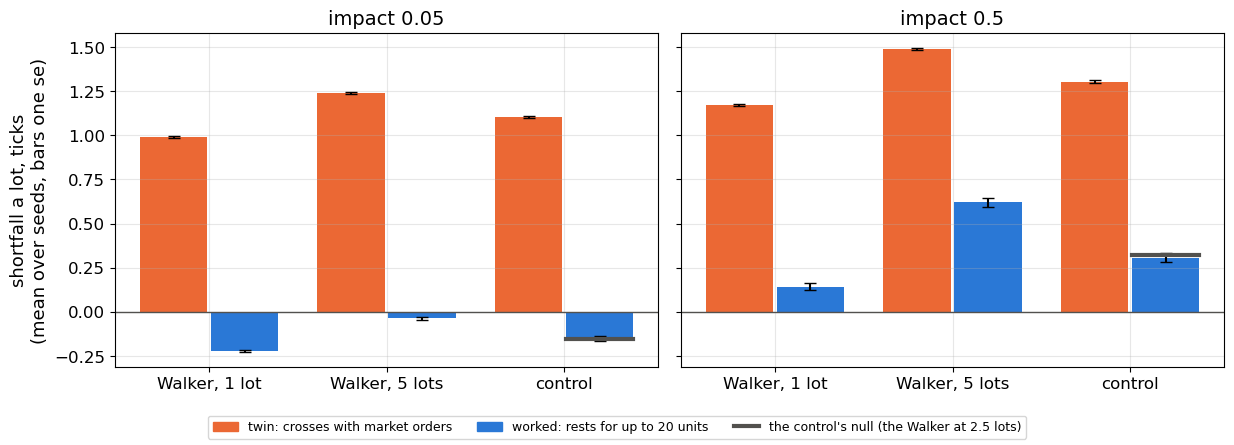

In [6]:
# The cost of a lot, crossing and resting, for the three probes at each impact: the figure of touch_table and
# control_table (it adds nothing to the printed lines). One y-axis a panel, the two panels on the same scale; each bar
# is a mean over the seeds with a bar of one standard error. The gray mark on the control's worked bar is the
# control's null.
lot_groups = [  # (label, the row of touch_table or control_table for the twin and for the worked row, and which table)
    ('Walker, 1 lot', 'twin', 'worked', touch_table),
    ('Walker, 5 lots', 'twin, 5 lots', 'worked, 5 lots', touch_table),
    ('control', 'twin', 'worked', control_table),
]
fig, axes = plt.subplots(1, len(IMPACTS), figsize=FIGSIZE_WIDE, sharey=True)
for ax, impact in zip(axes, IMPACTS, strict=True):
    for i, (_, twin_row, worked_row, source) in enumerate(lot_groups):
        for shift, row, color in [(-0.2, twin_row, ORANGE), (0.2, worked_row, BLUE)]:
            line = source.loc[named(row, impact)]
            ax.bar(
                i + shift,
                line.shortfall_a_lot,
                width=0.38,
                color=color,
                yerr=line.shortfall_a_lot_se,
                capsize=4,
            )
        if source is control_table:
            null = control_null['worked', impact][0]
            ax.plot([i + 0.01, i + 0.39], [null.mean()] * 2, color=GRAY, lw=3)
    ax.axhline(0, color=GRAY, lw=1)
    ax.set_xticks(range(len(lot_groups)), [label for label, *_ in lot_groups])
    ax.set_title(f'impact {impact:g}')
axes[0].set_ylabel('shortfall a lot, ticks\n(mean over seeds, bars one se)')
fig.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=ORANGE, label='twin: crosses with market orders'),
        plt.Rectangle((0, 0), 1, 1, color=BLUE, label='worked: rests for up to 20 units'),
        plt.Line2D([], [], color=GRAY, lw=3, label=f"the control's null (the Walker at {control_need:g} lots)"),
    ],
    loc='lower center',
    ncol=3,
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

**What the picture shows.** At the library's impact the worked bar of each probe is below its twin's and below 0: the gap between each pair of bars is the saving of the tables above, +1.210 (standard error 0.007, 12 of 12 seeds positive) for the one-lot Walker, +1.277 (se 0.009, 12 of 12) for the five-lot Walker, and 1.256 (se 0.015) for the control, whose worked less twin is -1.256 (0 of 12 seeds above 0). At 0.5 every worked bar is above 0, and every gap is smaller and still above 0: +1.027 (se 0.019, 12 of 12) for one lot, +0.870 (se 0.028, 12 of 12) for five lots, and 0.998 (se 0.030) for the control, whose worked less twin is -0.998 (0 of 12 seeds above 0). The gap falls most for the five-lot Walker. The bars that have moved most from 0.05 to 0.5 are the worked ones: the five-lot Walker's worked bar by +0.656 (se 0.028), the control's worked bar from -0.152 to +0.307 (a plain difference of two printed means, 0.459), and the one-lot Walker's by +0.364 (se 0.018). The twin bars moved less, by +0.250 (se 0.007) for five lots, +0.181 (se 0.006) for one lot, and, for the control, from +1.104 to +1.304 (0.200, a plain difference). Each worked bar rose by about twice what the twin bar beside it did, or more, which is why the gaps close: the worked order's cost rises more than the twin's with the takers' information.

The gray mark on the control's worked bar is the Walker's cost at 2.5 lots, the null. At 0.05 the bar sits on its mark, -0.152 against -0.152 (control less null -0.000, se 0.014). At 0.5 the bar, +0.307, sits just under its mark, +0.322 (control less null -0.015, se 0.031). Both differences are within one standard error of 0, and neither says the line is exact. The mark is drawn on the worked bar only, so the picture does not show the twin's miss of the line, +0.020 (se 0.005) at 0.05 and +0.014 (se 0.010) at 0.5, which 1c prints. The bars' error bars are of one standard error, thin throughout, at their widest 0.026 on the five-lot worked bar at 0.5. The figure is the printed lines side by side, and it gives no figure that the tables above did not. Like them, it is a figure of this market, and the bracket moves the takers' information only.

### In a Backtest's Terms

**No scorecard or signal chart is drawn in this section.** The Walker, the control and the followers of section 2 are not backtests of a strategy: they have no signal, their paper is luck, and the question the section asks of them is what an order costs, which a scorecard of their P&L would not show. A scorecard of a probe's record would also mislead, because a worked trader's record holds what it held at each decision and not the fills between, so it is not what the trader made. The four traders of 1a are backtests of a strategy, and the scorecards and signal charts of the global rule are drawn where they are worked, at the end of section 3: the worked reversal trader and the worked pairs trader, each a recorded run on `CARD_SEED`, with the fills' P&L beside the record's.

In [7]:
# What the conclusions read from section 1: its figures under the keys of the predictions (PREDICTIONS, key_of), as
# (the run's figure, its standard error over the seeds), and the control's paper against the twin with no impact of
# its own at the bracket's impact in standard errors (the first sentence of the predictions). No verdict is made
# here: the conclusions print each beside the prediction, and judge decides.
LOT_ROWS = {
    WALKER_1,
    WALKER_5,
    WALKER_P5,
    WALKER_NONE,
    CONTROL,
}  # the rows of the predictions that this section answers


def lot_collect():
    # The section's figures under the keys of the predictions (a function, so that its loop variables are not left
    # behind): the shortfall a lot of the Walker's rows and the control's, worked and as a twin, at each impact where
    # the predictions have one; the P&L of worked less twin for the Walker and the control; the control's paper
    # against each twin.
    figures = {}
    for row, twin, worked in ((WALKER_1, 'twin', 'worked'), (WALKER_5, 'twin, 5 lots', 'worked, 5 lots')):
        for impact in IMPACTS:
            high = HIGH if impact == IMPACT_HIGH else ''
            for quantity, name in ((WORKED_A_LOT, worked), (TWIN_A_LOT, twin)):
                if key_of(row, high + quantity) in PREDICTIONS:
                    line = touch_table.loc[named(name, impact)]
                    figures[key_of(row, high + quantity)] = (
                        float(line.shortfall_a_lot),
                        float(line.shortfall_a_lot_se),
                    )
    for row, name in ((WALKER_P5, 'worked, patience 5'), (WALKER_NONE, 'worked, no repricing')):
        line = touch_table.loc[name]
        figures[key_of(row, WORKED_A_LOT)] = (float(line.shortfall_a_lot), float(line.shortfall_a_lot_se))
    figures[key_of(WALKER_1, PROBE_PNL)] = (float(touch_gains.pnl['one lot']), float(touch_gains.se['one lot']))
    for impact in IMPACTS:
        high = HIGH if impact == IMPACT_HIGH else ''
        for quantity, name in ((WORKED_A_LOT, 'worked'), (TWIN_A_LOT, 'twin')):
            line = control_table.loc[named(name, impact)]
            figures[key_of(CONTROL, high + quantity)] = (float(line.shortfall_a_lot), float(line.shortfall_a_lot_se))
    low = control_gaps.loc[f'worked less twin, impact {IMPACT:g}']
    figures[key_of(CONTROL, PROBE_PNL)] = (float(low.pnl), float(low.se))
    figures[key_of(CONTROL, PAPER_VS_TWIN)] = (float(low.paper), float(low.paper_se))
    high = control_gaps.loc[f'worked less twin, impact {IMPACT_HIGH:g}']
    figures[key_of(CONTROL, HIGH + PAPER_VS_TWIN)] = (float(high.paper), float(high.paper_se))
    fair = control_gaps.loc[f'worked less twin with no own impact, impact {IMPACT_HIGH:g}']
    figures[key_of(CONTROL, HIGH + PAPER_VS_NO_OWN)] = (float(fair.paper), float(fair.paper_se))
    return figures


lot_figures = lot_collect()
lot_missing = [key for key in PREDICTIONS if key.split(' | ')[0] in LOT_ROWS and key not in lot_figures]
assert not lot_missing, f'no figure for the predictions {lot_missing}'
assert all(key in PREDICTIONS for key in lot_figures), 'a figure of section 1 has no prediction'
lot_verdicts = {key: judge(key, *figure) for key, figure in lot_figures.items()}  # judge runs on each
lot_paper_z = float(control_gaps.paper[f'worked less twin with no own impact, impact {IMPACT_HIGH:g}']) / float(
    control_gaps.paper_se[f'worked less twin with no own impact, impact {IMPACT_HIGH:g}']
)
print(
    f'{len(lot_figures)} figures of section 1 are kept for the conclusions under the keys of the predictions '
    f'(`lot_figures`), with the control\'s paper less the twin with no impact of its own at {IMPACT_HIGH:g} in '
    f'standard errors (`lot_paper_z`): {lot_paper_z:+.2f}.'
)

17 figures of section 1 are kept for the conclusions under the keys of the predictions (`lot_figures`), with the control's paper less the twin with no impact of its own at 0.5 in standard errors (`lot_paper_z`): +0.24.


### What This Section Cannot Show

- **What resting orders would save in a real market.** The order flow here never reacts to a resting order, nobody steps in front of it, cancel and replace are free and instant, an order alone at the best price steps back for nothing, a jump is always seen in time, there are no fees or rebates, and the takers carry 0.05 a lot of information. Every saving of 1b and 1c is a figure of a market built so, and it is an upper bound on each of the items of that list that favors the resting order. A saving here is not a prediction of one anywhere else.
- **That the bracket tests those items.** The market at 0.5 moves one thing, the takers' information (and with it how far a crossing trader's own orders push the fair values it is marked at). If a saving survives it, that is not shown to survive any item of the list above, none of which the bracket touches, and what it says is how a resting order and its twin each respond to better informed takers.
- **That a P&L or paper difference against the twin is the execution's, at 0.5 or in paper at any impact.** The twin's own market orders push the fair values that its paper is marked at and that its signal reads. The control's twin with no impact of its own is run to show it, and every figure of the bracket is read on the shortfall a lot, which sets each trader against its own decision mids. 1b has no twin without its own impact, so its P&L and paper differences at 0.5 are not like for like, and the text says so.
- **The free step back.** A lot that rests alone at the best price is put back one price at the next look for nothing, and every saving here has it in it. This notebook has no run that switches it off, so it cannot say how much of any saving is that.
- **What a multi-lot, rate or signal trader pays.** The Walker's one lot and five lots and the control's needs are sizes of orders with no signal and no rate. A trader with a rate or a band has needs that creep or vanish before a resting order fills, and a signal's needs are not random. Section 2 prices the signal's own part, and section 3 the four traders; no figure here is carried to them.
- **That the control's null is exact.** It is a straight line between two Walker sizes, taken at 2.5 lots, and the line is an assumption. The control's needs also live 50 units and the Walker's 25, and the control's targets change several books of the twelve at a decision. The twin's row, where the answer is the book's depth, is the only check the section has of the line, and a check of a line for the twin does not check it for a resting order.
- **That a setting other than the notebook's costs what the rows here cost.** Two variants are run, once, on the one-lot Walker: a patience of 5 and no repricing. Patience between 10 and 20, a reprice faster than every unit, and where an order rests (at the best price here, never inside the spread or behind it) were not explored. The setting is the cheap end of what was measured.
- **That the figures are the review's prototype's.** The prototype moved its orders only at the trader's decisions, which is the no-repricing row, and no other figure of the section is compared with it.
- **That a probe's cost is a strategy's result.** No scorecard is drawn for a probe, which has no signal, and a saving of a probe's cost is not a P&L of any trader of section 3.
- **That twelve seeds say more than twelve seeds of one simulated market do.** Twelve books in three sectors, 5,000 units a probe. Seeds 1 to 8, where the setting, the rows and the predictions were chosen, are in no table. No test is made in this section, and a figure is a mean over the seeds with its standard error.
- **That a band, a deal or the index book would behave alike.** The band rows are not run (the exploration found their paper was not their twin's and that patience never binds), and no market of this notebook has deals or an index book: the library does not measure what a jump does to a resting order there.

## 2. The Cost by Signal

**How much of what a resting order costs is the signal's own?** Section 1 priced a lot that has no reason to be on either side of the market. A trader's orders do: they go the way its signal says the price will go. An order that rests at the best price is filled when the price comes to it and left behind when the price goes away from it, so if a signal knows where the price goes next, an order in its direction should pay more than one against it. How much more is what a resting order gives back of the signal's edge. This section measures it for five signals, with the one design that separates it from the cost any resting order has.

**The follower.** `Follower(inner)` sends one-lot orders, at the first decision 25 units of time or more after its last launch, in each book where a real trader's target is not 0: in the direction of that target (*with* the signal) or the other way (*against* it). The real trader is the follower's *inner trader*. The follower calls the inner trader's `observe` and `decide` at every decision, and decides when the inner trader would, at its interval, so the target it reads is the signal's, in lots, in each book, at that moment. The inner trader is never added to the market and never trades: its position stays 0, so what it holds is its target and not what it did with the last one. A cell asserts that every inner trader held no lot at the end of every run. A follower's order is worked as every worked row of this notebook is: at the best price, moved every unit, crossed after 20 units (`WORKED`). With launches 25 units or more apart and a patience of 20, each need is done, filled or crossed, before the next launch, which a cell asserts. A follower launches nothing in the last 25 units of its span, so that its last launch is done before the run ends as well. So a need's cost is the cost of its lot against the mid at the decision that launched it, and a follower's shortfall a lot is the mean cost of its needs.

**The first run of this notebook stopped here, and the launch schedule was corrected.** It stopped in this section, at an assertion of the setup's own that every need is done in its window. The follower's launches were then on a grid of 25 units fixed in advance, and where a launch came just after a grid time the next came only 20 units later, before a lot that had run out its patience of 20 had been crossed, so that lot fell in the next launch's window. One launch of one run raised the assertion, and nothing of this section had been printed. The follower now launches at the first decision 25 units or more after its last launch, a change of one line in the follower probe, and every figure below is from a run with that schedule.

**Five inner traders**, each a trader of notebook 12 or 13 in the sectors market (the cross-sectional traders and the residuals are neutral to three factors, the number the sectors market has):

- *queues*: the flow of queues, hold 1, every 1 unit (the target is made afresh at every decision);
- *reversal*: look back 50, hold 1, every 5 (afresh at every decision too; section 3's reversal row has a rate where this has a hold of 1);
- *pairs*: eight pairs by distance, entry 1.25, every 5. **The follower's unit is a lot in each book where the pairs trader's target is not 0, and not a lot of a pair**: a pair has two legs, and each leg that has a target is a need;
- *residuals*: stat-arb on PCA residuals with three factors, entering beyond 1.25;
- *momentum*: look back 100, hold 100, every 5 (notebook 13's, holding its target for 100 decisions).

Each follower runs for 5,000 units after a burn of its inner trader's warm-up and 400 more, on `SEEDS`, at an impact of 0.05 and of 0.5: five signals, with and against, two impacts, twelve seeds: 240 runs, in the frame `signal_frame`. The bracket is read on the shortfall a lot, as everywhere in this notebook.

**Two parts.** Write the cost of the order with the signal as c + s and the cost of the one against it as c - s. Then c, the *common part*, is the mean of the two, and s, *the signal's own part*, is half their difference, with the sign that makes it positive where the order in the signal's direction pays more. This assumes that the signal's effect is equal and opposite for the two orders, which the design cannot test. The common part is what resting costs whatever the order's direction, so it should be the one-lot Walker's, worked, at the same impact: that is section 1b's `worked` row at each impact (the same trader, execution, seeds, burn and span), which this section reads from 1b's frame and does not run again. A follower is compared with the Walker seed by seed, which is the same market seed but not the same stretch of it, because their burns differ.

**With and against share the inner trader's targets only approximately.** Their two markets part as soon as orders rest, since an order that fills changes what the book holds and the later draws of the model's order flow; so the same inner trader sees a slightly different market in the two runs. Their difference is therefore taken over seeds and never order by order, and the table says how many seeds it was positive on. How far apart the two followers' needs are is measured too: the cell that runs the followers prints, after its table of lots asked, the lots a seed that the with follower asked less the against follower's, for each signal (added after the second run, on a review of it; a description, and nothing was chosen from it).

**The strength of a need** is the size of the inner trader's target in that book, in lots, at the launch. It is the only measure of how strong a signal is that a follower keeps, and the one the signal acts on: for a cross-sectional trader the raw score (`CrossSectionTrader._scores`) is before the factors are neutralized and has the opposite sign, so a table cut on it would be cut on something the trader never trades. On seeds 1 to 8, in the exploration, the strongest fifth of the queue follower's needs with the signal, at an impact of 0.05, cost +0.21 a lot cut by target size and -0.09 cut by the raw score; that is why strength is the target size in lots. The tables cut a run's needs into thirds by strength, with equal sizes split over the thirds they span in proportion, so each third holds a third of the needs; almost all of the pairs trader's targets have one of two sizes, so its thirds are mostly ties, and the cell prints how strong the targets are.

**Where a need ends.** A one-lot need ends in one of three ways: its order is filled where it was first placed, it is filled after the market moved it, or it is crossed when its patience runs out. The library counts the orders a trader placed and does not say which need each belonged to, so the cell below wraps the market's own placement for the one follower in each market and writes down the book and time of every order placed (`SignalFollower`). The wrapper records what it is told and calls the library's method as it is, nothing in the library changes, and a check in every run asserts that the log holds as many placements as the account counted and that every placement belongs to a need. A need that is filled at its first placement is one with exactly one placement from its launch to its fill. That is derived from the log, and the section says so wherever it uses it. The wrapper also writes down, at each launch, the lots at the best price on the side of the book the order rests on and on the other side, as the follower's own view of the market tells them (its own working orders left out); these are read from the books and written to nothing, and 2a prints them (added after the second run, on a review of it).

**What was explored beforehand, on seeds 1 to 8.** The followers and the thirds were designed there, and the figures of the predictions cell above are that exploration's. The midpoint of the with and against followers was within 0.03 a lot of the Walker's at every signal at an impact of 0.05, which is why the common part is set beside the Walker's. Nothing in this section was chosen on `SEEDS`.

**What is not here.** The followers are not strategies: they have no P&L worth reading, and the rule that every backtest gets a scorecard is for backtests, so there is none here, as in section 1. The follower's crossing twin is not run: its cost, the figure a resting order is set against, is section 1b's. The figure of the section, at the end, shows with and against at both impacts.

In [8]:
# 2. The follower of a signal, and what a run of it leaves to read. The setup's Follower is the follower; what is new
# here is a log of where each of its working orders is placed, which `needs` has no source for: the library counts the
# orders a trader placed (orders_placed) and not which need each belonged to. And, added after the second run on a
# review of it, the depth at the best price at each launch (see SignalFollower).
from lob.order import Side

SIGNAL_DIRECTIONS = ('with', 'against')


class SignalFollower(Follower):
    # The setup's Follower with a log of its placements: (time, book) for each working order the market places for it.
    # It is made when the market adds it (`check` is called then, with the market): the market's own `_place` is wrapped
    # on that one instance of the market, so no other trader's market and no other section's runs are touched. The
    # wrapper writes down what it is told and calls the library's `_place` as it is, so a run of this follower is a run
    # of the setup's Follower to the digit (both were compared with the exploration's saved runs on seeds 1 to 8
    # before this notebook was run, and agreed). The run's own check is that the log has as many placements as the
    # account counted (signal_extra).
    #
    # Added after the second run, on a review of it: each launch also records `own_depth` and `other_depth`, the lots at
    # the best price on the side of the book the order rests on (the bid for a buy, the ask for a sell) and on the other
    # side, as the follower's view of the market tells them, which leaves its own working orders out. The market gives
    # `observe` that view just before `decide`, and nothing moves between the two, so a launch reads what the follower
    # decided on. Both are read from the books and nothing is written to them: a run is the run it was to the digit,
    # and `needs` carries the two columns into the needs of a run, which is where the cells read them.
    def check(self, market):
        super().check(market)
        assert isinstance(market, PassiveBookMarket), 'placements are logged in a PassiveBookMarket'
        self.placements = []
        place = market._place

        def logged(work, book, side, lots, price):
            if work.trader is self:
                self.placements.append((market.time, int(book)))
            return place(work, book, side, lots, price)

        market._place = logged

    def observe(self, market):
        self._seen = market  # the follower's view of the market: its books are the books without its own orders
        super().observe(market)

    def decide(self, mids):
        known = len(self.launches)
        moves = super().decide(mids)
        for launch in self.launches[known:]:
            book = self._seen.books[launch['book']]
            bid_lots = book.depth_at_price(book.best_bid, Side.BID)
            ask_lots = book.depth_at_price(book.best_ask, Side.ASK)
            buying = launch['side'] > 0
            launch['own_depth'] = bid_lots if buying else ask_lots
            launch['other_depth'] = ask_lots if buying else bid_lots
        return moves


def make_signal_follower(inner, every, against, seed, burn):
    return SignalFollower(
        inner=CATALOG[inner](),
        every=every,
        against=against,
        start=burn + PROBE_START,
        stop=burn + PROBE_SPAN - FOLLOWER_QUIET,
    )


def signal_extra(market, follower):
    # What a run of a SignalFollower leaves to read, called in the worker after the run: follower_extra's (the needs as
    # a frame, how many, how many are open), a column `placed` on the needs (the placements in that book from the
    # launch to the next launch time, the first being the order's first placement), the placements, and the lots the
    # inner trader holds. Three checks that the run is what the table says it is: the inner trader traded nothing, the
    # log holds the placements the account counted, and every placement belongs to a need. The needs also carry the
    # depth at each launch (own_depth and other_depth, from SignalFollower), which cannot be negative.
    got = follower_extra(market, follower)
    frame = got['needs']
    assert len(frame), 'a follower launched nothing'
    assert (frame[['own_depth', 'other_depth']] >= 0).all().all(), 'a depth at a launch is negative'
    inner, account = follower.inner, market.account(follower)
    held = int(np.abs(inner.position).sum()) + inner.lots
    assert held == 0 and inner.cash == 0.0, f'the inner trader traded: it holds {held} lots'
    seen = len(follower.placements)
    assert seen == account.orders_placed, (
        f'the log has {seen} placements and the account counted {account.orders_placed}'
    )
    times = np.array([t for t, _ in follower.placements], dtype=float)
    books = np.array([b for _, b in follower.placements], dtype=int)
    ends = np.array(
        [follower.launch_times[e + 1] if e + 1 < len(follower.launch_times) else np.inf for e in frame.event]
    )
    placed = np.zeros(len(frame), dtype=int)
    for book in range(len(follower.goal)):
        at = times[books == book]
        pick = (frame.book == book).to_numpy()
        placed[pick] = np.searchsorted(at, ends[pick], side='left') - np.searchsorted(
            at, frame.time[pick].to_numpy(), side='left'
        )
    assert placed.sum() == seen, f'{seen - placed.sum()} placements belong to no need'
    resting = (frame.how == 'resting').to_numpy()
    assert (placed[resting] >= 1).all(), 'a need was filled by a resting order that was never placed'
    frame['placed'] = placed
    return {**got, 'needs': frame, 'placements': seen, 'inner_lots': held}


def signal_row(signal, against):
    # A follower of one of SIGNALS, with the signal or against it: one-lot orders every 25 units, its burn the inner
    # trader's warm-up and 400 more, its span the probes'; its needs and their placements are left to read.
    inner = SIGNALS[signal]
    return Row(
        partial(make_signal_follower, inner, WALK_EVERY, against),
        FOLLOWER_BURN[inner],
        PROBE_SPAN,
        signal_extra,
    )


def signal_name(signal, direction, impact):
    # The name of a follower's row: 'queues, with' at the library's impact, 'queues, with, 0.5' at the bracket's.
    return named(f'{signal}, {direction}', impact)


SIGNAL_KEYS = {  # a case's name -> (signal, direction, impact)
    signal_name(signal, direction, impact): (signal, direction, impact)
    for impact in IMPACTS
    for signal in SIGNALS
    for direction in SIGNAL_DIRECTIONS
}


def signal_cases_of(impacts):
    # Every follower, with and against, worked, at each impact: the same execution in every row, which is the
    # notebook's. The one-lot Walker, worked, that the common part is set beside is section 1b's row of that name,
    # read from its frame and not run again.
    cases = {}
    for impact in impacts:
        for signal in SIGNALS:
            for direction in SIGNAL_DIRECTIONS:
                row = signal_row(signal, direction == 'against')
                cases[signal_name(signal, direction, impact)] = Case(row, WORKED, impact=impact)
    return cases

In [9]:
# 2. The runs. A follower of each of the five signals, with it and against it, worked, at an impact of 0.05 and of 0.5:
# 20 rows on SEEDS in one frame, signal_frame, which the cells below and the conclusions read; signal_needs has a line a
# launch of every follower run. The one-lot Walker, worked, that the common part is set beside is not run here: it is
# section 1b's `worked` row at each impact (the same trader, execution, seeds, burn and span), read from touch_frame.
signal_cases = signal_cases_of(IMPACTS)
signal_frame = run_rows(signal_cases, SEEDS)
signal_needs = needs_of(signal_frame).assign(
    signal=lambda d: d.row.map(lambda r: SIGNAL_KEYS[r][0]),
    direction=lambda d: d.row.map(lambda r: SIGNAL_KEYS[r][1]),
    impact=lambda d: d.row.map(lambda r: SIGNAL_KEYS[r][2]),
)


def check_signal_runs(frame, needs_frame):
    # check_frame (the setup's: the same seeds in every row, lots passive plus crossed, P&L paper less shortfall, no
    # before costs for a worked trader) and what is this section's own: one execution, and every row worked; each
    # follower's lots are the needs it launched, one lot each, every need done before the next launch, the inner trader
    # holding nothing; the placements of its log are the account's; and the needs' costs are the run's shortfall. And
    # the Walker's rows of 1b, which the common part is set beside, are the runs this section would have made.
    assert set(frame.row) == set(signal_cases), 'a row of the frame is not a row of the cases'
    check_frame(frame, 'the followers')
    assert all(case.execution == WORKED for case in signal_cases.values()), 'a row has another execution'
    for impact in IMPACTS:
        walker = touch_frame[touch_frame.row == named('worked', impact)]
        assert sorted(walker.seed) == sorted(SEEDS) and walker.worked.all(), "1b's Walker rows are not on every seed"
        assert (walker.impact == impact).all(), "1b's Walker row is at another impact"
        assert (walker.burn == PROBE_BURN).all() and (walker.span == PROBE_SPAN).all(), "1b's Walker has other lengths"
    follows = frame
    assert len(follows) == len(SIGNAL_KEYS) * len(SEEDS), 'the frame does not hold every row on every seed once'
    assert (follows.inner_lots == 0).all(), 'an inner trader held a lot'
    assert (follows.needs_open == 0).all(), 'a need is still open at the end of a run'
    assert (follows.asked_lots == follows.needs_n).all(), 'the paper asked for lots that are not launches'
    assert (follows.lots == follows.asked_lots).all(), 'lots traded are not the lots asked'
    assert (follows.placements == follows.orders_placed).all(), 'the log and the span disagree on the placements'
    assert (needs_frame.lots == 1.0).all() and needs_frame.done.all(), 'a need is not one lot, done'
    assert (needs_frame.wait < WALK_EVERY).all(), 'a need was done after the next launch'
    moves = np.where(needs_frame.how == 'resting', needs_frame.placed - 1, needs_frame.placed)
    withdrawn = needs_frame.assign(moves=moves).groupby(['row', 'seed']).moves.sum()
    counted = follows.set_index(['row', 'seed']).orders_withdrawn.loc[withdrawn.index]
    assert (withdrawn == counted).all(), 'the placements of the needs are not the withdrawals the account counted'
    costs = needs_frame.groupby(['row', 'seed']).cost.sum()
    shortfalls = follows.set_index(['row', 'seed']).shortfall.loc[costs.index]
    assert np.allclose(costs, shortfalls, rtol=0, atol=1e-6), 'the needs cost is not the shortfall'
    return len(follows), len(needs_frame)


signal_runs, signal_launches = check_signal_runs(signal_frame, signal_needs)
print(
    f'Checked: {signal_runs} follower runs and {signal_launches:,} launches. Every row is on each of the {len(SEEDS)} '
    f"seeds once and has the one execution; the one-lot Walker that the common part is set beside is 1b's `worked` row "
    f'at each impact (burn {PROBE_BURN:,.0f}, span {PROBE_SPAN:,.0f}), read and not run again. In every run the inner '
    f'trader holds no lot at the end; every launch is one lot, done before the next launch (the longest wait is '
    f'{signal_needs.wait.max():.1f} units against {WALK_EVERY:g} between launches); the lots the paper asked are the '
    f'launches and the lots got; the needs add up to the shortfall; P&L is paper less shortfall; lots are passive '
    f'plus crossed; the placements the log holds are the ones the account counted, and so are the withdrawals they '
    f'imply.'
)
print(
    f'\nWhat the {len(SEEDS)} seeds of each row asked, a seed, and what crossed. A follower asks for one lot in each '
    f'book where its inner trader has a target, every {WALK_EVERY:g} units; the with and against rows have about the '
    f'same lots to ask (their markets part once orders rest, so not exactly).\n'
)
print(
    shown(
        table_of(signal_frame),
        keep=['asked_lots', 'crossed_share', 'wait', 'orders_placed'],
        crossed_share='.4f',
        wait='.2f',
    )
)
print()
ran(signal_frame, label='Section 2: ')


# Added after the second run, on a review of it (a description, and nothing was chosen from it): how far apart a with
# and an against follower's needs are. A follower asks for one lot for each launch, so the lots a row asked a seed are
# its needs; the two followers of a signal share the inner trader's targets only approximately, and this is how
# approximately. Each is one number a seed: the with row's lots asked less the against row's.
signal_asked = {
    (impact, signal): pd.DataFrame(
        {
            direction: series_of(signal_frame, signal_name(signal, direction, impact), 'asked_lots')
            for direction in SIGNAL_DIRECTIONS
        }
    )
    for impact in IMPACTS
    for signal in SIGNALS
}


def print_signal_asked(impact):
    lines = {}
    for signal in SIGNALS:
        asked = signal_asked[(impact, signal)]
        gap = asked['with'] - asked['against']
        lines[signal] = {
            'with less against': f'{gap.mean():+.1f}',
            'sd over seeds': f'{gap.std():.1f}',
            'largest gap': f'{gap.abs().max():.0f}',
            'largest share of with row': f'{(gap.abs() / asked["with"]).max():.1%}',
            'with row asked more': f'{int((gap > 0).sum())} of {len(gap)}',
        }
    print(f'Impact {impact:g}.')
    print(pd.DataFrame(lines).T.to_string())


print(
    "\nAdded after the second run, on a review of it: how far apart a with and an against follower's needs are. The "
    "lots asked a seed by the with follower less the against follower's, by signal: the mean over the "
    f'{len(SEEDS)} seeds, the standard deviation over the seeds, the largest gap on a seed in lots, the largest of the '
    "seeds' gaps as a share of the seed's with row, and the seeds on which the with row asked more. A description: "
    'nothing was chosen from it.\n'
)
print_signal_asked(IMPACT)
print()
print_signal_asked(IMPACT_HIGH)

Checked: 240 follower runs and 427,098 launches. Every row is on each of the 12 seeds once and has the one execution; the one-lot Walker that the common part is set beside is 1b's `worked` row at each impact (burn 500, span 5,000), read and not run again. In every run the inner trader holds no lot at the end; every launch is one lot, done before the next launch (the longest wait is 20.2 units against 25 between launches); the lots the paper asked are the launches and the lots got; the needs add up to the shortfall; P&L is paper less shortfall; lots are passive plus crossed; the placements the log holds are the ones the account counted, and so are the withdrawals they imply.

What the 12 seeds of each row asked, a seed, and what crossed. A follower asks for one lot in each book where its inner trader has a target, every 25 units; the with and against rows have about the same lots to ask (their markets part once orders rest, so not exactly).

                        asked_lots crossed_sh

**The checks held in every run.** The cell ran 240 follower runs and 427,098 launches (its `Checked:` line). It asserts that in every run the inner trader held no lot at the end, that every launch was one lot done before the next launch (the longest wait printed is 20.2 units against the 25 units between launches), that the needs' costs add up to the run's shortfall, and that the placements in the log are the ones the account counted, and so are the withdrawals they imply. That licenses two readings: a follower's shortfall a lot is the mean cost of its needs, and the shares of 2b come from a log that agrees with the library's own count of placements. It does not license more than that, because the check guards the total of the placements and not the assignment of each to a need (the last cell of the section says so).

**What was asked.** The lots a seed that a with and an against follower of one signal asked are about the same and not equal (the `asked_lots` column). At 0.05 they are 2,075 and 2,073 for the queues, 2,042 and 2,040 for reversal, 1,195 and 1,191 for pairs, 1,444 and 1,458 for residuals, and 2,069 and 2,023 for momentum; at 0.5 they are 2,073 and 2,081, 2,034 and 2,037, 1,214 and 1,223, 1,600 and 1,613, and 2,074 and 2,030. The share of lots crossed (`crossed_share`) is at most 0.0016 in all twenty rows. Its largest value is printed three times: for the queues with the signal at 0.05, and for the queues and the residuals with the signal at 0.5. Its smallest is 0.0004, for pairs against the signal at 0.05. The mean wait (`wait`, the units a need waited before it ended) is longer with the signal than against it for the queues, 3.83 against 2.63 at 0.05 and 3.33 against 2.68 at 0.5 (gaps of 1.20 and 0.65 units, plain differences). For reversal, pairs and residuals it is longer with the signal by 0.10 to 0.24 units at both impacts (plain differences of the printed figures), and for momentum it is the against follower that waits longer, by 0.03 units at 0.05 (3.24 with, 3.27 against) and 0.04 at 0.5 (2.99 and 3.03). The table prints no standard error for the wait, so these small gaps are described and not read.

**How far apart the two followers' needs are.** This table was added after the second run, on a review of it: a description and not a test, and nothing was chosen from it. For each signal it prints the lots asked a seed by the with follower less the against follower's. At 0.05 the largest of the seeds' gaps, as a share of that seed's with row, is 1.9% for the queues (39 lots) and 1.9% for reversal (38 lots), 8.4% for pairs (98 lots), 9.2% for residuals (120 lots) and 9.3% for momentum (180 lots). The with row asked more on 6 of 12 seeds for the queues, 7 of 12 for reversal, 6 of 12 for pairs, 6 of 12 for residuals and 10 of 12 for momentum, whose mean gap is +46.7 lots with a standard deviation over seeds of 95.4; the mean gaps of the other four are +2.1, +2.2, +3.6 and -14.6 lots. So the statement above, that the two followers share the inner trader's targets only approximately, is now measured. For the queues and for reversal the two followers' needs differ by 1.9% of the with row or less on the worst seed, and for pairs, residuals and momentum by 8.4% to 9.3%: these three do not ask for the same needs, and their difference is read over seeds, as the section says and never order by order. At 0.5 the largest shares are 3.3% (queues), 1.9% (reversal), 8.5% (pairs), 19.7% (residuals, a gap of 280 lots on one seed, with a standard deviation over seeds of 138.2) and 4.3% (momentum). The residuals' is the largest of the ten, and the with row of momentum asked more on 10 of 12 seeds again.

### 2a. The Common Part and the Signal's Own Part

**How much more does a one-lot order in the signal's direction pay than one against it, and is what resting costs, whatever the direction of the order, what it cost with no signal?** The cell below prints, for each signal and at each impact, the shortfall a lot with the signal and against it, their mean (the common part) and half their difference (the signal's own part), and the one-lot Walker, worked, at the same impact: section 1b's own row, read from its frame and not run again. A figure is the mean over `SEEDS` of the shortfall a lot against the decision mid (a positive figure is a cost), with its standard error over seeds and the seeds above 0. The signal's own part and the common part less the Walker's are differences, and they are printed as the notebook prints every difference: paired by seed, with the mean, its standard error over the seeds, t and the seeds above 0. A follower and the Walker share the market seed and not the same stretch of it, because their burns differ, which widens the standard error of the difference between them. After those tables the cell prints two things added after the second run, on a review of it, each a description from which nothing was chosen. First, the common part less the Walker's for the five signals together, one number a seed: the five common parts are set beside the same Walker's row, so five lines above it are one finding and not five. Second, the depth the order joined: the lots at the best price on the side of the book the order rests on (its own side) and on the other side, at the launches of each follower, as the mean over seeds of each run's mean over its launches, and the own side less the other side with the signal less against it, paired by seed. It says what each order met at the touch, which the own part is set beside.

In [10]:
# 2a. The cost by signal. For each signal the shortfall a lot of the one-lot order with the signal and against it, the
# common part (their mean: what resting costs whatever the order's direction, which should be the Walker's) and the
# signal's own part (half of with less against: what a resting order in the signal's direction pays more than one the
# other way). Every figure is one number a seed; a table prints its mean over the seeds, its standard error over their
# root (sd with ddof 1) and the seeds above 0. A signal is compared with the Walker seed by seed, on the same market
# seed but not the same stretch of it: the Walker's burn is 500 and a follower's its inner trader's warm-up and 400
# more.
def signal_text(x, digits=3, positive=False, sign=True):
    # '+0.183 (0.009)' for a Series with one number a seed: its mean and its standard error over the seeds (the sign
    # shown unless `sign` is False); with `positive`, also the seeds above 0 ('12 of 12'). A level is printed so; a
    # paired difference is printed by `said`, as everywhere in the notebook.
    text = f'{x.mean():{"+" if sign else ""}.{digits}f} ({se_of(x):.{digits}f})'
    return f'{text} {int((x > 0).sum())} of {len(x)}' if positive else text


def signal_parts_of(frame, impact, signal):
    # The parts of one signal's cost at one impact, each one number a seed: with, against, their mean (the common part),
    # the common part less the Walker's, and half of with less against (the signal's own part). The Walker is 1b's
    # one-lot row, worked, at the same impact (touch_frame): the same market seed, not the same stretch of it.
    with_ = series_of(frame, signal_name(signal, 'with', impact), 'shortfall_a_lot')
    against = series_of(frame, signal_name(signal, 'against', impact), 'shortfall_a_lot')
    walker = series_of(touch_frame, named('worked', impact), 'shortfall_a_lot')
    common = (with_ + against) / 2
    return {
        'with': with_,
        'against': against,
        'common part': common,
        'Walker': walker,
        'common less Walker': common - walker,
        'own part': (with_ - against) / 2,
    }


signal_parts = {
    (impact, signal): signal_parts_of(signal_frame, impact, signal) for impact in IMPACTS for signal in SIGNALS
}


def signal_figures_of(parts):
    # The figures PREDICTIONS has a key for, as {key: (the run's figure, its standard error over the seeds)}: what the
    # conclusions judge, for this section. Every prediction of a follower must be answered by one.
    figures = {}
    for (impact, signal), part in parts.items():
        high = HIGH if impact == IMPACT_HIGH else ''
        for quantity, name in (
            (WITH_A_LOT, 'with'),
            (AGAINST_A_LOT, 'against'),
            (OWN_PART, 'own part'),
        ):
            key = key_of(follower_of(signal), high + quantity)
            if key in PREDICTIONS:
                figures[key] = (float(part[name].mean()), float(se_of(part[name])))
    missing = [key for key in PREDICTIONS if key.startswith('follower, ') and key not in figures]
    assert not missing, f'no figure for the prediction {missing}'
    return figures


signal_figures = signal_figures_of(signal_parts)


def print_signal_parts(impact):
    walker = signal_parts[(impact, next(iter(SIGNALS)))]['Walker']
    print(
        f'Impact {impact:g}. One-lot orders, worked, shortfall a lot against the decision mid (a positive figure is a '
        f'cost): mean over {len(walker)} seeds, (standard error over seeds) and seeds above 0.'
    )
    print(
        f"The one-lot Walker, worked, the same impact and execution (1b's row): {signal_text(walker, positive=True)} "
        f'a lot.\n'
    )
    labels = {'with': 'with the signal', 'against': 'against it'}
    table = pd.DataFrame(
        {
            labels.get(name, name): {
                signal: signal_text(signal_parts[(impact, signal)][name], positive=True) for signal in SIGNALS
            }
            for name in ('with', 'against', 'common part')
        }
    )
    print(table.to_string())
    print('\nPaired by seed (the mean, its standard error over the seeds, t and the seeds above 0):')
    for signal in SIGNALS:
        part = signal_parts[(impact, signal)]
        print(f"  {signal:<10}own part {said(part['own part'], 3)}")
        print(f"  {'':<10}common part less the Walker's {said(part['common less Walker'], 3)}")


print_signal_parts(IMPACT)
print()
print_signal_parts(IMPACT_HIGH)
print(
    "\nThe signal's own part is half of (with less against): positive where the order in the signal's direction pays "
    'more. The common part is their mean, and its difference from the Walker is taken seed by seed.'
)


# Added after the second run, on a review of it (a description, and nothing was chosen from it). First, the common part
# less the Walker's for the five signals together: the five lines above share the Walker's row, so that "all five above
# it" is one finding and not five. The mean of the five signals' common parts less the Walker's is one number a seed.
signal_group = {
    impact: sum(signal_parts[(impact, signal)]['common less Walker'] for signal in SIGNALS) / len(SIGNALS)
    for impact in IMPACTS
}


def print_signal_group():
    for impact, group in signal_group.items():
        print(f"  impact {impact:g}, the five signals together: common part less the Walker's {said(group, 3)}")


print(
    "\nAdded after the second run, on a review of it: the five signals together. The five common parts are set beside "
    "one Walker's row, so that five positive lines are one finding and not five. The mean of the five signals' common "
    "parts less the Walker's, a number a seed, paired by seed:\n"
)
print_signal_group()


# Second, how deep the best price was that the order joined. At each launch the follower's view of the book tells the
# lots at the best price on the side the order rests on (own side) and on the other side, its own orders left out
# (SignalFollower writes them into the launch, and the needs carry them). A run's figure is the mean over its launches,
# one number a seed; with and against are read seed by seed, as everything here.
def signal_depths_of(needs_frame):
    return needs_frame.groupby(['row', 'seed'])[['own_depth', 'other_depth']].mean()


signal_depths = signal_depths_of(signal_needs)


def print_signal_depths(impact):
    lines, imbalance = {}, {}
    for signal in SIGNALS:
        depth = {
            direction: signal_depths.loc[signal_name(signal, direction, impact)].sort_index()
            for direction in SIGNAL_DIRECTIONS
        }
        assert all(list(depth[d].index) == sorted(SEEDS) for d in SIGNAL_DIRECTIONS), f'{signal}: not on every seed'
        lines[signal] = {
            f'{direction}, {side} side': signal_text(depth[direction][f'{side}_depth'], 2, sign=False)
            for direction in SIGNAL_DIRECTIONS
            for side in ('own', 'other')
        }
        gap = {d: depth[d].own_depth - depth[d].other_depth for d in SIGNAL_DIRECTIONS}
        imbalance[signal] = gap['with'] - gap['against']
    print(f'Impact {impact:g}.')
    print(pd.DataFrame(lines).T.to_string())
    print('\n  Own side less other side, with less against, paired by seed (lots):')
    for signal, difference in imbalance.items():
        print(f'  {signal:<10}{said(difference, 2)}')


print(
    "\nAdded after the second run, on a review of it: the depth the order joined. The lots at the best price on the "
    "side of the book the order rests on (own side: the bid for a buy, the ask for a sell) and on the other side, at "
    f"the launches of each follower, its own orders left out: the mean over the {len(SEEDS)} seeds of each run's mean "
    'over its launches, and (standard error over seeds).\n'
)
print_signal_depths(IMPACT)
print()
print_signal_depths(IMPACT_HIGH)

Impact 0.05. One-lot orders, worked, shortfall a lot against the decision mid (a positive figure is a cost): mean over 12 seeds, (standard error over seeds) and seeds above 0.
The one-lot Walker, worked, the same impact and execution (1b's row): -0.221 (0.006) 0 of 12 a lot.

                  with the signal              against it             common part
queues     -0.031 (0.009) 1 of 12  -0.379 (0.011) 0 of 12  -0.205 (0.006) 0 of 12
reversal   -0.146 (0.012) 0 of 12  -0.274 (0.007) 0 of 12  -0.210 (0.008) 0 of 12
pairs      -0.121 (0.010) 0 of 12  -0.279 (0.013) 0 of 12  -0.200 (0.008) 0 of 12
residuals  -0.146 (0.011) 0 of 12  -0.254 (0.011) 0 of 12  -0.200 (0.009) 0 of 12
momentum   -0.226 (0.008) 0 of 12  -0.190 (0.008) 0 of 12  -0.208 (0.005) 0 of 12

Paired by seed (the mean, its standard error over the seeds, t and the seeds above 0):
  queues    own part +0.174 (se 0.008, t 22.15, 12 of 12 seeds positive)
            common part less the Walker's +0.016 (se 0.010, t 1.63, 8 

**At an impact of 0.05 the order in the signal's direction paid more than the one against it for four of the five signals, and less for momentum.** Every figure is the mean over the 12 seeds of the shortfall a lot against the decision mid (a positive figure is a cost), with its standard error over seeds (se) in parentheses. With the signal and against it, the queues were -0.031 (0.009) and -0.379 (0.011), reversal -0.146 (0.012) and -0.274 (0.007), pairs -0.121 (0.010) and -0.279 (0.013), residuals -0.146 (0.011) and -0.254 (0.011), and momentum -0.226 (0.008) and -0.190 (0.008). All ten means are below 0, a gain against the decision mid in this market, and the queues' with row is above 0 on 1 of 12 seeds and no other row on any. The own part, half the difference and paired by seed, is from the largest to the smallest +0.174 for the queues (se 0.008, t 22.15, 12 of 12 seeds positive), +0.079 for pairs (se 0.008, t 9.68, 12 of 12), +0.064 for reversal (se 0.005, t 13.21, 12 of 12), +0.054 for residuals (se 0.006, t 8.36, 12 of 12) and -0.018 for momentum (se 0.006, t -3.07, 3 of 12 seeds positive). So the own part is above 0 on every seed for the queues, pairs, reversal and residuals, and the order with the signal pays more than the one against it for those four. Momentum breaks it: its order with the signal paid less. The own part is half of a difference under an assumption the design cannot test, and it is read beside the depth the orders met, below.

**The common part is above the Walker's on all ten lines, by 0.011 to 0.021 at 0.05 and by 0.018 to 0.030 at 0.5, and within two standard errors of it on every one.** The common part, the mean of the two rows of a signal, is at 0.05 -0.205 (0.006) for the queues, -0.210 (0.008) for reversal, -0.200 (0.008) for pairs, -0.200 (0.009) for residuals and -0.208 (0.005) for momentum, beside the one-lot Walker's -0.221 (0.006). The common part less the Walker's, paired by seed, is +0.016 (se 0.010, t 1.63, 8 of 12 seeds positive) for the queues, +0.011 (se 0.012, t 0.95, 10 of 12) for reversal, +0.021 (se 0.011, t 1.81, 8 of 12) for pairs, +0.021 (se 0.011, t 1.97, 9 of 12) for residuals and +0.013 (se 0.006, t 1.94, 9 of 12) for momentum. The largest figures are the +0.021 of pairs and of residuals, and the residuals' is the nearest to two standard errors. At 0.5 the common parts are +0.161 (0.013), +0.170 (0.008), +0.162 (0.011), +0.173 (0.016) and +0.173 (0.016), beside the Walker's +0.143 (0.020), and the differences are +0.018 (se 0.026, t 0.70, 6 of 12), +0.027 (se 0.019, t 1.45, 9 of 12), +0.020 (se 0.026, t 0.77, 6 of 12), +0.030 (se 0.026, t 1.13, 7 of 12) and +0.030 (se 0.021, t 1.41, 7 of 12). The largest are the residuals' and momentum's +0.030. So for all five signals, at both impacts, the common part is within two standard errors of the Walker's: what resting costs, whatever the direction of the order, is about what it cost with no signal, and the ten differences are all above 0, which the paragraph on the five together reads.

**The bracket at 0.5 raised the common part by about what it raised the Walker's, and the own parts stayed positive for four signals.** At an impact of 0.5 every figure is on the shortfall a lot, and what a resting order pays rises with the takers' information. The common part rose from -0.205 to +0.161 for the queues, from -0.210 to +0.170 for reversal, from -0.200 to +0.162 for pairs, from -0.200 to +0.173 for residuals and from -0.208 to +0.173 for momentum, by 0.366, 0.380, 0.362, 0.373 and 0.381; the Walker's rose from -0.221 to +0.143, by 0.364 (all plain differences of printed figures). The own parts at 0.5, beside those at 0.05, are +0.090 for the queues (se 0.013, t 6.69, 12 of 12 seeds positive) beside +0.174, +0.085 for reversal (se 0.011, t 7.50, 12 of 12) beside +0.064, +0.195 for pairs (se 0.018, t 11.16, 12 of 12) beside +0.079, and +0.102 for residuals (se 0.017, t 6.15, 11 of 12) beside +0.054. The order of the own parts is not the same: at 0.5 pairs is the largest, then residuals, the queues and reversal, the queues' own part is lower than at 0.05 and the other three are higher. The cell prints no test of the change in an own part from one impact to the other, and none is made. Momentum's own part at 0.5 is -0.030 (se 0.012, t -2.50, 4 of 12 seeds positive), the same sign as its -0.018 at 0.05, so the run has no change of sign at 0.5 to report; it is reported with its sign, and nothing in this notebook accounts for it. All of these are costs and gains of a resting order in this market, which the head of the notebook lists as kind to it. The bracket moves the takers' information and nothing else on that list, so that the own parts of four signals stay positive at 0.5 says they hold against a better informed taker and says nothing of the other items.

**The predictions.** The conclusions below print each follower prediction of the cell before section 1 (the with and the against figures, the own part at 0.05, the with figure at 0.5 and momentum's against figure at 0.5) beside the run's figure and say which held; they are not listed here.

**The five signals together are one finding, at the edge of two standard errors at 0.05 and within them at 0.5.** This line was added after the second run, on a review of it: a description, and nothing was chosen from it. The five lines above are set beside one Walker's row, so that five common parts above it are one finding and not five. The cell prints the mean of the five common parts less the Walker's, one number a seed, paired by seed: at 0.05 it is +0.016 (se 0.008, t 2.00, 9 of 12 seeds positive), and at 0.5 +0.025 (se 0.020, t 1.23, 7 of 12 seeds positive). By the notebook's two-standard-error reading the 0.05 figure is on the line (t 2.00 as printed) and not clearly beyond it, and the 0.5 figure is within it, so at 0.5 the common part is not distinguishable from the Walker's. The common part is the Walker's only as far as this figure and the five lines say: within 0.021 of it on every signal at 0.05 and within 0.030 at 0.5, and above it in all ten lines and in both groups. The notebook does not explain why.

**The queue follower's order with the signal joined the deeper side of the touch, and the one against it the shallower.** These two tables were added after the second run, on a review of it: a description, and nothing was chosen from them. At each launch the follower's view of the book (its own working orders left out) tells the lots at the best price on the side its order rests on, its own side, and on the other side; a run's figure is the mean over its launches and the table the mean over the 12 seeds. At 0.05 the queue follower with the signal had 12.74 (0.05) lots on its own side and 4.93 (0.02) on the other, and against the signal 4.85 (0.03) on its own side and 12.52 (0.05) on the other. The difference of the two imbalances, own side less other side with the signal less against it, paired by seed, is +15.49 lots (se 0.08, t 200.69, 12 of 12 seeds positive). At 0.5 the lots are 10.89 (0.05) and 4.09 (0.03) with the signal and 4.14 (0.02) and 10.91 (0.04) against it, and the difference is +13.57 (se 0.06, t 214.71, 12 of 12). The queue signal is the imbalance of the lots at the best bid and the best ask, so this is what it reads: the order with the signal rests where the queue is long and the order against it where it is short. For the queues, then, the direction of the order cannot be told from the depth it met, and the queues' own part (+0.174 at 0.05) is what resting on the deep side of an uneven touch costs, set against resting on the shallow side. That is a description of the two tables and no mechanism beyond them is offered.

**For the other four signals the with and the against follower joined about the same touch at 0.05, except for reversal, and not at 0.5.** The difference of the two imbalances, paired by seed, at 0.05 is +1.24 lots (se 0.10, t 12.29, 12 of 12 seeds positive) for reversal, -0.09 (se 0.09, t -0.98, 5 of 12) for pairs, +0.03 (se 0.12, t 0.23, 7 of 12) for residuals and +0.05 (se 0.09, t 0.61, 8 of 12) for momentum. For pairs, residuals and momentum each is small beside the queues' +15.49 and within two standard errors of 0, so the two orders of a signal met the same touch, as far as these tables show. Reversal's is small beside the queues' too but is not within two standard errors of 0: its order with the signal rested on a side with 9.01 (0.03) lots against 8.32 (0.04) on the other, and the order against it on one with 8.42 (0.06) against 8.97 (0.05). At 0.5 the four differences are +0.59 (se 0.06, t 9.76, 12 of 12 seeds positive) for reversal, -0.79 (se 0.09, t -8.77, 0 of 12) for pairs, -0.51 (se 0.10, t -5.24, 1 of 12) for residuals and +0.23 (se 0.08, t 2.71, 9 of 12) for momentum. Each is more than two standard errors from 0 and none is above 0.79 lots, on sides of 7.16 to 7.66 lots, and for pairs and residuals the sign is the reverse of reversal's: their order with the signal rested on the shallower side. So for pairs, residuals and momentum at 0.05 the difference between the with and the against order is the direction and not the depth it met, as far as the tables show. For reversal at 0.05, and for all four at 0.5, a difference in depth of a lot or less is there as well, and the tables do not say how much of an own part a gap of that size would make.

### 2b. Where a Need Ends

**Is the order in the signal's direction filled at its first placement less often than the one against it, and what do the needs that were moved cost?** Each launch is one lot with one working order, and ends in one of three ways: filled at the place where the order was first put, filled after the order was moved, or crossed when its patience ran out (the opening of the section says how the log of placements tells them apart). The cell below prints, for every follower row at each impact, the share of its needs that ended each way, the cost a lot of the first two, and how often an order was placed (the placements a need); then, with less against, paired by seed, the share ended at the first placement. The shares add to 1 and the costs add up to the shortfall a lot of the row, which the cell asserts. After those tables the cell prints one thing added after the second run, on a review of it, a description from which nothing was chosen: the signal's own part split, seed by seed, into where the needs ended and what each route cost. A row's shortfall a lot is the sum over the three routes of the share of its needs that ended that way times their cost a lot, so half of the with row less the against row is the sum over routes of two terms. One is the difference of the shares times the mean of the two costs on that route (where the needs ended: the own part that comes from the with and the against follower's needs ending on other routes); the other is the difference of the costs times the mean of the two shares (what each route cost: the own part that comes from a route costing more with the signal than against it). The two add up to the own part exactly, seed by seed, which the cell asserts; each is also printed as a share of the own part, a ratio of means, which is printed only where the own part is more than two standard errors from 0 (and `not read` where it is not), because a ratio to a part near 0 means nothing.

In [11]:
# 2b. Where a need ends. Each launch is one lot with one working order, and ends in one of three ways: filled by the
# order at its first placement (the placements `signal_extra` logged: exactly one from the launch to its fill), filled
# after the order was moved (two or more), or crossed when its patience ran out. The library does not say which, so this
# is derived from the log; the cell checks that the three shares are 1 and that their costs add up to the run's
# shortfall a lot. Costs are a lot against the decision mid, a need being one lot.
def signal_route_of(needs_frame):
    # 'first', 'moved' or 'crossed' for each need of a frame of needs
    assert needs_frame.how.isin(['resting', 'crossed']).all(), 'a one-lot need that is neither resting nor crossed'
    return np.where(
        needs_frame.how == 'crossed',
        'crossed',
        np.where(needs_frame.placed == 1, 'first', 'moved'),
    )


def signal_routes_of(needs_frame):
    # One line a run: the share of its needs that ended each way, the cost a lot of those that did (nan with none), and
    # the placements a need.
    lines = []
    for (row, seed), run in needs_frame.assign(route=signal_route_of(needs_frame)).groupby(['row', 'seed'], sort=False):
        line = {
            'row': row,
            'seed': seed,
            'needs': len(run),
            'placed': run.placed.mean(),
        }
        for kind in ('first', 'moved', 'crossed'):
            pick = (run.route == kind).to_numpy()
            line[f'{kind}_share'] = pick.mean()
            line[f'{kind}_cost'] = run.cost[pick].sum() / run.lots[pick].sum() if pick.any() else math.nan
        lines.append(line)
    return pd.DataFrame(lines)


signal_routes = signal_routes_of(signal_needs)


def check_signal_routes(routes, frame):
    shares = routes[['first_share', 'moved_share', 'crossed_share']].sum(axis=1)
    assert np.allclose(shares, 1.0, rtol=0, atol=1e-9), 'the shares of needs are not 1'
    parts = sum(routes[f'{k}_share'] * routes[f'{k}_cost'].fillna(0.0) for k in ('first', 'moved', 'crossed'))
    mine = routes.set_index(['row', 'seed'])
    shortfall = frame.set_index(['row', 'seed']).shortfall_a_lot.loc[mine.index]
    assert np.allclose(parts.to_numpy(), shortfall.to_numpy(), rtol=0, atol=1e-9), (
        'the routes do not add up to the shortfall'
    )
    crossed = frame.set_index(['row', 'seed']).crossed_share.loc[mine.index]
    assert np.allclose(mine.crossed_share, crossed, rtol=0, atol=1e-9), 'the needs crossed are not the lots crossed'


check_signal_routes(signal_routes, signal_frame)


def print_signal_routes(impact):
    print(
        f'Impact {impact:g}. Share of the needs that ended each way, and the cost a lot of the ones that ended at the '
        f'first placement and after a move: mean over {len(SEEDS)} seeds (standard error over seeds).\n'
    )
    lines = {}
    for signal in SIGNALS:
        for direction in SIGNAL_DIRECTIONS:
            run = signal_routes[signal_routes.row == signal_name(signal, direction, impact)].sort_values('seed')
            lines[f'{signal}, {direction}'] = {
                'at first placement': signal_text(run.first_share, sign=False),
                'after a move': signal_text(run.moved_share, sign=False),
                'crossed': signal_text(run.crossed_share, 4, sign=False),
                'cost, first': signal_text(run.first_cost),
                'cost, moved': signal_text(run.moved_cost),
                'placements a need': signal_text(run.placed, 2, sign=False),
            }
    print(pd.DataFrame(lines).T.to_string())
    print('\nWith less against, paired by seed, the share ended at the first placement:')
    for signal in SIGNALS:
        both = [
            series_of(signal_routes, signal_name(signal, direction, impact), 'first_share')
            for direction in SIGNAL_DIRECTIONS
        ]
        print(f'  {signal:<10}{said(both[0] - both[1], 3)}')


print_signal_routes(IMPACT)
print()
print_signal_routes(IMPACT_HIGH)


# Added after the second run, on a review of it (a description, and nothing was chosen from it): the signal's own part
# split, seed by seed, into where the needs ended and what each route cost. A row's shortfall a lot is the sum over the
# three routes of (the share of its needs that ended that way) x (their cost a lot), which the check above asserts. So
# the with row's less the against row's, over two, is the sum over routes of
#   (share with - share against) x (mean of the two costs)  +  (cost with - cost against) x (mean of the two shares),
# over two: the first term is the own part that comes from the needs ending on other routes (each route valued at the
# mean of the two followers' costs on it), the second what a route costs more with the signal than against it (each
# weighted by the mean of the two followers' shares). The two add up to the own part exactly, whatever the routes'
# figures; a route that no need of a run took has no cost, which counts as 0 where its share is 0.
def signal_split_of(impact, signal):
    # (where the needs ended, what each route cost): two numbers a seed, which add up to the signal's own part.
    follower = {
        direction: signal_routes[signal_routes.row == signal_name(signal, direction, impact)]
        .set_index('seed')
        .sort_index()
        for direction in SIGNAL_DIRECTIONS
    }
    assert list(follower['with'].index) == list(follower['against'].index) == sorted(SEEDS), (
        f'{signal}: the with and against rows are not on each of the seeds once'
    )
    where = cost = 0.0
    for kind in ('first', 'moved', 'crossed'):
        share = {d: follower[d][f'{kind}_share'] for d in SIGNAL_DIRECTIONS}
        route = {d: follower[d][f'{kind}_cost'].fillna(0.0) for d in SIGNAL_DIRECTIONS}
        where = where + (share['with'] - share['against']) * (route['with'] + route['against']) / 2
        cost = cost + (route['with'] - route['against']) * (share['with'] + share['against']) / 2
    where, cost = where / 2, cost / 2
    own = signal_parts[(impact, signal)]['own part']
    assert np.allclose((where + cost).to_numpy(), own.to_numpy(), rtol=0, atol=1e-9), (
        f'{signal}: where the needs ended and what each route cost do not add up to the own part'
    )
    return where, cost


signal_splits = {(impact, signal): signal_split_of(impact, signal) for impact in IMPACTS for signal in SIGNALS}


def print_signal_splits(impact):
    lines = {}
    for signal in SIGNALS:
        where, cost = signal_splits[(impact, signal)]
        own = where + cost
        read = abs(own.mean()) > 2 * se_of(own)  # a ratio to a part within two standard errors of 0 is not read
        lines[signal] = {
            'where the needs ended': signal_text(where, positive=True),
            'what each route cost': signal_text(cost, positive=True),
            "the signal's own part": signal_text(own, positive=True),
            'where, a share of own part': f'{where.mean() / own.mean():.0%}' if read else 'not read',
            'cost, a share of own part': f'{cost.mean() / own.mean():.0%}' if read else 'not read',
        }
    print(f'Impact {impact:g}.')
    print(pd.DataFrame(lines).T.to_string())


print(
    "\nAdded after the second run, on a review of it: the signal's own part split into where the needs ended and what "
    'each route cost. The own part is half of the with row less the against row (2a); where the needs ended is what '
    'it owes to the needs of the two followers ending at the first placement, after a move or crossed in other '
    'shares, and what each route cost is what it owes to a route costing more with the signal than against it. The '
    f'two add up to the own part seed by seed, which the cell asserts: mean over the {len(SEEDS)} seeds, (standard '
    'error over seeds), seeds above 0, and each as a share of the own part (the ratio of the means, printed only '
    'where the own part is more than two standard errors from 0, and `not read` where it is not). A description: '
    'nothing was chosen from it.\n'
)
print_signal_splits(IMPACT)
print()
print_signal_splits(IMPACT_HIGH)

Impact 0.05. Share of the needs that ended each way, and the cost a lot of the ones that ended at the first placement and after a move: mean over 12 seeds (standard error over seeds).

                   at first placement   after a move          crossed     cost, first     cost, moved placements a need
queues, with            0.527 (0.003)  0.471 (0.003)  0.0016 (0.0004)  -0.900 (0.005)  +0.919 (0.013)       1.81 (0.01)
queues, against         0.653 (0.003)  0.346 (0.003)  0.0010 (0.0002)  -0.918 (0.007)  +0.615 (0.023)       1.60 (0.01)
reversal, with          0.575 (0.004)  0.424 (0.004)  0.0010 (0.0002)  -0.901 (0.005)  +0.862 (0.022)       1.74 (0.01)
reversal, against       0.605 (0.003)  0.394 (0.003)  0.0008 (0.0002)  -0.927 (0.004)  +0.715 (0.018)       1.68 (0.01)
pairs, with             0.572 (0.003)  0.427 (0.003)  0.0012 (0.0003)  -0.891 (0.005)  +0.893 (0.023)       1.76 (0.01)
pairs, against          0.608 (0.002)  0.392 (0.003)  0.0004 (0.0002)  -0.918 (0.005)  +0.708 (

**The order in the signal's direction was filled at its first placement less often than the one against it for the queues, reversal, pairs and residuals, at both impacts.** The share of needs that ended at the first placement (derived from the log of placements, as the opening of the section says) is at 0.05, with the signal and against it, with the standard error over seeds (se) in parentheses, 0.527 (0.003) and 0.653 (0.003) for the queues, 0.575 (0.004) and 0.605 (0.003) for reversal, 0.572 (0.003) and 0.608 (0.002) for pairs, 0.574 (0.003) and 0.601 (0.003) for residuals, and 0.590 (0.003) and 0.586 (0.002) for momentum. With less against, paired by seed, it is -0.126 for the queues (se 0.006, t -21.80, 0 of 12 seeds positive), -0.030 for reversal (se 0.003, t -9.85, 0 of 12), -0.036 for pairs (se 0.004, t -8.61, 0 of 12) and -0.027 for residuals (se 0.004, t -6.65, 0 of 12): each more than two standard errors from 0, and the queues' by far the largest. Momentum's +0.005 (se 0.003, t 1.37, 7 of 12 seeds positive) is within two standard errors of 0, and nothing is said of it at 0.05. At 0.5 the shares are 0.545 (0.005) and 0.599 (0.003) for the queues, 0.559 (0.002) and 0.579 (0.004) for reversal, 0.546 (0.004) and 0.600 (0.003) for pairs, 0.556 (0.002) and 0.584 (0.004) for residuals, and 0.572 (0.002) and 0.564 (0.002) for momentum. With less against is -0.054 for the queues (se 0.005, t -9.87, 0 of 12 seeds positive), -0.021 for reversal (se 0.005, t -4.25, 2 of 12), -0.053 for pairs (se 0.005, t -10.63, 0 of 12) and -0.028 for residuals (se 0.004, t -6.59, 0 of 12). Momentum's is +0.007 (se 0.002, t 3.25, 10 of 12), more than two standard errors from 0 and the other way, and smaller than any of the other four. The with-signal order ending less often where it was first placed is the "where" half of the own part, which the last table of this cell splits: the same finding and not a second one.

**The needs that were moved are where the cost is.** The cost a lot of a need filled where its order was first placed (`cost, first`) and of one filled after the order was moved (`cost, moved`), with the signal and against it, with the standard error over seeds in parentheses:

| | cost, first, with | cost, first, against | cost, moved, with | cost, moved, against |
|---|---|---|---|---|
| **0.05** | | | | |
| queues | -0.900 (0.005) | -0.918 (0.007) | +0.919 (0.013) | +0.615 (0.023) |
| reversal | -0.901 (0.005) | -0.927 (0.004) | +0.862 (0.022) | +0.715 (0.018) |
| pairs | -0.891 (0.005) | -0.918 (0.005) | +0.893 (0.023) | +0.708 (0.027) |
| residuals | -0.903 (0.007) | -0.923 (0.009) | +0.857 (0.020) | +0.736 (0.023) |
| momentum | -0.918 (0.005) | -0.915 (0.008) | +0.756 (0.017) | +0.821 (0.023) |
| **0.5** | | | | |
| queues | -1.124 (0.006) | -1.089 (0.008) | +1.861 (0.026) | +1.756 (0.039) |
| reversal | -1.087 (0.005) | -1.108 (0.006) | +1.914 (0.029) | +1.695 (0.029) |
| pairs | -1.081 (0.009) | -1.130 (0.009) | +2.043 (0.043) | +1.581 (0.037) |
| residuals | -1.097 (0.008) | -1.102 (0.010) | +1.932 (0.039) | +1.687 (0.054) |
| momentum | -1.122 (0.011) | -1.112 (0.006) | +1.787 (0.037) | +1.865 (0.036) |

A need filled where it was first placed came out as a gain against the decision mid in all twenty rows (-0.891 to -0.927 at 0.05 and -1.081 to -1.130 at 0.5), and a need filled after a move as a cost in all twenty (+0.615 to +0.919 at 0.05 and +1.581 to +2.043 at 0.5). The cost of a resting order in these tables is made by the needs that were moved, and the cost of the third route, the crossed needs, is not printed here (the cell asserts that the three routes' costs add up to the row's shortfall a lot). An order is moved when the best price leaves it, and goes to the back of the queue at the new price; that is the one mechanism the cell shows. With the signal the moved route cost more than against it for the queues, reversal, pairs and residuals, at both impacts: at 0.05 by 0.304, 0.147, 0.185 and 0.121 (plain differences of the printed figures), where the first route's two costs are within 0.027 of each other. For momentum the moved route cost less with the signal, +0.756 against +0.821 at 0.05 and +1.787 against +1.865 at 0.5. These are the costs of a resting order in this market, which the head of the notebook lists as kind to it. The bracket moves the takers' information and nothing else on that list, and at 0.5 the first route is a larger gain and the moved route a larger cost in every row.

**Almost no lot is crossed at the notebook's setting, and an order was placed fewer than two times a need on average.** The share crossed (`crossed`) is at 0.05 from 0.0004 (se 0.0002) for pairs against the signal to 0.0016 (se 0.0004) for the queues with it, and at 0.5 from 0.0010 (se 0.0003) for pairs against the signal to 0.0016 (se 0.0003 for the queues, 0.0002 for the residuals) for the queues and the residuals with it. A need is one lot, so at the setting of this notebook (a patience of 20 units, the order moved every unit) at most 0.0016 of a follower's lots ended crossed, and the figures of this section are those of resting orders. The placements a need run from 1.60 (se 0.01) for the queues against the signal to 1.81 (0.01) for the queues with it at 0.05, and from 1.77 (0.01) for pairs against it to 1.92 (0.01) for pairs with it at 0.5. They are higher with the signal than against it for the queues, reversal, pairs and residuals at both impacts (the queues 1.81 and 1.60 at 0.05, 1.89 and 1.80 at 0.5) and lower for momentum (1.70 and 1.72 at 0.05, 1.84 and 1.86 at 0.5).

**The own part split in two: where the needs ended, and what each route cost.** This table was added after the second run, on a review of it: a description and not a test, and nothing was chosen from it. The own part is half of the with row less the against row. Where the needs ended is what it owes to the two followers' needs ending on the routes in different shares, which is the share ended at the first placement above seen as a part of the own part: the same finding and not a second one. What each route cost is what it owes to a route costing more with the signal than against it, summed over the three routes; the cost table above puts most of it on the moved route, where the gap between with and against is 0.121 to 0.304 at 0.05 against under 0.03 on the first, and the cell does not split this half by route. The two halves add up to the own part exactly, seed by seed, which the cell asserts. At 0.05, for the four signals whose own part is above 0 on every seed, with the standard error over seeds (se) and the seeds above 0:

- the queues: where the needs ended +0.106 (se 0.004, 12 of 12 seeds positive) and what each route cost +0.068 (se 0.005, 12 of 12), of an own part of +0.174 (se 0.008, 12 of 12): 61% and 39%;
- reversal: +0.026 (se 0.003, 12 of 12) and +0.038 (se 0.004, 12 of 12), of +0.064 (se 0.005, 12 of 12): 40% and 60%;
- pairs: +0.032 (se 0.004, 12 of 12) and +0.047 (se 0.006, 11 of 12), of +0.079 (se 0.008, 12 of 12): 40% and 60%;
- residuals: +0.024 (se 0.004, 11 of 12) and +0.030 (se 0.006, 11 of 12), of +0.054 (se 0.006, 12 of 12): 44% and 56%.

For the queues most of the own part is where the needs ended: the order with the signal ended at its first placement less often (0.527 against 0.653), and that is 61% of its own part. For reversal, pairs and residuals the larger half is what each route cost, 60%, 60% and 56%, and where the needs ended is 40%, 40% and 44%. Momentum's own part is negative, -0.018 (se 0.006, 3 of 12 seeds positive), and so are both its halves, where the needs ended -0.004 (se 0.003, 6 of 12) and what each route cost -0.014 (se 0.007, 3 of 12); no share is read from them. At 0.5 the split does not differ from 0.05 in which half is larger. For the queues where the needs ended is +0.081 (se 0.008, 12 of 12) and what each route cost +0.009 (se 0.010, 8 of 12), of +0.090 (se 0.013, 12 of 12): 90% and 10%, and the cost half is within one standard error of 0. For reversal the halves are +0.031 (se 0.007, 10 of 12) and +0.054 (se 0.009, 11 of 12), 36% and 64%; for pairs +0.080 (se 0.008, 12 of 12) and +0.116 (se 0.015, 12 of 12), 41% and 59%; for residuals +0.045 (se 0.007, 12 of 12) and +0.057 (se 0.016, 11 of 12), 44% and 56%. Momentum's are -0.010 (se 0.004, 2 of 12) and -0.020 (se 0.010, 4 of 12), negative again, and again no share is read.

### 2c. The Cost by Thirds of the Target's Size

**Does a resting order in the direction of a stronger signal pay more?** A need's strength is the size, in lots, of the inner trader's target in its book at the launch (the opening of the section says why it is that and not the raw score). The first table says how strong each signal's targets are: the share of its needs at each size in lots. Then, for each signal and each impact, the cost a lot in each third of the needs by that size (weakest third first), with the signal, against it and the signal's own part in that third, and the strongest third less the weakest, paired by seed. A third of the needs of one signal is compared with another third of the same signal and never with another signal's.

In [12]:
# 2c. The cost a lot by thirds of the inner trader's target size in lots (the follower's `strength`: what the inner
# trader asks for in that book at the launch, and not its raw score, which for a cross-sectional trader is before
# neutralizing and has the opposite sign). A run's needs are ranked by strength and cut into thirds; where several have
# the same strength (a target of 2 lots is most of the pairs trader's), the group is split over the thirds it spans in
# proportion, so each third holds a third of the needs. A third's cost a lot is its cost over its lots; each is one
# number a seed.
SIGNAL_THIRDS = ('weakest third', 'middle third', 'strongest third')


def signal_thirds_of(run):
    # The cost a lot and the needs of each third of one run's needs, weakest first.
    strength = run.strength.to_numpy(dtype=float)
    cost, lots, count = np.zeros(3), np.zeros(3), np.zeros(3)
    below, total = 0, len(strength)
    for value in np.unique(strength):
        pick = strength == value
        low, high = below / total, (below + pick.sum()) / total
        share = np.array([max(0.0, min(high, (k + 1) / 3) - max(low, k / 3)) for k in range(3)]) / (high - low)
        cost += share * run.cost.to_numpy()[pick].sum()
        lots += share * run.lots.to_numpy()[pick].sum()
        count += share * pick.sum()
        below += pick.sum()
    assert np.allclose(count, total / 3), 'a third does not hold a third of the needs'
    assert np.isclose(cost.sum(), run.cost.sum()), 'the thirds do not add up to the cost'
    return cost / lots, count


def signal_thirds_frame(needs_frame):
    # One line a run: the cost a lot of each third (third_1 weakest) and the needs in a third.
    lines = []
    for (row, seed), run in needs_frame.groupby(['row', 'seed'], sort=False):
        cost, count = signal_thirds_of(run)
        lines.append(
            {
                'row': row,
                'seed': seed,
                **{f'third_{k + 1}': cost[k] for k in range(3)},
                'needs_a_third': count[0],
            }
        )
    return pd.DataFrame(lines)


signal_thirds = signal_thirds_frame(signal_needs)

print(
    'How strong the targets are: the share of the needs of the with followers, at each target size in lots (5 is 5 or '
    f'more), over all {len(SEEDS)} seeds and both impacts. The thirds below split a group of equal sizes in '
    'proportion.\n'
)
signal_sizes = signal_needs[signal_needs.direction == 'with']
print(
    pd.DataFrame(
        {
            signal: signal_sizes[signal_sizes.signal == signal]
            .strength.clip(upper=5)
            .value_counts(normalize=True)
            .sort_index()
            for signal in SIGNALS
        }
    )
    .fillna(0.0)
    .rename_axis('target in lots')
    .T.to_string(float_format=lambda x: f'{x:.1%}')
)


def print_signal_thirds(impact):
    print(
        f'\nImpact {impact:g}. Cost a lot of the needs in each third of the target size in lots (weakest third first), '
        f'mean over {len(SEEDS)} seeds (standard error over seeds).\n'
    )
    lines, steeper = {}, {}
    for signal in SIGNALS:
        third = {
            direction: signal_thirds[signal_thirds.row == signal_name(signal, direction, impact)]
            .set_index('seed')
            .sort_index()
            for direction in SIGNAL_DIRECTIONS
        }
        assert list(third['with'].index) == list(third['against'].index) == sorted(SEEDS), (
            f'{signal}: the with and against rows are not on each of the seeds once'
        )
        third['own part'] = (
            third['with'][['third_1', 'third_2', 'third_3']] - third['against'][['third_1', 'third_2', 'third_3']]
        ) / 2
        for kind in ('with', 'against', 'own part'):
            got = third[kind]
            lines[f'{signal}, {kind}'] = {
                label: signal_text(got[f'third_{k + 1}']) for k, label in enumerate(SIGNAL_THIRDS)
            }
            steeper[f'{signal}, {kind}'] = got.third_3 - got.third_1
    print(pd.DataFrame(lines).T.to_string())
    print('\nThe strongest third less the weakest, paired by seed:')
    for label, difference in steeper.items():
        print(f'  {label:<20}{said(difference, 3)}')


print_signal_thirds(IMPACT)
print_signal_thirds(IMPACT_HIGH)
print(
    "\nThe signal's own part in a third is half of (with less against) in that third. A with and an against follower "
    "have the same inner trader's targets only approximately, so a third's needs are not the same needs in both rows."
)

How strong the targets are: the share of the needs of the with followers, at each target size in lots (5 is 5 or more), over all 12 seeds and both impacts. The thirds below split a group of equal sizes in proportion.

target in lots     1     2     3     4     5
queues         29.2% 25.5% 19.2% 12.4% 13.7%
reversal       31.8% 25.4% 18.1% 11.1% 13.7%
pairs           0.1% 75.6%  0.1%  0.8% 23.4%
residuals      42.9%  5.6%  3.7% 18.8% 29.0%
momentum       30.7% 27.4% 17.5% 10.7% 13.8%

Impact 0.05. Cost a lot of the needs in each third of the target size in lots (weakest third first), mean over 12 seeds (standard error over seeds).

                      weakest third    middle third strongest third
queues, with         -0.138 (0.018)  -0.069 (0.014)  +0.115 (0.013)
queues, against      -0.265 (0.014)  -0.357 (0.015)  -0.516 (0.015)
queues, own part     +0.064 (0.014)  +0.144 (0.012)  +0.315 (0.009)
reversal, with       -0.175 (0.023)  -0.139 (0.019)  -0.122 (0.019)
reversal, against    

**The pairs trader's targets are the most concentrated on a size, which is why its thirds are mostly ties.** The first table gives the share of the with followers' needs at each target size in lots, over all 12 seeds and both impacts. For pairs 75.6% of the needs have a target of 2 lots and 23.4% have 5 or more, against 0.1% at 1 lot, 0.1% at 3 and 0.8% at 4. The other four signals are spread over more sizes, with their largest share at 1 lot: 29.2% for the queues, 31.8% for reversal, 42.9% for residuals and 30.7% for momentum. With three quarters of the pairs needs on one size, its weakest and middle thirds are cut from needs of the same size, split in proportion, and they cost alike with the signal (-0.145 and -0.146 below); the strongest third holds the 5-lot needs.

**With the signal, the cost a lot rose from the weakest to the strongest third beyond two standard errors for the queues, pairs and residuals, and not distinguishably for reversal or momentum.** At 0.05 the cost a lot with the signal in the weakest, middle and strongest third, with the standard error over seeds (se) in parentheses, is -0.138 (0.018), -0.069 (0.014) and +0.115 (0.013) for the queues, -0.175 (0.023), -0.139 (0.019) and -0.122 (0.019) for reversal, -0.145 (0.011), -0.146 (0.010) and -0.074 (0.019) for pairs, -0.180 (0.025), -0.149 (0.018) and -0.109 (0.016) for residuals, and -0.229 (0.011), -0.234 (0.011) and -0.216 (0.017) for momentum. The strongest third less the weakest, paired by seed, is +0.253 for the queues (se 0.022, t 11.53, 12 of 12 seeds positive), +0.053 for reversal (se 0.029, t 1.82, 9 of 12), +0.071 for pairs (se 0.021, t 3.37, 10 of 12), +0.071 for residuals (se 0.034, t 2.09, 8 of 12) and +0.012 for momentum (se 0.015, t 0.81, 7 of 12). The queues, pairs and residuals are beyond two standard errors, the residuals' only just, and reversal and momentum are within. The queues come first because the exploration's strongest fifth of their needs was the dearest: here the strongest third is the dearest again, and the only one of the fifteen thirds with the signal at 0.05 that is above 0 (+0.115). The exploration cut fifths on other seeds, so its figure is not compared. So a resting order in the direction of a stronger signal paid more for the queues, pairs and residuals, and not distinguishably more for reversal or momentum.

**The signal's own part grew with the target's size for four signals and not for momentum.** At 0.05 the own part in the weakest, middle and strongest third is +0.064 (0.014), +0.144 (0.012) and +0.315 (0.009) for the queues, +0.036 (0.010), +0.066 (0.009) and +0.091 (0.010) for reversal, +0.055 (0.010), +0.055 (0.009) and +0.127 (0.016) for pairs, +0.018 (0.015), +0.066 (0.010) and +0.079 (0.009) for residuals, and -0.014 (0.010), -0.026 (0.006) and -0.014 (0.009) for momentum. The strongest third less the weakest is +0.252 for the queues (se 0.016, t 15.79, 12 of 12 seeds positive), +0.054 for reversal (se 0.017, t 3.16, 10 of 12), +0.072 for pairs (se 0.019, t 3.74, 11 of 12) and +0.061 for residuals (se 0.018, t 3.40, 10 of 12): each more than two standard errors from 0, and the own part is larger in the strongest third than in the weakest. For momentum it is -0.000 (se 0.012, t -0.02, 5 of 12), and its own part is negative in all three thirds with no order by strength. The against order's cost fell with strength for three signals, the strongest third less the weakest being -0.251 for the queues (se 0.020, t -12.41, 0 of 12 seeds positive), -0.056 for reversal (se 0.016, t -3.40, 3 of 12) and -0.072 for pairs (se 0.027, t -2.71, 2 of 12), and it did not distinguishably for residuals (-0.051, se 0.032, t -1.61, 4 of 12) or momentum (+0.013, se 0.024, t 0.53, 8 of 12). A third of the needs of the with follower is not the same needs as the same third of the against follower, as the cell's last line says. For the queues the depth finding of 2a applies as well, and the depth is not printed by third.

**At 0.5 the own part across thirds is the pattern of 0.05, and the cost with the signal is not quite.** With the signal the cost rises with strength beyond two standard errors for the queues (+0.180, se 0.039, t 4.63, 11 of 12 seeds positive), reversal (+0.135, se 0.055, t 2.45, 9 of 12) and residuals (+0.151, se 0.054, t 2.82, 8 of 12), and not for pairs (+0.053, se 0.044, t 1.21, 8 of 12) or momentum (+0.002, se 0.049, t 0.03, 6 of 12). So pairs and reversal swap sides of two standard errors from 0.05 (pairs t 3.37 to 1.21, reversal t 1.82 to 2.45), while the queues and residuals stay beyond it and momentum within; no cell prints a test of the change in a third's rise from one impact to the other. The own part grows with strength for four signals: +0.222 for the queues (se 0.034, t 6.54, 11 of 12), +0.116 for reversal (se 0.039, t 2.97, 9 of 12), +0.128 for pairs (se 0.030, t 4.32, 10 of 12) and +0.170 for residuals (se 0.037, t 4.60, 11 of 12). For momentum it is -0.021 (se 0.028, t -0.75, 4 of 12), and its three thirds are -0.010 (0.012), -0.051 (0.016) and -0.030 (0.024), negative and not ordered by strength; they are reported and not explained. These are costs of a resting order in this market, and the bracket moves the takers' information and nothing else on the list of what the market does for such an order.

### 2d. The Own Part Beside Notebook 13's Figures

**Are the signals that notebook 13 found to know most the ones whose resting orders give back most?** Nothing here is measured again. The figures are the ones notebook 13 saved, read from its output: the IC and the edge per lot traded of a listener in a bare market (section 2 of notebook 13), and what a trader made before costs on its lots in its test table. Where notebook 13 has no figure for a signal the cell says none. The horizons differ (a listener looks one decision ahead, a trading row holds a position for many decisions, and a resting order lives a few units), so the figures sit beside each other and nothing is divided by or subtracted from anything.

In [13]:
# 2d. The signal's own part beside what notebook 13 measured of each signal. Nothing here is measured again: the figures
# are read from the output notebook 13 saved, as it printed them. Notebook 13's section 2 listened to some signals in a
# bare market (the correlation of a signal's weights with the next move, its IC, and its edge per lot traded), and its
# test table printed what some traders made before costs on their lots. A signal that has neither, as the same trader or
# the same signal, is said to have none. The horizons differ: a listener looks one decision ahead, a trading row holds
# a position for a hundred units or so, and a resting order lives a few units, so the figures sit beside each other and
# are not in the same unit.
class SignalListened(NamedTuple):
    edge: float
    edge_se: float
    turnover: float
    per_lot: float
    per_lot_se: float
    ic: float
    ic_se: float
    decisions: float


def signal_listener(label, market='sectors', path='13_more_long_short_strategies.ipynb'):
    # The line of notebook 13's listener table (section 2: edge, its se, turnover, edge per lot traded and its se, IC
    # and its se, and the decisions) that starts with `label`, in the block of `market`, in the figures as printed. None
    # if the notebook is not there (the kernel starts in notebooks/), has no saved output or has no such listener;
    # ValueError if two lines for the label differ.
    try:
        notebook = json.load(open(path))
    except FileNotFoundError:
        return None
    number = r'([+-]?\d+(?:\.\d+)?)'
    line_of = re.compile(rf'^{re.escape(label)}\s+' + r'\s+'.join([number] * 8) + r'\s*$')
    found, current = [], None
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            for line in ''.join(out.get('text', '')).splitlines():
                line = line.strip()
                for name in LOADING_NAMES:
                    if line.startswith(f'{name} '):
                        current, line = name, line.removeprefix(name).strip()
                match = line_of.match(line) if current == market else None
                if match:
                    found.append(SignalListened(*(float(x) for x in match.groups())))
    if len(set(found)) > 1:
        raise ValueError(f'{path} prints {label!r} with different figures: {sorted(set(found))}')
    return found[0] if found else None


SIGNAL_LISTENERS = {
    'queues': 'flow of queues, every 1',
    'momentum': 'momentum, look back 100, every 5',
}
SIGNAL_TRADED = {
    'pairs': PAIRS,
    'residuals': RESIDUALS,
}  # the same traders as rows of notebook 13's test table


def signal_notebook_13_says(signal):
    # What notebook 13 saved about a signal, in a sentence, or that it saved nothing of the kind.
    if signal in SIGNAL_LISTENERS:
        label = SIGNAL_LISTENERS[signal]
        got = signal_listener(label)
        if got is None:
            return f"notebook 13's saved output has no listener {label!r}"
        hold = (
            ' (a listener that reads the score afresh at every decision, where the follower holds its target 100)'
            if signal == 'momentum'
            else ''
        )
        return (
            f"notebook 13's listener {label!r}{hold}: IC {got.ic:+.3f} (se {got.ic_se:.3f}), edge per lot traded "
            f'{got.per_lot:+.3f} (se {got.per_lot_se:.3f}) ticks'
        )
    if signal in SIGNAL_TRADED:
        label = SIGNAL_TRADED[signal]
        got = notebook_13_line(label)
        if got is None:
            return f"notebook 13's saved output has no row {label!r}"
        return (
            f"notebook 13's test table, the same trader {label!r} on its twelve seeds: {got.before_costs:+,.0f} before "
            f'costs on {got.lots:,.0f} lots traded'
        )
    return "none: notebook 13's listeners are of reversal at look backs 1, 5 and 20, not 50"


def print_signal_edges():
    print(
        "The signal's own part (half of with less against, paired by seed) beside what notebook 13 saved about the "
        "signal, as it printed it, in the sectors market:\n"
    )
    for signal in SIGNALS:
        own = ''.join(f'{"":<10}own part at {i:g}: {said(signal_parts[(i, signal)]["own part"], 3)}\n' for i in IMPACTS)
        print(f'{signal}\n{own}{"":<10}{signal_notebook_13_says(signal)}')


print_signal_edges()

The signal's own part (half of with less against, paired by seed) beside what notebook 13 saved about the signal, as it printed it, in the sectors market:

queues
          own part at 0.05: +0.174 (se 0.008, t 22.15, 12 of 12 seeds positive)
          own part at 0.5: +0.090 (se 0.013, t 6.69, 12 of 12 seeds positive)
          notebook 13's listener 'flow of queues, every 1': IC +0.234 (se 0.001), edge per lot traded +0.186 (se 0.001) ticks
reversal
          own part at 0.05: +0.064 (se 0.005, t 13.21, 12 of 12 seeds positive)
          own part at 0.5: +0.085 (se 0.011, t 7.50, 12 of 12 seeds positive)
          none: notebook 13's listeners are of reversal at look backs 1, 5 and 20, not 50
pairs
          own part at 0.05: +0.079 (se 0.008, t 9.68, 12 of 12 seeds positive)
          own part at 0.5: +0.195 (se 0.018, t 11.16, 12 of 12 seeds positive)
          notebook 13's test table, the same trader 'pairs by distance, 8, entry 1.25' on its twelve seeds: +14,907 before costs on 

residuals
          own part at 0.05: +0.054 (se 0.006, t 8.36, 12 of 12 seeds positive)
          own part at 0.5: +0.102 (se 0.017, t 6.15, 11 of 12 seeds positive)
          notebook 13's test table, the same trader 'residuals, 3 factors, enter beyond 1.25' on its twelve seeds: +12,802 before costs on 7,042 lots traded
momentum
          own part at 0.05: -0.018 (se 0.006, t -3.07, 3 of 12 seeds positive)
          own part at 0.5: -0.030 (se 0.012, t -2.50, 4 of 12 seeds positive)
          notebook 13's listener 'momentum, look back 100, every 5' (a listener that reads the score afresh at every decision, where the follower holds its target 100): IC -0.060 (se 0.002), edge per lot traded -0.414 (se 0.012) ticks


**The signals are listed in the order of their own parts at 0.05, each beside notebook 13's figure where it has one.** The queues' own part is +0.174 (standard error over seeds, se, 0.008, 12 of 12 seeds positive), beside notebook 13's listener of the flow of queues, every 1: an IC of +0.234 (se 0.001) and an edge per lot traded of +0.186 (se 0.001) ticks. Pairs have +0.079 (se 0.008, 12 of 12), beside the same trader's row of notebook 13's test table: +14,907 before costs on 5,997 lots traded. Reversal has +0.064 (se 0.005, 12 of 12) and nothing beside it, because notebook 13's listeners are of reversal at look backs of 1, 5 and 20 and not 50. Residuals have +0.054 (se 0.006, 12 of 12), beside +12,802 before costs on 7,042 lots traded in the same trader's row. Momentum has -0.018 (se 0.006, 3 of 12 seeds positive), beside notebook 13's listener of momentum at a look back of 100, every 5, which reads its score afresh at every decision where the follower holds its target for 100: an IC of -0.060 (se 0.002) and an edge per lot traded of -0.414 (se 0.012) ticks.

**The figures are in different units and of different horizons, so they sit side by side and nothing is divided by or subtracted from anything.** The own part is a cost a lot, in ticks, of an order that rests a few units; a listener's IC and edge are for one decision ahead; and a trading row's P&L before costs is for a position held for many decisions. Set side by side as printed, they agree with the order of the own parts wherever two of them can be compared, and only in order and sign. The queues have the largest own part and the larger of the two listeners' IC and edge. Momentum has the only negative own part and the only negative listener figures. Between pairs and residuals the larger own part (+0.079 against +0.054) goes with the larger P&L before costs (+14,907 against +12,802), on fewer lots (5,997 against 7,042). At 0.5 the own parts are +0.195 for pairs, +0.102 for residuals, +0.090 for the queues, +0.085 for reversal and -0.030 for momentum, so the queues' is third there, and the order of 0.05 is not the order at the other impact. Five signals, four of them with a figure of notebook 13's beside them, make this a description and not a test. The notebook does not say that the negative figures of momentum's listener account for its negative own part: the listener and the follower differ in how long a target is held, and no cell here ties the two.

#### The Cost by Signal in One Picture

The shortfall a lot of the one-lot order with the signal (blue) and against it (orange), by signal, at the takers' impact of 0.05 (left) and 0.5 (right), on one scale so that the bracket reads across. The bars are the means over the seeds and the lines on them one standard error over the seeds; the dashed line is the one-lot Walker, worked, at that impact (1b's row). The figure adds nothing to the printed lines.

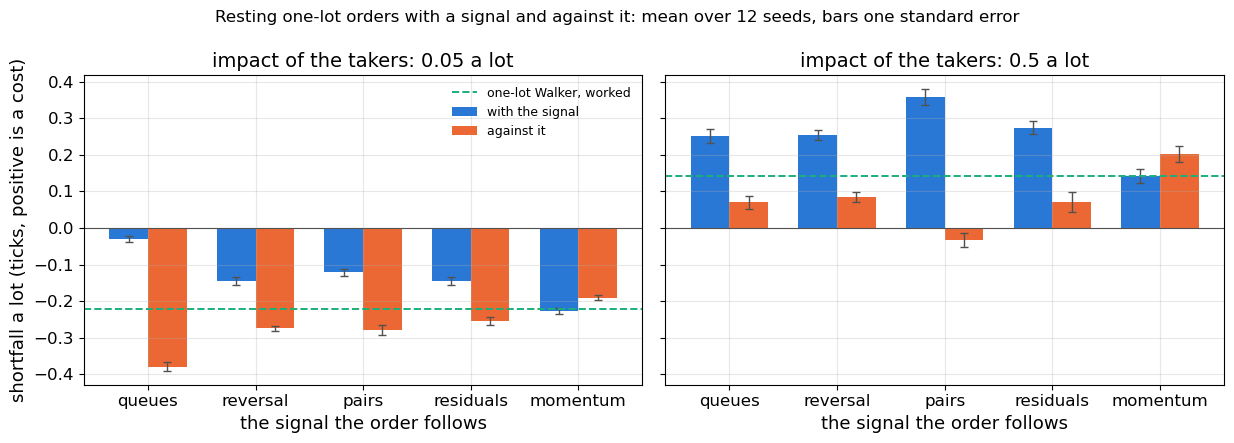

In [14]:
# 2e. The figure: the shortfall a lot of the one-lot order with the signal and against it, by signal, at an impact of
# 0.05 and of 0.5. A bar is the mean over the seeds and its bar of error one standard error over the seeds. One y-axis a
# panel, the two on one scale so that the bracket reads across; the dashed line is the one-lot Walker, worked, at that
# impact.
def signal_figure(parts):
    fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE, sharey=True)
    place, width = np.arange(len(SIGNALS)), 0.36
    for ax, impact in zip(axes, IMPACTS, strict=True):
        for shift, direction, color in ((-0.5, 'with', BLUE), (0.5, 'against', ORANGE)):
            each = [parts[(impact, signal)][direction] for signal in SIGNALS]
            ax.bar(
                place + shift * width,
                [x.mean() for x in each],
                width,
                yerr=[se_of(x) for x in each],
                color=color,
                label=f'{direction} the signal' if direction == 'with' else 'against it',
                error_kw=dict(ecolor=GRAY, lw=1, capsize=3),
            )
        walker = parts[(impact, next(iter(SIGNALS)))]['Walker']
        ax.axhline(walker.mean(), color=AQUA, lw=1.4, ls='--', label='one-lot Walker, worked')
        ax.axhline(0, color=GRAY, lw=0.8)
        ax.set_xticks(place, list(SIGNALS))
        ax.set_title(f'impact of the takers: {impact:g} a lot')
        ax.set_xlabel('the signal the order follows')
    axes[0].set_ylabel('shortfall a lot (ticks, positive is a cost)')
    axes[0].legend(loc='upper right', fontsize=9, frameon=False)
    fig.suptitle(
        f'Resting one-lot orders with a signal and against it: mean over {len(SEEDS)} seeds, bars one standard error',
        fontsize=12,
    )
    fig.tight_layout()
    plt.show()


signal_figure(signal_parts)

**At 0.05** the blue bar is above the orange one for the queues (-0.031 against -0.379), reversal (-0.146 against -0.274), pairs (-0.121 against -0.279) and residuals (-0.146 against -0.254), by 0.348, 0.128, 0.158 and 0.108 (plain differences of the printed bars, twice the own parts), and below it for momentum (-0.226 against -0.190, by 0.036). No pair of bars has overlapping standard error bars (0.007 to 0.013 on a bar), and momentum's pair is the nearest.

**At 0.5** every bar is higher, by 0.246 to 0.479 (plain differences of the printed bars), and the mean of each signal's two bars, its common part, rose by 0.362 to 0.381, about the 0.364 by which the Walker's line rose (plain differences of 2a's printed figures), which is what the takers' information costs a resting order here, on average over the two orders (a single bar rises by more or less than that, the range above). The blue bar is above the orange one for the queues (+0.251 against +0.071), reversal (+0.255 against +0.085), pairs (+0.358 against -0.033) and residuals (+0.274 against +0.071) and below it for momentum (+0.143 against +0.203), again with no pair of bars overlapping in their standard error bars (0.014 to 0.027 on a bar), and the orange bar of pairs is the only one of the ten below 0.

**The dashed line**, the one-lot Walker's -0.221 at 0.05 and +0.143 at 0.5, sits between the two bars of every signal at 0.05, nearer the blue bar (-0.226) than the orange (-0.190) for momentum. At 0.5 it sits between them for the queues, reversal, pairs and residuals, while for momentum it sits at the end of the blue bar (+0.143 on both) with the orange bar above it. Momentum's bars are described and not explained. Bars below 0 are gains against the decision mid in this market, which the head of the notebook lists as kind to a resting order, and the bracket moves the takers' information and nothing else on that list.

### What This Section Cannot Show

- **No figure here is what resting orders save in a real market.** A resting order in this market is kind to itself in the ways listed at the top of the notebook: the order flow does not react to it, nobody steps in front of it, canceling and replacing are free and instant, an order alone at the best price steps back for nothing, a jump is always seen in time, there are no fees, and the takers carry 0.05 a lot of information. The figures are what a one-lot order costs resting in this market, against the mid at its decision.
- **The bracket at 0.5 is not a test of those.** It moves the takers' information and nothing else. A figure that holds at both impacts has held against one of the items of that list and is silent on the rest. The follower's order is filled by a model's order, so the bracket changes who fills it; it does not make the flow react.
- **The signal's own part is half of a difference, under an assumption.** Writing the cost with the signal as c + s and against it as c - s assumes the signal's effect is equal and opposite for the two orders, which no run of this section tests. The two followers' markets part as soon as orders rest, so they share the inner trader's targets only approximately and their difference is read over seeds, never order by order. The cell that runs the followers prints how far apart their lots asked are: on one seed up to 9.3% of the with row for momentum at 0.05, and up to 19.7% for the residuals at 0.5, so for pairs, residuals and momentum the two followers do not ask for the same needs. A signal whose own part is 0 is one whose two orders cost the same, which is not a signal that knows nothing. The common part is the Walker's only as far as the printed `common less Walker` says, and the follower and the Walker are paired by seed on the same market seed but not on the same stretch of it, because their burns differ.
- **One-lot followers are not what a multi-lot or a rate trader pays.** A follower asks for one lot a book every 25 units and each need is done before the next. A trader with a rate has a need that creeps, grows, shrinks and vanishes while its order rests, and the lots it asks are not all got: section 3's queue row is the case where they vanish before a resting order fills. So a follower's shortfall a lot is a working cost here, because every need is got, and it is not a forecast of what a full row pays. Section 3 is where that is measured, and no figure of this section is compared with the premise review's prototype, whose orders were moved at the trader's decisions only.
- **The pairs follower's unit is a lot in each book where the pair's target is not 0, and not a lot of a pair.** Almost all of its targets have one of two sizes (the first table of 2c), so its thirds by strength are mostly ties split in proportion.
- **Strength is the inner trader's target size in lots, at the launch, and means something only within a signal.** It is not the signal's raw score, not a forecast of the return, and a target of 3 lots of the queues is not one of the residuals: each trader scales its own targets (5 lots of the largest, neutral to three factors, in whole lots). The thirds compare needs of one signal with each other and never one signal with another.
- **The share filled at the first placement is derived from a log made in a cell.** The library does not say which need an order belonged to. The cell wraps the market's own placement for one follower and counts, for each need, the orders placed in its book from its launch to the next. The check that the log holds as many placements as the account counted guards the total and not the assignment of each to a need, and it stops the run if a later version of the library changes how an order is placed.
- **Notebook 13's figures are quoted and not compared.** Only the queues and the momentum have a listener of the same signal in notebook 13 (momentum's reads its score afresh at every decision, where the follower holds its target for 100), the pairs and the residuals have a row of its test table, and the reversal at a look back of 50 has neither. They are in other units and of other horizons than a resting order's few units, and the own part is not an estimate of a signal's edge.
- **The follower's crossing twin is not run here.** What a resting order saves against crossing is section 1b's figure for the Walker and section 3's for four full rows. In this section a follower is read against the Walker and against its own opposite.
- **A follower never feeds its signal.** The inner trader is attached and never traded, so its position is 0 and its orders move no mid it reads. A real trader that traded its signal would move the mids it reads with its own market orders, which is the twin's own impact that section 3 isolates at 0.5.
- **The followers are not strategies.** They have no scorecard and no P&L worth reading, and twelve seeds are twelve draws of one market: a standard error over seeds says how much the mean moves across them and nothing about another market.
- **Nothing was chosen on `SEEDS`.** The five inner traders, the setting, the follower's design and the thirds come from seeds 1 to 8, where the library was explored, and seeds 1 to 8 are never pooled with these.

- **Momentum's own part is reported and not explained.** It is negative at both impacts, -0.018 (standard error 0.006) at 0.05 and -0.030 (standard error 0.012) at 0.5, so the run has no change of sign at 0.5 to report: the order with the signal paid less than the one against it at both. No cell of this notebook isolates the reason, and the notebook does not offer one. The negative figures of notebook 13's momentum listener, set beside it in 2d, are not offered as the reason either.

## 3. Four Traders, Worked

**What becomes of four of notebook 13's traders when their orders rest?** Sections 1 and 2 priced a lot and a signal's part of it with probes. This section lets four real traders rest their orders at the best price and measures what they make: a slow reversal trader, a fast queue follower, pairs and four-leg baskets. A trader's P&L is what its signal earned and what its execution cost, the two mixed, and this section keeps them apart with the yardstick of the notebook: `paper`, what the position it asked for at each decision would have made at that decision's mid, and `shortfall`, paper less P&L. It has four parts, and then the scorecards. 3a is the table: P&L, paper, shortfall, lots, risk, for each row as a twin and worked, and worked less twin seed by seed. 3b says what the shortfall is made of, which is the part the queue row is carried for, and, in a part added after the second run, sets the queue row against the queue row with its scores given to the books at random. 3c looks at the legs of the two relation rows, which a worked trader fills one at a time, and at what they hold of the factors. 3d asks whether execution changes which of the four is worth trading, and describes it on four rows.

**The four rows** are notebook 13's, each with the setting of its test table, and each shows a different way a signal meets a resting order.

- *Reversal, look back 50, rate 0.1, every 5* (`REVERSAL`). A need that creeps: the trader goes a tenth of the way to its target at each decision, so what an order that rests for 20 units is worked against is a need that has grown or shrunk by then.
- *Flow of queues, rate 0.02, every 1* (`QUEUES`). A fast signal: it decides every unit and goes a fiftieth of the way, so its needs come and go faster than a resting order fills.
- *Pairs by distance, 8, entry 1.25* (`PAIRS`). Two legs: a pair's order is a lot in each of two books, and the library works every leg and never hedges one that has filled.
- *Baskets, Box-Tiao, 4 of 4, entry 1, rate 0.25* (`BASKETS`). Four legs, and a rate, so the first slice of an order is the one that 3c follows.

**What is run.** On `SEEDS` (101 to 112, notebook 13's twelve, so that the twins are notebook 13's rows), at notebook 13's burn and span (`BURN`, `SPAN`), every row of the notebook has the same execution, `Execution(patience=20.0, reprice=1.0)`, which was chosen on seeds 1 to 8 in section 1's exploration and is not tuned here. Each row is run:

1. as its *twin* at the library's impact of 0.05: no execution, market orders in a `PassiveBookMarket`. These 48 runs are section 1a's (`twins_frame`), which asserted them equal to the lines notebook 13 saved, and they are not run again here;
2. *worked* at 0.05: 48 runs, with the market keeping its decisions so that the score has the split of the shortfall, and for the two relation rows with the log of their legs kept (the log reads and draws nothing, and the cell of 3b that makes one run apart without it proves the figures are the same);
3. at the bracket's impact of 0.5, where the market's market orders carry ten times the information: the *twin*, the *twin with no impact of its own*, and *worked*: 144 runs. The second twin is the one whose own market orders walk the book and take its quotes but do not push the fair values. At 0.5 a worked trader's paper and its signal are compared with the twin's, and the twin's own orders move the fair values they are marked at and read, so a paper or P&L difference against the twin is partly the twin's own impact. This twin removes the push of the twin's own orders on the fair values; it is not assumed to be a like-for-like twin of the paper (for the queue row it is not: the worked paper is below the twin's at 0.05 and differs from both twins' at 0.5, and 3a prints by how much), so what is left of a paper difference against it is printed and read in 3a. Every saving of this section is read on the shortfall a lot, each trader against its own decision mids.

That is 192 new runs, and with 1a's 48 the twenty rows of the section's frame, `traders_frame`. The part of 3b added after the second run has 24 runs of its own (two rows of the queue trader with its scores given to the books at random: worked and as a twin), and the two relation rows' worked runs also sample what they hold of the factors, which reads the market and changes no figure of the run. The cell that makes the frame asserts, in a smoke copy too, that every row is on every seed once at notebook 13's burn and span, that no twin placed a resting order and its lots are its lots asked, that a twin's shortfall is its costs and its paper its before costs, that a worked trader has no before costs, that for every run the lots are passive plus crossed, P&L is paper less shortfall, and the parts of the shortfall add up to it.

**What was explored beforehand, on seeds 1 to 8 (not this notebook's figures).**

- *Why the queue row is a full row and is split.* The exploration's table of cost by signal, which is what section 2 measures, predicted the cost of the slow rows (the reversal row, and a residuals row that is not carried here) and did not predict the fast one: of the lots the queue row asks, a resting order fills the ones the signal is wrong about and is left behind by the ones it is right about, because the price leaves it and the aim's half-lot step reverts. On seeds 1 to 8 the queue row, worked, got a little under half of the lots its paper asked (the predictions cell has it), and the rest were taken back before any filled, with the paper's gain on them in the shortfall. So its shortfall a lot is a cost of working an order only on the lots got, and 3b prints the split for every worked row. That a resting order gets this because the signal is wrong on the lots it fills and right on the lots it leaves is the exploration's reading, and 3b's split does not show it by itself: a resting order on any needs that vanish has the paper's gain on the lots it takes back. The part added after the second run to 3b sets the row against a row with the queue row's rule and no signal, whose needs are not the queue row's (it asks for fewer lots).
- *Why these four.* The exploration carried more rows and dropped the ones that showed nothing more: rows with a band (a worked trader's paper was not its twin's, 9% to 11% below it, and patience never binds), the Johansen basket (its entries differed from its twin's, as the Box-Tiao basket's do at 0.5, and Box-Tiao is the one tested), the queue row with a hold of 1 (it got a tenth of its lots) and the long-hold rows. None of them is run here.
- *Patience and reprice.* Patience 20 crossed 0.0% to 2.1% of the lots of every row kept; patience 5 crossed a fifth to two fifths and cost more on every row. Only the one-lot Walker of 1b is run at patience 5 and with no repricing.

**What is compared with what.** A worked row less its twin, taken seed by seed, is printed as P&L, as paper and as shortfall. The saving of working the order is read on the shortfall, and a paper difference is not read as the execution's. The twin's row at 0.05 is notebook 13's, and a P&L figure of a full row here is for 20,000 units, twice the exploration's span of 10,000: the predictions of the cell above are twice the exploration's, which is an extrapolation. The legs of 3c are the two relation rows', worked at 0.05, and a twin has none by construction (it crosses every leg in the step of its decision). The scorecards at the end are the worked reversal trader's and the worked pairs trader's, on `CARD_SEED`, each a recorded run.

**What this section is not.** It is not a test, and what the exploration found is not a conclusion: the notebook's predictions say what to expect and the conclusions say which held. The four traders are those of notebook 13 with one setting for execution, and the section ends with what it cannot show.

In [15]:
# Section 3's tools: its rows and how each is run, the trace that reads the legs of an order off a run, the split of a
# shortfall by the kind of fill, and what its cards check. Nothing here runs a market, except parts_by_fill, which a
# worker of 3b calls. The names of this section start with traders_, leg_ or card_.
from lob.passive import shortfall_parts

# The four rows of the section, by the name the setup gives them (REVERSAL, QUEUES, PAIRS, BASKETS), a short name for
# each, and which of them trade relations (two legs, and four): the legs of 3c are theirs.
TRADERS_LABEL = {REVERSAL: 'reversal', QUEUES: 'queues', PAIRS: 'pairs', BASKETS: 'baskets'}
TRADERS_RELATIONS = [PAIRS, BASKETS]
# The five ways a row is run, in the order a table prints them. The twin at the library's impact is section 1a's: 48
# runs that 1a made and this section reads, the other four are this section's (twelve seeds each).
TRADERS_HOWS = ('twin', 'worked', 'twin, 0.5', 'twin, no own impact, 0.5', 'worked, 0.5')


def traders_row(name, how):
    # The name of a row in this section's frame: 'pairs, worked', 'baskets, twin, no own impact, 0.5'.
    assert how in TRADERS_HOWS, how
    return f'{TRADERS_LABEL[name]}, {how}'


# The leg trace. A relation's order is what a RelationTrader asks for when one of its relations changes state: the
# books its legs are in, a lot or several in each. A worked trader's legs fill one at a time, so for a while one leg
# is in and another is not, and the trader holds a position that no relation asked for. To see it, a run keeps a log:
# at each decision, from LEG_LEAD units before the span, the relation states the trader has after deciding, the
# position it held before and the paper's position before. The log changes nothing in the run (it reads and draws
# nothing), and 3b's one-seed run, which is not logged, has the figures of the logged run's row on that seed to the
# last digit.
LEG_LEAD = 600.0  # units of time the log starts before the span, so that the first states are the ones the span meets


class ExposureSampler:
    # Added after the second run, on a review of it (a description, and nothing was chosen from it): what a worked
    # relation row holds of the factors, split into what its paper asked for and the gap between its position and its
    # paper (the lots a resting order has not filled yet, or that no relation asked for). It reads the market after
    # every step, in the worker, and takes a sample at the times the run's own score takes its exposure and gross at:
    # the first step at or after each unit of time counted from the first step at or after the burn (score_holdings'
    # own schedule, so that 3c can assert that the position's exposure and gross here are the score's). Those times
    # are steps of the market, which the run does not keep, so the samples cannot be made afterwards from the
    # decisions and the fills. A sample is the position, what the paper asked for (the account's `asked`) and their
    # difference, each through the market's own factor exposures (fair.exposures()), the squares of what each holds of
    # the factors summed over the factors. It reads the market and draws nothing, so the run is the run it was: it adds
    # one call a step and three small products a unit of time, and keeps nine running sums and no array.
    def __init__(self, trader, burn):
        self.trader, self.burn = trader, burn
        self.market, self.due, self.armed, self.n = None, burn, False, 0
        self.total = dict.fromkeys(('position', 'paper', 'gap', 'gross_position', 'gross_paper', 'gross_gap'), 0.0)
        self.gap_units = self.exposed_units = 0

    def install(self, market):
        # Wrap this market's step: the market calls it as market.step(), and it is the market's own step that runs.
        self.market, step = market, market.step

        def stepped():
            step()
            if market.time >= self.due:
                self.after()

        market.step = stepped

    def after(self):
        market = self.market
        if not self.armed:  # the step that ended the burn: the score's first sample is a unit of time after it
            self.armed, self.due = True, market.time + 1.0
            return
        position, asked = self.trader.position, market.account(self.trader).asked
        loadings = market.fair.exposures()
        held, paper, gap = position @ loadings, asked @ loadings, (position - asked) @ loadings
        lots = np.abs(position - asked).sum()
        values = {
            'position': float((held**2).sum()),
            'paper': float((paper**2).sum()),
            'gap': float((gap**2).sum()),
            'gross_position': float(np.abs(position).sum()),
            'gross_paper': float(np.abs(asked).sum()),
            'gross_gap': float(lots),
        }
        while market.time >= self.due:  # a step that crosses more than one unit samples the same state for each
            self.n += 1
            for key, value in values.items():
                self.total[key] += value
            self.gap_units += int(lots > 0)
            self.exposed_units += int(values['gap'] > 1e-9)
            self.due += 1.0

    def summary(self):
        # One number each, per run (ex_ms_ is a mean square: the mean over the samples of the sum over the factors of
        # the square of what is held of each; ex_ms_cross2 is what the position's exceeds the paper's and the gap's by:
        # twice the cross term, so that position = paper + gap + cross2 exactly).
        n = self.n or math.nan
        t = self.total
        return {
            'ex_samples': self.n,
            'ex_ms_position': t['position'] / n,
            'ex_ms_paper': t['paper'] / n,
            'ex_ms_gap': t['gap'] / n,
            'ex_ms_cross2': (t['position'] - t['paper'] - t['gap']) / n,
            'ex_gross_position': t['gross_position'] / n,
            'ex_gross_paper': t['gross_paper'] / n,
            'ex_gross_gap': t['gross_gap'] / n,
            'ex_gap_share': self.gap_units / n,
            'ex_gap_exposed': self.exposed_units / n,
        }


def make_traced(name, seed, burn):
    # A fresh trader of the catalog that logs its decisions (trader.trace), from LEG_LEAD before the burn's end, and
    # samples what it holds of the factors (trader.sampler, ExposureSampler, installed when the trader is added to a
    # market). The market it is added to gives its view to observe, and the view has the account (the paper's
    # position).
    trader = CATALOG[name]()
    trader.trace, seen = [], {}
    observe, decide, check = trader.observe, trader.decide, trader.check
    sampler = trader.sampler = ExposureSampler(trader, burn)

    def checked(market):
        check(market)
        sampler.install(market)

    def watch(market):
        seen['market'] = market
        observe(market)

    def log(mids):
        market = seen['market']
        before, asked = trader.position.copy(), market.account(trader).asked.copy()
        moves = decide(mids)
        if market.time >= burn - LEG_LEAD:
            trader.trace.append((market.time, None if trader.states is None else trader.states.copy(), before, asked))
        return moves

    trader.observe, trader.decide, trader.check = watch, log, checked
    return trader


def leg_orders(log, fills, asked_end, t0, t_end):
    # The orders of a run, from its log, its fills (the account's rows: time, book, signed lots, price, mid
    # before, kind), the paper's position at the end and the span (t0 to t_end). An order is a decision at or
    # after t0 at which a relation's state changed. Its legs are the books where the paper's position changed at
    # that decision and where the trader still needs lots (a position that is not yet the paper's). An order is
    # followed from its decision until every leg has its lots (done), or until a later decision takes the lots of
    # a leg back (censored: counted, not averaged). A leg's progress is its lots filled over its need. For each
    # order that is done:
    #   to_done      its decision to the last leg done (the slowest leg's)
    #   ahead        from the first leg done to the last
    #   unbalanced   the time some leg is further along than the least (the legs are not even)
    #   lot_units    the lots a leg is ahead of the least, summed over legs and integrated over time: lots held that
    #                no relation asked for, a time
    # A hold is a relation's state that is not 0, from the decision it enters to the decision it leaves (flat, or the
    # other way), for every hold that ended in the log, which starts LEG_LEAD before the span.
    after = [np.asarray(log[k + 1][3]) for k in range(len(log) - 1)] + [np.asarray(asked_end)]  # paper's, after each
    by_book = {}
    for when, book, lots, _, _, kind in fills:
        by_book.setdefault(book, []).append((when, lots, kind))
    orders, holds, entered, censored = [], [], {}, 0
    for k in range(1, len(log)):
        now, states, position, _ = log[k]
        before = log[k - 1][1]
        if states is None or before is None:
            continue
        states, before = np.asarray(states), np.asarray(before)
        for i in np.nonzero(states != before)[0]:
            if before[i] != 0 and i in entered:
                holds.append(now - entered.pop(i))
            if states[i] != 0:
                entered[i] = now
        if now < t0 or (states == before).all():
            continue
        change, need = after[k] - after[k - 1], after[k] - np.asarray(position)
        legs = [b for b in range(len(need)) if change[b] != 0 and need[b] != 0]
        if len(legs) < 2:
            orders.append({'kind': 'single', 'legs': len(legs)})
            continue
        taken = next(
            (log[j][0] for j in range(k + 1, len(log)) if any((after[j][b] - after[k][b]) * need[b] < 0 for b in legs)),
            math.inf,
        )
        end = min(taken, t_end)
        steps, done = [], [None] * len(legs)
        for leg, book in enumerate(legs):
            held = 0.0
            for when, lots, kind in by_book.get(book, []):
                if when < now or (when == now and kind not in ('cross', 'urgent')) or when >= end:
                    continue  # a fill before the decision, or a passive one in the same step, is not this order's
                held += lots
                steps.append((when, leg, min(max(held / need[book], 0.0), 1.0)))
                if held / need[book] >= 1.0 and done[leg] is None:
                    done[leg] = when
        if any(d is None for d in done):
            censored += 1
            orders.append({'kind': 'censored', 'legs': len(legs)})
            continue
        steps.sort()
        progress, last = np.zeros(len(legs)), now
        lot_units, unbalanced, spans = 0.0, 0.0, []
        lots_of = np.abs(need[legs]).astype(float)
        for when, leg, new in steps:
            if when > last:
                lot_units += float((lots_of * (progress - progress.min())).sum()) * (when - last)
                if progress.max() > progress.min():
                    unbalanced += when - last
                    spans.append((last, when))
            progress[leg], last = new, when
            if progress.min() >= 1.0:
                break
        grew = int(np.abs(states).sum()) - int(np.abs(before).sum())
        orders.append(
            {
                'kind': 'entry' if grew > 0 else 'exit' if grew < 0 else 'mixed',
                'legs': len(legs),
                'to_done': max(done) - now,
                'ahead': max(done) - min(done),
                'unbalanced': unbalanced,
                'lot_units': lot_units,
                'lots': float(lots_of.sum()),
                'changed': int((states != before).sum()),
                'spans': spans,
            }
        )
    return orders, holds, censored


def leg_summary(orders, holds, censored, t0, span):
    # What one run says about its legs, one number each: means over its orders that are done, and over its holds.
    done = [o for o in orders if 'to_done' in o]
    column = lambda key: [o[key] for o in done]  # noqa: E731
    mean = lambda values: float(np.mean(values)) if len(values) else math.nan  # noqa: E731
    covered, edge = 0.0, -math.inf
    for a, b in sorted(x for o in done for x in o['spans']):  # the share of the span some order's legs are not even
        a = max(a, t0, edge)
        if b > a:
            covered, edge = covered + b - a, b
    return {
        'leg_orders': len(done),
        'leg_single': sum(o['kind'] == 'single' for o in orders),
        'leg_censored': censored,
        'leg_legs': mean(column('legs')),
        'leg_lots': mean(column('lots')),
        'leg_to_done': mean(column('to_done')),
        'leg_to_done_p90': float(np.percentile(column('to_done'), 90)) if done else math.nan,
        'leg_ahead': mean(column('ahead')),
        'leg_unbalanced': mean(column('unbalanced')),
        'leg_lot_units': mean(column('lot_units')),
        'leg_multi_share': mean([o['changed'] > 1 for o in done]),
        'leg_holds': len(holds),
        'leg_hold': mean(holds),
        'leg_unbalanced_of_hold': sum(column('unbalanced')) / sum(holds) if holds else math.nan,
        'leg_to_done_entry': mean([o['to_done'] for o in done if o['kind'] == 'entry']),
        'leg_to_done_exit': mean([o['to_done'] for o in done if o['kind'] == 'exit']),
        'leg_union_share': covered / span,
        'leg_lots_ahead': sum(column('lot_units')) / span,
    }


def leg_extra(burn, span, market, trader):
    # An `extra` of run_rows: what a logged run says about its legs, from its own log and account, in the worker.
    account = market.account(trader)
    orders, holds, censored = leg_orders(trader.trace, account.fills, account.asked, burn, market.time)
    return {**leg_summary(orders, holds, censored, burn, span), **trader.sampler.summary()}


def traded_row(name):
    # A row of the catalog as it is run: the two relation rows keep the log of their legs (leg_extra).
    if name not in TRADERS_RELATIONS:
        return full_row(name)
    return Row(partial(make_traced, name), BURN, SPAN, partial(leg_extra, BURN, SPAN))


def traders_cases():
    # The sixteen cases this section runs: for each of the four rows, worked at the library's impact (the market
    # keeps its decisions, so that the score has the split of the shortfall; the relation rows keep their legs),
    # and at the bracket's, the twin, the twin with no impact of its own and worked. The twins at the library's
    # impact are 1a's.
    cases = {}
    for name in FULL:
        cases[traders_row(name, 'worked')] = Case(traded_row(name), WORKED, keep=True)
        cases[traders_row(name, 'twin, 0.5')] = Case(full_row(name), None, IMPACT_HIGH)
        cases[traders_row(name, 'twin, no own impact, 0.5')] = Case(full_row(name), None, IMPACT_HIGH, own_impact=False)
        cases[traders_row(name, 'worked, 0.5')] = Case(full_row(name), WORKED, IMPACT_HIGH, keep=True)
    return cases


def parts_by_fill(name, seed, impact=IMPACT):
    # One worked run of a row as run_one makes it, with the library's split of its shortfall (shortfall_parts) in
    # the form that tells the lots got apart by the kind of fill that got them: a model's market order, a model's
    # limit order across the quote, or the trader's own market order. The score has only the sums of the parts.
    # Small values, for a worker (and its seconds, for the core-minutes).
    check_seed(seed)
    started = time.time()
    row = full_row(name)
    trader = row.make(seed, row.burn)
    market = make_market(seed, impact)
    market.keep_decisions = True
    market.add(trader, WORKED)
    while market.time < row.burn:
        market.step()
    since = market.since(trader)
    until = market.time + row.span
    while market.time < until:
        market.step()
    parts = shortfall_parts(market, trader, since)
    return {
        'row': traders_row(name, 'worked'),
        'seed': seed,
        'shortfall': parts.shortfall,
        'residual': parts.residual,
        'got_lots': parts.got_lots,
        'back_lots': parts.back_lots,
        'unasked_lots': parts.unasked_lots,
        'open_lots': parts.open_lots,
        'got_cost': parts.got_cost,
        'back_drift': parts.back_drift,
        'unasked_cost': parts.unasked_cost,
        'open_drift': parts.open_drift,
        'lots_by_fill': parts.got_lots_by_fill,
        'cost_by_fill': parts.got_cost_by_fill,
        'secs': time.time() - started,
    }


def card_drift(trader, market):
    # What a record at the decisions leaves out of a worked trader's P&L, from the run's account and its record.
    # The record holds, after each decision, what the trader held (valued at the mids of the decisions), so a
    # fill between two decisions is in it only at the next decision. So the fills' P&L is the record's (cost
    # included) plus two terms, which make it exactly:
    #   drift  the lots filled between decisions, each times the next decision's mid less the mid before the
    #   fill: what the
    #          price did between a fill and the decision that first holds it (a lot the trader's own market order
    #          filled at a decision is not counted: the record has it at once)
    #   tail   what the position held at the last decision made from that decision's mids to the marks at the run's end
    # The record's cost is the spread paid by crossing less the spread resting orders earned, each against the
    # mid before its order: exactly what each fill's price is against the mid before it.
    times = np.array([step[0] for step in trader.history])
    drift = 0.0
    for when, book, signed, _, mid_before, kind in market.account(trader).fills:
        if kind in ('cross', 'urgent') and np.any(np.abs(times - when) < 1e-12):
            continue  # a decision's own market order
        first = int(np.searchsorted(times, when, side='left'))  # the first decision at or after the fill
        later = trader.history[first][1][book] if first < len(times) else market.marks_for(trader)[book]
        drift += signed * (later - mid_before)
    tail = float(trader.history[-1][2] @ (market.marks_for(trader) - trader.history[-1][1]))
    return drift, tail


def traders_split_line(frame, name, how):
    # A worked row's shortfall a lot with its split, as one line: the parts over the lots asked (they add to it), and
    # the share of the lots asked that are got. 3a prints it under the table for the queue row, whose shortfall a lot
    # is not read alone (3b says why); the frame is one with keep=True runs.
    lines = frame[frame.row == traders_row(name, how)]
    return (
        f'{TRADERS_LABEL[name]}, {how}: shortfall a lot {lines.shortfall_a_lot.mean():+.3f} = got part '
        f'{lines.got_part.mean():+.3f} + taken-back part {lines.back_part.mean():+.3f} + open part '
        f'{lines.open_part.mean():+.3f} + unasked part {(lines.unasked_cost / lines.asked_lots).mean():+.3f}, with '
        f'{lines.got_share.mean():.1%} of the lots asked got: not a cost of working an order (3b)'
    )

In [16]:
# 3. The runs of section 3: four rows, each as a twin, worked, and at the bracket's impact also as the twin with no
# impact of its own and worked. The twins at the library's impact are section 1a's (twins_frame, 48 runs, not run
# again); the sixteen cases below are this section's, on every seed of SEEDS: 192 runs. A worked run keeps the
# market's decisions, so that its score has the split of the shortfall (3b), and a relation row's run keeps the log
# of its legs (3c).
traders_runs = traders_cases()
assert {case.execution for case in traders_runs.values() if case.execution is not None} == {WORKED}, (
    'every worked row has the same execution'
)
traders_new = run_rows(traders_runs, SEEDS)

traders_twins = twins_frame[twins_frame.row.isin(FULL)]
assert sorted(traders_twins.row.unique()) == sorted(FULL) and len(traders_twins) == len(FULL) * len(SEEDS), (
    "section 1a's frame has not the four twins on every seed"
)
traders_frame = pd.concat(
    [traders_twins.assign(row=traders_twins.row.map({name: traders_row(name, 'twin') for name in FULL})), traders_new],
    ignore_index=True,
)
TRADERS_ROWS = [traders_row(name, how) for name in FULL for how in TRADERS_HOWS]  # the order a table prints them


def traders_checks(frame):
    # check_frame (the setup's: every row on every seed once, lots passive plus crossed, P&L paper less shortfall, a
    # twin that placed no resting order with its lots its lots asked, its shortfall its costs and its paper its before
    # costs, a worked trader with no before costs) and what is this section's own: the twenty rows, each with the
    # burn, span and impact it should have, and the parts of the shortfall adding up to it (so does their sum over
    # lots asked to the shortfall a lot). It stops the notebook, in a smoke copy too, if one does not hold.
    assert sorted(frame.row.unique()) == sorted(TRADERS_ROWS), 'the frame has not the twenty rows of section 3'
    for row, lines in frame.groupby('row', sort=False):
        assert (lines.burn == BURN).all() and (lines.span == SPAN).all(), (
            f'{row!r} has not the burn and span of notebook 13'
        )
        impact = IMPACT_HIGH if row.endswith('0.5') else IMPACT
        assert (lines.impact == impact).all(), f'{row!r} is not at an impact of {impact:g}'
        assert (lines.worked == (row.endswith('worked') or row.endswith('worked, 0.5'))).all(), (
            f'{row!r}: worked or not'
        )
    gaps = check_frame(frame, 'section 3')
    worked = frame[frame.worked]
    parts = worked.got_cost + worked.back_drift + worked.unasked_cost + worked.open_drift
    lot_a = worked.asked_lots > 0
    more = {
        'worked: parts less the shortfall': gap_of(parts, worked.shortfall),
        'worked: parts over lots asked less the shortfall a lot': gap_of(
            (parts / worked.asked_lots)[lot_a], worked.shortfall_a_lot[lot_a]
        ),
    }
    for what, gap in more.items():
        assert gap < 1e-6, f'{what}: largest gap {gap:.2e}'
    print(
        f'Checked: {len(frame)} runs, {len(TRADERS_ROWS)} rows on the {len(SEEDS)} seeds once, at burn {BURN:,.0f} and '
        f'span {SPAN:,.0f}; no twin placed a resting order and its lots are its lots asked; largest gaps, '
        + ', '.join(f'{what} {gap:.1e}' for what, gap in {**gaps, **more}.items())
        + '.'
    )


traders_checks(traders_frame)
assert (
    traders_new.leg_orders[traders_new.row.isin([traders_row(n, 'worked') for n in TRADERS_RELATIONS])].gt(0).all()
), 'a worked relation row has no orders in its log'
print(
    f'Of the {len(traders_new)} runs of this cell, {int(traders_new.worked.sum())} are worked '
    f'(each with patience {WORKED.patience:g} and reprice {WORKED.reprice:g}), '
    f'{int(traders_new.leg_orders.notna().sum())} kept the log of their legs.'
)
ran(traders_new, label='This cell: ')

Checked: 240 runs, 20 rows on the 12 seeds once, at burn 10,465 and span 20,000; no twin placed a resting order and its lots are its lots asked; largest gaps, twin: lots less lots asked 0.0e+00, lots less passive and crossed lots 0.0e+00, passive lots less those hit by a market and a limit order 0.0e+00, P&L less paper less shortfall 0.0e+00, twin: shortfall less costs 0.0e+00, twin: paper less before costs 0.0e+00, worked: parts less the shortfall 0.0e+00, worked: parts over lots asked less the shortfall a lot 0.0e+00.
Of the 192 runs of this cell, 96 are worked (each with patience 20 and reprice 1), 24 kept the log of their legs.
This cell: 192 runs, 210.3 core-minutes.


### 3a. The Table

**What does it do to each of the four traders to rest its orders instead of crossing: to its P&L, its paper, its shortfall and its risk, and does the saving survive the bracket?** The next cell prints, for each of the four rows, the mean over the twelve seeds of P&L (with its standard error and the seeds on which it is positive), paper, shortfall, shortfall a lot, the lots (asked, traded, passive and crossed, the share crossed), the mean wait of the needs that ended, entries, gross, exposure, `deviation_long` and `risk_adjusted_long`. First at the library's impact, as the twin and worked, then at the bracket's impact, as the twin, the twin with no impact of its own, and worked. **Before costs is not printed for a worked trader, whose figure is `nan`:** its P&L and its costs leave out what the price did between a decision and a fill, which is the signal's in a crossing trader's and not in a worked one's. `paper` is what to set beside a crossing trader's before costs, and for a twin they are the same figure (the checks of the run cell assert it).

The cell after it takes the differences, seed by seed. At the library's impact, worked less twin in P&L, paper, shortfall, shortfall a lot, entries and `risk_adjusted_long`; the difference of P&L is the difference of paper less the difference of shortfall, which the cell asserts. At the bracket's impact it takes worked less twin, worked less the twin with no impact of its own, and the twin with no impact of its own less the twin, which is what the twin's own market orders do to the paper and the signal. The saving a lot, the twin's shortfall a lot less the worked trader's, is printed at both impacts with its change from one to the other: **that is the bracket, and it is read on the shortfall a lot** and not on a difference of P&L or paper against the plain twin at 0.5. The twin with no impact of its own removes the push of the twin's own orders on the fair values, and is not assumed to be a like-for-like twin of the paper: what is left of a paper difference against it is printed and read.

The end of the cell of the differences, added after the second run, on a review of it, prints each row's P&L gain over its twin as its three terms: the twin's shortfall (what it paid to cross) less the worked row's, plus the paper difference, and the gain as a multiple of what the twin paid, at the library's impact against the twin and at the bracket's against the twin with no impact of its own. A description: nothing was chosen from it.

In [17]:
# 3a. The table: each row as a twin and worked at the library's impact, and at the bracket's impact as the twin, the
# twin with no impact of its own and worked. Every figure is the mean over the seeds, its standard error where there
# is one, and the seeds on which P&L is positive. A twin's paper is its before costs; a worked trader has none (nan),
# so `paper` is the figure to read in both.
traders_table = table_of(traders_frame).loc[TRADERS_ROWS]
TRADERS_MONEY = ['pnl', 'se', 'positive', 'paper', 'shortfall', 'shortfall_a_lot', 'shortfall_a_lot_se']
TRADERS_LOTS = ['asked_lots', 'lots', 'passive_lots', 'crossed_lots', 'crossed_share', 'wait', 'entries', 'gross']
TRADERS_RISK = ['exposure', 'deviation_long', 'risk_adjusted_long', 'risk_adjusted_long_se']


def traders_levels(how):
    # The rows of the table for these ways of running (see TRADERS_HOWS), in the order of the traders, printed in three
    # blocks: P&L, paper and the shortfall; the lots; the risk.
    rows = [traders_row(name, h) for name in FULL for h in how]
    for block in (TRADERS_MONEY, TRADERS_LOTS, TRADERS_RISK):
        print(shown(traders_table.loc[rows], keep=block))
        print()
    for h in how:  # the queue row's shortfall a lot is never printed alone
        if h.startswith('worked'):
            print(traders_split_line(traders_frame, QUEUES, h))
            print()


print(
    f'At the library\'s impact ({IMPACT:g}), {len(SEEDS)} seeds, burn {BURN:,.0f}, span {SPAN:,.0f}: the twin '
    f'(section 1a\'s '
    f'runs) and the trader worked with patience {WORKED.patience:g} and reprice {WORKED.reprice:g}. P&L, paper and '
    f'shortfall in ticks x lots; shortfall_a_lot is the shortfall over the lots asked (a positive figure is a cost); '
    f'lots are the lots the trader traded; wait is the mean wait of the needs that ended; gross is the lots held, '
    f'across '
    f'the books; exposure the root mean square of what it holds of the factors; deviation_long and risk_adjusted_long '
    f'as the earlier notebooks print them.\n'
)
traders_levels(('twin', 'worked'))
print(
    f"At the bracket's impact ({IMPACT_HIGH:g}), where the market's market orders carry ten times the information: "
    f'the twin, the twin whose own market orders do not push the fair values, and the worked trader.\n'
)
traders_levels(('twin, 0.5', 'twin, no own impact, 0.5', 'worked, 0.5'))
print(
    "The twin's own market orders push the fair values its paper is marked at and its signal reads, so at the "
    "bracket's "
    "impact a difference between a worked trader and the twin in paper or P&L is partly the twin's own impact; the "
    "twin "
    "with no impact of its own removes the push of the twin's own orders on the fair values, and what is left of a "
    "paper difference against it is printed below. The shortfall a lot is read against each "
    "trader's own decision mids, and the bracket is read on it."
)

At the library's impact (0.05), 12 seeds, burn 10,465, span 20,000: the twin (section 1a's runs) and the trader worked with patience 20 and reprice 1. P&L, paper and shortfall in ticks x lots; shortfall_a_lot is the shortfall over the lots asked (a positive figure is a cost); lots are the lots the trader traded; wait is the mean wait of the needs that ended; gross is the lots held, across the books; exposure the root mean square of what it holds of the factors; deviation_long and risk_adjusted_long as the earlier notebooks print them.

                     pnl  se  positive   paper shortfall shortfall_a_lot shortfall_a_lot_se
row                                                                                        
reversal, twin    +4,364 109  12 of 12 +11,314    +6,950          +0.995              0.002
reversal, worked +12,625  79  12 of 12 +11,479    -1,146          -0.164              0.004
queues, twin      -8,823  68   0 of 12  +1,596   +10,418          +1.010              0.00

**Three of the four traders are profitable crossed and worked, and the queue row is profitable in neither.** At the library's impact the twins are notebook 13's lines (1a asserted every figure notebook 13 printed for them, to the last digit). Crossed, reversal makes +4,364 (standard error 109, 12 of 12 seeds positive), queues -8,823 (se 68, 0 of 12), pairs +7,808 (se 91, 12 of 12) and baskets +6,697 (se 210, 12 of 12). Worked, the same traders make +12,625 (se 79, 12 of 12), -266 (se 55, 2 of 12), +15,140 (se 116, 12 of 12) and +19,108 (se 637, 12 of 12). Resting the orders raises the three profitable rows on every seed, and takes the queue row from a loss of 8,823 to one of 266. A loss it stays: -266 is about 4.8 standard errors below 0 (a plain ratio of the two printed figures), and positive on 2 of 12 seeds. The prediction was written "about 0", as -120 (se 100, twice the exploration's -60 over 10,000 units, an extrapolation). The run is below it, by 146 (a plain difference), which is 1.28 combined standard errors, so the prediction held by the rule written before the run, and the queue row did not become profitable worked.

**A lot cost about a tick crossed, and worked it cost a gain or next to nothing on the slow rows.** The shortfall a lot is against the decision mid, and a positive figure is a cost. Crossed, a lot cost +0.995 (se 0.002) for reversal, +1.010 (se 0.002) for queues, +1.184 (se 0.006) for pairs and +1.034 (se 0.006) for baskets: the spread and the depth of the book that a market order pays, which notebooks 12 to 16 measured. Worked, it cost -0.164 (se 0.004), +0.146 (se 0.004), +0.011 (se 0.011) and -0.094 (se 0.011). Reversal and baskets are a gain against the decision mid, pairs is not resolved from 0 (its figure is as large as its standard error), and queues is a cost that is not the cost of working an order. All eight figures held against the predictions of seeds 1 to 8 (reversal -0.16 (0.011) worked and +0.99 as a twin, queues +0.152 (0.007) and +1.01, pairs 0.00 (0.014) and +1.17, baskets -0.08 (0.021) and +1.049 (0.006)). The nearest to the rule's limit of three combined standard errors is the reversal twin's, at z +2.92: a prediction rounded to two places and given no standard error of its own.

**The queue row's +0.146 is not what working an order costs.** The line printed under the table splits it: the shortfall a lot of +0.146 is a got part of -0.087, a taken-back part of +0.233, an open part of +0.000 and an unasked part of +0.000, with 47.1% of the lots asked got. A little under half of the lots it asked for were got, and the lots it got cost less than crossing; the positive figure is the paper's drift on lots that were asked and taken back before they filled, which no order cost. 3b says what that is made of, and the queue row's figure is not quoted without it. For the other three rows the worked figure is a gain or about 0 against the decision mid, and 3b says how far each is the cost of the lots got. All of it is this market's: the title cell lists what a resting order is given here, and the bracket below moves one item of that list, the takers' information, and none of the others.

**A patience of 20 is rarely reached.** Worked at the library's impact, nearly every lot the traders traded rested. Reversal traded 6,755 lots, 6,746 passive and 9 crossed (a crossed share of 0.001); queues 4,780, with 4,774 passive and 5 crossed (0.001); pairs 5,974, with 5,953 and 21 (0.004); baskets 10,509, with 10,338 and 171 (0.017). The figures cell at the end of the section prints the shares to four places: 0.0014, 0.0011, 0.0035 and 0.0169. A need that ended had waited 3.2 units on average for reversal, 3.6 for queues, 4.4 for pairs and 3.5 for baskets, which is under a quarter of the patience. The second sentence of the predictions, that no row crosses more than about 2% of its lots, held: the largest share is the baskets' 0.0169 at 0.05, and each of the eight worked rows (four at each impact) is at most 2.0%. What it does not say is that each lot was worked for up to 20 units: the patience is the age of a need's oldest lot, and the crossed share is the share of the lots of needs whose patience ran out (the last cell of the section says so).

**A worked trader trades about as often as its twin and holds about as many lots, and its risk is higher on the relation rows.** Entries a seed, worked against twin: 4,591.1 against 4,608.0 for reversal, 90,612.9 against 90,834.7 for queues, 668.9 against 662.3 for pairs and 412.2 against 443.6 for baskets; the gross, the lots held across the books, is 19.5 against 19.6, 3.2 against 3.2, 16.7 against 16.9 and 33.2 against 32.8. The paired table in the next cell pairs the entries and `risk_adjusted_long`: of the entries' differences only the baskets' 31.4 fewer are resolved, on every seed, and `risk_adjusted_long` is higher worked on every seed. The gross, the exposure and `deviation_long` are paired in 3c, for all four rows (it prints the queue row's gross 0.06 lots below its twin's, 3 standard errors from 0, a plain ratio). The exposure, the root mean square of what the trader holds of the factors (3c is about it), is 1.74 against 1.64, 1.60 against 1.56, 2.08 against 1.33 and 2.02 against 0.92: the same for reversal and queues, much higher for pairs and baskets. `deviation_long` is 4.41 against 4.15, 1.59 against 1.88, 4.85 against 4.31 and 8.70 against 7.62. `risk_adjusted_long` is higher worked on every row: 0.144 against 0.053 for reversal, -0.008 against -0.235 for queues, 0.157 against 0.091 for pairs and 0.110 against 0.044 for baskets, and the queue row's is still below 0.

**At the bracket's impact a crossed lot costs about 0.17 to 0.19 more, and a worked lot costs more by an amount that depends on the row.** At 0.5 the market's market orders carry ten times the information. The shortfall a lot, each trader against its own decision mids: the twin +1.165 (se 0.003) for reversal, +1.176 (se 0.003) for queues, +1.371 (se 0.010) for pairs and +1.212 (se 0.007) for baskets; the twin with no impact of its own +1.171 (se 0.003), +1.182 (se 0.003), +1.393 (se 0.012) and +1.217 (se 0.009); worked +0.115 (se 0.010), +0.267 (se 0.003), +0.097 (se 0.020) and +0.305 (se 0.008). From 0.05 the twin's cost rises by 0.170, 0.166, 0.187 and 0.178 and the worked trader's by 0.279, 0.121, 0.086 and 0.399 (plain differences of the printed figures). So the worked cost rises more than the twin's for reversal and baskets and less for queues and pairs, which is the change of the saving in the next cell. The twin's own market orders do not move a crossed lot's cost much: the twin with no impact of its own is within 0.023 of the twin on every row (the paired table prints the differences). Seven of the eight predictions at 0.5 held (the twins +1.16, +1.17, +1.37 and +1.21; the worked traders +0.10, +0.12 (0.035) and +0.29). The queue row's worked figure did not: it was predicted at +0.25 with no standard error, and the run's +0.267 (se 0.003) is 5.38 combined standard errors from it though 0.017 above it. The prediction was given without a standard error, so the rule judged it on the run's alone, which the predictions cell said is too narrow; at that cell's estimate of a tolerance 1.6 times wider it is still about 3.4 combined standard errors from it (a plain ratio), and the notebook does not say why.

**The P&L and the paper at 0.5, where the twin's paper is not the like-for-like figure.** P&L: the twin +21,400 (se 254), -13,999 (se 109), +27,292 (se 370) and +30,009 (se 1,036); the twin with no impact of its own +21,470 (se 347), -14,942 (se 124), +26,805 (se 436) and +35,523 (se 946); worked +28,752 (se 350), -4,944 (se 138), +33,862 (se 490) and +45,460 (se 1,116). The three profitable rows are positive on 12 of 12 seeds in all three versions, and the queue row on none. Paper: the twin +29,524, -1,275, +35,148 and +44,229; the twin with no impact of its own +29,522, -2,505, +34,323 and +48,099; worked +29,543, -2,123, +34,379 and +48,607. The twin's paper is not the twin with no impact of its own's, on the queue row and the baskets row by more than a thousand, so the twin's own orders move the fair values it is marked at, and a paper or P&L difference against the plain twin at 0.5 is not the execution's alone. The next cell pairs them.

In [18]:
# 3a. Worked less twin, seed by seed (the same seeds in both rows, asserted by the pairing). A difference of P&L is the
# difference of paper less the difference of shortfall, which the cell asserts. At the library's impact the twin is the
# crossing trader; at the bracket's, where the twin's own market orders push the fair values, the worked trader is
# compared with the twin and with the twin that has no impact of its own, and the two twins with each other.
TRADERS_PAIRED = ['paper', 'shortfall', 'shortfall_a_lot', 'entries', 'risk_adjusted_long']


def traders_pairs(one, other):
    # {trader: (its row 'one', its row 'other')} for the four traders: `one` and `other` are ways of running.
    return {TRADERS_LABEL[name]: (traders_row(name, one), traders_row(name, other)) for name in FULL}


def traders_difference(label, one, other, impact):
    # One table: row 'one' less row 'other' for each of the four traders, paired by seed, printed with each difference,
    # its standard error and the seeds on which it is above 0. Returns it (a frame, a trader a line).
    table = paired_table(traders_frame, traders_pairs(one, other), *TRADERS_PAIRED)
    assert gap_of(table.pnl, table.paper - table.shortfall) < 1e-6, (
        'a difference of P&L is not the difference of paper less that of shortfall'
    )
    print(f'{label} (impact {impact:g}), {len(SEEDS)} seeds:\n')
    for first, block in ((True, ['paper', 'shortfall']), (False, ['shortfall_a_lot', 'entries', 'risk_adjusted_long'])):
        keep = (['pnl', 'se', 'positive'] if first else []) + [
            x for c in block for x in (c, f'{c}_se', f'{c}_positive')
        ]
        print(shown(table, keep=keep, entries='+,.1f', entries_se=',.1f'))
        print()
    return table


traders_gain = traders_difference('Worked less its twin', 'worked', 'twin', IMPACT)
print(
    "The queue row's shortfall a lot in the table above is not read alone. Its worked row, split "
    f'(impact {IMPACT:g}):\n{traders_split_line(traders_frame, QUEUES, "worked")}\n'
)
traders_gain_high = traders_difference('Worked less its twin', 'worked, 0.5', 'twin, 0.5', IMPACT_HIGH)
traders_gain_fair = traders_difference(
    'Worked less the twin with no impact of its own', 'worked, 0.5', 'twin, no own impact, 0.5', IMPACT_HIGH
)
traders_own = traders_difference(
    'The twin with no impact of its own less the twin: what the twin\'s own impact does',
    'twin, no own impact, 0.5',
    'twin, 0.5',
    IMPACT_HIGH,
)

# The bracket is read on the shortfall a lot, each trader against its own decision mids: the saving is the twin's less
# the worked trader's, at each impact, and the saving at the bracket's impact less the library's, seed by seed.
print('The saving a lot (the twin\'s shortfall a lot less the worked trader\'s), at each impact, seed by seed:\n')
traders_saving = {}
for name in FULL:
    low = -lead_of(traders_frame, traders_row(name, 'worked'), traders_row(name, 'twin'), 'shortfall_a_lot')
    high = -lead_of(traders_frame, traders_row(name, 'worked, 0.5'), traders_row(name, 'twin, 0.5'), 'shortfall_a_lot')
    traders_saving[name] = (low, high)
    print(
        f'{TRADERS_LABEL[name]:<9} at {IMPACT:g} {said(paired_of(low), 3)}\n'
        f'{"":<9} at {IMPACT_HIGH:g} {said(paired_of(high), 3)}\n'
        f'{"":<9} the saving at {IMPACT_HIGH:g} less at {IMPACT:g}: {said(paired_of(high - low), 3)}'
    )
    if name == QUEUES:  # its worked shortfall a lot is not read alone
        print(f'{"":<9} {traders_split_line(traders_frame, QUEUES, "worked")}')


# Added after the second run, on a review of it (a description, and nothing was chosen from it): each row's P&L gain
# over its twin as its three terms. A gain is the twin's shortfall (what it paid to cross) less the worked row's
# shortfall, plus the paper difference: P&L is paper less shortfall in every run, so the means over the seeds add as the
# seeds do, which the cell asserts. The gain over the twin's shortfall is how many times what the twin paid it is. At
# the library's impact the twin is the plain one; at the bracket's it is the twin with no impact of its own, whose paper
# is not the twin's (the plain twin's own impact is in its paper).
def traders_terms(gain, twin_how, worked_how):
    # One line a row for a table of worked less twin (`gain`, from traders_difference) whose twin is the row 'twin_how':
    # the gain, the twin's shortfall, the worked row's, the paper difference and the multiple. Returns the terms.
    terms = {}
    for name in FULL:
        label = TRADERS_LABEL[name]
        twin_paid = float(traders_table.shortfall[traders_row(name, twin_how)])
        worked_paid = float(traders_table.shortfall[traders_row(name, worked_how)])
        paper = float(gain.paper[label])
        assert abs(gain.pnl[label] - (twin_paid - worked_paid + paper)) < 1e-6 * (1 + abs(twin_paid)), (
            f'{label}: the gain is not the twin\'s shortfall less the worked row\'s plus the paper difference'
        )
        terms[label] = (float(gain.pnl[label]), twin_paid, worked_paid, paper)
        print(
            f'  {label:<9} gain {gain.pnl[label]:+,.0f} = twin\'s shortfall {twin_paid:,.0f} less the worked row\'s '
            f'{worked_paid:+,.0f} plus the paper difference {paper:+,.0f}; {gain.pnl[label] / twin_paid:.2f} times '
            f'what the twin paid'
        )
    return terms


print(
    '\nAdded after the second run, on a review of it: the P&L gain over the twin as its three terms, in ticks x lots a '
    "seed (the means over the seeds): the twin's shortfall less the worked row's, plus the paper difference, and the "
    'gain as a multiple of what the twin paid. A description: nothing was chosen from it.\n'
)
print(f'At the library\'s impact ({IMPACT:g}), against the twin:')
traders_terms_low = traders_terms(traders_gain, 'twin', 'worked')
print(f'\nAt the bracket\'s impact ({IMPACT_HIGH:g}), against the twin with no impact of its own:')
traders_terms_fair = traders_terms(traders_gain_fair, 'twin, no own impact, 0.5', 'worked, 0.5')

Worked less its twin (impact 0.05), 12 seeds:

             pnl  se  positive paper paper_se paper_positive shortfall shortfall_se shortfall_positive
reversal  +8,262  68  12 of 12  +166       72        9 of 12    -8,096           22            0 of 12
queues    +8,557  79  12 of 12  -383      113        2 of 12    -8,940           77            0 of 12
pairs     +7,332  91  12 of 12  +302       77       11 of 12    -7,029           91            0 of 12
baskets  +12,411 535  12 of 12  -119      188        4 of 12   -12,530          538            0 of 12

         shortfall_a_lot shortfall_a_lot_se shortfall_a_lot_positive entries entries_se entries_positive risk_adjusted_long risk_adjusted_long_se risk_adjusted_long_positive
reversal          -1.160              0.005                  0 of 12   -16.9       19.6          3 of 12              0.091                 0.002                    12 of 12
queues            -0.865              0.005                  0 of 12  -221.8      118.1  

**Every worked trader beat its twin on every seed, and the gain is the twin's shortfall less the worked row's, plus the paper difference.** Worked less twin at the library's impact, paired by seed, in P&L: +8,262 (standard error 68) for reversal, +8,557 (se 79) for queues, +7,332 (se 91) for pairs and +12,411 (se 535) for baskets, each positive on 12 of 12 seeds. The shortfall differences are -8,096 (se 22), -8,940 (se 77), -7,029 (se 91) and -12,530 (se 538), none above 0 on any seed, and the shortfall a lot's are -1.160 (se 0.005), -0.865 (se 0.005), -1.172 (se 0.011) and -1.128 (se 0.007). The predictions for the P&L gains (seeds 1 to 8's, with the figures twice the exploration's, which is an extrapolation) were +8,200 (se 180), +8,600 (se 188), +7,000 (se 270) and +11,700 (se 700), and all four held by the rule, at z +0.32, -0.21, +1.16 and +0.81.

Added after the second run, on a review of it (a description, and nothing was chosen from it), the end of the cell prints each gain as three terms: the twin's shortfall, less the worked row's, plus the paper difference. Reversal: +8,262 = 6,950 less -1,146 plus +166. Queues: +8,557 = 10,418 less +1,478 plus -383. Pairs: +7,332 = 7,099 less +70 plus +302. Baskets: +12,411 = 11,496 less -1,034 plus -119. As a multiple of what the twin paid to cross, the gains are 1.19, 0.82, 1.03 and 1.08. So a gain is "about what the twin paid" only as that identity, and the ratios run from 0.82 to 1.19: the saving in shortfall is the larger term of each gain and the paper difference the smaller.

**The paper difference is not 0 on three of the four rows, and it is not read as the twin's own impact.** Reversal's is +166 (se 72, 9 of 12 seeds above 0), about 2.3 standard errors above 0 (a plain ratio of the two printed figures); queues' is -383 (se 113, 2 of 12), about 3.4; pairs' is +302 (se 77, 11 of 12), about 3.9; baskets' is -119 (se 188, 4 of 12), about 0.6, the one that is within its standard error. They are small beside the gains, but they are there, and the signs differ: the worked paper is above its twin's for reversal and pairs and below it for queues and baskets. The twin's own impact is separated in this run only at 0.5, and nothing printed shows that these are it, so they are not read as it, and they are not read as the execution's either: they are a description, and nothing printed says what makes them. The entries of a worked trader and its twin differ by -16.9 (se 19.6, 3 of 12), -221.8 (se 118.1, 4 of 12), +6.6 (se 3.8, 7 of 12) and -31.4 (se 3.8, 0 of 12) a seed, which is resolved only for baskets, the row whose paper difference is the one that is not; for reversal, queues and pairs, whose paper differences are 2.3 to 3.9 standard errors from 0, the entry differences are within two standard errors of 0 (plain ratios) and so give no reason for them. The control's two twins differ in paper by -53 (se 24) at 0.05 (1c), so the twin's own impact at 0.05 is not ruled out either.

**The risk-adjusted figure rose on every row and every seed, and rose most for the queue row.** The difference in `risk_adjusted_long` is +0.091 (se 0.002) for reversal, +0.227 (se 0.005) for queues, +0.066 (se 0.003) for pairs and +0.066 (se 0.003) for baskets, each positive on 12 of 12 seeds. The queue row gains most and is still below 0 worked (-0.008, in the table above); of the three profitable rows reversal gains most, and pairs and baskets are level at the printed places. The relation rows' risk rose too, which 3c reports (`deviation_long` +0.53 and +1.08), and the risk-adjusted figure rose all the same. These are this market's gains: the title cell lists what a resting order is given here, and the bracket below moves only the takers' information.

**At 0.5 the gain against the plain twin includes the twin's own impact, and the first sentence of the predictions did not hold on every row.** Worked less the twin, in P&L: +7,352 (se 450) for reversal, +9,055 (se 149) for queues, +6,570 (se 504) for pairs and +15,450 (se 893) for baskets, each on 12 of 12 seeds; in paper: +19 (se 434, 4 of 12), -848 (se 171, 0 of 12), -769 (se 576, 4 of 12) and +4,378 (se 1,038, 10 of 12). Worked less the twin with no impact of its own, in P&L: +7,282 (se 552), +9,998 (se 176), +7,057 (se 534) and +9,937 (se 863), each on 12 of 12 seeds; in paper: +21 (se 586, 7 of 12), +382 (se 169, 10 of 12), +56 (se 560, 5 of 12) and +508 (se 930, 6 of 12). The twin with no impact of its own less the twin, which is what the twin's own orders do: in paper -2 (se 403, 4 of 12), -1,229 (se 208, 0 of 12), -825 (se 484, 3 of 12) and +3,870 (se 992, 10 of 12); in P&L +70 (se 401, 4 of 12), -943 (se 168, 0 of 12), -487 (se 425, 5 of 12) and +5,513 (se 773, 12 of 12). The twin's own impact is large for baskets, where the gain against the plain twin, +15,450, is 5,513 more than the gain against the twin with no impact of its own, +9,937 (a plain difference, which the last table prints as the twin's own impact in P&L), and for queues; it is not resolved for reversal and pairs. So a P&L gain against the plain twin at 0.5 is not the execution's alone, and the bracket is read on the shortfall a lot.

The first sentence of the predictions was that at 0.5 a worked trader's paper is its twin's with no impact of its own within two standard errors, on every row of section 3. Row by row the paper difference against it is +0.04 standard errors for reversal, +2.26 for queues, +0.10 for pairs and +0.55 for baskets (the figures cell at the end of the section prints them). It held on three of the four rows and **did not hold on the queue row**, which is +382 (se 169) above the twin with no impact of its own, on 10 of 12 seeds. The queue row's paper differs from the twins' at both impacts: -383 (se 113) below the twin at 0.05, and at 0.5 -848 (se 171) below the plain twin and +382 above the twin with no impact of its own. So the twin with no impact of its own is not a like-for-like twin of the paper for this row, whatever the reason, which this notebook does not give. What is left of a paper difference against that twin is read as printed: not resolved from 0 for reversal, pairs and baskets, and 2.26 standard errors for queues. The gains against it are 0.90, 0.80, 0.94 and 0.79 times what that twin paid to cross (8,052, 12,437, 7,518 and 12,576 in shortfall, from the three terms printed after the second run).

**The saving in the shortfall a lot survives the bracket on every row, and moves by an amount and in a direction that depends on the row.** The twin's shortfall a lot less the worked trader's, seed by seed: for reversal +1.160 (se 0.005) at 0.05 and +1.049 (se 0.009) at 0.5, a change of -0.110 (se 0.010, 0 of 12 seeds above 0); for queues +0.865 (se 0.005) and +0.909 (se 0.005), a change of +0.045 (se 0.006, 12 of 12); for pairs +1.172 (se 0.011) and +1.274 (se 0.023), a change of +0.101 (se 0.028, 10 of 12); for baskets +1.128 (se 0.007) and +0.907 (se 0.009), a change of -0.221 (se 0.008, 0 of 12). Each saving is positive on 12 of 12 seeds at both impacts. It falls for reversal and baskets and rises for pairs, and the notebook does not explain which way a row goes. The queue row's saving rises too, but it is of a shortfall a lot that 3b splits and is not a saving in the cost of working an order, and its change, +0.045 (t 7.27), is a small effect that the premise review did not reproduce: it is not read. The bracket moves one thing, the takers' information, so a saving that survives it says nothing about the other items of the list in the title cell: an order flow that never reacts, no one stepping in front, free cancel and replace, a step back for nothing, a jump always seen in time, and no fees.

#### The Four Traders in One Picture

On the left, the shortfall a lot of each trader as a twin and worked, at the library's impact and at 0.5, each a mean over the seeds with a line of one standard error (the bracket is read here, on the shortfall a lot, each trader against its own decision mids). On the right, the worked trader's P&L less the twin's, a run's mean, against the plain twin at each impact and against the twin with no impact of its own at 0.5, each with a line of one standard error of the paired difference. At 0.5 the bar against the plain twin includes the twin's own impact (+5,513 of the baskets' bar), which is not the execution's. One y-axis a panel. The figure adds nothing to the printed tables, and the queue row's bar on the left is not a cost of working an order (3b). Orange is a twin and blue a worked trader, as in the figure of section 1; the lighter bars are at 0.5.

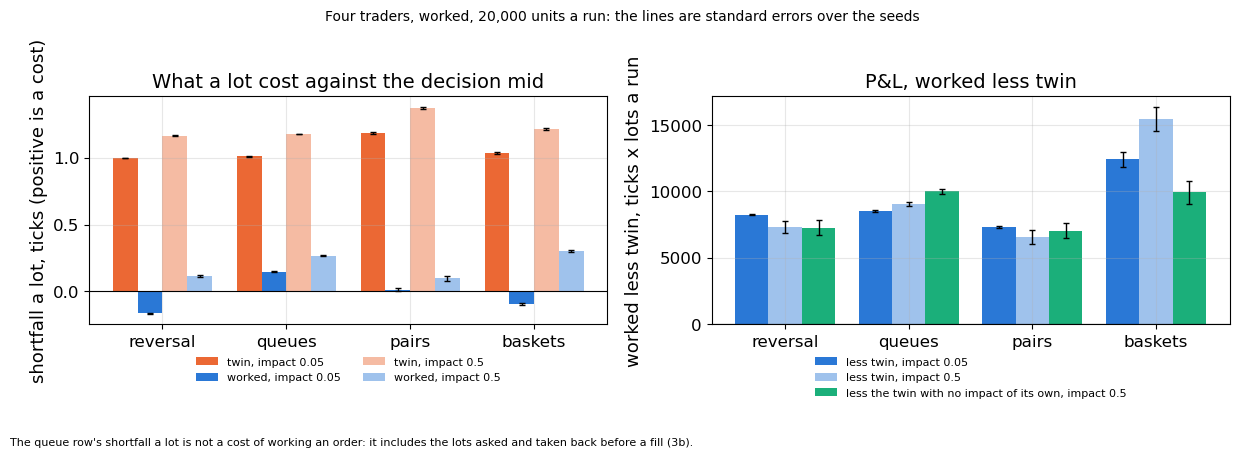

In [19]:
# 3a. The figure: on the left the shortfall a lot of the twin and of the worked trader at each impact, for each row
# (the bracket is read here); on the right what working the order gained in P&L over the twin, a seed's mean, against
# the plain twin at each impact and against the twin with no impact of its own at the bracket's. One y-axis a panel;
# the bars are the means over the twelve seeds and the lines through them are standard errors over the seeds (the
# left panel's standard errors are those of the shortfall a lot's means, the right's those of the paired
# differences).
def traders_figure():
    fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
    spots = np.arange(len(FULL))
    left = axes[0]
    for k, (how, color, alpha, label) in enumerate(
        [
            ('twin', ORANGE, 1.0, f'twin, impact {IMPACT:g}'),
            ('worked', BLUE, 1.0, f'worked, impact {IMPACT:g}'),
            ('twin, 0.5', ORANGE, 0.45, f'twin, impact {IMPACT_HIGH:g}'),
            ('worked, 0.5', BLUE, 0.45, f'worked, impact {IMPACT_HIGH:g}'),
        ]
    ):
        rows = [traders_row(name, how) for name in FULL]
        left.bar(
            spots + (k - 1.5) * 0.2,
            traders_table.shortfall_a_lot[rows],
            0.2,
            yerr=traders_table.shortfall_a_lot_se[rows],
            color=color,
            alpha=alpha,
            label=label,
            error_kw=dict(lw=1, capsize=2, ecolor='black'),
        )
    left.axhline(0, color='black', lw=0.8)
    left.set_xticks(spots, [TRADERS_LABEL[name] for name in FULL])
    left.set_ylabel('shortfall a lot, ticks (positive is a cost)')
    left.set_title('What a lot cost against the decision mid')
    left.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8, frameon=False)
    right = axes[1]
    for k, (table, color, alpha, label) in enumerate(
        [
            (traders_gain, BLUE, 1.0, f'less twin, impact {IMPACT:g}'),
            (traders_gain_high, BLUE, 0.45, f'less twin, impact {IMPACT_HIGH:g}'),
            (traders_gain_fair, AQUA, 1.0, f'less the twin with no impact of its own, impact {IMPACT_HIGH:g}'),
        ]
    ):
        right.bar(
            spots + (k - 1) * 0.27,
            table.pnl,
            0.27,
            yerr=table.se,
            color=color,
            alpha=alpha,
            label=label,
            error_kw=dict(lw=1, capsize=2, ecolor='black'),
        )
    right.axhline(0, color='black', lw=0.8)
    right.set_xticks(spots, [TRADERS_LABEL[name] for name in FULL])
    right.set_ylabel('worked less twin, ticks x lots a run')
    right.set_title('P&L, worked less twin')
    right.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=1, fontsize=8, frameon=False)
    fig.suptitle(
        f'Four traders, worked, {SPAN:,.0f} units a run: the lines are standard errors over the seeds', fontsize=10
    )
    fig.text(
        0.01,
        0.01,
        "The queue row's shortfall a lot is not a cost of working an order: it includes the lots asked and taken back "
        "before a fill (3b).",
        fontsize=8,
    )
    fig.tight_layout(rect=(0, 0.04, 1, 0.95))
    plt.show()


traders_figure()

**The worked bar is below the twin's on every row at both impacts, and the saving survives the bracket on the shortfall a lot.** On the left, at 0.05 the worked bars are at -0.164 (reversal), +0.146 (queues), +0.011 (pairs) and -0.094 (baskets), against twin bars at +0.995, +1.010, +1.184 and +1.034. At 0.5, the lighter bars, the worked bars are at +0.115, +0.267, +0.097 and +0.305, against +1.165, +1.176, +1.371 and +1.212. The lines on the bars are one standard error over the seeds, and they are short beside the gap on every row (the saving, with its standard error, is in the paired table above).

The worked bar is above 0 for the queue row at 0.05, and for all four rows at 0.5, where a resting order is filled by better informed takers. The queue row's bar is not a cost of working an order, as the note under the figure says, and the pairs bar at 0.05 (+0.011, se 0.011) is not resolved from 0; reversal and baskets are below 0 at 0.05. This is this market's picture, and the bracket moves only the takers' information, so the figure shows the saving surviving a better informed taker and nothing about the other items of the title cell's list.

On the right, the P&L a worked trader gained over its twin, a run, against the plain twin at 0.05 (+8,262, +8,557, +7,332 and +12,411), against the plain twin at 0.5 (+7,352, +9,055, +6,570 and +15,450) and against the twin with no impact of its own at 0.5 (+7,282, +9,998, +7,057 and +9,937), with a line of one standard error of the paired difference. The two bars at 0.5 differ most for baskets, +15,450 against +9,937, and for queues, +9,055 against +9,998; the differences are the twin's own impact, +5,513 (se 773, 12 of 12 seeds) for baskets and -943 (se 168, 0 of 12) for queues in the table above. For reversal (+7,352 and +7,282) and pairs (+6,570 and +7,057) the two bars differ by +70 (se 401) and -487 (se 425), not more than about 1.1 standard errors from 0 (plain ratios). So the P&L gain against the plain twin at 0.5 is not the execution's alone for baskets, and the figure adds nothing to the tables it is drawn from.

### 3b. What the Shortfall Is Made Of

**Of each worked row's shortfall, how much is what working an order cost, how much is the paper's drift on lots asked and taken back before a fill, and how much is open at the end?** A shortfall is the sum of its lots' costs only where every lot asked is got. In general it is the sum of four parts, which the library tells lot by lot, first in first out in each book, when the market keeps its decisions (`shortfall_parts`, and the same sums in the score):

- the lots **got**: asked and then filled (or filled and then asked), each at what its fill cost against the mid at the decision that asked it. This is what working an order cost, a lot that was worked;
- the lots **taken back**: asked, and taken back by a later ask of the other sign before any fill. The trader never had them, so no working order cost anything on them; what the paper made on them while the trader held none is a part of the shortfall (the drift of the mid from the decision that asked them to the decision that took them back, times the sign they had);
- the lots **unasked**: lots the trader traded and traded back with no ask between, a position ahead of the paper's. The library says they are rare, seen only where a band of half a lot makes a trader round up, and none of these four rows has a band; the table prints them so that it is seen;
- the lots **open**: the gap between the paper's position and the trader's, left at the end of the span, at the marks then.

So a shortfall a lot is what working an order cost only where nothing is taken back and nothing is open. **Section 3's rule is that no row's shortfall a lot is read as a cost of working an order without this split next to it, and the queue row's is never quoted alone.** The first cell below prints, for every worked row at both impacts, the lots asked, got, taken back, open and unasked, the share of the lots asked that are got, what a lot of each kind cost (for the lots taken back, the paper's drift on them), and the three parts over the lots asked, which add to the shortfall a lot. It is the queue row this is for. The exploration, on seeds 1 to 8, found the figures of the predictions cell: a shortfall a lot of +0.152 made of -0.081 on the lots got and +0.233 on the lots taken back, with 0.466 of the lots asked got; the cell prints how this run splits it, and that share can pass 1 by a little, because a lot that the paper was ahead of the position by when the span began is in the gap from the start, and counts as got when it fills in the span though its ask was before it; and 3a prints the same split under its tables, so that the queue row's shortfall a lot is never alone. The end of the first cell, added after the second run, on a review of it, prints two things the split does not say: the lots asked are not the lots got and the lots taken back (the paper's turnover counts a lot taken back twice, once for the ask that wanted it and once for the later ask that took it back, so the lots asked are the lots got plus twice the lots taken back plus the lots open), and so the share of the lots taken back with each lot counted once is printed; and what the paper made on the lots got and on the lots taken back, a seed (P&L plus the cost of the lots got is the paper less what it made on the lots taken back, the lots open and the lots unasked).

The second cell splits the lots got by the kind of fill that got them, which the score does not carry (it has only the sums of the parts): a model's market order that hit the resting order, a model's limit order across the quote that hit it, or the trader's own market order after its patience ran out. It is one run of each worked row, on the first seed of `SEEDS`, made apart from the table's (and without the log of the legs): the cell asserts that its parts are the table's for that seed, to rounding, which is also the proof that the log of the legs changes nothing in a run.

In [20]:
# 3b. What the shortfall is made of, for every worked row: the split the library gives when the market keeps its
# decisions (shortfall_parts, first in first out in each book). Of the lots the paper asked, the lots GOT (asked and
# filled) and what each cost against the mid at its decision; the lots TAKEN BACK before any fill, and what the paper
# made on them while the trader had none; the lots still OPEN at the end. A shortfall a lot is what working an order
# cost only where the lots asked are got: the three parts over the lots asked add up to it, which the runs' checks
# assert. Means over the seeds, the cost of a kind of lot over its own lots (each seed's own ratio).
def traders_with_costs_a_lot(frame):
    # The worked runs, with the cost of a lot taken back and of a lot open in each run (nan where there is none).
    worked = frame[frame.worked].copy()
    for kind in ('back', 'open'):
        lots, drift = worked[f'{kind}_lots'], worked[f'{kind}_drift']
        worked[f'{kind}_a_lot'] = np.where(lots > 0, drift / lots.where(lots > 0), np.nan)
    return worked


traders_worked = traders_with_costs_a_lot(traders_frame)
traders_split = table_of(traders_worked, also=['back_a_lot', 'open_a_lot', 'unasked_lots', 'unasked_cost'])
TRADERS_LOTS_OF = ['asked_lots', 'got_lots', 'got_share', 'back_lots', 'open_lots', 'unasked_lots']
TRADERS_COST_OF = ['got_a_lot', 'back_a_lot', 'open_a_lot', 'got_part', 'back_part', 'open_part', 'shortfall_a_lot']
TRADERS_FORMATS = dict(back_a_lot='+.3f', open_a_lot='+.3f', unasked_lots=',.1f', unasked_cost='+,.1f')


def traders_print_split(how, impact):
    rows = [traders_row(name, how) for name in FULL]
    print(f'Worked, impact {impact:g}, {len(SEEDS)} seeds:\n')
    print(shown(traders_split.loc[rows], keep=TRADERS_LOTS_OF, **TRADERS_FORMATS))
    print()
    print(shown(traders_split.loc[rows], keep=TRADERS_COST_OF, **TRADERS_FORMATS))
    print()


traders_print_split('worked', IMPACT)
traders_print_split('worked, 0.5', IMPACT_HIGH)
print(
    'got_share is the lots got over the lots asked; got_a_lot, back_a_lot and open_a_lot are the cost of a lot of each '
    "kind (for the lots taken back, the paper's drift on them); got_part, back_part and open_part are each kind's cost "
    'over the lots ASKED, so that they add to shortfall_a_lot (with the unasked lots, which the library says the '
    'traders '
    'it is built for do not have: they are the lots in unasked_lots).'
)


# Added after the second run, on a review of it (a description, and nothing was chosen from it). Two things the split
# above does not say. First, the lots asked are not the lots got and the lots taken back: the paper's turnover counts a
# lot taken back twice (the ask that wanted it and the later ask that took it back), so that the lots asked are the lots
# got plus twice the lots taken back plus the lots open, and the share of the lots asked that were taken back, each lot
# counted once, is back_lots over got_lots plus back_lots. Second, what the paper made on the lots that went through the
# position and on the lots taken back, a seed: P&L plus the cost of the lots got is the paper less what it made on the
# lots taken back, the lots open and the lots unasked, and the drift on the lots taken back is what the paper made on
# them while the trader held none.
traders_once = traders_worked.assign(
    back_once=lambda d: d.back_lots / (d.got_lots + d.back_lots),
    lots_gap=lambda d: d.asked_lots - (d.got_lots + 2 * d.back_lots + d.open_lots),
    paper_on_got=lambda d: d.pnl + d.got_cost,
    paper_on_back=lambda d: d.back_drift,
    paper_rest=lambda d: d.open_drift + d.unasked_cost,
)
assert (
    gap_of(traders_once.paper, traders_once.paper_on_got + traders_once.paper_on_back + traders_once.paper_rest) < 1e-6
), 'the paper is not what it made on the lots got, the lots taken back and the rest'
traders_once_table = table_of(
    traders_once, also=['back_once', 'lots_gap', 'paper_on_got', 'paper_on_back', 'paper_rest']
)
TRADERS_ONCE_FORMATS = dict(
    back_once='.3f', lots_gap='+,.1f', paper_on_got='+,.0f', paper_on_back='+,.0f', paper_rest='+,.0f'
)


def traders_print_once(how, impact):
    rows = [traders_row(name, how) for name in FULL]
    print(f'Worked, impact {impact:g}, {len(SEEDS)} seeds:\n')
    print(
        shown(
            traders_once_table.loc[rows],
            keep=['asked_lots', 'got_lots', 'back_lots', 'open_lots', 'lots_gap', 'back_once', 'back_once_se'],
            **TRADERS_ONCE_FORMATS,
        )
    )
    print()
    print(
        shown(
            traders_once_table.loc[rows],
            keep=['pnl', 'paper', 'paper_on_got', 'paper_on_got_se', 'paper_on_back', 'paper_on_back_se', 'paper_rest'],
            **TRADERS_ONCE_FORMATS,
        )
    )
    print()


print(
    '\nAdded after the second run, on a review of it: the lots counted once, and what the paper made on the lots got '
    "and on the lots taken back. The paper's turnover (the lots asked) counts a lot taken back twice, once for the ask "
    'that '
    'wanted it and once for the later ask that took it back, so the lots asked are the lots got plus twice the lots '
    'taken back plus the lots open, and lots_gap, the lots asked less that sum, is what the identity leaves (a mean '
    'over the seeds). back_once is the share of the lots taken back with each lot counted once, back_lots over '
    "got_lots plus back_lots (the mean of the seeds' own ratios), which is not the complement of got_share. "
    'paper_on_got is what the paper made on the lots that went through the position (P&L plus the cost of the lots '
    'got), paper_on_back what it made on the lots taken back (their drift) and paper_rest what it made on the lots '
    'open and unasked: the three add to the paper, which the cell asserts. A description: nothing was chosen from it.\n'
)
traders_print_once('worked', IMPACT)
traders_print_once('worked, 0.5', IMPACT_HIGH)

Worked, impact 0.05, 12 seeds:

                 asked_lots got_lots got_share back_lots open_lots unasked_lots
row                                                                            
reversal, worked      6,977    6,755     0.968       111         1          0.0
queues, worked       10,145    4,780     0.471     2,683         1          0.0
pairs, worked         6,051    5,974     0.987        39         2          0.0
baskets, worked      10,645   10,509     0.987        68         2          0.0

                 got_a_lot back_a_lot open_a_lot got_part back_part open_part shortfall_a_lot
row                                                                                          
reversal, worked    -0.206     +2.196     +1.312   -0.200    +0.035    +0.000          -0.164
queues, worked      -0.185     +0.881     +0.000   -0.087    +0.233    +0.000          +0.146
pairs, worked       -0.034     +6.987     +0.698   -0.033    +0.044    +0.000          +0.011
baskets, worked  

**The slow rows get nearly all of the lots they ask for, and the queue row gets under half.** At the library's impact the share of the lots asked that were got is 0.968 for reversal (6,755 of 6,977, with 111 taken back and 1 open), 0.471 for queues (4,780 of 10,145, with 2,683 taken back and 1 open), 0.987 for pairs (5,974 of 6,051, with 39 taken back and 2 open) and 0.987 for baskets (10,509 of 10,645, with 68 taken back and 2 open). No lot is unasked: the column is 0.0 on every row, as the library says it should be for traders with no band. The prediction for the queue row's share was 0.466 (standard error 0.004, seeds 1 to 8's); the run's is 0.471 (se 0.001, from the conclusions' table), which is z +1.22 from it, within the three combined standard errors, so the prediction held. The lots got and the lots taken back do not add to the lots asked (the lines added after the second run, below, say why).

**The queue row's shortfall a lot is positive because of the lots taken back, and the lots it did get cost less than crossing.** A lot of the queue row's that was got cost -0.185 against its decision mid, a gain, where crossing it cost +1.010 (3a); a lot taken back drifted +0.881, which is the paper's drift on it and no order's cost. Over the lots asked, the got part is -0.087 and the taken-back part +0.233, and with an open part of +0.000 they add to the shortfall a lot of +0.146 (the cell asserts the sum). The predictions were -0.081 (se 0.006) and +0.233 (se 0.004); the run's are -0.087 (se 0.004) and +0.233 (se 0.001), at z -0.89 and -0.02, and both held. So the paper made money on lots that the trader did not get, and on the lots it did get a resting order cost less than the crossed spread, in this market, which the title cell's list describes as kind to a resting order. The figure is not what working an order costs.

**For the other three rows the parts tell different stories: reversal at 0.05 and baskets at both impacts are mostly the lots got, and pairs at 0.05 and reversal at 0.5 are not.** At 0.05 reversal's got part is -0.200 against a taken-back part of +0.035, and baskets' is -0.110 against +0.016, so their shortfall a lot of -0.164 and -0.094 is mostly the lots got. Pairs' got part is -0.033 and its taken-back part +0.044, parts of the same size and opposite signs, so its shortfall a lot of +0.011 is their small difference and is not mostly the lots got. At 0.5 baskets' got part is +0.264 against +0.041, mostly the lots got (+0.305 in all); reversal's is +0.051 against +0.065, a taken-back part larger than the got part (+0.115 in all); pairs' is +0.055 against +0.041, close, with the got part the larger by a little (+0.097 in all). A lot taken back is rare on the slow rows (111, 39 and 68 lots a seed at 0.05, against 2,683 for the queue row) and the paper's drift on one is large (+2.196, +6.987 and +2.475 a lot), and the open part is +0.000 on every row at both impacts.

**At 0.5 the lots got cost more, the share got moves little, and the queue row's split has the same shape.** A lot got cost +0.052 for reversal (from -0.206 at 0.05), +0.056 for pairs (from -0.034) and +0.267 for baskets (from -0.112), and for queues -0.181 (from -0.185): the better informed takers raise the cost of the lots got on three rows and not on the queue row. The share got is 0.973, 0.502, 0.993 and 0.988 (from 0.968, 0.471, 0.987 and 0.987). The queue row at 0.5 got 5,310 of 10,580 lots asked, with 2,635 taken back and 1 open: a got part of -0.091 and a taken-back part of +0.357, which add to its shortfall a lot of +0.267. The shape is the same as at 0.05, a got part near -0.09 and a taken-back part that is the larger term, and a lot taken back drifted +1.435 against +0.881 at 0.05 while about as many were taken back. The queue row's worked P&L at 0.5 was predicted at about -5,100 (twice the exploration's, an extrapolation); the run's is -4,944 (se 138, 0 of 12 seeds positive), z +1.13 from it, and the prediction held.

Added after the second run, on a review of it (a description, and nothing was chosen from it), the lines under the split print what the split does not say. **The share of the lots asked that were not got is not the share taken back.** The paper's turnover counts a lot taken back twice, once for the ask that wanted it and once for the later ask that took it back, so the lots asked are the lots got plus twice the lots taken back plus the lots open: for the queue row at 0.05, 10,145 asked against 4,780 got, 2,683 taken back and 1 open, and `lots_gap`, what the identity leaves, is -1.2 lots a seed (on the other rows -1.7, -1.6 and -2.8). Counting each lot once, `back_once` is the share of the lots got or taken back that were taken back: 0.359 (se 0.001) for the queue row at 0.05 and 0.332 (se 0.002) at 0.5, where the share got is 0.471 and 0.502. The complement of the share got, 1 less 0.471, is 0.529, and it is not the 0.359 taken back: a lot taken back is two asks, so the lots asked count each lot taken back twice. For the slow rows `back_once` is 0.016 (se 0.001), 0.006 (se 0.000) and 0.006 (se 0.000) for reversal, pairs and baskets at 0.05, and 0.014 (se 0.001), 0.004 (se 0.000) and 0.006 (se 0.000) at 0.5.

**The queue row's paper is made on the lots it never held.** What the paper made on the lots that went through the position and on the lots taken back, a seed, for the queue row at 0.05: -1,150 (se 68) on the lots got and +2,363 (se 11) on the lots taken back, with +0 on the rest, which add to its paper of +1,213. Its P&L of -266 is the first less what the lots got cost, which is -884 (a gain of 884, the plain difference of -1,150 and -266): the resting orders earned 884 on the lots got, and that did not cover the 1,150 the paper lost on them. At 0.5 it is -5,903 (se 132) on the lots got and +3,780 (se 29) on the lots taken back, which add to its paper of -2,123. The three slow rows are the other way, nearly all of the paper made on the lots got: reversal +11,233 (se 89) against +245 (se 12), pairs +14,939 (se 108) against +269 (se 21) and baskets +17,902 (se 515) against +170 (se 12) at 0.05, and +29,099 (se 359) against +444 (se 15), +34,156 (se 454) against +222 (se 19) and +48,181 (se 1,126) against +422 (se 30) at 0.5. That the queue row's paper loses on the lots it holds and gains on the lots it never held is a description of the split. The part below sets it against a row with the queue row's rule and its scores given to the books at random, whose needs are not the queue row's (it asks for fewer lots): a description of one such row, and not a test of how much of it is the signal's.

In [21]:
# 3b. The lots got, by the kind of fill that got them, on the first seed of SEEDS (CARD_SEED): the score has only the
# sums of the parts, and the library's split lot by lot (shortfall_parts) tells a lot got by a model's market order
# apart from one a model's limit order across the quote got and one the trader's own market order got after its
# patience. These are one run of each worked row at the library's impact, made as run_one makes it; the cell asserts
# that the parts are the table's for this seed to rounding, which is also the proof that the log of the legs (the
# relation rows) leaves a run as it is.
def traders_fill_row(result):
    # One run of parts_by_fill as a line: the lots got by each kind of fill and what a lot of each cost. It
    # asserts that the run's parts are the table's for the same row and seed, to rounding, and that its lots by
    # kind add up.
    mine = traders_frame[(traders_frame.row == result['row']) & (traders_frame.seed == CARD_SEED)].iloc[0]
    for key in (
        'got_lots',
        'back_lots',
        'unasked_lots',
        'open_lots',
        'got_cost',
        'back_drift',
        'unasked_cost',
        'open_drift',
    ):
        assert abs(result[key] - mine[key]) < 1e-6, (
            f"{result['row']}: {key} is {result[key]} here and {mine[key]} in the table"
        )
    assert abs(result['shortfall'] - mine.shortfall) < 1e-6, f"{result['row']}: the shortfall is not the table's"
    assert abs(result['residual']) < 1e-6 * (1 + abs(result['shortfall'])), f"{result['row']}: the parts do not add up"
    line = {}
    for label, kinds in (('market', ('market',)), ('limit', ('limit',)), ('crossed', ('cross', 'urgent'))):
        lots = sum(result['lots_by_fill'][k] for k in kinds)
        cost = math.fsum(result['cost_by_fill'][k] for k in kinds)
        line[f'lots, {label}'] = lots
        line[f'a lot, {label}'] = cost / lots if lots else math.nan
    assert sum(v for k, v in line.items() if k.startswith('lots')) == result['got_lots'], 'the lots got are not by kind'
    got_a_lot = result['got_cost'] / result['got_lots'] if result['got_lots'] else math.nan
    return {**line, 'got_lots': result['got_lots'], 'got_a_lot': got_a_lot}


traders_fill_runs = Parallel(n_jobs=-1)(delayed(parts_by_fill)(name, CARD_SEED) for name in FULL)
traders_fill_rows = {result['row']: traders_fill_row(result) for result in traders_fill_runs}
traders_fill = pd.DataFrame(traders_fill_rows).T
print(
    f'The lots got by the kind of fill that got them, worked, impact {IMPACT:g}, seed {CARD_SEED} only: lots, and '
    f'what a lot '
    f"cost against the mid at its decision (a model's market order hit the resting order, a model's limit order across "
    f"the quote hit it, or the trader's own market order crossed what was left after its patience):\n"
)
print(
    traders_fill.to_string(
        formatters={
            **{c: '{:,.0f}'.format for c in traders_fill if c.startswith('lots') or c == 'got_lots'},
            **{c: '{:+.3f}'.format for c in traders_fill if c.startswith('a lot') or c == 'got_a_lot'},
        }
    )
)
print(
    '\nThe parts of these four runs are the table\'s for this seed, to rounding (asserted): the same runs, made apart '
    'from '
    'the table\'s.'
)

The lots got by the kind of fill that got them, worked, impact 0.05, seed 101 only: lots, and what a lot cost against the mid at its decision (a model's market order hit the resting order, a model's limit order across the quote hit it, or the trader's own market order crossed what was left after its patience):

                 lots, market a lot, market lots, limit a lot, limit lots, crossed a lot, crossed got_lots got_a_lot
reversal, worked        4,710        +0.001       2,052       -0.786            12         +6.625    6,774    -0.225
queues, worked          3,228        +0.190       1,669       -0.768             6         +4.333    4,903    -0.131
pairs, worked           4,203        +0.265       2,028       -0.660            19         +7.000    6,250    -0.015
baskets, worked         7,624        +0.113       3,341       -0.800           198         +3.045   11,163    -0.108

The parts of these four runs are the table's for this seed, to rounding (asserted): the same runs, ma

**About two thirds of the lots got were hit by a model's market order and about a third by a model's limit order across the quote, and the few lots crossed after the patience ran out cost the most a lot.** This is one run of each worked row, on the first seed of `SEEDS` (101), and one run is one run: its figures are not carried past it, and the table's twelve-seed figures above are the ones to quote. Of the lots got, reversal had 4,710 hit by a model's market order, 2,052 by a model's limit order across the quote and 12 crossed, of 6,774; queues 3,228, 1,669 and 6, of 4,903; pairs 4,203, 2,028 and 19, of 6,250; baskets 7,624, 3,341 and 198, of 11,163. The market-hit share is 0.70, 0.66, 0.67 and 0.68 (plain ratios of the printed lots), so about two thirds of each row's got lots rested and were hit by a model's market order, about a third rested and were hit by a model's limit order across the quote, and under 2% were crossed by the trader's own market order.

A lot hit by a model's market order cost +0.001 (reversal), +0.190 (queues), +0.265 (pairs) and +0.113 (baskets) against its decision mid. A lot hit by a model's limit order across the quote cost -0.786, -0.768, -0.660 and -0.800, a gain of most of a tick, which is the lots that earned most against the decision mid; what such lots were worth afterwards is section 1b's markouts, and this table has none. A lot crossed after the patience ran out cost +6.625, +4.333, +7.000 and +3.045. So a crossed lot cost more a lot than any lot that rested, and more than a tick, which is what crossing at the decision cost the twins (+0.995 to +1.184 over twelve seeds, set beside one seed here): the price had moved against it during the wait. The crossed lots are 12, 6, 19 and 198 lots, 0.2%, 0.1%, 0.3% and 1.8% of the lots got on the four rows (plain ratios); the got cost a lot, over all the lots got, is -0.225, -0.131, -0.015 and -0.108. How much of a row's got cost the crossed lots are is not printed, and is not stated here; it is on pairs and baskets, whose got cost a lot is smallest in size (-0.015 and -0.108) and whose crossed lots cost +7.000 and +3.045 a lot, that it would show. The parts of these four runs are the table's for this seed, to rounding, which the cell asserts. These are this market's figures at 0.05: the title cell's list says what a resting order is given here, and the bracket is not run for this cell.

#### 3b, Added After the Second Run: The Queue Row With Its Scores Given to the Books at Random

This part was added after the second run, on a review of it: it is a description and not a test, and nothing was chosen from it.

**How much of what 3b found for the queue row is the signal's, and how much is what any resting order gets on needs that vanish?** 3b split the queue row's shortfall into the lots got and the lots taken back, and found that the paper made money on the lots taken back, which no order cost. The explanation the section's opening gave from the exploration, that a resting order of this row is filled on the lots the signal is wrong about and left behind on the lots it is right about, does not follow from 3b's figures alone. **A resting order on needs that appear and vanish before they fill can have the paper's gain on the lots it takes back and lose on the lots it gets, whatever the signal says**: an order is filled when the price comes to it, which is when the price is moving against the position it would take, and a need is taken back when the price has gone away from the order and the need has gone with it, which is when the paper has made money on a position the trader never held. The review of the second run asked for a row that shows how much of the queue row's split a resting order on such needs has by itself, and this part runs one, so the claim is shown for one row and no more.

**The row.** The queue row (`QUEUES`: flow of queues, a rate of 0.02, every unit) with each decision's queue scores given to the books at random. At each decision the library's own scores (the lots at the best bid less those at the best ask, over their sum, 0 where a side is empty) are the same twelve numbers, in a permutation drawn from a stream of its own, `default_rng([seed, 4242])`, one permutation a decision. Everything after the scores is the queue row's: the neutralizing of the factors, the size of the target, the rate, the interval. So its needs come from the queue row's rule with no signal in them: a book's score says nothing of that book. They are not the queue row's needs: no cell prints their size or how long they live, and the run shows that this row asks for fewer lots. The stream is its own, so that it draws nothing the market or any other trader draws, and it is the same under every execution. The cell asserts that the trader's settings are the queue row's.

**What is run.** The row worked (`WORKED`, with the market keeping its decisions, so that the score has the split of the shortfall) and as its twin (market orders, no execution), at the library's impact of 0.05, on `SEEDS`, at section 3's burn and span (`BURN`, `SPAN`): 24 runs. The queue row's own runs, worked and as a twin, are section 3's (`traders_frame`) and are read, not run again; the two rows are on the same seeds, burn, span and impact, and every difference between them is taken seed by seed. Two cells follow: the runs with their checks (the checks of every run of this section, and that the parts of the shortfall add up to it), then the table and the pairing.

**What is printed.** For the queue row and the random-score row, worked and as a twin: P&L (with its standard error and the seeds on which it is positive), paper, shortfall and shortfall a lot. For the two worked rows the split of 3b: the lots asked, got, taken back and open, the share of the lots asked that were got and the share taken back counting each lot once, what a lot got cost, what the paper made on a lot taken back, and the three parts over the lots asked. Then the queue row less the random-score row, worked, paired by seed: P&L, paper, a lot taken back's drift, a lot got's cost, and, per lot asked, the shortfall a lot and the two parts of it that make the gap (the taken-back part and the got part). And the random-score row worked less its twin: what working an order saves a trader that has no signal.

**What was done beforehand.** The premise review of the second run designed this row and ran it on seeds 1 to 8 before this run. No cell prints its figures, so they are not quoted here, and **no prediction of this part is made or judged**: the predictions cell cannot change and has no row for this part, the conclusions' count of predictions does not include it, and the figures of the run are read as they are printed.

**What this is not.** It is not a test of why the queue row loses, and it does not say what the queue signal is worth: it sets the queue row against one row with the queue row's rule and no signal, whose needs are not the queue row's, in one market, over twelve seeds. A resting order's paper gain on the lots taken back and its loss on the lots got are properties of the order and the market, and the part measures how much of the queue row's split the random-score row shows by itself. The random-score row asks for a different number of lots than the queue row (its needs come from the queue row's rule and are not the queue row's needs, whose sizes and lives no cell prints for either row), so the comparison is per lot asked and per lot of each kind, and the printed lots say how far apart the two rows' lots are.

In [22]:
# 3b, added after the second run, on a review of it (a description and not a test; nothing was chosen from it): the
# queue row with each decision's queue scores given to the books at random, worked and as a twin, at the library's
# impact, on SEEDS, at section 3's burn and span. The queue row's own runs, worked and as a twin, are section 3's
# (traders_frame) and are read, not run again. The trader is the queue row's (CATALOG[QUEUES]) with its scores shuffled
# across the twelve books by a stream of its own: its needs are the queue row's size and come and go as its needs do,
# and no book's score says anything of that book.
RANDOM_STREAM = 4242  # the stream's second seed: [seed, RANDOM_STREAM]. The stream is its own and the same under every
# execution, so a worked run and its twin draw the same sequence of permutations.
RANDOM_WORKED, RANDOM_TWIN = 'random scores, worked', 'random scores, twin'


@dataclass
class RandomQueues(FlowTrader):
    # The queue row with its signal taken out and its needs kept. At each decision FlowTrader's own queue scores (the
    # lots at the best bid less those at the best ask, over their sum, 0 where a side is empty) are given to the twelve
    # books at random: a permutation of the same twelve numbers, drawn from a stream seeded by the seed and
    # RANDOM_STREAM. Everything after the scores is the queue row's: the neutralizing, the size of the target, the rate,
    # the interval. So the scores have the spread the queue scores have and carry no information about a book.
    seed: Optional[int] = None  # always given: attach refuses a seed that is not the notebook's (check_seed)

    def attach(self, n):
        super().attach(n)
        check_seed(self.seed)
        self._noise = np.random.default_rng([self.seed, RANDOM_STREAM])

    def scores(self):
        return self._noise.permutation(super().scores())


def make_random_queues(seed, burn):
    # The queue row of CATALOG, a rate of 0.02 deciding every unit, with its scores given to the books at random.
    check_seed(seed)
    return RandomQueues(
        size=5.0, factors=FACTORS, lookback=1, hold=1, rate=0.02, interval=1.0, measure='queues', seed=seed
    )


RANDOM_ROW = Row(make_random_queues, BURN, SPAN)  # the queue row's burn and span: the two are paired by seed
random_made, queue_made = RANDOM_ROW.make(SEEDS[0], BURN), CATALOG[QUEUES]()
assert all(
    getattr(random_made, name) == getattr(queue_made, name)
    for name in (
        'size',
        'interval',
        'rate',
        'band',
        'lookback',
        'hold',
        'factors',
        'pca_window',
        'pca_every',
        'measure',
    )
), 'the random-score trader is not the queue row with its scores given to the books at random'
assert (RANDOM_ROW.burn, RANDOM_ROW.span) == (BURN, SPAN), "not the queue row's burn and span"

random_cases = {RANDOM_WORKED: Case(RANDOM_ROW, WORKED, keep=True), RANDOM_TWIN: Case(RANDOM_ROW)}
random_frame = run_rows(random_cases, SEEDS)

# The checks the section's runs have (check_frame: every row on every seed once, lots passive plus crossed, P&L paper
# less shortfall, a twin that placed no resting order with its lots its lots asked, its shortfall its costs and its
# paper its before costs, a worked trader with no before costs), and that the parts of the shortfall add up to it.
random_gaps = check_frame(random_frame, 'the random-score row')
assert sorted(random_frame.row.unique()) == sorted(random_cases), 'the frame has not the two rows'
assert (random_frame.burn == BURN).all() and (random_frame.span == SPAN).all(), "not the queue row's burn and span"
assert (random_frame.impact == IMPACT).all(), f'not at an impact of {IMPACT:g}'
random_on = random_frame[random_frame.worked]
random_parts = random_on.got_cost + random_on.back_drift + random_on.unasked_cost + random_on.open_drift
assert gap_of(random_parts, random_on.shortfall) < 1e-6, 'the parts do not add up to the shortfall'
print(
    f'Checked: {len(random_frame)} runs, {len(random_cases)} rows on the {len(SEEDS)} seeds once, at burn {BURN:,.0f} '
    f'and span {SPAN:,.0f} (the queue row\'s), at impact {IMPACT:g}; the trader is the queue row\'s with its scores '
    'given to the books at random; no twin placed a resting order; largest gaps, '
    + ', '.join(f'{what} {gap:.1e}' for what, gap in random_gaps.items())
    + ', worked: parts less the shortfall '
    + f'{gap_of(random_parts, random_on.shortfall):.1e}.'
)
ran(random_frame, label='This cell: ')

Checked: 24 runs, 2 rows on the 12 seeds once, at burn 10,465 and span 20,000 (the queue row's), at impact 0.05; the trader is the queue row's with its scores given to the books at random; no twin placed a resting order; largest gaps, twin: lots less lots asked 0.0e+00, lots less passive and crossed lots 0.0e+00, passive lots less those hit by a market and a limit order 0.0e+00, P&L less paper less shortfall 0.0e+00, twin: shortfall less costs 0.0e+00, twin: paper less before costs 0.0e+00, worked: parts less the shortfall 0.0e+00.
This cell: 24 runs, 24.1 core-minutes.


In [23]:
# 3b, added after the second run, on a review of it (a description and not a test; nothing was chosen from it): the
# queue row and the queue row with its scores given to the books at random, worked and as a twin, in one table, with the
# split of the shortfall of 3b for the worked rows; then the two worked rows paired by seed. The queue row's rows are
# section 3's (traders_frame, the same seeds, burn, span and impact), the random-score rows are the cell above's.
random_both = pd.concat(
    [
        traders_frame[traders_frame.row.isin([traders_row(QUEUES, 'worked'), traders_row(QUEUES, 'twin')])],
        random_frame,
    ],
    ignore_index=True,
)
RANDOM_ROWS = [traders_row(QUEUES, 'twin'), traders_row(QUEUES, 'worked'), RANDOM_TWIN, RANDOM_WORKED]
assert sorted(random_both.row.unique()) == sorted(RANDOM_ROWS), 'the frame has not the four rows'
assert (random_both.burn == BURN).all() and (random_both.span == SPAN).all(), 'the rows are not on one burn and span'
random_worked = traders_with_costs_a_lot(random_both).assign(
    back_once=lambda d: d.back_lots / (d.got_lots + d.back_lots)
)
random_table = table_of(random_both).loc[RANDOM_ROWS]
random_split = table_of(random_worked, also=['back_a_lot', 'open_a_lot', 'back_once']).loc[RANDOM_ROWS[1::2]]
RANDOM_FORMATS = dict(back_a_lot='+.3f', open_a_lot='+.3f', back_once='.3f')

print(
    f'The queue row and the queue row with its scores given to the books at random, at the library\'s impact '
    f'({IMPACT:g}), {len(SEEDS)} seeds, burn {BURN:,.0f}, span {SPAN:,.0f}: P&L, paper and shortfall in ticks x lots, '
    'and the shortfall a lot (which for the queue row is not the cost of working an order: 3b):\n'
)
print(
    shown(
        random_table,
        keep=['pnl', 'se', 'positive', 'paper', 'shortfall', 'shortfall_a_lot', 'shortfall_a_lot_se', 'asked_lots'],
    )
)
print(
    "\nThe same split of the worked rows' shortfall as 3b's: of the lots asked, the share got, the share taken back "
    'counting each lot once, what a lot got cost and what the paper made on a lot taken back, and the three parts over '
    'the lots asked, which add to the shortfall a lot:\n'
)
print(
    shown(
        random_split,
        keep=['asked_lots', 'got_lots', 'got_share', 'back_lots', 'back_once', 'open_lots'],
        **RANDOM_FORMATS,
    )
)
print()
print(
    shown(
        random_split,
        keep=['got_a_lot', 'back_a_lot', 'got_part', 'back_part', 'open_part', 'shortfall_a_lot'],
        **RANDOM_FORMATS,
    )
)


def random_said(label, one, other, column, digits):
    # One line: `one` less `other`, seed by seed, in the format of every paired difference of this notebook.
    print(f'  {label:<44}{said(paired(random_worked, one, other, column), digits)}')


queue_worked = traders_row(QUEUES, 'worked')
print(
    '\nThe queue row less the queue row with random scores, worked, paired by seed: P&L and paper in ticks x lots; '
    'what '
    'a lot taken back drifted by and what a lot got cost, each over its own lots; and, over the lots asked, the '
    'shortfall a lot and the two parts of it that make the gap (a part is a kind of lot\'s cost over all the lots '
    'asked, so that the two parts and the open part add to the shortfall a lot):\n'
)
for label, column, digits in (
    ('P&L', 'pnl', 0),
    ('paper', 'paper', 0),
    ("a lot taken back's drift", 'back_a_lot', 3),
    ("a lot got's cost", 'got_a_lot', 3),
    ('share of the lots asked that were got', 'got_share', 3),
    ('share taken back, each lot counted once', 'back_once', 3),
    ('shortfall a lot', 'shortfall_a_lot', 3),
    ('  the taken-back part, over the lots asked', 'back_part', 3),
    ('  the got part, over the lots asked', 'got_part', 3),
    ('  the open part, over the lots asked', 'open_part', 3),
):
    random_said(label, queue_worked, RANDOM_WORKED, column, digits)
random_gap = {
    column: paired(random_worked, queue_worked, RANDOM_WORKED, column)
    for column in (
        'pnl',
        'paper',
        'back_a_lot',
        'got_a_lot',
        'got_share',
        'back_once',
        'shortfall_a_lot',
        'back_part',
        'got_part',
        'open_part',
    )
}
print(
    "\nThe random-score row, worked less its twin, paired by seed (the saving of working an order that has no signal): "
    'P&L, paper, shortfall in ticks x lots and the shortfall a lot:\n'
)
random_saving = {}
for label, column, digits in (
    ('P&L', 'pnl', 0),
    ('paper', 'paper', 0),
    ('shortfall', 'shortfall', 0),
    ('shortfall a lot', 'shortfall_a_lot', 3),
):
    random_saving[column] = paired(random_both, RANDOM_WORKED, RANDOM_TWIN, column)
    print(f'  {label:<44}{said(random_saving[column], digits)}')
print(
    "\nA description of one row against the queue row on the same seeds, and not a test: no prediction was written for "
    'it, and the conclusions\' count of predictions does not include it.'
)

The queue row and the queue row with its scores given to the books at random, at the library's impact (0.05), 12 seeds, burn 10,465, span 20,000: P&L, paper and shortfall in ticks x lots, and the shortfall a lot (which for the queue row is not the cost of working an order: 3b):

                         pnl se  positive  paper shortfall shortfall_a_lot shortfall_a_lot_se asked_lots
row                                                                                                     
queues, twin          -8,823 68   0 of 12 +1,596   +10,418          +1.010              0.002     10,313
queues, worked          -266 55   2 of 12 +1,213    +1,478          +0.146              0.004     10,145
random scores, twin   -5,716 70   0 of 12   +129    +5,845          +1.008              0.002      5,796
random scores, worked   +449 48  12 of 12    +50      -399          -0.069              0.003      5,833

The same split of the worked rows' shortfall as 3b's: of the lots asked, the share got, t

As the head of this part says, it was added after the second run, on a review of it: it is a description and not a test, and nothing was chosen from it. Its figures are this run's, on twelve seeds and 20,000 units; the premise review's own figures for this row are printed by no cell and are not quoted.

**The row with no signal makes money worked, and the queue row does not.** At the library's impact, as a twin, the queue row makes -8,823 (standard error 68, 0 of 12 seeds positive) and the row with random scores -5,716 (se 70, 0 of 12); worked, the queue row makes -266 (se 55, 2 of 12) and the row with random scores +449 (se 48, 12 of 12). The paper of a row with no signal is small: +129 as a twin and +50 worked (the paired difference, below, is -79 (se 54), within 1.5 standard errors of 0), against the queue row's +1,596 as a twin and +1,213 worked. The shortfall is +5,845 as a twin and -399 worked, which as a shortfall a lot is +1.008 (se 0.002) and -0.069 (se 0.003); the queue row's are +10,418 and +1,478, or +1.010 (se 0.002) and +0.146 (se 0.004). The two rows ask for different numbers of lots, 5,796 as a twin and 5,833 worked for the row with random scores and 10,313 and 10,145 for the queue row, so the comparison below is per lot, and neither row's lots are the other's lots: the row with random scores asks for 0.575 as many lots as the queue row (5,833 against 10,145, a plain ratio), so its needs are not the queue row's.

**The row with no signal has the queue row's shape: the paper made money on the lots it took back, and the lots it got cost less than crossing.** The queue row asked for 10,145 lots, got 4,780 (0.471 of the lots asked) and took back 2,683, 0.359 of the lots got or taken back with each lot counted once; a lot it got cost -0.185 and the paper made +0.881 on a lot it took back. The row with random scores asked for 5,833, got 2,483 (0.426) and took back 1,675 (0.403 counted once); a lot it got cost -0.427 and the paper made +0.395 on a lot it took back. Over the lots asked, the queue row's got part is -0.087 and its taken-back part +0.233, adding to +0.146; the row with random scores' are -0.182 and +0.113, adding to -0.069. Both rows have the two signs of 3b's split, so a row with no signal has them, which this part shows for one such row. Their sizes differ between the rows, and this part does not separate the signal from the needs, which are not the same.

**The queue row's lots taken back drifted more and its lots got cost more, each for about half the gap in shortfall a lot asked.** The queue row less the row with random scores, worked, paired by seed: a lot taken back drifted +0.486 more (se 0.007, 12 of 12 seeds positive) and a lot got cost +0.242 more (se 0.008, 12 of 12); the share of the lots asked that were got is +0.045 higher (se 0.003) and the share taken back, each lot counted once, -0.043 lower (se 0.003). Over the lots asked the shortfall a lot is +0.214 higher (se 0.004, 12 of 12), of which +0.119 (se 0.002) is the taken-back part and +0.095 (se 0.004) the got part: about 56% and 44% (plain ratios of the two printed parts to their sum), close to half each, and the open part is -0.000. The paper is +1,163 higher (se 78, 12 of 12) and the P&L -715 lower (se 71, 0 of 12): the queue row's signal has a paper, and its shortfall is 1,877 higher than the signal-free row's (the plain difference of 1,478 and -399, on 10,145 lots asked against 5,833), more than the paper gains. About 1,700 of that is the paper's gain on lots taken back, which no order cost (the 2,363 that 3b prints for the queue row less about 659 for the row with random scores, 0.113 a lot asked over 5,833 lots: plain products of printed figures). The queue row's lots taken back drifting +0.486 more is consistent with its signal being right about those lots, and also with its needs being larger or living longer than the signal-free row's, which no cell separates.

**The two halves answer different questions, and the printed parts do not say that the lots its signal is right about are missed.** A lot taken back adds the same to the paper and to the shortfall, so it is not in the P&L (3b: the P&L is what the paper made on the lots got, less what they cost). The queue row's lots taken back drifting +0.486 a lot more is why its paper, which made +2,363 on lots it never held (and -1,150 on the lots got, 3b), does not reach its P&L: that is the taken-back half. What puts its P&L below the signal-free row's, and below 0, is the lots got. The paper lost about the same on a lot got in the two rows: -1,150 over 4,780 lots for the queue row (3b), and about -611 over 2,483 for the row with random scores (its P&L of +449 plus the cost of its lots got, 2,483 lots at -0.427 or about -1,060, plain arithmetic of printed means), which is -0.241 and -0.246 a lot (plain ratios, not paired). So the P&L a lot got is -0.056 for the queue row and +0.181 for the row with random scores (plain ratios of printed figures), and that gap is about the +0.242 (se 0.008) by which the queue row's lots got cost more. The half-and-half split of the shortfall a lot, +0.119 and +0.095, is of the shortfall and not of the loss. That its resting orders miss the lots its signal is right about is not shown: the +0.486 fits it, and fits as well needs that are larger or last longer. This is a comparison with one row in one market, whose lots are not the queue row's lots, and it does not say what the queue signal is worth or why its lots got cost more.

**Working an order saves a trader with no signal 1.077 a lot, in this market, and its paper hardly moves.** The row with random scores worked less its twin, paired by seed: P&L +6,165 (se 76, 12 of 12 seeds positive), paper -79 (se 54, 3 of 12), shortfall -6,244 (se 63, 0 of 12) and shortfall a lot -1.077 (se 0.005, 0 of 12). The paper of a row with no signal should not move, and it does not by much: -79 is within 1.5 standard errors of 0 (a plain ratio). This is this market's saving, in a market built to be kind to a resting order (the title cell's list), and this part has no bracket: its 24 runs are at the library's impact, so nothing here says what better informed takers do to it, and a bracket would move only that item of the list.

### 3c. The Legs

**What does a worked pair or basket hold while its legs fill one at a time, for how long, and does it carry more of the factors than its twin for the same lots?** A pair's order is a lot in each of two books, and a basket's is a lot in each of four. A crossing trader fills every leg in the step of its decision. A worked trader fills them one at a time, as each resting order is hit, and **the library works every leg and never hedges a leg that has filled**: for a while one leg's lots are in and another's are not, and the trader holds a position that no relation asked for. The shortfall puts a price on it as the drift of the mids while the order waits, and says nothing of the risk of holding half a pair.

The log that the relation rows keep (at each decision from 600 units before the span: the states of their relations after deciding, the position they held before and the paper's position before) is read by `leg_orders`. An *order* is a decision at or after the span's start at which a relation changed state; its *legs* are the books where the paper's position changed at that decision and where the trader still needs lots. An order is followed until every leg has its lots (it is *done*), or until a later decision takes the lots of a leg back (it is *censored*, counted and not averaged). A leg's progress is its lots filled over its need. For each order that is done the log gives the time from its decision to the last leg done (`leg_to_done`); the time some leg is further along than the least (`leg_unbalanced`, the time the legs are not even); the time from the first leg done to the last (`leg_ahead`); and the lots held ahead of the slowest leg, summed over the legs and integrated over time (`leg_lot_units`, lot-units an order: for two legs of equal lots it is the lots one leg is ahead, times how long). A *hold* is a relation's state that is not 0, from the decision it enters to the decision it leaves, for every hold that ended in the log. The time legs are unbalanced is set against it.

Two things the trace is not. For the rate 0.25 basket an order is the first slice of a need that goes on, and the trace follows that slice. And some orders change more than one relation at once (the books overlap, and one order nets them), so "a pair's legs" are a decision's legs; `leg_multi_share` prints how often. No prediction of the predictions cell is a figure of the legs, so nothing in 3c is checked against one; the exploration read the same trace on seeds 1 to 4, and the conclusions may set its figures beside the run's, labeled as those of seeds 1 to 4.

The factor exposure of the worked trader against its twin's at the same gross is the second cell: `gross` is the lots held across the books and `exposure` the root mean square of what the trader holds of the factors (through the market's own factor exposures), so a trader that holds the legs it has filled and not the relation they make holds more of the factors for the same lots. The cell prints it paired by seed for all four rows, so that it can be seen whether it is a property of the relations; the legs of the first cell are the relation rows' alone. The end of that cell, added after the second run, on a review of it, prints two more things: what the factors made of the P&L (`factor_part`, worked less twin, paired by seed), and, for the two relation rows, what the paper and the gap between the position and the paper hold of the factors. The worked relation runs sample the position, what the paper asked for and their difference at the times the run's own score takes its exposure (a sampler that reads the market after each step and draws nothing, so that no figure of the run moves), and the cell asserts that the sampled position's exposure and gross are the score's. A description: nothing was chosen from it.

In [24]:
# 3c. The legs. A relation's order is filled leg by leg, so while it works one leg's lots are in and another's are
# not, and the trader holds a position that no relation asked for. For the two relation rows, worked at the library's
# impact, from the log of each run (its fills, the states of its relations and the paper's position at each decision,
# see leg_orders): the time an order takes to be done, the time its legs are not even and the lots held ahead of the
# slowest leg (lot-units: lots a leg is ahead of the least, summed over legs and integrated over time), against how
# long a position is held. A relation's order is a decision at which its state changed; for the rate 0.25 basket it
# is the first slice of an order that goes on.
traders_leg_rows = [traders_row(name, 'worked') for name in TRADERS_RELATIONS]
LEG_COLUMNS = [c for c in traders_new.columns if c.startswith('leg_')]
traders_leg = table_of(traders_new[traders_new.row.isin(traders_leg_rows)], also=LEG_COLUMNS).loc[traders_leg_rows]
LEG_FORMATS = {
    'leg_orders': ',.0f',
    'leg_single': ',.1f',
    'leg_censored': ',.1f',
    'leg_legs': '.2f',
    'leg_lots': '.2f',
    'leg_to_done': '.2f',
    'leg_to_done_p90': '.2f',
    'leg_ahead': '.2f',
    'leg_unbalanced': '.2f',
    'leg_lot_units': '.1f',
    'leg_multi_share': '.3f',
    'leg_holds': ',.0f',
    'leg_hold': '.1f',
    'leg_unbalanced_of_hold': '.3f',
    'leg_to_done_entry': '.2f',
    'leg_to_done_exit': '.2f',
    'leg_union_share': '.3f',
    'leg_lots_ahead': '.2f',
}
print(
    f'Worked, impact {IMPACT:g}, {len(SEEDS)} seeds (a seed is one run; the means are over each run\'s own orders, and '
    f'the standard errors over the seeds):\n'
)
print('How long an order takes, in units of time:\n')
print(
    shown(
        traders_leg,
        keep=[
            'leg_orders',
            'leg_censored',
            'leg_legs',
            'leg_lots',
            'leg_to_done',
            'leg_to_done_se',
            'leg_to_done_p90',
            'leg_unbalanced',
            'leg_unbalanced_se',
            'leg_ahead',
            'leg_lot_units',
            'leg_lot_units_se',
        ],
        **LEG_FORMATS,
    )
)
print('\nAgainst how long a position is held, and how much of the span some order\'s legs are not even:\n')
print(
    shown(
        traders_leg,
        keep=[
            'leg_hold',
            'leg_holds',
            'leg_unbalanced_of_hold',
            'leg_unbalanced_of_hold_se',
            'leg_union_share',
            'leg_union_share_se',
            'leg_lots_ahead',
            'leg_multi_share',
            'leg_to_done_entry',
            'leg_to_done_exit',
        ],
        **LEG_FORMATS,
    )
)
print(
    '\nleg_orders is the orders a run followed to their end a seed, leg_censored the orders a later decision took back '
    'before every leg was done (counted, not averaged), leg_legs and leg_lots the legs and lots of an order; '
    'leg_to_done is from the decision to the last leg done, leg_unbalanced the time some leg is further along than the '
    'least, leg_ahead from the first leg done to the last, and leg_lot_units the lots held ahead of the slowest leg, '
    'integrated over the order. leg_unbalanced_of_hold is the time orders are unbalanced over the time positions are '
    'held (a seed\'s sums), leg_union_share the share of the span in which some order is unbalanced, leg_lots_ahead '
    'the '
    'mean lots held ahead of the slowest leg over the span, and leg_multi_share the share of orders that change more '
    'than one relation at once.'
)
twin_rows = [traders_row(name, 'twin') for name in TRADERS_RELATIONS]
twin_cross = traders_frame[traders_frame.row.isin(twin_rows)]
assert (twin_cross.crossed_share == 1.0).all(), 'a relation twin has lots that were not crossed'
print(
    f'\nThe twin crosses every leg in the step of its decision (crossed_share 1.000 on every run of its '
    f'{len(twin_cross)}), '
    f'so its legs are never in flight: the time to done is 0 by construction, and the trace is not run for it.'
)

Worked, impact 0.05, 12 seeds (a seed is one run; the means are over each run's own orders, and the standard errors over the seeds):

How long an order takes, in units of time:

                leg_orders leg_censored leg_legs leg_lots leg_to_done leg_to_done_se leg_to_done_p90 leg_unbalanced leg_unbalanced_se leg_ahead leg_lot_units leg_lot_units_se
row                                                                                                                                                                           
pairs, worked        1,064         24.6     2.31     5.53        6.69           0.04           12.21           4.98              0.04      4.50          12.7              0.1
baskets, worked        619         19.1     4.52     6.46        7.58           0.08           13.25           6.61              0.10      6.52          25.7              1.0

Against how long a position is held, and how much of the span some order's legs are not even:

                leg_hold l

**A relation's legs are all done about 7 units after its decision, and they are not even for most of that.** The trace followed 1,064 pairs orders a seed to their end (24.6 more were taken back by a later decision before every leg was done, and are counted and not averaged), an order being 2.31 legs and 5.53 lots on average. Its legs were all done after 6.69 units (standard error 0.04, 90th percentile 12.21), and some leg was further along than the least for 4.98 of those units (se 0.04). From the first leg done to the last was 4.50 units, and the lots held ahead of the slowest leg, integrated over the order, were 12.7 lot-units (se 0.1). For the first slice of the four-leg baskets, 619 orders a seed (19.1 censored) of 4.52 legs and 6.46 lots: 7.58 units to done (se 0.08, 90th percentile 13.25), of which 6.61 unbalanced (se 0.10), 6.52 from the first leg done to the last, and 25.7 lot-units (se 1.0). The patience is 20 units, so the legs of a relation are done well inside it, and for two legs and for the first slice of four alike they are uneven for most of the time they take.

**A worked relation's legs are even for most of its hold, and some order's legs are uneven for a fifth to a quarter of the span.** A hold, a relation's state that is not 0, lasted 122.4 units for pairs (684 holds a seed) and 118.9 for baskets (421). Time unbalanced over time held, a seed's sums, is 0.063 (se 0.001) for pairs and 0.082 (se 0.004) for baskets. That is what all the orders of a hold add up to: one order's legs are not even for 4.98 units of a pair's hold of 122.4 and 6.61 of a basket's 118.9 (0.041 and 0.056, plain ratios, about a 25th and an 18th), and a hold has 1.56 and 1.47 orders (plain ratios of 1,064 to 684 and 619 to 421). But orders come often, more of them than holds, so the share of the span in which some order's legs are not even is 0.247 (se 0.002) for pairs and 0.193 (se 0.009) for baskets. The lots held ahead of the slowest leg are 0.67 on average over the span for pairs and 0.81 for baskets, against a gross of 16.7 and 33.2 lots in 3a's table: 0.040 and 0.024 of the gross (plain ratios). The orders changing more than one relation at once are 0.186 of the pairs' and 0.219 of the baskets', so "a pair's legs" are a decision's legs, as the head says. An entry took 6.65 units to done for pairs and 7.67 for baskets, and an exit 6.48 and 7.41. So a worked relation's legs are done within a small part of a hold, and the position that no relation asked for is small in lots, as the lots ahead say. It is a pair only in that sense: what the uneven legs hold of the factors is the next cell's, and it is not small.

**The twin has no legs in flight.** It crosses every leg in the step of its decision (`crossed_share` is 1.000 on every one of its 24 runs), so its time to done is 0 by construction and the trace is not run for it.

In [25]:
# 3c. The factor exposure of the worked trader against its twin's at the same gross: a worked trader holds the legs
# it has filled and not the relation they make, so it holds more of the factors than its twin for the same lots.
# `gross` is the lots held across the books and `exposure` the root mean square of what it holds of the factors;
# their ratio is the exposure a lot held. Paired by seed, worked less twin. The four rows are in the table (the
# relation rows are the point; the other two show whether it is the relations).
traders_exposed = traders_frame.assign(exposure_per_gross=traders_frame.exposure / traders_frame.gross)
TRADERS_EXPOSED = ['gross', 'exposure', 'exposure_per_gross', 'deviation_long']
traders_exposure_table = table_of(traders_exposed, also=['exposure_per_gross']).loc[TRADERS_ROWS]


def traders_exposure(label, one, other, impact):
    # `one` less `other` for each trader, paired by seed: gross, exposure, exposure a lot held and
    # deviation_long, with the standard error and the seeds above 0, and beside them the exposure of `one` over
    # `other` (the mean over seeds).
    table = paired_table(traders_exposed, traders_pairs(one, other), *TRADERS_EXPOSED)
    ratio = {
        TRADERS_LABEL[n]: traders_exposure_table.exposure[traders_row(n, one)]
        / traders_exposure_table.exposure[traders_row(n, other)]
        for n in FULL
    }
    table['exposure_ratio'] = pd.Series(ratio)
    print(f'{label} (impact {impact:g}), {len(SEEDS)} seeds:\n')
    formats = dict(exposure_ratio='.2f', exposure_per_gross='+.4f', gross='+.2f', exposure='+.2f')
    for block in (['gross', 'exposure'], ['exposure_per_gross', 'deviation_long']):
        keep = [x for c in block for x in (c, f'{c}_se', f'{c}_positive')] + (
            ['exposure_ratio'] if 'exposure' in block else []
        )
        print(shown(table, keep=keep, **formats))
        print()
    return table


traders_exposure_low = traders_exposure('Worked less its twin', 'worked', 'twin', IMPACT)
traders_exposure_high = traders_exposure(
    'Worked less the twin with no impact of its own', 'worked, 0.5', 'twin, no own impact, 0.5', IMPACT_HIGH
)
print(
    'exposure_ratio is the worked trader\'s exposure over its twin\'s, the means over seeds; gross is the lots held '
    'across '
    'the books, so a difference of exposure at an equal gross is not a difference of lots, and exposure_per_gross is '
    'the '
    'exposure a lot held.'
)


# Added after the second run, on a review of it (a description, and nothing was chosen from it). First, what the extra
# exposure made: factor_part is the sum over the span's units of what the trader held of each factor at the unit before
# times that factor's move since, so the part of its P&L that the factors made; worked less twin, paired by seed.
print(
    '\nAdded after the second run, on a review of it: what the factors made of the P&L (factor_part: the sum over the '
    "span's units of what the trader held of each factor at the unit before times that factor's move since), worked "
    'less its twin, paired by seed. A description: nothing was chosen from it.\n'
)
traders_factor = {}
for label, one, other, impact in (
    ('Worked less its twin', 'worked', 'twin', IMPACT),
    ('Worked less the twin with no impact of its own', 'worked, 0.5', 'twin, no own impact, 0.5', IMPACT_HIGH),
):
    traders_factor[impact] = paired_table(traders_exposed, traders_pairs(one, other), 'factor_part')
    print(f'{label} (impact {impact:g}), {len(SEEDS)} seeds:\n')
    print(
        shown(
            traders_factor[impact],
            keep=['pnl', 'se', 'positive', 'factor_part', 'factor_part_se', 'factor_part_positive'],
        )
    )
    print()

# Second, what a worked relation trader holds of the factors that its paper does not, for the two relation rows, worked
# at the library's impact (the rows that kept the log of their legs, which also sampled what they held: ExposureSampler,
# cell 51). The position is the paper's (what it asked for at its last decision, which the account keeps) plus the gap
# (the lots it has not got yet, or that no relation asked for), and what each holds of the factors is squared and summed
# over the factors at each sample, the position's exactly as the score takes its exposure. The samples are the score's
# (the first step at or after each unit of time): the cell asserts that the position's exposure and gross are the run's
# own. Then position = paper + gap + 2 x cross, in the mean square, exactly.
traders_ex = traders_new[traders_new.row.isin([traders_row(name, 'worked') for name in TRADERS_RELATIONS])].copy()
for part in ('position', 'paper', 'gap'):
    traders_ex[f'ex_{part}'] = np.sqrt(traders_ex[f'ex_ms_{part}'])
assert gap_of(traders_ex.ex_position, traders_ex.exposure) < 1e-9, "the sampled exposure is not the score's"
assert gap_of(traders_ex.ex_gross_position, traders_ex.gross) < 1e-9, "the sampled gross is not the score's"
assert (
    gap_of(traders_ex.ex_ms_position, traders_ex.ex_ms_paper + traders_ex.ex_ms_gap + traders_ex.ex_ms_cross2) < 1e-9
), 'the position is not the paper and the gap and twice their cross term'


def traders_level(x, digits=2):
    # '2.17 (0.05)': the mean over the seeds of a number a seed, and its standard error.
    return f'{x.mean():.{digits}f} ({se_of(x):.{digits}f})'


def traders_ex_lines():
    # A line a relation row: what it holds of the factors, as the root of the mean square (the mean over the seeds of
    # each run's own, and its standard error), against its twin's (1a's runs, the same seeds); and the mean squares,
    # the gap's share of the units and the lots, one number a seed each.
    lines, squares = {}, {}
    for name in TRADERS_RELATIONS:
        run = traders_ex[traders_ex.row == traders_row(name, 'worked')].set_index('seed').sort_index()
        twin = series_of(traders_frame, traders_row(name, 'twin'), 'exposure')
        assert list(run.index) == list(twin.index), 'the worked and the twin are not on the same seeds'
        lines[TRADERS_LABEL[name]] = {
            'position': traders_level(run.ex_position),
            'paper': traders_level(run.ex_paper),
            'twin': traders_level(twin),
            'gap': traders_level(run.ex_gap),
            'position / twin': f'{run.ex_position.mean() / twin.mean():.2f}',
            'paper / twin': f'{run.ex_paper.mean() / twin.mean():.2f}',
            'paper less twin': said(run.ex_paper - twin, 2),
        }
        squares[TRADERS_LABEL[name]] = {
            'position': f'{run.ex_ms_position.mean():.2f}',
            '= paper': f'{run.ex_ms_paper.mean():.2f}',
            '+ gap': f'{run.ex_ms_gap.mean():.2f}',
            '+ 2 x cross': f'{run.ex_ms_cross2.mean():+.2f}',
            'units with a gap': f'{run.ex_gap_share.mean():.3f}',
            'units with an exposed gap': f'{run.ex_gap_exposed.mean():.3f}',
            'gross, position': f'{run.ex_gross_position.mean():.1f}',
            'gross, paper': f'{run.ex_gross_paper.mean():.1f}',
            'gross, gap': f'{run.ex_gross_gap.mean():.2f}',
        }
    return pd.DataFrame(lines).T, pd.DataFrame(squares).T


traders_ex_roots, traders_ex_squares = traders_ex_lines()
print(
    f'Added after the second run, on a review of it: what the paper and the gap hold of the factors, the worked '
    f'relation rows at impact {IMPACT:g}, {len(SEEDS)} seeds. The position is the paper (what the trader asked for at '
    'its last decision) plus the gap (the lots it has not got yet, or that no relation asked for). Each is the root of '
    'the mean over the units of the span of the sum over the factors of the square of what is held of each, as the '
    "score takes exposure: the mean over the seeds and (standard error over seeds). The twin's position is 1a's, "
    "which is also its paper (a twin has no gap); 'paper less twin' is paired by seed. The samples are the score's: "
    'the '
    "cell asserts that the position's exposure and gross are the run's own, and that the position's mean square is the "
    "paper's plus the gap's plus twice their cross term. A description: nothing was chosen from it.\n"
)
print(traders_ex_roots.to_string())
print(
    '\nThe mean squares behind them (the mean over the seeds of each run\'s), the share of the span\'s units at which '
    'the gap is not 0 and at which it holds more than 0 of the factors, and the lots held (the mean over the units):\n'
)
print(traders_ex_squares.to_string())

Worked less its twin (impact 0.05), 12 seeds:

         gross gross_se gross_positive exposure exposure_se exposure_positive exposure_ratio
reversal -0.04     0.05        6 of 12    +0.10        0.01          12 of 12           1.06
queues   -0.06     0.02        3 of 12    +0.04        0.01          11 of 12           1.02
pairs    -0.18     0.10        3 of 12    +0.75        0.02          12 of 12           1.56
baskets  +0.39     0.23        7 of 12    +1.09        0.07          12 of 12           2.19

         exposure_per_gross exposure_per_gross_se exposure_per_gross_positive deviation_long deviation_long_se deviation_long_positive
reversal            +0.0054                0.0005                    12 of 12           0.26              0.08                11 of 12
queues              +0.0209                0.0045                    12 of 12          -0.29              0.05                 0 of 12
pairs               +0.0457                0.0014                    12 of 12     

Added after the second run, on a review of it: what the paper and the gap hold of the factors, the worked relation rows at impact 0.05, 12 seeds. The position is the paper (what the trader asked for at its last decision) plus the gap (the lots it has not got yet, or that no relation asked for). Each is the root of the mean over the units of the span of the sum over the factors of the square of what is held of each, as the score takes exposure: the mean over the seeds and (standard error over seeds). The twin's position is 1a's, which is also its paper (a twin has no gap); 'paper less twin' is paired by seed. The samples are the score's: the cell asserts that the position's exposure and gross are the run's own, and that the position's mean square is the paper's plus the gap's plus twice their cross term. A description: nothing was chosen from it.

            position        paper         twin          gap position / twin paper / twin                                   paper less twin
pa

**A worked relation trader holds about the lots its twin holds and more of the factors; the reversal and queue rows barely do, so in these four rows it comes with working a relation's legs one at a time, which a twin does not do, and not with working an order.** Worked less twin at the library's impact, paired by seed. The gross, the lots held across the books, is close to the twin's: -0.04 (standard error 0.05, 6 of 12 seeds above 0) for reversal, -0.06 (se 0.02, 3 of 12) for queues, -0.18 (se 0.10, 3 of 12) for pairs and +0.39 (se 0.23, 7 of 12) for baskets. The exposure, the root mean square of what the trader holds of the factors, is higher by +0.10 (se 0.01, 12 of 12) for reversal, +0.04 (se 0.01, 11 of 12) for queues, +0.75 (se 0.02, 12 of 12) for pairs and +1.09 (se 0.07, 12 of 12) for baskets, ratios of the worked trader's to the twin's of 1.06, 1.02, 1.56 and 2.19. A lot held carries +0.0054 (se 0.0005), +0.0209 (se 0.0045), +0.0457 (se 0.0014) and +0.0335 (se 0.0032) more exposure, each on 12 of 12 seeds. `deviation_long` goes up with it for the relation rows, by +0.53 (se 0.08, 12 of 12) for pairs and +1.08 (se 0.10, 12 of 12) for baskets, against +0.26 (se 0.08, 11 of 12) for reversal and -0.29 (se 0.05, 0 of 12) for queues, which falls. At 0.5, less the twin with no impact of its own, the gross differences are -0.05 (se 0.11), -0.01 (se 0.04), -0.00 (se 0.12) and +0.22 (se 0.42); the exposure is higher by +0.07 (se 0.07, 7 of 12), +0.04 (se 0.01, 10 of 12), +0.58 (se 0.02, 12 of 12) and +0.77 (se 0.06, 12 of 12), ratios 1.03, 1.02, 1.39 and 1.50, and `deviation_long` by +0.36 (se 0.30), -0.29 (se 0.07), +0.33 (se 0.27) and +0.90 (se 0.54), which for the relation rows is within about 1.7 standard errors of 0. The excess is smaller at 0.5 and has the same shape.

The shortfall does not show this risk: it prices a leg's wait as the drift of the mids while an order rests, and says nothing of the variance of holding half a pair. The figure that does is 3a's `risk_adjusted_long`, the mean change of P&L over `deviation_long`, and the worked trader's is still higher: by +0.066 (se 0.003, 12 of 12) for pairs and for baskets at 0.05, and by +0.029 (se 0.004, 12 of 12) and +0.019 (se 0.003, 12 of 12) at 0.5 against the twin with no impact of its own. Risk rose and the risk-adjusted figure rose all the same, because the mean gain rose by more.

Added after the second run, on a review of it (a description, and nothing was chosen from it), the end of the cell prints what the factors made of the gain and where the extra exposure sits. **The factors made no resolved part of the gain.** `factor_part`, the sum over the span's units of what the trader held of each factor at the unit before times that factor's move since, worked less its twin at 0.05: +9 (se 103, 4 of 12 seeds above 0) for reversal, -90 (se 86, 3 of 12) for queues, +41 (se 60, 6 of 12) for pairs and +71 (se 83, 6 of 12) for baskets; at 0.5, less the twin with no impact of its own, +182 (se 200, 9 of 12), +153 (se 108, 7 of 12), +17 (se 98, 6 of 12) and -8 (se 95, 5 of 12). The largest is about 1.4 standard errors from 0 (153 over 108, a plain ratio), against P&L gains of +7,332 to +12,411 at 0.05. So the extra exposure neither made nor lost a resolved amount on these seeds. That is not that it cost nothing: it raised `deviation_long`.

**The whole of the excess exposure is the gap between the position and the paper.** The worked relation rows at 0.05, the exposure of the position, of the paper and of the gap (the lots the trader has not got yet, or that no relation asked for), with standard errors over the seeds: for pairs 2.08 (se 0.03), 1.34 (se 0.04) and 1.69 (se 0.02), with the twin's position at 1.33 (se 0.04); for baskets 2.02 (se 0.06), 0.91 (se 0.09) and 1.92 (se 0.04), with the twin's at 0.92 (se 0.08). The worked trader's paper carries its twin's exposure: the ratio of the paper's to the twin's is 1.01 and 0.99, and the paper less the twin is +0.01 (se 0.01, t 1.25, 10 of 12 seeds above 0) for pairs and -0.01 (se 0.01, t -1.81, 2 of 12) for baskets, within two standard errors. In the mean squares, position = paper + gap + 2 x cross is 4.34 = 1.82 + 2.86 - 0.34 for pairs and 4.10 = 0.91 + 3.69 - 0.50 for baskets, so the position's excess over the paper, 4.34 less 1.82 and 4.10 less 0.91 (plain differences), is the gap's mean square less what the cross term takes back. The gap is not 0 on 0.334 of the span's units for pairs and 0.603 for baskets, and holds some of the factors on 0.287 and 0.517 of them; the lots held are 16.7 and 33.2 in the position, 16.8 and 33.2 in the paper and 1.20 and 1.90 in the gap. So the extra exposure is a few lots of unfilled, unhedged legs of orders in flight, whose exposure is larger than the paper's though they are 0.072 and 0.057 of the lots held (plain ratios of 1.20 to 16.7 and 1.90 to 33.2). It is a fact of these positions in this market, in which a leg that fills is never hedged, and not an estimate of what holding half a pair costs in another.

### 3d. Does Execution Change Which Trader Is Worth Trading?

**Do the four traders keep their order, by P&L and by risk-adjusted return, when they rest their orders instead of crossing?** The four rows are ranked by P&L and by `risk_adjusted_long`, as crossing traders and worked, at the library's impact, and at the bracket's impact with the twin that has no impact of its own as the crossing trader (its own market orders do not push the fair values the ranking is read from). A rank is of a mean over twelve seeds. **It is a description of four rows on twelve seeds and not a test**: the four were chosen on seeds 1 to 8 for what each shows about a resting order, and a rank across four rows says nothing about a fifth. The table beside each ranking says, for each pair of the four rows, on how many seeds the first is above the second as a crossing trader and worked, the gap each time, and the change of the gap, worked less crossing, paired by seed with its standard error, so that a change of order can be told from a change that is within the seeds' spread.

In [26]:
# 3d. Does execution change which trader is worth trading? The four rows ranked by P&L and by risk_adjusted_long,
# crossing and worked, at the library's impact; and at the bracket's, where the like-for-like crossing trader is the
# twin with no impact of its own. A description of four rows on twelve seeds, and not a test: the ranks are of the
# means, and the table says on how many seeds each pair of rows is in the same order under the two executions.
TRADERS_RANKED = [('pnl', 'P&L'), ('risk_adjusted_long', 'risk_adjusted_long')]


def traders_ranking(crossing, worked, impact):
    # The mean over seeds of each row, and its rank (1 the best), crossing and worked, for each measure.
    columns = {}
    for column, label in TRADERS_RANKED:
        for how, name in ((crossing, 'crossing'), (worked, 'worked')):
            mean = pd.Series(
                [traders_table[column][traders_row(n, how)] for n in FULL], index=[TRADERS_LABEL[n] for n in FULL]
            )
            columns[f'{label}, {name}'] = mean
            columns[f'{label}, {name}, rank'] = mean.rank(ascending=False).astype(int)
    table = pd.DataFrame(columns)
    print(f'Four rows ranked, impact {impact:g} ({crossing} and {worked}), {len(SEEDS)} seeds, the means over seeds:\n')
    print(
        table.to_string(
            formatters={c: ('{:+,.0f}' if 'P&L' in c else '{:+.3f}').format for c in table if not c.endswith('rank')}
        )
    )
    print()
    return table


def traders_order(crossing, worked, column):
    # For each pair of rows, on how many seeds the first is above the second, crossing and worked: the order of
    # the pair under each execution, and the difference of the two rows' difference (worked less crossing),
    # paired by seed.
    lines = {}
    for i, one in enumerate(FULL):
        for other in FULL[i + 1 :]:
            under = {}
            for how in (crossing, worked):
                under[how] = lead_of(traders_frame, traders_row(one, how), traders_row(other, how), column)
            change = under[worked] - under[crossing]
            lines[f'{TRADERS_LABEL[one]} less {TRADERS_LABEL[other]}'] = {
                'seeds above 0, crossing': f'{int((under[crossing] > 0).sum())} of {len(SEEDS)}',
                'seeds above 0, worked': f'{int((under[worked] > 0).sum())} of {len(SEEDS)}',
                'gap, crossing': f'{under[crossing].mean():+,.3f}'
                if column != 'pnl'
                else f'{under[crossing].mean():+,.0f}',
                'gap, worked': f'{under[worked].mean():+,.3f}' if column != 'pnl' else f'{under[worked].mean():+,.0f}',
                'worked less crossing': said(paired_of(change), 0 if column == 'pnl' else 3),
            }
    return pd.DataFrame(lines).T


traders_rank_low = traders_ranking('twin', 'worked', IMPACT)
traders_rank_high = traders_ranking('twin, no own impact, 0.5', 'worked, 0.5', IMPACT_HIGH)
for crossing, worked, impact in (('twin', 'worked', IMPACT), ('twin, no own impact, 0.5', 'worked, 0.5', IMPACT_HIGH)):
    for column, label in TRADERS_RANKED:
        print(f'Each pair of rows, {label}, impact {impact:g} ({crossing} and {worked}): the order on each seed:\n')
        print(traders_order(crossing, worked, column).to_string())
        print()
print(
    'A pair\'s order is the seeds on which its first row is above its second; "worked less crossing" is the change of '
    'the '
    'gap between the two rows, paired by seed (the mean, its standard error, t and the seeds above 0).'
)

Four rows ranked, impact 0.05 (twin and worked), 12 seeds, the means over seeds:

         P&L, crossing  P&L, crossing, rank P&L, worked  P&L, worked, rank risk_adjusted_long, crossing  risk_adjusted_long, crossing, rank risk_adjusted_long, worked  risk_adjusted_long, worked, rank
reversal        +4,364                    3     +12,625                  3                       +0.053                                   2                     +0.144                                 2
queues          -8,823                    4        -266                  4                       -0.235                                   4                     -0.008                                 4
pairs           +7,808                    1     +15,140                  2                       +0.091                                   1                     +0.157                                 1
baskets         +6,697                    2     +19,108                  1                       +0.044           

                      seeds above 0, crossing seeds above 0, worked gap, crossing gap, worked                               worked less crossing
reversal less queues                 12 of 12              12 of 12       +13,187     +12,891      -295 (se 74, t -3.97, 1 of 12 seeds positive)
reversal less pairs                   0 of 12               0 of 12        -3,444      -2,514     +930 (se 101, t 9.21, 12 of 12 seeds positive)
reversal less baskets                 0 of 12               0 of 12        -2,333      -6,483   -4,150 (se 495, t -8.38, 0 of 12 seeds positive)
queues less pairs                     0 of 12               0 of 12       -16,631     -15,406  +1,225 (se 116, t 10.59, 12 of 12 seeds positive)
queues less baskets                   0 of 12               0 of 12       -15,520     -19,374   -3,854 (se 482, t -8.00, 0 of 12 seeds positive)
pairs less baskets                   11 of 12               1 of 12        +1,111      -3,968   -5,079 (se 545, t -9.32, 0 of 12 s

                      seeds above 0, crossing seeds above 0, worked gap, crossing gap, worked                                 worked less crossing
reversal less queues                 12 of 12              12 of 12        +0.308      +0.204  -0.104 (se 0.005, t -20.74, 0 of 12 seeds positive)
reversal less pairs                   0 of 12               1 of 12        -0.025      -0.024    +0.001 (se 0.006, t 0.15, 6 of 12 seeds positive)
reversal less baskets                10 of 12              12 of 12        +0.013      +0.024   +0.011 (se 0.003, t 3.09, 10 of 12 seeds positive)
queues less pairs                     0 of 12               0 of 12        -0.333      -0.228  +0.105 (se 0.007, t 14.79, 12 of 12 seeds positive)
queues less baskets                   0 of 12               0 of 12        -0.294      -0.180  +0.115 (se 0.005, t 23.26, 12 of 12 seeds positive)
pairs less baskets                   12 of 12              12 of 12        +0.038      +0.048    +0.010 (se 0.004, t 2

**By P&L the order of the four changes when they rest, in one pair of rows; by `risk_adjusted_long` it does not change.** At the library's impact the crossing traders are notebook 13's twin lines, which 1a asserted equal to what notebook 13 printed, so the ranking of the crossing traders by P&L is notebook 13's: pairs first at +7,808, then baskets at +6,697, reversal at +4,364 and queues at -8,823. Worked the order is baskets first at +19,108, then pairs at +15,140, reversal at +12,625 and queues at -266. Pairs and baskets swap and the other two keep their places, reversal third and queues fourth. For the pair that swaps, pairs less baskets is +1,111 crossing, with pairs above baskets on 11 of 12 seeds, and -3,968 worked, with pairs above on 1 of 12; the gap moves by -5,079 (standard error 545, t -9.32, 0 of 12 seeds positive). The other five pairs of rows keep their order on every seed, crossing and worked, and their gaps move by -295 (se 74) for reversal less queues, +930 (se 101) for reversal less pairs, -4,150 (se 495) for reversal less baskets, +1,225 (se 116) for queues less pairs and -3,854 (se 482) for queues less baskets.

By `risk_adjusted_long` the order is the same crossed and worked: pairs first at 0.091 and 0.157, then reversal at 0.053 and 0.144, baskets at 0.044 and 0.110 and queues at -0.235 and -0.008, the queue row still below 0 worked. Notebook 13's `risk_adjusted` is a different figure from the `risk_adjusted_long` printed here, so only the P&L ranking is notebook 13's. Two pairs of rows change their order on some seeds without changing the order of the means: reversal is above baskets on 8 of 12 seeds crossing and on 12 of 12 worked (the gap from +0.008 to +0.033, a change of +0.025, se 0.004), and reversal is above pairs on 0 of 12 seeds crossing and on 2 of 12 worked (the gap from -0.038 to -0.014, a change of +0.025, se 0.003). Those changes are small, and they are described and not leaned on. Pairs less baskets does not move (+0.001, se 0.005, 6 of 12 seeds positive), with pairs above baskets on 12 of 12 seeds both ways. A rank is of a mean over twelve seeds, in this market, and the table of each pair says on how many seeds each order holds.

**At the bracket's impact the ranking by `risk_adjusted_long` survives, and the swap of pairs and baskets by P&L has no counterpart, because baskets are already first as crossing traders.** At 0.5, with the twin with no impact of its own as the crossing trader, the ranking by P&L is baskets at +35,523, pairs at +26,805, reversal at +21,470 and queues at -14,942 crossing, and baskets at +45,460, pairs at +33,862, reversal at +28,752 and queues at -4,944 worked: the same order, baskets first, both ways. Pairs less baskets is -8,718 crossing (pairs above on 1 of 12 seeds) and -11,598 worked (0 of 12), against +1,111 and -3,968 at 0.05, so the order of pairs and baskets as crossing traders is itself the other way at 0.5. The gap still moves the way it did at 0.05, by -2,880 (se 758, t -3.80, 1 of 12 seeds positive): working an order helps baskets more than pairs at both impacts, though it changes their order only at 0.05. The other gaps move by -2,716 (se 552) for reversal less queues, +225 (se 708) for reversal less pairs, -2,656 (se 881) for reversal less baskets, +2,941 (se 590) for queues less pairs and +60 (se 860) for queues less baskets. By `risk_adjusted_long` the order at 0.5 is pairs at 0.124 crossing and 0.153 worked, reversal at 0.100 and 0.129, baskets at 0.086 and 0.105 and queues at -0.208 and -0.075, the same order as at 0.05, crossed and worked. It is a ranking of four rows in one market, chosen on seeds 1 to 8 for what each shows about a resting order, and not of the signals; it is a description, and the changes of the gaps are read beside their standard errors.

### In a Backtest's Terms

The scorecard and signal chart of the worked reversal trader and of the worked pairs trader, in the sectors market on the first seed of `SEEDS` (`CARD_SEED`), which played no part in choosing any setting. Each is the recorded run of the table's row on that seed, to its end, with the log of every decision, and the card is built from the fills (below); the capital of each is 150,000 ticks x lots unless the run holds more than that at its most (the cell prints how much it holds as a multiple of it and says so if it is above 1). The card runs from the trader's first order to the end of the run, and the tables count only the last 20,000 units, so the card's figure differs from the table's for the same run. The chart of the reversal trader is of the book whose lots change most often, with that book's score and a line at 0; the pairs trader's is of the largest leg of the first pair, with that pair's z-score, lines at the entry level on either side of 0 and at the level it leaves at, and circles where the trader enters and exits.

**A worked trader's record is not its fills, so the card is built from the fills.** A card day is one decision, and a record holds what the trader held after each decision, valued at the mids at the decisions. A worked trader's fills come between decisions, so a lot that a resting order fills between two decisions is in a record only from the next one, and what the price did between the fill and that decision is not in it. A card made from the record alone showed more than the trader made (the second run's did: its headline was well above what the fills made), and the review of that run asked for a card built from the fills. This one is. It charges the record, as a cost in proportion to each day's turnover, the spread the trader paid by crossing less the spread its resting orders earned, each against the mid before the order, **and the drift**: the sum, over the lots filled between decisions, of the lots times the next decision's mid less the mid before the fill (a lot the trader's own market order filled at a decision is not counted, since the record has it at once). With that charge **the card's net curve totals what the fills made less one term, the tail**: what the position held at the last decision made from that decision's mids to the marks at the end of the run. The card asserts that identity to rounding, and that the two totals are within half a percent of each other outside a smoke copy. The cell prints the fills' P&L, the card's net P&L and the record's; the record, with the spread paid less earned charged and before the drift charge, differs from the fills by the drift and the tail exactly, which the cell also asserts.

**What the card shows and what it does not.** The charge is spread over the days in proportion to their turnover and not placed on the days the drift fell, so the totals are the fills' and the curve's shape, its drawdown and the ratios (Sharpe, hit rate, profit factor, turnover) are those of that construction and not the fills' day by day. The card's costs line is the spread paid by crossing less the spread earned by resting less the drift: the drift is a cost where the price moved against the lots that filled, which is where a resting order's fill is followed by a price move against it (the markouts of 1b), and the line is a gain, a negative cost, where the spread the resting orders earned is more than the drift and the spread paid. The gray before-costs curve has no charge at all, not even the spread the resting orders earned, so it lies above the net curve where the line is a cost and below it where the line is a gain; it is not the record that the cell prints, which has the spread paid less earned in it, and its before costs is neither the paper nor the earlier notebooks' before-costs figure (the title cell says that one is `nan` for a worked trader). Two cards on one seed show how a worked trader's fills look in a backtest's terms and are not a test of the traders.

**A card's hit rate and profit factor are those of legs, not of pairs.** The record holds the position in each book after each decision, so a trade of the scorecard is a run of one sign in one book. A pair is two such legs, and a book is in several pairs one after another.

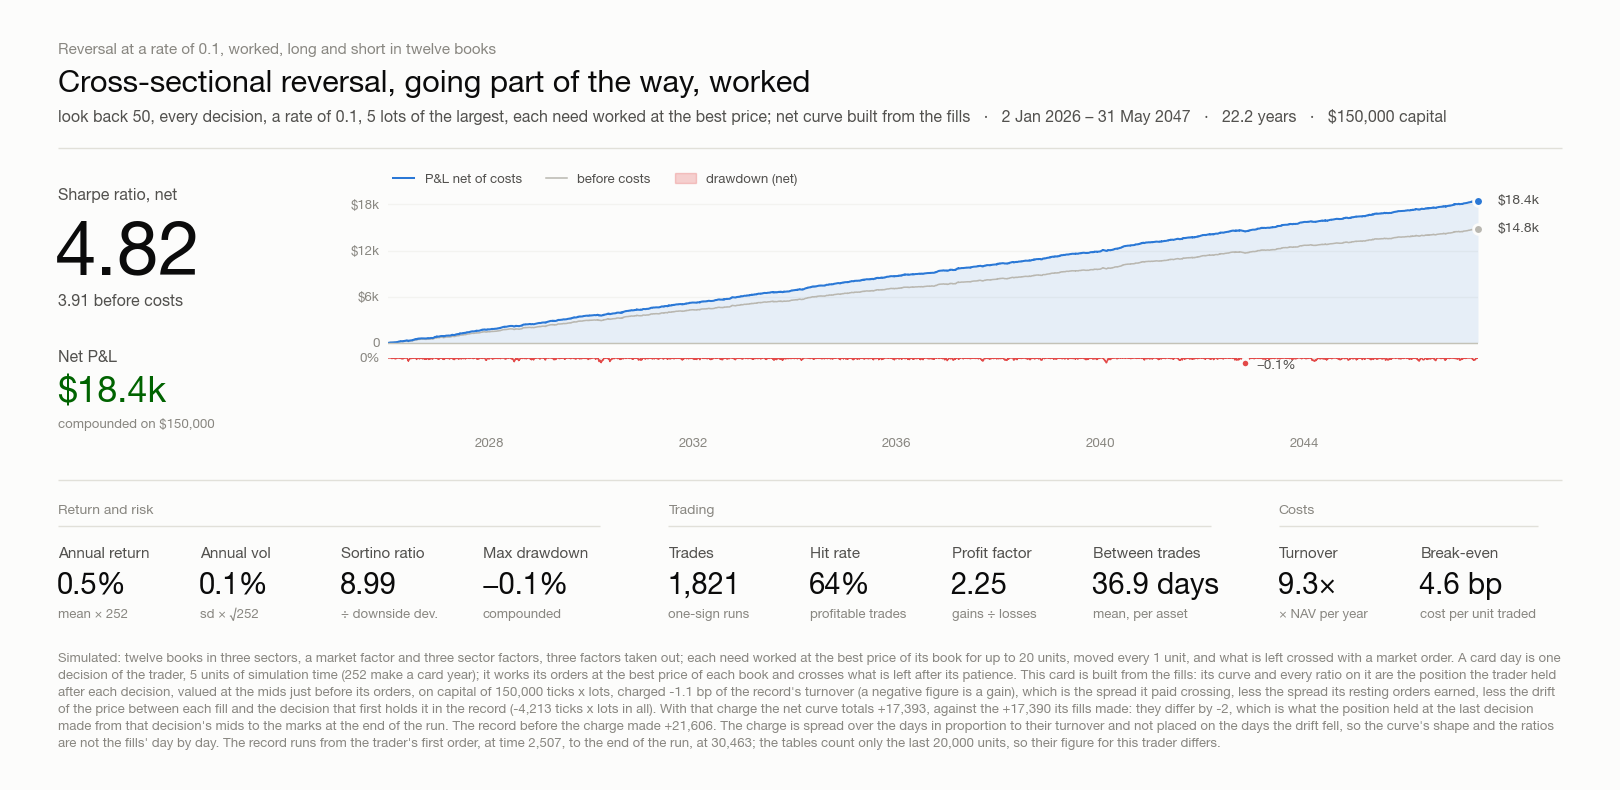

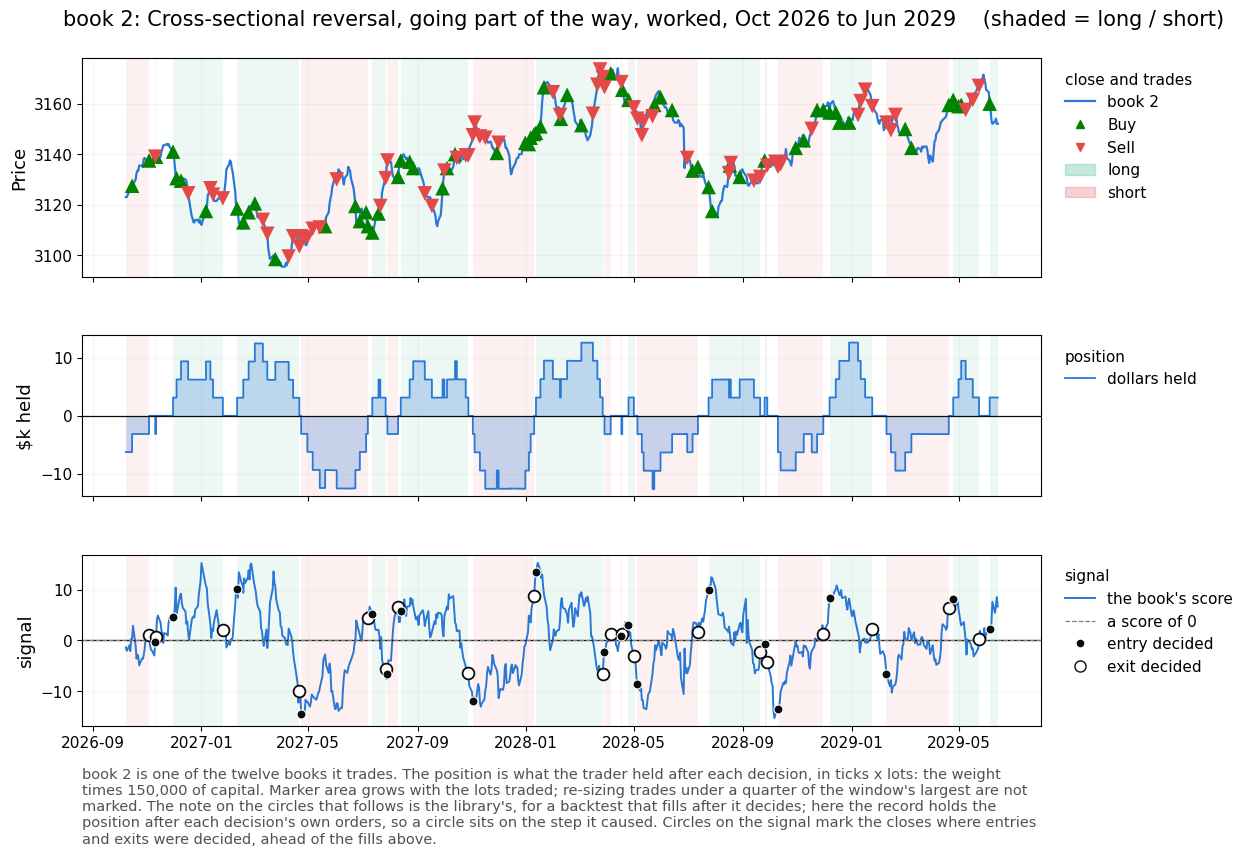

Reversal at a rate of 0.1, worked, long and short in twelve books: its fills made +17,390, the card's net P&L is +17,393 (within 2 of the fills, 0.01%: the tail, asserted, and within 0.5% outside a smoke copy) and the record at the decisions, before the drift charge, +21,606; it holds at most 0.65 times the capital of 150,000, and more than it on 0.0% of days.
The fills made +17,390, the card's net +17,393 and the record at the decisions +21,606. The record differs from the fills by -4,215, which is -4,213 of what the price did between a fill and the decision that first holds it in the record (summed over the lots filled between decisions, from the mid before each fill to the next decision's) and -2 of what the position held at the last decision made from that decision's mids to the marks at the end of the run: the two terms add up to the difference to rounding (asserted). The card charges the first as a cost, so that its net is the fills' P&L less the tail (-2), which is +17,393 (asse

In [27]:
# The worked reversal trader (look back 50, a rate of 0.1, deciding every 5 units) on the first seed of SEEDS
# (CARD_SEED), which played no part in choosing any setting: the run of the table's row on that seed, to its end,
# with a record of every decision. The chart is of the book whose lots change most often, with that book's score of
# the trader and a line at 0. The card is built from the fills (changed after the second run, on a review of it): the
# record at the decisions, charged the drift between each fill and the decision that first holds it, so that its net
# curve totals what the fills made.
TRADERS_SETTING = (
    'twelve books in three sectors, a market factor and three sector factors, three factors taken out; each need '
    f'worked at the best price of its book for up to {WORKED.patience:g} units, moved every {WORKED.reprice:g} unit, '
    'and what is left crossed with a market order'
)


def card_capital(trader):
    # CAPITAL, unless the trader holds more than it at its most (the record at CAPITAL, its gross across books):
    # then the next whole multiple of it above that, so that a card never holds more than its capital.
    peak = float(record_of(trader).weights.abs().sum(axis=1).max())
    return CAPITAL if peak <= 1.0 else CAPITAL * math.ceil(peak)


def card_reconciled(got, drift, tail):
    # The card is built from the fills (see card): it charges the record the drift (card_drift), and asserts that its
    # net P&L is the fills' less the tail. What is asserted here is the other side of it: the record before the charge
    # differs from the fills' P&L by exactly the two terms, the drift and the tail.
    gap = got['fills'] - got['record']
    assert abs(gap - drift - tail) < 1e-6 * (1 + abs(got['fills'])), (
        f"the fills' P&L less the record's, {gap:+,.2f}, is not drift {drift:+,.2f} and tail {tail:+,.2f}"
    )
    print(
        f"The fills made {got['fills']:+,.0f}, the card's net {got['net']:+,.0f} and the record at the decisions "
        f"{got['record']:+,.0f}. The record differs from the fills by {gap:+,.0f}, which is {drift:+,.0f} of what the "
        f'price did between a fill and the decision that first holds it in the record (summed over the lots filled '
        f"between decisions, from the mid before each fill to the next decision's) and {tail:+,.0f} of what the "
        f"position held at the last decision made from that decision's mids to the marks at the end of the run: the "
        f'two terms add up to the difference to rounding (asserted). The card charges the first as a cost, so that its '
        f"net is the fills' P&L less the tail ({tail:+,.0f}), which is {got['net']:+,.0f} (asserted by the card)."
    )


card_trader, card_fills, card_market = recorded(full_row(REVERSAL), WORKED)
card_money = reversal_money = card_capital(card_trader)
card_move, card_tail = card_drift(card_trader, card_market)
reversal_card = card(
    card_trader,
    card_fills,
    'Cross-sectional reversal, going part of the way, worked',
    'look back 50, every decision, a rate of 0.1, 5 lots of the largest, each need worked at the best price',
    'Reversal at a rate of 0.1, worked, long and short in twelve books',
    TRADERS_SETTING,
    "the book's score",
    [(0.0, 'C7', 'a score of 0')],
    most_changed(card_trader),
    market=card_market,
    relation=most_changed(card_trader),
    capital=card_money,
    drift=card_move,
)
card_reconciled(reversal_card, card_move, card_tail)
if card_money != CAPITAL:
    print(f'The card holds more than {CAPITAL:,.0f} at its most, so its capital is {card_money:,.0f} ticks x lots.')
reversal_counted = traders_frame[
    (traders_frame.row == traders_row(REVERSAL, 'worked')) & (traders_frame.seed == CARD_SEED)
]
print(
    f"The table's figure for this run, the last {SPAN:,.0f} units only: {reversal_counted.pnl.item():+,.0f}; the "
    f"card's "
    f'fills are those of the whole run, from the first order.'
)

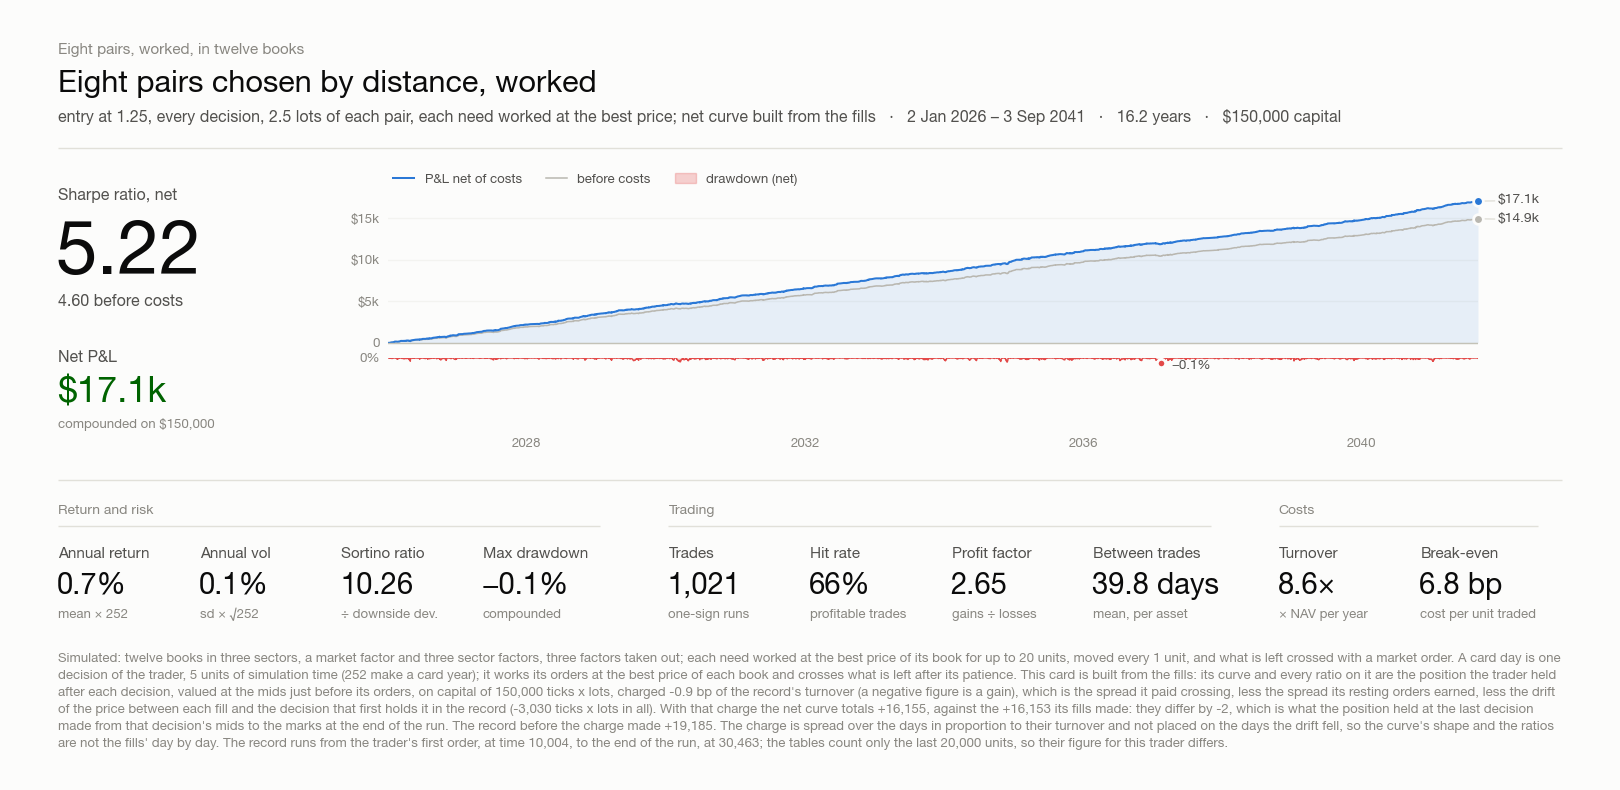

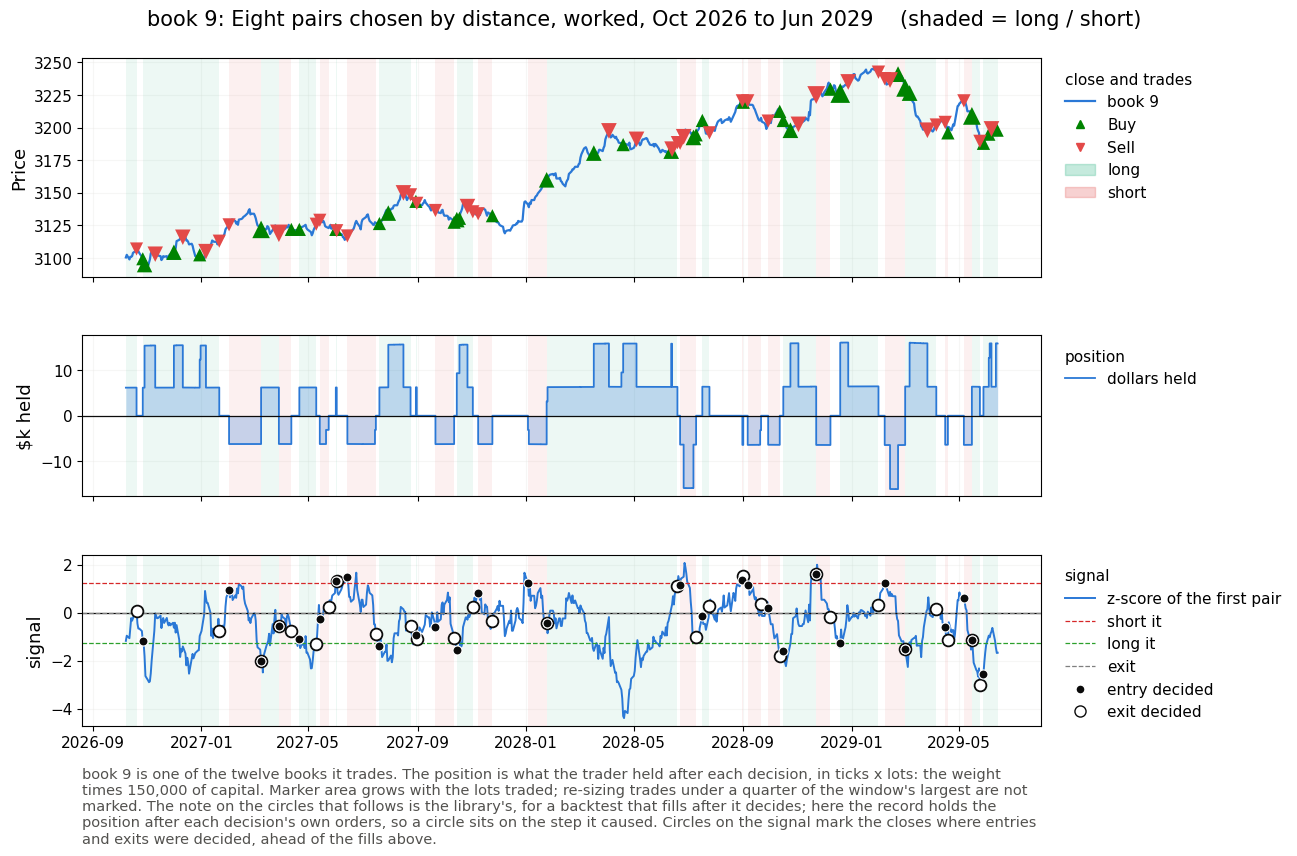

Eight pairs, worked, in twelve books: its fills made +16,153, the card's net P&L is +16,155 (within 2 of the fills, 0.01%: the tail, asserted, and within 0.5% outside a smoke copy) and the record at the decisions, before the drift charge, +19,185; it holds at most 0.71 times the capital of 150,000, and more than it on 0.0% of days.
The fills made +16,153, the card's net +16,155 and the record at the decisions +19,185. The record differs from the fills by -3,032, which is -3,030 of what the price did between a fill and the decision that first holds it in the record (summed over the lots filled between decisions, from the mid before each fill to the next decision's) and -2 of what the position held at the last decision made from that decision's mids to the marks at the end of the run: the two terms add up to the difference to rounding (asserted). The card charges the first as a cost, so that its net is the fills' P&L less the tail (-2), which is +16,155 (asserted by the card).
The table'

In [28]:
# The worked pairs trader (eight pairs chosen by distance, entry at 1.25, 2.5 lots of each pair, deciding every 5
# units) on the same seed, recorded the same way. The chart is of the largest leg of the first pair, with that pair's
# z-score, lines at the entry level on either side of 0 and at the level it leaves at, and circles where the trader
# enters and exits. Built from the fills as the reversal card is (changed after the second run, on a review of it).
card_trader, card_fills, card_market = recorded(full_row(PAIRS), WORKED)
card_money = pairs_money = card_capital(card_trader)
card_move, card_tail = card_drift(card_trader, card_market)
pairs_card = card(
    card_trader,
    card_fills,
    'Eight pairs chosen by distance, worked',
    'entry at 1.25, every decision, 2.5 lots of each pair, each need worked at the best price',
    'Eight pairs, worked, in twelve books',
    TRADERS_SETTING,
    'z-score of the first pair',
    around(card_trader),
    largest_leg(card_trader),
    market=card_market,
    capital=card_money,
    drift=card_move,
)
card_reconciled(pairs_card, card_move, card_tail)
if card_money != CAPITAL:
    print(f'The card holds more than {CAPITAL:,.0f} at its most, so its capital is {card_money:,.0f} ticks x lots.')
pairs_counted = traders_frame[(traders_frame.row == traders_row(PAIRS, 'worked')) & (traders_frame.seed == CARD_SEED)]
print(
    f"The table's figure for this run, the last {SPAN:,.0f} units only: {pairs_counted.pnl.item():+,.0f}; the card's "
    f"fills "
    f'are those of the whole run, from the first order.'
)
print(f'\nThe two cards took {sum(CARD_SECS) / 60:.1f} core-minutes.')

**A worked trader's card is built from its fills, and the record at the decisions alone showed more than the fills made.** Both cards are on seed 101, capital 150,000 ticks x lots. The reversal trader's fills made +17,390 and the card's net P&L is +17,393, within 2 of them (0.01%), which is the tail, asserted; the record at the decisions, before the drift charge, is +21,606, which is 4,215 more than the fills made. That difference is the drift, -4,213, what the price did between a fill and the decision that first holds it in the record, and the tail, -2, what the position held at the last decision made from that decision's mids to the marks at the end of the run; the two add to the difference to rounding (asserted). It holds at most 0.65 times the capital and never more than it (0.0% of days). The pairs trader's fills made +16,153, the card's net P&L is +16,155 (within 2), and the record is +19,185, which is 3,032 more than the fills: -3,030 of drift and -2 of tail; it holds at most 0.71 times the capital, also never above it. The second run's cards were built from the record alone and showed more than the traders made: the record is 4,215 and 3,032 above the fills before any drift is charged. A worked trader's fills come between decisions, so the record puts a lot in the position only at the next decision, and leaves out what the price did in between. These cards charge that drift to the trader as a cost, in proportion to each day's turnover, so that the net curve totals the fills less the tail.

**The card's costs line is a gain, and the gray before-costs curve is below the net one.** On the two card faces, the charge is -1.1 bp of the record's turnover for the reversal trader and -0.9 bp for the pairs trader, a negative figure being a gain: the spread the resting orders earned is more than the spread paid and the drift together. The gray before-costs curve ends at \$14.8k against the net curve's \$18.4k for reversal, and at \$14.9k against \$17.1k for pairs. That curve has no charge at all, neither the spread the resting orders earned nor the drift, so it is not the record at the decisions that the cell prints (+21,606 and +19,185, which have the spread paid less earned in them). The face's net P&L, \$18.4k and \$17.1k, is compounded on \$150,000 and is not the sum of the card's days (+17,393 and +16,155). This is this market's gain, in a market built to be kind to a resting order (the title cell's list), at the library's impact: the cards have no bracket, and a card is an illustration.

**What a scorecard shows, and does not.** It shows a net equity curve that rises nearly steadily on both cards, with a maximum drawdown of -0.1% and a Sharpe ratio of 4.82 (3.91 before costs, on a curve with neither the spread earned nor the drift charged, which is neither the paper nor the earlier notebooks' before-costs figure) for the reversal trader and 5.22 (4.60) for the pairs trader, as printed on the faces: the annualized ratios are per card day, one decision, of a net curve built from the fills with the drift charged in proportion to each day's turnover. It does not show the fills day by day, because the drift is not placed on the days it fell, so the curve's shape, its drawdown and its ratios are those of that construction; its hit rate and profit factor are those of legs and not of pairs; and it is two runs on one seed, an illustration of how a worked trader's fills look in a backtest's terms and not a test of the traders. The table's figure for the same run is +12,218 for reversal and +15,794 for pairs, over the last 20,000 units only, where the card's fills are those of the whole run from the first order. The signal charts are of book 2 for the reversal trader and of book 9 for the pairs trader, from October 2026 to June 2029 on the cards' dates.

In [29]:
# What the conclusions read from this section: its figures under the keys of the predictions (PREDICTIONS, key_of),
# as (the run's figure, its standard error over the seeds), and the two predictions that are sentences. No verdict is
# made here: the conclusions print each beside the prediction, and judge decides.
def traders_collect():
    # The section's figures under the keys of the predictions (a function, so that its loop variables are not
    # left behind).
    traders_figures = {}
    for name in FULL:
        worked, twin = traders_row(name, 'worked'), traders_row(name, 'twin')
        worked_high, twin_high = (traders_row(name, 'worked, 0.5'), traders_row(name, 'twin, 0.5'))
        label = TRADERS_LABEL[name]
        for quantity, row in (
            (WORKED_A_LOT, worked),
            (TWIN_A_LOT, twin),
            (HIGH + WORKED_A_LOT, worked_high),
            (HIGH + TWIN_A_LOT, twin_high),
        ):
            traders_figures[key_of(name, quantity)] = (
                float(traders_table.shortfall_a_lot[row]),
                float(traders_table.shortfall_a_lot_se[row]),
            )
        traders_figures[key_of(name, FULL_PNL)] = (float(traders_gain.pnl[label]), float(traders_gain.se[label]))
    queue_worked, queue_high = (traders_row(QUEUES, 'worked'), traders_row(QUEUES, 'worked, 0.5'))
    for quantity, column in ((GOT_PART, 'got_part'), (BACK_PART, 'back_part'), (GOT_SHARE, 'got_share')):
        traders_figures[key_of(QUEUES, quantity)] = (
            float(traders_split[column][queue_worked]),
            float(traders_split[f'{column}_se'][queue_worked]),
        )
    traders_figures[key_of(QUEUES, WORKED_PNL)] = (
        float(traders_table.pnl[queue_worked]),
        float(traders_table.se[queue_worked]),
    )
    traders_figures[key_of(QUEUES, HIGH + WORKED_PNL)] = (
        float(traders_table.pnl[queue_high]),
        float(traders_table.se[queue_high]),
    )
    return traders_figures


traders_figures = traders_collect()
missing = [key for key in traders_figures if key not in PREDICTIONS]
assert not missing, f'figures with no prediction: {missing}'
traders_verdicts = {key: judge(key, *figure) for key, figure in traders_figures.items()}  # judge runs on each

# The first sentence: at 0.5 a worked trader's paper is its twin's with no impact of its own within two standard
# errors (the paired difference over its standard error); the second: no row crosses more than about 2% of its lots
# (the mean share of the lots a worked row crossed, at each impact).
traders_paper_z = {
    name: float(traders_gain_fair.paper[TRADERS_LABEL[name]] / traders_gain_fair.paper_se[TRADERS_LABEL[name]])
    for name in FULL
}
traders_crossed = {
    traders_row(name, how): float(traders_table.crossed_share[traders_row(name, how)])
    for name in FULL
    for how in ('worked', 'worked, 0.5')
}
print(
    f'{len(traders_figures)} figures of section 3 are kept for the conclusions under the keys of the predictions '
    f'(`traders_figures`), with the paper of a worked trader less the twin with no impact of its own at '
    f'{IMPACT_HIGH:g} in '
    f'standard errors (`traders_paper_z`) and the share of lots crossed (`traders_crossed`):\n'
)
for name in FULL:
    print(
        f'{TRADERS_LABEL[name]:<9} paper less the twin with no impact of its own, in standard errors: '
        f'{traders_paper_z[name]:+.2f}'
    )
for row, share in traders_crossed.items():
    print(f'{row:<28} crossed share {share:.4f}')

25 figures of section 3 are kept for the conclusions under the keys of the predictions (`traders_figures`), with the paper of a worked trader less the twin with no impact of its own at 0.5 in standard errors (`traders_paper_z`) and the share of lots crossed (`traders_crossed`):

reversal  paper less the twin with no impact of its own, in standard errors: +0.04
queues    paper less the twin with no impact of its own, in standard errors: +2.26
pairs     paper less the twin with no impact of its own, in standard errors: +0.10
baskets   paper less the twin with no impact of its own, in standard errors: +0.55
reversal, worked             crossed share 0.0014
reversal, worked, 0.5        crossed share 0.0014
queues, worked               crossed share 0.0011
queues, worked, 0.5          crossed share 0.0006
pairs, worked                crossed share 0.0035
pairs, worked, 0.5           crossed share 0.0031
baskets, worked              crossed share 0.0169
baskets, worked, 0.5         crossed s

### What This Section Cannot Show

- **What resting orders would save in a real market.** The order flow here never reacts to a resting order, nobody steps in front of it, cancel and replace are free and instant, an order alone at the best price steps back for nothing, a jump is always seen in time, there are no fees or rebates, and the takers carry 0.05 a lot of information. Every saving of 3a is a figure of a market built so, a bound on each item of that list that favors the resting order, and not a prediction of one anywhere else. That the worked traders beat their crossing twins on every seed is a statement about this market.
- **That the bracket tests those items.** The market at 0.5 moves one thing, the takers' information (and with it how far a crossing trader's own orders push the fair values it is marked at). That a saving survives it says how a resting order and its twin each respond to better informed takers; it is not shown to survive any item of the list above, none of which the bracket touches.
- **That a P&L gain against the twin at 0.5, or a paper difference at any impact, is the execution's.** The twin's own market orders push the fair values its paper is marked at and its signal reads, so at 0.5 the worked trader's paper and P&L are compared, as well, with the twin that has no impact of its own, which removes the push of the twin's own orders and is not shown to be a like-for-like twin of the paper (for the queue row it is not), and the bracket is read on the shortfall a lot. Even at 0.05 a paper difference between a worked trader and its twin is not read as the execution's: nothing printed says what makes it (their entries differ, resolved only for baskets, whose paper difference is the one that is not resolved, and the control's two twins differ in paper by -53 (se 24) at 0.05), so a paired shortfall is read as an execution cost only where the paper difference is small beside it.
- **That the queue row's shortfall a lot is a cost of working an order.** On the lots a worked queue trader gets, a resting order cost less than crossing; the rest of its shortfall is the paper's gain on lots asked and taken back before they filled, which no order cost. 3b prints the split for every row, and a figure of the queue row is never quoted without it. The split itself is exact (to rounding) and says nothing of what the drift on the lots taken back means for a signal.
- **That each lot was worked for its patience.** Every row has a rate or is a relation whose need moves: the patience is the age of a need's oldest lot, a need that falls to nothing clears its clock, and lots asked late are crossed with the first. What the table says of crossing (the share of lots crossed) is the share of the lots of needs whose patience ran out.
- **That a card's curve is the fills' day by day.** The scorecard is built from the fills: a record at the decisions charged the drift between each fill and the decision that first holds it, in proportion to each day's turnover, so that its net curve totals the fills' P&L less a tail of a few ticks (asserted). The drift is not placed on the days it fell, so the curve's shape, its drawdown and its ratios are not the fills' day by day, and its hit rate and profit factor are those of legs and not of pairs. Two cards on one seed are not a test of the traders.
- **That the legs are a pair's or a basket's.** The trace follows a decision's legs. For the rate 0.25 basket it follows the first slice of an order that goes on, and some orders change more than one relation at once. The library never hedges a leg that has filled, so what 3c measures is that choice: another way of working a relation (a leg that fills is hedged at once, or the legs are priced together) is not measured here. A twin's legs are not traced: they are 0 by construction.
- **That the exposure is the risk.** `exposure` is the root mean square of what the trader holds of the factors, through the market's own exposures; `risk_adjusted_long` and `deviation_long` are the notebook's risk figures, measured over the span. A worked trader's higher exposure is a fact of its positions in this market and not an estimate of what holding half a pair costs in another.
- **That the ranking of 3d is a result.** Four rows on twelve seeds, ranked by means: a description. It says nothing of rows that were not run, and the change of a pair's order is read beside its standard error.
- **That one setting is the right one for every row.** Every worked row has a patience of 20 and a reprice of 1, chosen on seeds 1 to 8 and not on these seeds, and not tuned for any trader here. Patience between 10 and 20, a reprice faster than every unit, and where an order rests were not explored, so a row's cost is the cheap end of what was measured.
- **That one-lot and follower figures are what these traders pay.** Section 1's and section 2's figures are for orders of one lot and of followers; a multi-lot or rate trader's needs are another size, and none of their figures is carried to the four rows. Nor is any figure compared with the review's prototype's except where the setting is the same (a reprice of None, section 1's row).
- **That a P&L over 20,000 units was explored.** The predictions for the full rows are twice the exploration's, which ran 10,000 units after each row's own burn: an extrapolation, and the burn is notebook 13's for all four rows here, which the twins' match with notebook 13's lines at the exploration's burns says is of no consequence (to within 1.3 standard errors).
- **That a band, a deal, the index book or Johansen baskets behave alike.** None is run: the exploration found that the band rows' paper was not their twins' and that patience never binds on them, that the Johansen basket's entries differed from its twin's, and no market of this notebook has deals or an index book.
- **That twelve seeds say more than twelve seeds of one simulated market do.** Twelve books in three sectors, 20,000 units a run. Seeds 1 to 8, where the setting, the rows and the predictions were chosen, are in no table here, and no test is made: a figure is a mean over the seeds with its standard error over them, and a difference is taken seed by seed.

## 4. Conclusions

The cell below prints, from the frames and tables each section left, the figures the conclusions rest on, in the order the sections ran their tables: section 1's three parts (the twins, the touch, the control), section 2 (the cost by signal, where a need ended, the thirds, with the Walker as 1b's row) and section 3 (the four traders, the gain as its three terms, the split of the shortfall and the lots counted once, the queue row with its scores given to the books at random, the legs, the exposure with what the factors made and what the paper and the gap hold of them, the order of the four, the two cards built from the fills). The lines added after the second run, on a review of it, are those of the three terms, the lots counted once, the random-score row, the factors and the paper and the gap, the depth, asked lots and split of section 2, and the cards' net; they are descriptions, with no prediction. Then the predictions of the cell before section 1: every one beside the run's figure with its standard error over the seeds, how many combined standard errors apart the two are, and `held` or `did not hold` by the rule that cell wrote before the run (within three combined standard errors and the prediction's sign; a prediction of 0 has no sign); the two predictions that are sentences, as counts with a verdict each; and the core-minutes of the runs by table. The conclusions below quote these printed figures and, where a paragraph says so, a figure that a section's own cell printed and this one does not (the cards' two terms, 3a's waits, 3d's gaps and the exploration's figures in the head of section 1); a plain difference or ratio of two printed figures says so where it is used. A paired difference is printed as the sections print it: the mean, its standard error over the seeds, t (the mean in standard errors, a ratio and nothing more) and the seeds positive. A level is its mean over the seeds and its standard error.

In [30]:
# The headline figures of the three sections, from the frames and tables they left, in the order the sections ran them:
# section 1's three parts, section 2's, section 3's. Then the predictions: each beside the run's figure and the verdict
# of the rule written before the run; the two predictions that are sentences, as counts; and how long the runs took. The
# conclusions quote these printed figures and no others. A paired difference is printed as the sections print it: the
# mean, its standard error over the seeds, t (the mean in standard errors, a ratio and nothing more) and the seeds
# positive. A level is its mean over the seeds and its standard error.
print(
    f'Seeds: SEEDS {SEEDS[0]} to {SEEDS[-1]} ({len(SEEDS)}), CARD_SEED {CARD_SEED}. Ticks x lots after costs, unless a '
    'line says paper (what the position asked for at each decision would have made at that decision\'s mid). A '
    'shortfall a lot is against the decision mid: a positive figure is a cost.'
)


def end_level(line, column='shortfall_a_lot', digits=3):
    # '+0.123 (se 0.004)': the mean over the seeds of a column of a line of table_of or paired_table, and its standard
    # error.
    return f'{line[column]:+.{digits}f} (se {line[column + "_se"]:.{digits}f})'


def end_money(line, column):
    # '+1,234 (se 56)': the same, in ticks x lots.
    return f'{line[column]:+,.0f} (se {line[column + "_se"]:,.0f})'


# ---------------------------------------------------------------------------------------------------------------------
print(
    f'\nSection 1, what a resting lot costs (the probes, burn {PROBE_BURN:,.0f} and span {PROBE_SPAN:,.0f}; 1a at '
    f"notebook 13's burn {BURN:,.0f} and span {SPAN:,.0f})"
)
if SMOKE:
    print('- 1a: not compared with notebook 13 in a smoke copy.')
else:
    print(
        f'- 1a: all {len(FULL)} twins are the lines notebook 13 printed (P&L, standard error, seeds positive, before '
        'costs, costs, lots, entries, gross and exposure), to the last digit printed, as 1a asserted.'
    )
for name in FULL:
    line = twins_table.loc[name]
    print(
        f'    {TRADERS_LABEL[name]}: P&L {said(line)}; shortfall a lot {end_level(line)}; paper {line.paper:+,.0f} = '
        f'before costs {line.before_costs:+,.0f}; shortfall {line.shortfall:,.0f} = costs {line.costs:,.0f}.'
    )
print('- 1b, the touch (the one-lot Walker, or five lots where the row says so):')
for row, line in touch_table.iterrows():
    kind = (
        f"a model's market order filled {line.market_share:.3f} of the passive lots"
        if line.passive_lots > 0
        else 'no passive lots'
    )
    print(
        f'    {row:<26} shortfall a lot {end_level(line)}, {int(line.shortfall_a_lot_positive)} of {int(line.seeds)} '
        f'seeds above 0; crossed {line.crossed_share:.4f} of its lots; wait {line.wait:.1f}; {kind}.'
    )
for row in touch_worked:
    line = touch_table.loc[row]
    print(
        f"    markouts of the row '{row}' (a passive lot, 1, 5 and 20 units after the fill): by a market order "
        + ', '.join(f'{line[f"markout_{later}_market"]:+.2f}' for later in (1, 5, 20))
        + '; by a limit order across the quote '
        + ', '.join(f'{line[f"markout_{later}_limit"]:+.2f}' for later in (1, 5, 20))
        + '.'
    )
for title, pairs in (
    ('the saving (the twin less the worked row)', touch_savings),
    ('the price of the setting (a variant less the default)', touch_prices),
    ('what an impact of 0.5 does to a cost (its row less the same row at 0.05)', touch_brackets),
):
    print(f'    {title}, shortfall a lot, paired:')
    for label, (one, other) in pairs.items():
        print(f'      {label}: {said(paired(touch_frame, one, other, "shortfall_a_lot"), 3)}')
print('    worked less twin, a seed over the span:')
for label, line in touch_gains.iterrows():
    print(
        f'      {label}: P&L {said(line)}; paper {end_money(line, "paper")}; shortfall {end_money(line, "shortfall")}.'
    )
print('- 1c, the control (its six rows):')
for row, line in control_table.iterrows():
    print(
        f'    {row:<26} P&L {said(line)}; paper {end_money(line, "paper")}; shortfall a lot {end_level(line)}, '
        f'{int(line.shortfall_a_lot_positive)} of {int(line.seeds)} seeds above 0.'
    )
print('    paired differences:')
for label, line in control_gaps.iterrows():
    print(
        f'      {label}: P&L {said(line)}; paper {end_money(line, "paper")}; shortfall {end_money(line, "shortfall")}; '
        f'shortfall a lot {end_level(line)}.'
    )
print(
    '    correlation over the seeds of the papers: '
    + '; '.join(f'{label} {corr:+.3f}' for label, corr in control_corr.items())
    + '.'
)
print(
    f"    The control's needs: {control_need_lots:.2f} lots on average for a lot, against {control_need:g} by "
    f'arithmetic. Control less the Walker\'s null at {control_need:g} lots (a straight line between the one-lot and '
    'the five-lot Walker, an assumption), paired:'
)
for (kind, impact), (null, mine) in control_null.items():
    print(
        f'      {kind}, impact {impact:g}: control {mine.mean():+.3f}, null {null.mean():+.3f}, '
        f'control less null {said(paired_of(mine - null), 3)}.'
    )

# ---------------------------------------------------------------------------------------------------------------------
print(
    f'\nSection 2, the cost by signal (one-lot followers, worked, {len(SEEDS)} seeds, span {PROBE_SPAN:,.0f}; the '
    "Walker is 1b's row)"
)
for impact in IMPACTS:
    print(
        f'- impact {impact:g}: shortfall a lot with the signal, against it and the common part (their mean); the '
        "signal's own part (half with less against) and the common part less the Walker's, paired:"
    )
    for signal in SIGNALS:
        part = signal_parts[(impact, signal)]
        print(
            f'    {signal:<10} with {signal_text(part["with"])}, against {signal_text(part["against"])}, common '
            f'{signal_text(part["common part"])}, Walker {part["Walker"].mean():+.3f}; own part '
            f'{said(part["own part"], 3)}; common less Walker {said(part["common less Walker"], 3)}.'
        )
    print(f'  where a need ended (impact {impact:g}): at the first placement, with and against, and crossed:')
    for signal in SIGNALS:
        first = [
            series_of(signal_routes, signal_name(signal, direction, impact), 'first_share')
            for direction in SIGNAL_DIRECTIONS
        ]
        crossed = [
            series_of(signal_routes, signal_name(signal, direction, impact), 'crossed_share')
            for direction in SIGNAL_DIRECTIONS
        ]
        print(
            f'    {signal:<10} with {first[0].mean():.3f}, against {first[1].mean():.3f}, with less against '
            f'{said(first[0] - first[1], 3)}; crossed {crossed[0].mean():.4f} and {crossed[1].mean():.4f}.'
        )
    print(f'  the strongest third of the targets less the weakest (impact {impact:g}), shortfall a lot, paired:')
    for signal in SIGNALS:
        third = {
            direction: signal_thirds[signal_thirds.row == signal_name(signal, direction, impact)]
            .set_index('seed')
            .sort_index()
            for direction in SIGNAL_DIRECTIONS
        }
        steep = {direction: third[direction].third_3 - third[direction].third_1 for direction in SIGNAL_DIRECTIONS}
        own = (steep['with'] - steep['against']) / 2
        print(f'    {signal:<10} with {said(steep["with"], 3)}; own part {said(own, 3)}.')
print(
    '- added after the second run, on a review of it (a description; nothing was chosen from it): the five signals '
    'together, how far apart the with and against followers asked, the depth the order joined, and where the own part '
    'comes from.'
)
for impact in IMPACTS:
    print(
        f"  impact {impact:g}: the five signals together, common part less the Walker's, paired: "
        f'{said(signal_group[impact], 3)}.'
    )
    print(
        '  lots asked a seed, with less against (the mean over the seeds, the standard deviation over the seeds, the '
        "largest gap on a seed as a share of the seed's with row, the seeds on which the with row asked more):"
    )
    for signal in SIGNALS:
        asked = signal_asked[(impact, signal)]
        gap = asked['with'] - asked['against']
        print(
            f'    {signal:<10} {gap.mean():+.1f}, sd {gap.std():.1f}, largest {(gap.abs() / asked["with"]).max():.1%}, '
            f'with row asked more on {int((gap > 0).sum())} of {len(gap)} seeds.'
        )
    print(
        '  the lots at the best price the order joined (own side) and on the other side, the mean over the seeds, and '
        'own side less other side, with less against, paired:'
    )
    for signal in SIGNALS:
        depth = {
            direction: signal_depths.loc[signal_name(signal, direction, impact)].sort_index()
            for direction in SIGNAL_DIRECTIONS
        }
        imbalance = {d: depth[d].own_depth - depth[d].other_depth for d in SIGNAL_DIRECTIONS}
        print(
            f'    {signal:<10} with {depth["with"].own_depth.mean():.2f} own, {depth["with"].other_depth.mean():.2f} '
            f'other; against {depth["against"].own_depth.mean():.2f} own, {depth["against"].other_depth.mean():.2f} '
            f'other; own less other, with less against {said(imbalance["with"] - imbalance["against"], 2)}.'
        )
    print('  where the own part comes from: where the needs ended and what each route cost (they add to the own part):')
    for signal in SIGNALS:
        where, cost = signal_splits[(impact, signal)]
        own = where + cost
        shares = (
            f'; as shares of the own part {where.mean() / own.mean():.0%} and {cost.mean() / own.mean():.0%}'
            if abs(own.mean()) > 2 * se_of(own)
            else '; shares not read (the own part is within two standard errors of 0)'
        )
        print(f'    {signal:<10} where the needs ended {said(where, 3)}; what each route cost {said(cost, 3)}{shares}.')

# ---------------------------------------------------------------------------------------------------------------------
print(f'\nSection 3, four traders worked (burn {BURN:,.0f}, span {SPAN:,.0f}, {len(SEEDS)} seeds)')
for name in FULL:
    label = TRADERS_LABEL[name]
    print(f'- {label}:')
    for how in TRADERS_HOWS:
        line = traders_table.loc[traders_row(name, how)]
        print(
            f'    {how:<26} P&L {said(line)}; paper {end_money(line, "paper")}; shortfall a lot {end_level(line)}; '
            f'crossed {line.crossed_share:.4f}; entries {line.entries:,.1f}; exposure {line.exposure:.2f}; '
            f'risk_adjusted_long {line.risk_adjusted_long:+.3f}.'
        )
    for title, table in (
        ('worked less twin', traders_gain),
        ('at 0.5, worked less twin', traders_gain_high),
        ('at 0.5, worked less the twin with no impact of its own', traders_gain_fair),
        ('at 0.5, the twin with no impact of its own less the twin', traders_own),
    ):
        line = table.loc[label]
        print(
            f'    {title}: P&L {said(line)}; paper {end_money(line, "paper")}, {int(line.paper_positive)} of '
            f'{int(line.seeds)} seeds above 0; shortfall {end_money(line, "shortfall")}; shortfall a lot '
            f'{end_level(line)}; entries {line.entries:+,.1f} (se {line.entries_se:,.1f}); risk_adjusted_long '
            f'{end_level(line, "risk_adjusted_long")}.'
        )
    low, high = traders_saving[name]
    print(
        f'    the saving a lot (twin less worked): at {IMPACT:g} {said(paired_of(low), 3)}; at {IMPACT_HIGH:g} '
        f'{said(paired_of(high), 3)}; at {IMPACT_HIGH:g} less at {IMPACT:g} {said(paired_of(high - low), 3)}.'
    )
    for title, terms in (
        (f'at {IMPACT:g}, against the twin', traders_terms_low),
        (f'at {IMPACT_HIGH:g}, against the twin with no impact of its own', traders_terms_fair),
    ):  # added after the second run, on a review of it
        gain, twin_paid, worked_paid, paper = terms[label]
        print(
            f"    the P&L gain as its three terms, {title}: {gain:+,.0f} = the twin's shortfall {twin_paid:,.0f} less "
            f"the worked row's {worked_paid:+,.0f} plus the paper difference {paper:+,.0f}; {gain / twin_paid:.2f} "
            'times what the twin paid.'
        )
    for how in ('worked', 'worked, 0.5'):
        line = traders_split.loc[traders_row(name, how)]
        print(
            f'    what the shortfall of {how} is made of: {line.got_share:.1%} of the lots asked got; shortfall a lot '
            f'{line.shortfall_a_lot:+.3f} = got {line.got_part:+.3f} + taken back {line.back_part:+.3f} + open '
            f'{line.open_part:+.3f} (unasked {line.unasked_cost / line.asked_lots:+.3f}); a lot got cost '
            f'{line.got_a_lot:+.3f}, a lot taken back {line.back_a_lot:+.3f}.'
        )
        once = traders_once_table.loc[traders_row(name, how)]  # added after the second run, on a review of it
        print(
            f'    the lots counted once, {how}: {once.back_once:.1%} of the lots got or taken back were taken back '
            f'(the lots asked less the lots got, twice the lots taken back and the lots open: {once.lots_gap:+.1f}); '
            f'the paper made '
            f'{end_money(once, "paper_on_got")} on the lots got, {end_money(once, "paper_on_back")} on the lots taken '
            f'back and {once.paper_rest:+,.0f} on the rest.'
        )
print(f'- the lots got by the kind of fill, worked, seed {CARD_SEED} only:')
for row, line in traders_fill.iterrows():
    print(
        f'    {row}: lots by a market order {line["lots, market"]:,.0f} ({line["a lot, market"]:+.3f} a lot), by a '
        f'limit order {line["lots, limit"]:,.0f} ({line["a lot, limit"]:+.3f}), crossed {line["lots, crossed"]:,.0f} '
        f'({line["a lot, crossed"]:+.3f}).'
    )
print(
    '- the queue row with its scores given to the books at random, at 0.05 (the part added after the second run to 3b: '
    'a description, and no prediction is made or judged of it):'
)
for row, line in random_table.iterrows():
    print(
        f'    {row:<24} P&L {said(line)}; paper {end_money(line, "paper")}; shortfall a lot {end_level(line)}; lots '
        f'asked {line.asked_lots:,.0f}.'
    )
for row, line in random_split.iterrows():
    print(
        f'    what the shortfall of {row} is made of: {line.got_share:.1%} of the lots asked got and '
        f'{line.back_once:.1%} of the lots got or taken back taken back; shortfall a lot '
        f'{line.shortfall_a_lot:+.3f} = got {line.got_part:+.3f} + taken back {line.back_part:+.3f} + open '
        f'{line.open_part:+.3f}; a lot got cost {line.got_a_lot:+.3f}, a lot taken back {line.back_a_lot:+.3f}.'
    )
print('    the queue row less the random-score row, worked, paired by seed:')
for label, column, digits in (
    ('P&L', 'pnl', 0),
    ('paper', 'paper', 0),
    ("a lot taken back's drift", 'back_a_lot', 3),
    ("a lot got's cost", 'got_a_lot', 3),
    ('share of the lots asked got', 'got_share', 3),
    ('share taken back, each lot once', 'back_once', 3),
    ('shortfall a lot', 'shortfall_a_lot', 3),
    ('taken-back part over the lots asked', 'back_part', 3),
    ('got part over the lots asked', 'got_part', 3),
):
    print(f'      {label}: {said(random_gap[column], digits)}.')
print('    the random-score row, worked less its twin, paired by seed:')
for column, digits in (('pnl', 0), ('paper', 0), ('shortfall', 0), ('shortfall_a_lot', 3)):
    print(f'      {column}: {said(random_saving[column], digits)}.')
print('- the legs of the two relation rows, worked, per run (means over the seeds):')
for row, line in traders_leg.iterrows():
    print(
        f'    {row}: {line.leg_orders:,.0f} orders followed, {line.leg_censored:.1f} censored; {line.leg_legs:.2f} '
        f'legs and {line.leg_lots:.2f} lots an order; to done {line.leg_to_done:.2f} (se {line.leg_to_done_se:.2f}), '
        f'90th percentile {line.leg_to_done_p90:.2f}; legs unbalanced {line.leg_unbalanced:.2f} of a hold of '
        f'{line.leg_hold:.1f}, {line.leg_unbalanced_of_hold:.3f} of the time held; some order unbalanced for '
        f'{line.leg_union_share:.3f} of the span; lots held ahead of the slowest leg {line.leg_lots_ahead:.2f} on '
        'average.'
    )
print('- the exposure of the worked trader against its twin, worked less twin (the ratio is of the means):')
for label, line in traders_exposure_low.iterrows():
    print(
        f'    {label}: gross {end_level(line, "gross", 2)}, exposure {end_level(line, "exposure", 2)} on '
        f'{int(line.exposure_positive)} of {int(line.seeds)} seeds, ratio {line.exposure_ratio:.2f}; exposure a lot '
        f'held {end_level(line, "exposure_per_gross", 4)}; deviation_long {end_level(line, "deviation_long", 2)}.'
    )
print(
    '- added after the second run, on a review of it: what the factors made of the P&L (factor_part), worked less the '
    'twin (at 0.05) and less the twin with no impact of its own (at 0.5), paired:'
)
for impact, table in traders_factor.items():
    for label, line in table.iterrows():
        print(
            f'    {label} at {impact:g}: factor_part {end_money(line, "factor_part")}, '
            f'{int(line.factor_part_positive)} of {int(line.seeds)} seeds above 0.'
        )
print(
    '- what the paper and the gap hold of the factors, the worked relation rows at 0.05 (the root of the mean square '
    'of what is held of the factors; the mean over the seeds and (standard error over seeds)):'
)
for label, line in traders_ex_roots.iterrows():
    squares = traders_ex_squares.loc[label]
    print(
        f'    {label}: position {line["position"]}, paper {line["paper"]}, twin {line["twin"]}, gap {line["gap"]}; '
        f'position / twin {line["position / twin"]}, paper / twin {line["paper / twin"]}; paper less twin '
        f'{line["paper less twin"]}.'
    )
    print(
        f'    {"":<{len(label)}}  mean squares: position {squares["position"]} = paper {squares["= paper"]} + gap '
        f'{squares["+ gap"]} + 2 x cross {squares["+ 2 x cross"]}; the gap is not 0 on {squares["units with a gap"]} '
        f'of the units and holds some of the factors on {squares["units with an exposed gap"]}; lots held: position '
        f'{squares["gross, position"]}, paper {squares["gross, paper"]}, gap {squares["gross, gap"]}.'
    )
print('- the order of the four rows (1 is the best), by the means:')
for title, table in ((f'impact {IMPACT:g}', traders_rank_low), (f'impact {IMPACT_HIGH:g}', traders_rank_high)):
    for column in [c for c in table.columns if c.endswith('rank')]:
        order = ' > '.join(table[column].sort_values(kind='stable').index)
        print(f'    {title}, {column.removesuffix(", rank")}: {order}.')
for title, card_of, money in (
    ('the worked reversal trader', reversal_card, reversal_money),
    ('the worked pairs trader', pairs_card, pairs_money),
):
    print(
        f"- The card of {title} (seed {CARD_SEED}, capital {money:,.0f}), built from the fills: fills "
        f"{card_of['fills']:+,.0f}, the card's net {card_of['net']:+,.0f}, the record at the decisions before the "
        f"drift charge {card_of['record']:+,.0f}, the most it holds {card_of['peak']:.2f} times the capital, above "
        f"it on {card_of['above_one']:.1%} of days."
    )

# ---------------------------------------------------------------------------------------------------------------------
# The predictions: what seeds 1 to 8 gave, beside the run's figure. Held when the run's figure is within three
# combined standard errors of the prediction and has its sign (a prediction of 0 has no sign): `judge`, the rule of
# the setup cell and of the predictions cell, written before the run.
end_figures = {**lot_figures, **signal_figures, **traders_figures}
assert len(end_figures) == len(lot_figures) + len(signal_figures) + len(traders_figures), 'two sections answer a key'
assert set(end_figures) == set(PREDICTIONS), (
    f'predictions with no figure: {sorted(set(PREDICTIONS) - set(end_figures))}; '
    f'figures with no prediction: {sorted(set(end_figures) - set(PREDICTIONS))}'
)
end_verdicts = {key: judge(key, *figure) for key, figure in end_figures.items()}
print(
    f'\nThe predictions: {len(PREDICTIONS)} figures that seeds 1 to 8 gave, each beside the run\'s on {len(SEEDS)} '
    'seeds. z is the run less the prediction in combined standard errors; "held" is |z| of 3 or less and the '
    'prediction\'s sign. A P&L over a full row\'s span is twice the exploration\'s figure for 10,000 units, an '
    'extrapolation.\n'
)
print(f'{"verdict":<14}{"z":>7}  {"predicted":<22}{"run":<22}prediction')
for key, prediction in PREDICTIONS.items():
    value, se = end_figures[key]
    verdict = end_verdicts[key]
    quantity = key.split(' | ')[1]
    digits = 0 if 'P&L' in quantity or 'paper' in quantity else 3  # ticks x lots, and not a figure a lot
    predicted = f'{prediction.value:+,.{digits}f}' + (f' (se {prediction.se:,.{digits}f})' if prediction.se else '')
    run = f'{value:+,.{digits}f} (se {se:,.{digits}f})'
    print(
        f'{"held" if verdict.held else "did not hold":<14}{verdict.z:>+7.2f}  {predicted:<22}{run:<22}{prediction.what}'
    )
by_section = {
    'section 1': set(lot_figures),
    'section 2': set(signal_figures),
    'section 3': set(traders_figures),
}
print(
    f'\nHeld: {sum(v.held for v in end_verdicts.values())} of {len(end_verdicts)}; '
    + '; '.join(
        f'{section}: {sum(end_verdicts[key].held for key in keys)} of {len(keys)}'
        for section, keys in by_section.items()
    )
    + '.'
)
did_not = [key for key, verdict in end_verdicts.items() if not verdict.held]
print(f'Did not hold ({len(did_not)}):')
for key in did_not:
    print(f'  z {end_verdicts[key].z:+.2f}  {PREDICTIONS[key].what}')

# The two predictions that are sentences, as counts. The first has its rule in the sentence: within two standard errors.
# The second says 'about 2%', and no rule was written for it, so it is read here, before the run, as at most 2.5%
# (the exploration's own largest share crossed, over every row it kept, was 2.1%); the counts at 2.0% and at 2.5% and
# the largest are all printed.
ABOUT_TWO_PERCENT = 0.025
print(f'\nSentence 1. {SENTENCES[0]}')
paper_rows = {**{TRADERS_LABEL[name]: z for name, z in traders_paper_z.items()}, 'the control': lot_paper_z}
within = [label for label, z in paper_rows.items() if abs(z) <= 2]
print(
    f'  Paper less the twin with no impact of its own at {IMPACT_HIGH:g}, in standard errors: '
    + ', '.join(f'{label} {z:+.2f}' for label, z in paper_rows.items())
    + f'. Within two standard errors: {len(within)} of {len(paper_rows)} rows.'
)
print(
    f'  Verdict on the sentence as stated ("every row"): {"held" if len(within) == len(paper_rows) else "did not hold"}'
    + (
        ''
        if len(within) == len(paper_rows)
        else '; outside two standard errors: '
        + ', '.join(f'{label} {z:+.2f}' for label, z in paper_rows.items() if abs(z) > 2)
    )
    + '.'
)
print(f'Sentence 2. {SENTENCES[1]}')
print(
    '  Share of its lots a worked row crossed: '
    + ', '.join(f'{row} {share:.4f}' for row, share in traders_crossed.items())
    + f'. At most 2.0%: {sum(s <= 0.02 for s in traders_crossed.values())} of {len(traders_crossed)} rows; at most '
    f'{ABOUT_TWO_PERCENT:.1%} (how "about 2%" is read here): '
    f'{sum(s <= ABOUT_TWO_PERCENT for s in traders_crossed.values())} of {len(traders_crossed)}; the largest '
    f'{max(traders_crossed.values()):.4f}.'
)
print(
    f'  Verdict on the sentence as read before the run (every row at most {ABOUT_TWO_PERCENT:.1%}): '
    f'{"held" if all(s <= ABOUT_TWO_PERCENT for s in traders_crossed.values()) else "did not hold"}.'
)

# ---------------------------------------------------------------------------------------------------------------------
# Core-minutes of the runs that have a frame (each on one core: a run's seconds), by table. The cards' recorded runs and
# 3b's four runs by kind of fill are timed in lists, and the walks nobody keeps are not counted.


def core_minutes(table):
    # A frame of runs with a column of seconds, or a Series or list of seconds, as core-minutes.
    return (table.secs.sum() if isinstance(table, pd.DataFrame) else pd.Series(table).sum()) / 60


RUNS = {
    'section 1': {
        '1a, the four twins': [twins_frame],
        '1b, the touch': [touch_frame],
        '1c, the control': [control_frame],
    },
    'section 2': {'2, the followers': [signal_frame]},
    'section 3': {
        '3, the sixteen cases': [traders_new],
        '3b, the lots by kind of fill': [[run['secs'] for run in traders_fill_runs]],
        '3b, the random-score row': [random_frame],
    },
}
print()
total = 0.0
for section, tables in RUNS.items():
    minutes = {name: sum(core_minutes(f) for f in frames) for name, frames in tables.items()}
    runs = sum(len(f) for frames in tables.values() for f in frames)
    total += sum(minutes.values())
    print(
        f'Core-minutes, {section}: {sum(minutes.values()):.0f} in {runs} runs ('
        + '; '.join(f'{name}: {x:.1f}' for name, x in minutes.items())
        + ').'
    )
print(f'Core-minutes, the {len(CARD_SECS)} cards: {sum(CARD_SECS) / 60:.1f}.')
print(f'Core-minutes in all: {total + sum(CARD_SECS) / 60:.0f}.')

Seeds: SEEDS 101 to 112 (12), CARD_SEED 101. Ticks x lots after costs, unless a line says paper (what the position asked for at each decision would have made at that decision's mid). A shortfall a lot is against the decision mid: a positive figure is a cost.

Section 1, what a resting lot costs (the probes, burn 500 and span 5,000; 1a at notebook 13's burn 10,465 and span 20,000)
- 1a: all 4 twins are the lines notebook 13 printed (P&L, standard error, seeds positive, before costs, costs, lots, entries, gross and exposure), to the last digit printed, as 1a asserted.
    reversal: P&L +4,364 (se 109, t 39.97, 12 of 12 seeds positive); shortfall a lot +0.995 (se 0.002); paper +11,314 = before costs +11,314; shortfall 6,950 = costs 6,950.
    queues: P&L -8,823 (se 68, t -129.13, 0 of 12 seeds positive); shortfall a lot +1.010 (se 0.002); paper +1,596 = before costs +1,596; shortfall 10,418 = costs 10,418.
    pairs: P&L +7,808 (se 91, t 85.91, 12 of 12 seeds positive); shortfall a lot +1

**What the notebook settled, and what it did not.** What follows is written after the run, from the figures the cell above printed and, where a paragraph says so, from a figure that a section's own cell printed and the conclusions cell does not (the cards' two terms, 3a's waits, 3d's gaps, notebook 13's figures beside the own parts and the exploration's figures in the head of section 1). It says what this market did on these twelve seeds. A figure has its standard error (se) over the seeds and the seeds positive where the cell gives them, and a plain difference or ratio of two printed figures says so. Every saving in it is this market's. The market is built to be kind to a resting order in the places the opening lists (the order flow never reacts to the order, no one steps in front of it, cancel and replace are free and instant, an order alone at the best price steps back for nothing, a jump is always seen in time, there are no fees, and the takers carry 0.05 a lot of information), and the bracket at an impact of 0.5 moves one of them, the takers' information, and none of the others. A saving that survives the bracket has been shown to survive better informed takers and is silent on the rest of the list.

**In sum.** *Question 1, what a lot costs when it rests.* A one-lot order that rested at the best price for up to 20 units cost -0.221 a lot (se 0.006, 0 of 12 seeds above 0) against the decision mid, where a market order cost +0.989 (se 0.005): a saving of +1.210 (se 0.007, 12 of 12 seeds positive). Five lots cost -0.036 (se 0.008) against +1.240 (se 0.005), a saving of +1.277 (se 0.009). At 0.5 the savings are +1.027 (se 0.019) and +0.870 (se 0.028), on 12 of 12 seeds each. *Question 2, how much of the cost is the signal's own.* The order in the signal's direction paid more than the one against it for four of five signals, by +0.174 (the queues), +0.079 (pairs), +0.064 (reversal) and +0.054 (residuals) a lot at 0.05, each on 12 of 12 seeds, and paid less for momentum, by -0.018 (se 0.006, 3 of 12 seeds positive). *Question 3, what becomes of four traders when their orders rest.* Every worked trader beat its crossing twin on every seed, by +8,262 (reversal), +8,557 (queues), +7,332 (pairs) and +12,411 (baskets) in P&L at 0.05, which is 1.19, 0.82, 1.03 and 1.08 times what the twin paid to cross. The queue row stayed a loss, -266 (se 55, 2 of 12 seeds positive), and the worked pairs and baskets held 1.56 and 2.19 times their twins' factor exposure at about the same gross. *The predictions:* 57 of 63 held by the rule written before the run, and the first of the two sentences did not. *Still open:* how much of any saving is the free step back, which no row switches off, and what a resting order saves where the items of the list are not as they are here. Every saving above is this market's, and the bracket at 0.5 moves the takers' information and none of the other items.

**Question 1: in this market a resting lot was a gain against the decision mid where a crossing lot cost about a tick (section 1).** The one-lot Walker, a trader with no signal, cost +0.989 a lot (se 0.005, 12 of 12 seeds above 0) as a twin crossing with market orders and -0.221 (se 0.006, 0 of 12 seeds above 0) worked, resting for up to 20 units. The saving, the twin's shortfall a lot less the worked row's seed by seed, is +1.210 (se 0.007, t 163.18, 12 of 12 seeds positive). Of the worked row's lots 0.0008 were crossed after the patience ran out, and the needs that ended had waited 3.2 units on average, so the cost is that of lots that rested. Five lots cost +1.240 (se 0.005) as a twin and -0.036 (se 0.008, 1 of 12 seeds above 0) worked, a saving of +1.277 (se 0.009, 12 of 12 seeds positive), with 0.0052 of the lots crossed and a mean wait of 6.1 units. These are costs of a lot against the decision mid in a market that favors the resting order in the ways listed at the top of the notebook, and they are not what a resting order saves in a real one (the bracket, below, moves one of those ways, the takers' information, and no other).

**The two prices of the setting.** Two variants were run once, on the one-lot Walker, each less the default `Execution(patience=20.0, reprice=1.0)`, paired by seed. A patience of 5 cost +0.218 (se 0.008, 12 of 12 seeds positive) a lot more, with 0.2140 of its lots crossed against 0.0008. No repricing, the order moved only at the trader's own decisions every 5 units, cost +0.128 (se 0.011, 12 of 12 seeds positive) more, with 0.0126 of its lots crossed and a mean wait of 4.2 units against 3.2. The default is the cheap end of the three settings run. This run does not show that how often the order is moved matters more than the patience: its patience variant is the dearer of the two, and it has no patience between 5 and 20. That statement is the exploration's, on seeds 1 to 8 (the opening of section 1 gives patience 10 at +0.027 (se 0.016) a lot more than 20 and no repricing at +0.121 (se 0.010) more), and those seeds are not pooled with these. How much of the saving is the free step back, an order alone at the best price being put back for nothing, the notebook cannot say, because no row switches it off; the exploration's +0.027 (se 0.014) a lot on seeds 1 to 8 is not this notebook's figure.

**The bracket.** At an impact of 0.5 the one-lot Walker cost +1.170 (se 0.006) a lot as a twin and +0.143 (se 0.020) worked, and five lots +1.490 (se 0.006) and +0.620 (se 0.026). The savings are +1.027 (se 0.019) and +0.870 (se 0.028), each on 12 of 12 seeds. They fall, by 0.183 and 0.407 (plain differences) to 0.85 and 0.68 of what they were at 0.05 (plain ratios), because the worked row's cost rises more with the takers' information, by +0.364 (se 0.018, 12 of 12 seeds positive) for one lot and +0.656 (se 0.028, 12 of 12) for five, than the twin's, by +0.181 (se 0.006) and +0.250 (se 0.007). The saving is positive on every seed at both impacts in each row that has a bracket (the control's and the four traders' are below). What that shows is that the saving survives takers with ten times the information. What it does not show is anything about the other items of the list, none of which the bracket touches.

**Who fills a resting lot, and what it was worth.** A model's market order filled 0.710 of the worked one-lot row's passive lots, and a model's limit order across the quote the other 0.290 (the complement of the printed share). The lots the market orders filled were worth +0.65, +0.97 and +1.43 a lot 1, 5 and 20 units after the fill: the mid moved the maker's way, further the longer the horizon, so for seven in ten of the passive lots adverse selection was absent at this impact. The lots the limit orders across the quote filled were worth -0.23, -1.29 and -2.97: for the other three in ten it was large. The table does not pool the two kinds, so no printed figure says what the average passive lot was worth after its fill, and the notebook does not say that adverse selection is small overall. At 0.5 the market-hit lots were worth +0.73, +0.95 and +1.04 and the limit-hit lots -0.26, -1.77 and -3.69.

**The control: the saving holds at need sizes of one to four lots, 2.47 a lot on average, and the worked control sits on the Walker's straight line.** The control draws random targets of -2 to 2 lots, and a lot of its orders belongs to a need of 2.47 lots on average (2.5 by arithmetic). It cost +1.104 (se 0.006) a lot as a twin and -0.152 (se 0.013, 0 of 12 seeds above 0) worked at 0.05, and +1.304 (se 0.010) and +0.307 (se 0.024, 12 of 12 seeds above 0) at 0.5. Worked less twin in shortfall a lot is -1.256 (se 0.015) at 0.05 and -0.998 (se 0.030) at 0.5, each below 0 on every seed, so the saving falls under the bracket by 0.258 (a plain difference), as the Walker's did. The null for the control's shortfall a lot is the Walker's at 2.5 lots, a straight line between the one-lot and the five-lot Walker, which is an assumption. The worked control less that null is -0.000 (se 0.014, 8 of 12 seeds positive) at 0.05 and -0.015 (se 0.031, 5 of 12) at 0.5, each within one standard error of 0: it costs what a Walker of its need size would, and that does not show the line is exact. For the twin the line misses by +0.020 (se 0.005, t 3.87, 11 of 12 seeds positive) at 0.05 and +0.014 (se 0.010, 7 of 12) at 0.5. The printed figures put the +0.020 in the control twin's own impact and not in the line: the twin with no impact of its own cost +1.085 (se 0.006), and that twin less the twin is -0.019 (se 0.005). The notebook does not test that reading. At 0.5 the control's paper is -583 (se 140) below the plain twin's and +60 (se 245) above the twin with no impact of its own, and that twin's paper is -642 (se 174) below the plain twin's, so a paper gap against the plain twin at 0.5 includes the twin's own impact on the fair values it is marked at, and the P&L gain against it, +1,303 (se 141), is below the gain against the twin with no impact of its own, +1,912 (se 254), by about the size of that paper gap (that twin less the twin is -610 (se 169) in P&L). The papers of the control's rows move together at 0.05 (+0.984 for the worked control and the twin, +0.968 for it and the twin with no impact of its own, +0.976 for the two twins) and part at 0.5 (+0.810, +0.360 and +0.579). The worked control and the twin with no impact of its own, the two whose own orders leave the fair values alone, are the least alike at 0.5, which is not what the twin's own impact breaking the likeness would give, and the notebook does not explain it.

**Question 2: for four of five signals the order in the signal's direction paid more than the one against it, and for momentum it paid less (section 2).** The own part is half of the shortfall a lot with the signal less against it, paired by seed, under the assumption that a signal's effect is equal and opposite for the two orders, which the design cannot test. At 0.05, in the order printed, it is +0.174 (se 0.008, 12 of 12 seeds positive) for the queues, +0.064 (se 0.005, 12 of 12) for reversal, +0.079 (se 0.008, 12 of 12) for pairs, +0.054 (se 0.006, 12 of 12) for residuals and -0.018 (se 0.006, 3 of 12) for momentum. So the order with the signal paid more than the one against it on every seed for four signals, and momentum breaks it: its order with the signal paid less. At 0.5 the own parts are +0.090 (se 0.013, 12 of 12), +0.085 (se 0.011, 12 of 12), +0.195 (se 0.018, 12 of 12), +0.102 (se 0.017, 11 of 12) and -0.030 (se 0.012, 4 of 12). Momentum's has the same sign at both impacts, so the run has no change of sign at 0.5 to report, and the notebook does not explain its sign. The order of the own parts is not the same at the two impacts, and the cells print no test of the change in an own part from one impact to the other.

**The common part is not shown to be the Walker's.** The common part is the mean of the with and the against rows, and it should be the Walker's, -0.221 (se 0.006) at 0.05. The common part less the Walker's, paired by seed, is +0.016 (se 0.010, 8 of 12 seeds positive) for the queues, +0.011 (se 0.012, 10 of 12) for reversal, +0.021 (se 0.011, 8 of 12) for pairs, +0.021 (se 0.011, 9 of 12) for residuals and +0.013 (se 0.006, 9 of 12) for momentum, each within two standard errors of 0 and all five above it. The five lines share the Walker's row, so they are one finding: for the five together it is +0.016 (se 0.008, t 2.00, 9 of 12 seeds positive) at 0.05, on the line of two standard errors, and +0.025 (se 0.020, t 1.23, 7 of 12) at 0.5. The common part is within 0.021 of the Walker's on every signal at 0.05 and within 0.030 at 0.5, and above it on all ten lines. The notebook does not explain why, and it does not say the common part is the Walker's. (This group line was added after the second run, on a review of it, with the other lines of this part: a description, with no prediction.)

**Where the own part comes from.** The order with the signal ended at its first placement less often than the one against it for the four signals, by -0.126 (se 0.006, 0 of 12 seeds positive) for the queues, -0.030 (se 0.003) for reversal, -0.036 (se 0.004) for pairs and -0.027 (se 0.004) for residuals at 0.05, and that is a part of the own part and not a second finding. The own part splits exactly into where the needs ended and what each route cost: +0.106 (se 0.004) and +0.068 (se 0.005) for the queues (61% and 39% of it), +0.026 (se 0.003) and +0.038 (se 0.004) for reversal (40% and 60%), +0.032 (se 0.004) and +0.047 (se 0.006) for pairs (40% and 60%), and +0.024 (se 0.004) and +0.030 (se 0.006) for residuals (44% and 56%); both halves of momentum's are negative, and no share is read from them. For the queues the order with the signal joined the deeper side of the touch: 12.74 lots on its own side and 4.93 on the other, against 4.85 and 12.52 for the order against it, an own side less other side with less against of +15.49 lots (se 0.08, t 200.69, 12 of 12 seeds positive). For the queues, then, the direction of the order cannot be told from the depth it met, and the queues' own part (+0.174 at 0.05) is what resting on the deep side of an uneven touch costs. For pairs, residuals and momentum at 0.05 the two orders met about the same touch (-0.09 (se 0.09), +0.03 (se 0.12) and +0.05 (se 0.09)), so the difference is the direction and not the depth, as far as the tables show. Reversal's difference is +1.24 lots (se 0.10, 12 of 12 seeds positive), small beside the queues' and not within two standard errors of 0, and at 0.5 all four are more than two standard errors from 0, none above 0.79 lots in size; the tables do not say how much of an own part a gap of that size would make.

**What the thirds by target size say, and notebook 13's figures.** With the signal the cost a lot rose from the weakest third of the inner trader's target sizes to the strongest by +0.253 (se 0.022, 12 of 12 seeds positive) for the queues, +0.053 (se 0.029, t 1.82) for reversal, +0.071 (se 0.021, t 3.37) for pairs, +0.071 (se 0.034, t 2.09) for residuals and +0.012 (se 0.015, t 0.81) for momentum, beyond two standard errors for the queues, pairs and residuals. The own part is larger in the strongest third than in the weakest for four signals, by +0.252 (se 0.016), +0.054 (se 0.017), +0.072 (se 0.019) and +0.061 (se 0.018), and not for momentum (-0.000, se 0.012). The pairs trader's thirds are mostly ties, since its targets have almost all one of two sizes. Beside notebook 13's figures, where it has one, the queues' listener has an IC of +0.234 (se 0.001) and an edge per lot traded of +0.186 (se 0.001) ticks, and momentum's an IC of -0.060 (se 0.002) and an edge of -0.414 (se 0.012) ticks. They are in other units and of other horizons than a resting order's few units, so they sit beside the own parts in order and sign only, five signals in a description and not a test. The own part is half of what the order with the signal paid more than the one against it, and it is not an estimate of a signal's edge in notebook 13's units. The notebook does not say that momentum's negative listener figures account for its negative own part.

**Question 3: every worked trader beat its twin on every seed, at both impacts (section 3).** P&L in ticks x lots after costs, as a twin and worked at 0.05: reversal +4,364 (se 109) and +12,625 (se 79), queues -8,823 (se 68) and -266 (se 55), pairs +7,808 (se 91) and +15,140 (se 116), baskets +6,697 (se 210) and +19,108 (se 637). Worked less twin, paired by seed, is +8,262 (se 68), +8,557 (se 79), +7,332 (se 91) and +12,411 (se 535), each on 12 of 12 seeds, with a paper difference beside it of +166 (se 72, 9 of 12 seeds above 0), -383 (se 113, 2 of 12), +302 (se 77, 11 of 12) and -119 (se 188, 4 of 12). The shortfall a lot, as a twin and worked, is +0.995 (se 0.002) and -0.164 (se 0.004) for reversal, +1.010 (se 0.002) and +0.146 (se 0.004) for queues, +1.184 (se 0.006) and +0.011 (se 0.011) for pairs, and +1.034 (se 0.006) and -0.094 (se 0.011) for baskets. The saving a lot is +1.160 (se 0.005), +0.865 (se 0.005), +1.172 (se 0.011) and +1.128 (se 0.007) at 0.05, and +1.049 (se 0.009), +0.909 (se 0.005), +1.274 (se 0.023) and +0.907 (se 0.009) at 0.5, each on 12 of 12 seeds. It falls under the bracket for reversal and baskets (by 0.110 and 0.221, each on 12 of 12 seeds) and rises for pairs (by 0.101); the queue row's rises too (by 0.045, t 7.27), but that is a small change that the premise review did not reproduce, in a shortfall a lot that is not a cost of working an order, and it is not read. The notebook does not explain which way a row goes. The risk-adjusted figure rose on every row and every seed, by +0.091 (se 0.002), +0.227 (se 0.005), +0.066 (se 0.003) and +0.066 (se 0.003), and the queue row's worked -0.008 is still below 0. A worked trader's lots are nearly all passive: 0.0014, 0.0011, 0.0035 and 0.0169 of the lots were crossed at 0.05, and a need that ended had waited 3.2, 3.6, 4.4 and 3.5 units (3a). These savings are this market's, and the bracket at 0.5 moves the takers' information and nothing else on the list.

**The gain is the twin's shortfall less the worked row's, plus the paper difference.** The cell prints each gain as its three terms: reversal +8,262 = 6,950 less -1,146 plus +166; queues +8,557 = 10,418 less +1,478 plus -383; pairs +7,332 = 7,099 less +70 plus +302; baskets +12,411 = 11,496 less -1,034 plus -119. That is 1.19, 0.82, 1.03 and 1.08 times what the twin paid to cross, so a gain is about what the twin paid only as that identity: the saving in shortfall is the larger term of each gain, and the paper difference the smaller one. The paper difference is not 0 on three of the four rows (about 2.3, 3.4 and 3.9 standard errors from 0 for reversal, queues and pairs, plain ratios of the printed figures), and it is not read as the twin's own impact, which this run separates only at 0.5 (the control's two twins differ in paper by -53 (se 24) at 0.05, so it is not ruled out at 0.05 either), and it is not read as the execution's: the entries of a worked trader and its twin differ by amounts resolved only for baskets, the row whose paper difference is the one that is not, so nothing printed says what makes the paper differences. They are small beside the gains (about 2%, 4%, 4% and 1% of them, plain ratios of printed figures), and they are there. At 0.5 the gains against the twin with no impact of its own are +7,282 (se 552), +9,998 (se 176), +7,057 (se 534) and +9,937 (se 863), each on 12 of 12 seeds and 0.90, 0.80, 0.94 and 0.79 times what that twin paid to cross, and against the plain twin +7,352 (se 450), +9,055 (se 149), +6,570 (se 504) and +15,450 (se 893). The twin's own impact is large for baskets, where that twin less the twin is +5,513 (se 773, 12 of 12 seeds positive) in P&L, and for queues (-943, se 168), and not resolved for reversal (+70, se 401) and pairs (-487, se 425). So a P&L gain against the plain twin at 0.5 is not the execution's alone, and the bracket is read on the shortfall a lot. The twin with no impact of its own removes that push but is not shown to be like for like for every row: the queue row's paper is +382 (se 169, 10 of 12 seeds above 0) above it. These gains are this market's, and the bracket moves the takers' information and nothing else on the list.

**The queue row did not become profitable worked, and its shortfall a lot is not a cost of working an order.** Worked it made -266 (se 55, 2 of 12 seeds positive) against -8,823 (se 68, 0 of 12) crossed, and -4,944 (se 138, 0 of 12) against the plain twin's -13,999 (se 109) at 0.5. Its shortfall a lot of +0.146 (se 0.004) is a got part of -0.087 and a taken-back part of +0.233, with an open part of +0.000. Of the lots asked 47.1% were got, a lot got cost -0.185 (a gain, where crossing cost +1.010) and a lot taken back drifted +0.881, which is the paper's gain on a lot asked and taken back before it filled and which no order cost. The share of the lots asked that were not got is not the share taken back: counting each lot once, 35.9% of the lots got or taken back were taken back (33.2% at 0.5), because the lots asked count a lot taken back twice. The paper made -1,150 (se 68) on the lots got and +2,363 (se 11) on the lots taken back. The part added to 3b runs, on the same seeds, a row with the queue row's rule and its scores given to the books at random (a description, added after the second run, on a review of it, with no bracket and no prediction). It asks for 5,833 lots a seed against the queue row's 10,145, so its needs are not the queue row's. That row made +449 (se 48, 12 of 12 seeds positive) worked, against -5,716 (se 70) as a twin, and it has the queue row's shape: a got part of -0.182 and a taken-back part of +0.113, a lot got at -0.427 and a lot taken back at +0.395, with 42.6% of the lots asked got and 40.3% taken back counted once. So a row with no signal has the signs of the split, as this one row shows. The queue row less that row has a lot taken back drifting +0.486 more (se 0.007, 12 of 12 seeds positive) and a lot got costing +0.242 more (se 0.008, 12 of 12). Over the lots asked its shortfall a lot is +0.214 higher (se 0.004), of which +0.119 (se 0.002) is the taken-back part and +0.095 (se 0.004) the got part, about 56% and 44% (plain ratios of the printed parts to their sum). Its P&L is -715 (se 71, 0 of 12 seeds positive) below the row with no signal and its paper +1,163 (se 78, 12 of 12) above it. A lot taken back is in the paper and in the shortfall alike and not in the P&L, so the lots taken back are why the queue row's paper, which made +2,363 on lots it never held, does not reach its P&L; what puts its P&L below the other row's, and below 0, is that its lots got cost +0.242 a lot more. The paper lost about the same on a lot got in both rows, -1,150 over 4,780 lots and about -611 over 2,483 (plain arithmetic of printed means), and the P&L a lot got is -0.056 for the queue row against +0.181 (plain ratios). The half-and-half split of the shortfall a lot is not a split of the loss. That the queue row's resting orders miss the lots its signal is right about is not shown: the +0.486 fits it, and fits as well needs that are larger or last longer, which no cell separates. It is a comparison with one row in one market, whose lots are not the queue row's lots.

**The legs and the exposure.** A pair's legs were all done 6.69 units (se 0.04, 90th percentile 12.21) after the decision and the first slice of a basket's 7.58 (se 0.08, 90th percentile 13.25), against holds of 122.4 and 118.9 units. The legs of a hold's orders together were not even for 0.063 and 0.082 of the time held (a hold has 1.56 and 1.47 orders, each not even for 0.041 and 0.056 of it, plain ratios), some order's legs were not even for 0.247 and 0.193 of the span, and the lots held ahead of the slowest leg were 0.67 and 0.81 on average. At about the same gross (worked less twin -0.18 (se 0.10) and +0.39 (se 0.23) lots) the worked pairs and baskets held more of the factors: exposure +0.75 (se 0.02, 12 of 12 seeds) and +1.09 (se 0.07, 12 of 12), ratios of 1.56 and 2.19 to their twins', against +0.10 (se 0.01, 12 of 12) and +0.04 (se 0.01, 11 of 12) and ratios of 1.06 and 1.02 for reversal and queues. `deviation_long` rose with it for the relation rows, by +0.53 (se 0.08) and +1.08 (se 0.10), and `risk_adjusted_long` still rose, by +0.066 (se 0.003) each, because the mean gain rose more. The shortfall does not show this risk, which is the risk of holding half a pair, and `risk_adjusted_long` shows only that the gain outweighed it. The worked trader's paper carries its twin's exposure (paper less twin +0.01 (se 0.01, t 1.25) for pairs and -0.01 (se 0.01, t -1.81) for baskets) and the excess is the gap between its position and its paper: position 2.08 (se 0.03), paper 1.34 (se 0.04), twin 1.33 (se 0.04) and gap 1.69 (se 0.02) for pairs, and 2.02 (se 0.06), 0.91 (se 0.09), 0.92 (se 0.08) and 1.92 (se 0.04) for baskets, the gap being 1.20 and 1.90 lots of the 16.7 and 33.2 held. The factors made no resolved part of the gain: `factor_part`, worked less twin, is +41 (se 60) for pairs and +71 (se 83) for baskets at 0.05 (and +17 (se 98) and -8 (se 95) at 0.5, against the twin with no impact of its own), beside gains of +7,332 and +12,411. So a worked relation holds about its twin's lots and about its paper's factors, and the excess is the gap, 1.20 and 1.90 lots of legs in flight or that no relation asked for. The extra exposure is a few lots of unfilled, unhedged legs of orders in flight, in a market in which a leg that fills is never hedged, and it is not an estimate of what holding half a pair costs in another.

**Does execution change which trader is worth trading?** By P&L at 0.05 the crossing order is pairs, baskets, reversal, queues, and the worked order is baskets, pairs, reversal, queues: pairs and baskets swap, and the other two keep their places. Pairs less baskets is +1,111 crossing, with pairs above on 11 of 12 seeds, and -3,968 worked, with pairs above on 1 of 12 (3d), a change of -5,079 (se 545, t -9.32, 0 of 12 seeds positive); the other five pairs of rows keep their order on every seed. By `risk_adjusted_long` the order is pairs, reversal, baskets, queues, crossed and worked, at 0.05 and at 0.5. At 0.5, with the twin with no impact of its own as the crossing trader, the order by P&L is baskets, pairs, reversal, queues, both ways, so the swap has no counterpart there, baskets being already first as crossing traders. This is a description of four rows in one market, chosen on seeds 1 to 8 for what each shows about a resting order, and not a test and not a ranking of the signals.

**The two cards.** Both are on seed 101, capital 150,000, and built from the fills. The reversal trader's fills made +17,390, the card's net P&L is +17,393 and the record at the decisions, before the drift charge, is +21,606; it holds at most 0.65 times the capital, and above it on 0.0% of days. The pairs trader's fills made +16,153, the card's net is +16,155 and the record +19,185; it holds at most 0.71 times the capital, also never above it. The record is 4,215 and 3,032 above the fills (the card cells print these differences as -4,215 and -3,032): -4,213 and -3,030 of drift, what the price did between a fill and the decision that first holds it, and -2 and -2 of tail, what the position held at the last decision made from that decision's mids to the marks at the end. A worked trader's fills come between decisions, so a record at the decisions alone would have shown more than the traders made, and the card charges that drift as a cost so that its net totals what the fills made less the tail. The cards are two runs on one seed, an illustration and not a test of the traders, and they have no bracket.

**The predictions: 57 of 63 held, and the six that did not all failed on size.** The cell prints "Held: 57 of 63; section 1: 16 of 17; section 2: 17 of 21; section 3: 24 of 25". The rule, written before the run, is within three combined standard errors of the prediction and its sign, and a prediction of 0 has no sign. The six that did not, with z the run less the prediction in combined standard errors: the control worked at 0.5 (z -3.09; +0.380 predicted, +0.307 (se 0.024) run), the residuals follower with the signal (z +3.07; -0.180, -0.146 (se 0.011)), the residuals' own part (z +3.73; +0.030, +0.054 (se 0.006)), the momentum follower against the signal (z +5.14; -0.230, -0.190 (se 0.008)), momentum's own part (z -3.07; +0.000, -0.018 (se 0.006)) and the queue row worked at 0.5, shortfall a lot (z +5.38; +0.250, +0.267 (se 0.003)). Each failed on the size and none on the sign. Each carried no standard error of its own in the prediction, so the rule's tolerance was the run's alone, which the predictions cell said is too narrow, the true tolerance being about 1.6 times wider (the prediction is a mean over eight seeds and the run's over twelve), and a few of such predictions were bound to read `did not hold` with nothing wrong. At that width four of the six are within three combined standard errors (their z over 1.6 is about 1.9, 1.9, 2.3 and 1.9, plain ratios) and two are not: the momentum follower against the signal and the queue row at 0.5, at about 3.2 and 3.4 (plain ratios of +5.14 and +5.38). The cell does not print the standard errors that seeds 1 to 8 would have given these six, so the notebook cannot say, for any of them, how much of its z is the rule's narrowness and how much a difference between seeds 1 to 8 and these twelve, and it says neither that all six are the one nor that all six are the other. Three of the six (z -3.09, +3.07 and -3.07) are within 0.1 of the line of three, two predictions that held (+2.95 for the control twin and +2.92 for the reversal twin, both at 0.05) are within 0.1 on the other side, and the verdicts are from unrounded figures: read them as about three. The two largest z, +5.14 and +5.38, are gaps of 0.040 and 0.017 a lot (plain differences). Momentum's with row held (-0.226 against -0.230) and its against row did not, and its own part is half their difference. A miss of the P&L predictions of the four full rows would have been a miss of an extrapolation, twice the exploration's 10,000 units, and none missed (z +0.32, -0.21, +1.16 and +0.81). The queue row's worked P&L is not one of the six: the predictions cell wrote it as "about 0" and stored it as -120 (se 100), the sign rule applies to it as stored, and the run's -266 (se 55) has that negative sign and held, at z -1.28. The part added to 3b and the lines added after the second run have no prediction and are not in the count.

**The two sentences.** The first, that at 0.5 a worked trader's paper is its twin's with no impact of its own within two standard errors on every row of section 3 and on the control, **did not hold as stated**: 4 of 5 rows are within two standard errors, and the queue row is outside, at +2.26 (reversal +0.04, pairs +0.10, baskets +0.55, the control +0.24). The cell prints its verdict as "did not hold; outside two standard errors: queues +2.26". The second, that no row of section 3 crosses more than about 2% of its lots, held as read before the run: "about 2%" had no rule in the predictions cell and was read as at most 2.5%, and all 8 worked rows (four at each impact) are at most 2.0% and at most 2.5%, the largest 0.0169 (the baskets, worked at 0.05).

**What the three runs were.** The first run stopped in section 2, at an assertion of the setup's own. A follower's launches were on a grid fixed in advance, and where a launch came just after a grid time the next came 20 units later, before a lot that had run out its patience had been crossed; one launch of one run raised it, and nothing of section 2 had been printed. The follower now launches at the first decision 25 units or more after its last, a change of one line. The second run ran in full and was reviewed before any prose was written. A premise review re-made its headline figures from raw data with an independent harness and found no wrong figure, and a numbers audit found none either. The review found two printed sentences wrong (one in 1b, one in 3a), two scorecards whose headline overstated what the trader made, and measurements that no cell printed and that a truthful account needs. The third run, which this notebook holds, corrected the two sentences, built the scorecards from the fills, and added the measurements (each printed after the cell's earlier lines, under a line that says it was added after the second run) and the part of 3b with the queue row's scores given to the books at random. Every line the second run printed is reprinted by the third, except seventeen: eight are the two corrected sentences and the cards' lines, and nine are core-minutes, which are timings (the second run's differ from the first's in four timing lines too). The second and third runs are the same code and seeds for those figures, so none of the runs after the first is a second test, and what was added is a description and nothing was chosen from it.

**What the notebook may say, of this market.** A one-lot order resting at the best price for up to 20 units cost -0.221 a lot (se 0.006) against the decision mid where a market order cost +0.989 (se 0.005), and five lots -0.036 (se 0.008) where a market order cost +1.240 (se 0.005). By signal, the order in the signal's direction paid more than the one against it for the queues, reversal, pairs and residuals, on every seed at 0.05 (at 0.5 on every seed but one for the residuals), and less for momentum. Worked traders beat their crossing twins on every seed at both impacts, by 0.82 to 1.19 times what the twin paid to cross at 0.05 and 0.79 to 0.94 times what the twin with no impact of its own paid at 0.5. The bracket at 0.5 moves the takers' information and none of the other items of the list, so none of this is shown to hold with any of them changed. A fast signal did not become profitable worked: the queue row made -266 (se 55); its lots taken back are why its paper does not reach its P&L, and its lots got cost +0.242 a lot more (se 0.008) than those of a row with its rule and no signal, whose needs are not its own; the notebook does not say that its resting orders miss the lots its signal is right about. Worked relations held their twins' lots and more of the factors, 1.56 and 2.19 times as much, the excess being the gap between position and paper. **What it may not say.** That any saving is what resting orders save in a real market; that the bracket at 0.5 tests the list of what this market does for a resting order, when it moves the takers' information only; that a P&L gain against the twin at 0.5, or a paper difference at any impact, is the execution's; that the queue row's shortfall a lot is a cost of working an order; that how often the order is moved matters more than the patience, which this run does not show; that any figure of this notebook is the prototype's of the premise review (the no-repricing row works its orders the same way, and the notebook sets nothing beside it); that one-lot or follower figures are what a multi-lot or rate trader pays; that each lot of a rate row was worked for its patience; that a band row, a deal or the index book would behave alike; that the five common parts above the Walker's are five findings, or that the common part is the Walker's; and that momentum has a change of sign at 0.5 or that its sign is explained.

**What is still open.** How much of any saving is the free step back, which no row of this notebook switches off. What a resting order saves where the order flow reacts to it, someone steps in front of it, cancel and replace cost something, or a jump can fill it at a stale price: none is run. What a patience between 5 and 20, a reprice faster than every unit, or an order placed inside the spread would cost. Why the paper differs between a worked trader and its twin at 0.05 (+166, -383, +302 and -119), and why the twin with no impact of its own is not like for like for the queue row's paper. Why the saving falls for reversal and baskets and rises for pairs at 0.5, why momentum's order with the signal pays less, why the common part sits above the Walker's on all ten lines, why the control twin misses the Walker's line by +0.020, and why the worked control's paper parts from the twins' at 0.5. A hedge at the fill for a relation's legs. And what the queue signal's own part contributes to the queue row's loss, since the row with random scores is one row in one market and does not have the queue row's needs.

### Limitations

Each section ended with what it cannot show, and those lists are the full statements. What follows is what holds for the notebook as a whole. The first groups are as written before the run, with a clause added where the run printed something that bears on them; the last ones say what the run's figures cannot be read as.

- **What this market does for a resting order that a real one does not.** The order flow does not react to a working order: the model traders' orders arrive at the same rates with or without it, nobody cancels, chases or joins because of it, and a model's cancel that names a working order is dropped. Nobody steps in front of it, so it keeps the place it joined at until it moves. Cancel and replace are free and instant: no fee, no latency, no rebate lost. A jump in a book's fair value withdraws every working order in it at once, so a resting order is never filled at a price a jump has made stale; the library has no row for a jump that fills a resting order. There are no fees and no rebates. The takers are nearly uninformed: a model's market order carries 0.05 a lot of information, so the adverse selection that is the usual cost of resting is small wherever those orders do the filling. 1b's markouts show it for the 0.710 of the worked one-lot row's passive lots that a model's market order filled (+0.65, +0.97 and +1.43 a lot 1, 5 and 20 units after the fill) and not for the other 0.290, which a model's limit order across the quote filled (-0.23, -1.29 and -2.97), and no printed figure pools the two. And an order alone at the best price steps back for nothing, because the best price is told without the trader's own order; this notebook cannot say how much of any saving that is, since no row switches it off. Every saving here is a saving in a market built so, which is kind to a resting order in each of these places but the fees, which could go either way. It is a bound on the items that favor the resting order, and it is not a prediction of a saving anywhere else.
- **What the bracket moves, and what it does not.** The market at an impact of 0.5 moves one thing: the takers' information (and with it how far a crossing trader's own orders push the fair values it is marked at). A saving that survives it has been shown to survive better informed takers, and is silent on every other item of the list above, none of which the bracket touches. The savings did survive it, on every seed, in every row that has a bracket (1b, 1c and 3a), smaller for the Walker, the control, reversal and baskets and larger for pairs, and the notebook does not explain which way a row goes (the queue row's saving also rises, by +0.045 (t 7.27), a small change that the premise review did not reproduce, in a shortfall a lot that is not a cost of working an order, and it is not read). The bracket is read on the shortfall a lot, each trader against its own decision mids. A P&L or paper difference between a worked trader and its twin at 0.5 is not the execution's alone, because the twin's own market orders push the fair values that its paper is marked at and its signal reads (the twin's own impact is +5,513 (se 773) of the baskets' P&L gain against the plain twin); the twin with no impact of its own removes that push but is not shown to be a like-for-like twin of the paper (for the queue row it is not: its paper is +382 (se 169) above that twin's at 0.5), so what is left of a paper difference against it is read as printed, and where that twin is not run (1b) the notebook says so. A paper difference at 0.05 is not read as the execution's either: nothing printed says what makes it (the four rows' paper differences are +166 (se 72), -383 (se 113), +302 (se 77) and -119 (se 188); the entries of a worked trader and its twin differ by amounts resolved only for baskets, whose paper difference is the one that is not resolved; and the control's two twins differ in paper by -53 (se 24)), and the notebook does not read them as the twin's own impact.
- **The setting and the rows were chosen on seeds 1 to 8.** The execution (`patience=20.0, reprice=1.0`), the probes, the four rows, the design of every table and the predictions come from the exploration on seeds 1 to 8, and nothing was chosen on these twelve seeds, which are held out for this notebook, and the notebook ran on them three times (the opening says what changed between the runs, and none of the runs after the first is a second test). The two seeds' sets are never pooled. A prediction that did not hold is reported as one, and nothing in the notebook was tuned to make it hold. The exploration's P&L figures for the full rows are of 10,000 units after each row's own burn, and the notebook's predictions for them are twice those, an extrapolation that the exploration did not measure; the twins' match with notebook 13's lines at the exploration's burns says the longer common burn does not matter, to within the seeds' spread.
- **One setting, one length, one market.** Every worked row has the same patience and reprice. A patience between 10 and 20, a reprice faster than every unit, and where an order rests (the best price here, never inside the spread or behind it) were not explored, so a row's cost is the cheap end of what was measured. Two variants are run once, on the one-lot Walker: patience 5, which cost +0.218 (se 0.008) a lot more than the default, and no repricing, which cost +0.128 (se 0.011) more. This run does not show that how often the order is moved matters more than the patience: its patience variant is the dearer, and it has no patience between 5 and 20, so that statement is the exploration's, on seeds 1 to 8. No figure of this notebook is set beside the premise review's prototype, which moved its orders only at the trader's decisions; the no-repricing row works its orders the same way. Twelve seeds of one simulated market of twelve books in three sectors say how much a mean moves across those seeds and nothing about another market.
- **One-lot, control and follower figures are not what a multi-lot, rate or relation trader pays.** The Walker's one lot and five, the control's needs and the followers' one-lot orders have no rate, no band and no legs; a rate trader's need creeps or vanishes while its order rests, and a relation's legs fill one at a time. The queue row's shortfall a lot is not a cost of working an order, because it includes the lots asked and taken back before a fill, and is never quoted without the split of 3b. Nor is "each lot was worked for its patience" said of a rate row.
- **What section 2's figures are.** The own part is half of the shortfall a lot with the signal less against it, under the assumption that a signal's effect is equal and opposite for the two orders, which no run tests. The with and the against follower share the inner trader's targets only approximately: the lots they asked part by up to 9.3% of the with row on a seed at 0.05 and 19.7% at 0.5, so pairs, residuals and momentum do not ask for the same needs, and the difference is read over seeds and never order by order. A signal whose own part is 0 is one whose two orders cost the same, which is not a signal that knows nothing. The common part is not shown to be the Walker's (the five signals together are +0.016 (se 0.008, t 2.00) above it at 0.05), and the own part is not an estimate of a signal's edge in notebook 13's units. For the queues the order with the signal rests on the deep side of an uneven touch, so the direction cannot be told from the depth; for reversal at 0.05, and for reversal, pairs, residuals and momentum at 0.5, the two orders met touches that differed by a lot or less, and the tables do not say how much of an own part that is. The pairs trader's thirds by target size are mostly ties.
- **What section 3's figures are.** Four rows, one setting, one market, twelve seeds. The queue row's split says that the paper made money on the lots taken back and the lots got cost less than crossing, and a row with no signal has the same signs, as one such row shows. A lot taken back is in the paper and the shortfall and not in the P&L, so the lots taken back are why the queue row's paper does not reach its P&L, and its lots got, which cost +0.242 a lot more than those of a row with its rule and no signal, are why its P&L is below that row's and below 0; the half-and-half split of the shortfall a lot is not a split of the loss. The comparison is with one row in one market whose needs and lots are not the queue row's (it asks for 5,833 lots a seed against 10,145), and the notebook does not say that the queue row's orders miss the lots its signal is right about. The worked relations' extra exposure is the gap between position and paper, a few lots of unfilled, unhedged legs of orders in flight, which is a fact of these positions in a market in which a leg that fills is never hedged, and not an estimate of what holding half a pair costs in another; the shortfall does not show it. The ranking of 3d is four rows in one market, a description. The two cards are two runs on one seed, built from the fills with the drift charged in proportion to each day's turnover, so the curve's shape, its drawdown and its ratios are not the fills' day by day, and their hit rate and profit factor are those of legs and not of pairs.
- **What was dropped, and why.** *Band rows* (a trader that holds its position inside a band of half a lot): in the exploration a worked trader's paper was not its twin's, which makes the shortfall unreadable as an execution cost, and patience never bound on them. *Deals and the index book*: the library does not measure what a jump does to a resting order there, so no market of this notebook has either. *A hedge at the fill*: the library works every leg of a relation and never hedges a leg that has filled, so 3c measures that choice and no other way of working a relation (a hedge at the fill, or the legs priced together). *Improving the best price*: an order always joins the best price on its side and never improves it, so where an order rests is not a setting here. Also dropped, because the exploration found they showed nothing more: the Johansen basket (its entries differed from its twin's, as the Box-Tiao basket's do at 0.5, and Box-Tiao is the one tested), the queue row with a hold of 1 as a full row (it got a tenth of its lots) and the long-hold rows. A trader that does not net its orders is refused an execution.
- **What was added after the second run is a description.** The lines and tables that the third run added (the three terms of a gain, the lots counted once, the factors and what the paper and the gap hold of them, the depth, the asked lots and the split of the own part in section 2, the cards built from the fills, and 3b's row with the queue scores given to the books at random) have no prediction and were not chosen from. The random-score row is one row with the queue row's rule and no signal, whose needs are not the queue row's, in one market, at the library's impact, and has no bracket.
- **What the notebook may say and may not say.** It may say, of this market: a one-lot order resting at the best price for up to 20 units cost -0.221 a lot (se 0.006) against the decision mid where a market order cost +0.989 (se 0.005), and five lots -0.036 (se 0.008) where a market order cost +1.240 (se 0.005); by signal, the order in the signal's direction paid more than the one against it for the queues, reversal, pairs and residuals, and less for momentum, whose sign is the same at both impacts and is not explained; worked traders beat their crossing twins on every seed at both impacts, by 0.82 to 1.19 times what the twin paid to cross at 0.05, which is the identity of the gain's three terms and not an equality; a fast signal did not become profitable worked, the queue row making -266 (se 55): its lots taken back are why its paper does not reach its P&L, its lots got cost +0.242 a lot more than those of a row with its rule and no signal, which is why its P&L is below 0, and its orders are not shown to miss the lots its signal is right about; and worked relations held about their twins' lots and 1.56 and 2.19 times their factor exposure, the excess being the gap between position and paper. It may not say: that any saving is what resting orders save in a real market; that the bracket tests the list above; that a P&L gain against the twin at 0.5, or a paper difference at any impact, is the execution's; that the queue row's shortfall a lot is a cost of working an order; that how often the order is moved matters more than the patience; that a figure of this notebook is the prototype's of the premise review; that one-lot or follower figures are what a multi-lot or rate trader pays; that each lot of a rate row was worked for its patience; that a band row, a deal or the index book would behave alike; that the five common parts above the Walker's are five findings, or that the common part is the Walker's; or that momentum has a change of sign at 0.5, or that its sign is explained.
- **How the predictions were read.** The rule of the predictions cell (within three combined standard errors and the prediction's sign; a prediction of 0 holds on the first condition alone) was written before the run and is applied by `judge`. 57 of 63 held. The six that did not carried no standard error of their own in the prediction, so the rule judged them on the run's alone, which the predictions cell said is too narrow: at that cell's estimate of a tolerance 1.6 times wider four of the six are within three combined standard errors and two are not (momentum against and the queue row at 0.5, at about 3.2 and 3.4, plain ratios of their z), and the notebook cannot say how much of any miss is the rule's narrowness and how much a difference between seeds 1 to 8 and these seeds; five verdicts (two that held, three that did not) are within 0.1 of the line of three and are read as about three. The two sentences are counts: the first has its rule in its words (within two standard errors) and did not hold as stated, on the queue row (+2.26 standard errors); for the second, "about 2%" had no rule and was read as at most 2.5%, before the run, with the counts at 2.0% printed beside it, and it held as read. The standard error of a P&L prediction for a full row is twice the exploration's, which assumes the seeds' differences double with the span.